In [1]:
# Cell 1: Google Drive mount only
# Mounts Google Drive for Colab access to the project files.
# Produces the Drive filesystem mount used by later path configuration.

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
# Cell 2: Imports, global analysis configuration, paths, filenames, and shared constants
# Imports dependencies and defines analysis constants, project paths, filenames, and output locations.
# Produces the shared configuration values used by the canonical handoff and downstream analysis.

from datetime import datetime, timezone
from pathlib import Path
import gc
import hashlib
import json
import math
import os
import re
import shutil
import subprocess
import sys
import time
import uuid
import warnings

from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import trange

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

SYSTEM_NAME = "Fisheries"
SYSTEM_PREFIX = "fisheries_gfw"
MIN_GROUP_N = 10
N_BOOT = 1000
RANDOM_SEED = 42
GROUP_COL = "group"
ANALYSIS_YEAR = 2012
PRIMARY_P_DEFINITION = "strict_gear"
OUTPUT_SUFFIX = f"_{PRIMARY_P_DEFINITION}_{ANALYSIS_YEAR}"
EXPECTED_CANONICAL_ROWS = 273
RUN_BAYESIAN = True
BAYES_MODELS_TO_RUN = None
BAYES_FORCE_RERUN = False

BAYES_CHAINS = 4
BAYES_DRAWS = 2000
BAYES_TUNE = 1000

BAYES_TARGET_ACCEPT_HIERARCHICAL = 0.95
BAYES_MAX_TREEDEPTH_HIERARCHICAL = 12

BAYES_RHAT_THRESHOLD = 1.01
BAYES_PRIOR_PREDICTIVE_DRAWS = 500
BAYES_PRIOR_LOCATION_SD = 2.0
BAYES_PRIOR_LOG_SCALE_SD = 1.0
BAYES_PRIOR_FISHER_RHO_SD = 1.5
BAYES_PRIOR_GROUP_LOCATION_SD = 1.0
BAYES_PRIOR_GROUP_LOG_SCALE_SD = 0.75
BAYES_PRIOR_GROUP_FISHER_RHO_SD = 1.0
BAYES_PRIOR_WIDTH_MULTIPLIER = 1.0

SAVE_BAYESIAN_DRAWS = False


SLOPE_REFERENCE_VALUES = {
    "MA": 1.0,
    "PT": 1.0,
    "reqq": 0.0,
    "reqz": 0.0,
    "MAxPT": 1.0,
}


np.random.seed(RANDOM_SEED)

DRIVE_ROOT = Path("/content/drive/MyDrive")
LEGACY_PROJECT_ROOT = DRIVE_ROOT / "Hopeful Monsters" / "Projects" / "Mass Action 2025"
PROJECT_ROOT = DRIVE_ROOT / "Hopeful Monsters" / "Projects" / "Mass Action 2026"
LEGACY_DATA_DIR = LEGACY_PROJECT_ROOT / "Datasets" / "Fisheries"
DATA_DIR = PROJECT_ROOT / "Datasets" / "Fisheries"
DATASETS_DIR = DATA_DIR / "datasets"
INPUT_DIR = DATASETS_DIR / "input"
CANONICAL_DIR = DATASETS_DIR / "canonical"
SUPPORTING_DIR = DATASETS_DIR / "supporting"
QC_DIR = DATA_DIR / "qc"
QC_FIG_DIR = QC_DIR / "figures"
RESULTS_DIR = DATA_DIR / "results"
RESULT_TABLE_DIR = RESULTS_DIR / "tables"
FIG_DIR = RESULTS_DIR / "figures"
WORKING_DIR = DATA_DIR / "working"
BASE_DIR = DATA_DIR
CODE_DIR = PROJECT_ROOT / "Code"
OUTPUT_DIR = WORKING_DIR
TABLE_DIR = QC_DIR
BAYESIAN_CHECKPOINT_DIR = WORKING_DIR / "bayesian_checkpoints"

XLSX_FILENAME = "RAMLDB_v4.66_assessment_only.xlsx"
GFW_COMBINED_FILENAME = "fleet_monthly_2012_2024_combined.csv.gz"
LEGACY_XLSX_PATH = LEGACY_DATA_DIR / XLSX_FILENAME
LEGACY_GFW_COMBINED_PATH = LEGACY_DATA_DIR / "GFW data" / GFW_COMBINED_FILENAME
LEGACY_RAM_BOUNDARY_DIR = LEGACY_DATA_DIR / "ramldb_boundaries"
LEGACY_FINAL_BOUNDARY_DIR = LEGACY_DATA_DIR / "boundaries_final"
XLSX_PATH = INPUT_DIR / XLSX_FILENAME
GFW_COMBINED_PATH = INPUT_DIR / GFW_COMBINED_FILENAME
RAM_BOUNDARY_DIR = SUPPORTING_DIR / "ramldb_boundaries"
FINAL_BOUNDARY_DIR = SUPPORTING_DIR / "boundaries_final"
NOTEBOOK_FILENAME = "fisheries_mass_action_bayes_20260901.ipynb"
NOTEBOOK_PATH = CODE_DIR / NOTEBOOK_FILENAME
NOTEBOOK_STEM = Path(NOTEBOOK_FILENAME).stem
PY_EXPORT_FILENAME = f"{NOTEBOOK_STEM}.py"
MD_EXPORT_FILENAME = f"{NOTEBOOK_STEM}.md"
TXT_EXPORT_FILENAME = f"{NOTEBOOK_STEM}.txt"
PY_EXPORT_PATH = CODE_DIR / PY_EXPORT_FILENAME
MD_EXPORT_PATH = CODE_DIR / MD_EXPORT_FILENAME
TXT_EXPORT_PATH = CODE_DIR / TXT_EXPORT_FILENAME

CANONICAL_REQUIRED_COLUMNS = ["obs_id", "system", "group", "N", "P", "R"]
CANONICAL_HANDOFF_FILENAME = f"{SYSTEM_PREFIX}_canonical{OUTPUT_SUFFIX}.csv"
CANONICAL_QC_FILENAME = f"{SYSTEM_PREFIX}_canonical_qc{OUTPUT_SUFFIX}.csv"
CONSTRUCTION_QC_FILENAME = f"{SYSTEM_PREFIX}_constructed_npr_qc{OUTPUT_SUFFIX}.csv"
REJECTED_NPR_FILENAME = f"{SYSTEM_PREFIX}_rejected_npr{OUTPUT_SUFFIX}.csv"
MIGRATION_MANIFEST_FILENAME = f"{SYSTEM_PREFIX}_input_migration_manifest.csv"
GROUP_COUNTS_FILENAME = f"{SYSTEM_PREFIX}_group_counts_raw{OUTPUT_SUFFIX}.csv"
GROUP_ELIGIBILITY_FILENAME = f"{SYSTEM_PREFIX}_group_eligibility{OUTPUT_SUFFIX}.csv"
GROUP_RANGES_FILENAME = f"{SYSTEM_PREFIX}_group_ranges{OUTPUT_SUFFIX}.csv"
VALID_COUNTS_FILENAME = f"{SYSTEM_PREFIX}_valid_counts_by_model{OUTPUT_SUFFIX}.csv"
ELIGIBLE_COUNTS_FILENAME = f"{SYSTEM_PREFIX}_eligible_group_counts_by_model{OUTPUT_SUFFIX}.csv"
ANALYSIS_QC_FILENAME = f"{SYSTEM_PREFIX}_analysis_qc{OUTPUT_SUFFIX}.csv"
GLOBAL_FITS_FILENAME = f"{SYSTEM_PREFIX}_global_fits{OUTPUT_SUFFIX}.csv"
GROUP_FITS_FILENAME = f"{SYSTEM_PREFIX}_group_fits{OUTPUT_SUFFIX}.csv"
FIT_SUMMARY_FILENAME = f"{SYSTEM_PREFIX}_fit_summary{OUTPUT_SUFFIX}.csv"
DISPLAYED_STATS_FILENAME = f"{SYSTEM_PREFIX}_displayed_line_stats{OUTPUT_SUFFIX}.csv"
PLOT_MANIFEST_FILENAME = f"{SYSTEM_PREFIX}_plot_manifest{OUTPUT_SUFFIX}.csv"
OUTPUT_MANIFEST_FILENAME = f"{SYSTEM_PREFIX}_output_manifest{OUTPUT_SUFFIX}.csv"

BAYESIAN_LINE_STATS_FILENAME = f"{SYSTEM_PREFIX}_bayesian_sma_line_stats{OUTPUT_SUFFIX}.csv"
BAYESIAN_MODEL_DIAGNOSTICS_FILENAME = f"{SYSTEM_PREFIX}_bayesian_sma_model_diagnostics{OUTPUT_SUFFIX}.csv"

PLOT_MA_FILENAME = f"{SYSTEM_PREFIX}_global_log10R_vs_log10MA{OUTPUT_SUFFIX}.pdf"
PLOT_PT_FILENAME = f"{SYSTEM_PREFIX}_global_log10R_vs_log10PT{OUTPUT_SUFFIX}.pdf"
PLOT_REQQ_FILENAME = f"{SYSTEM_PREFIX}_global_log10MA_vs_log10reqq{OUTPUT_SUFFIX}.pdf"
PLOT_REQZ_FILENAME = f"{SYSTEM_PREFIX}_global_log10PT_vs_log10reqz{OUTPUT_SUFFIX}.pdf"
PLOT_MAPT_FILENAME = f"{SYSTEM_PREFIX}_log10PT_vs_log10MA{OUTPUT_SUFFIX}.pdf"
FOREST_MA_PT_MERGED_FILENAME = f"{SYSTEM_PREFIX}_forest_MA_PT_merged{OUTPUT_SUFFIX}.pdf"
FOREST_REQQ_REQZ_MERGED_FILENAME = f"{SYSTEM_PREFIX}_forest_reqq_reqz_merged{OUTPUT_SUFFIX}.pdf"
FOREST_CROSSOVER_FILENAME = f"{SYSTEM_PREFIX}_forest_crossover{OUTPUT_SUFFIX}.pdf"

CANONICAL_HANDOFF_PATH = CANONICAL_DIR / CANONICAL_HANDOFF_FILENAME
CANONICAL_QC_PATH = QC_DIR / CANONICAL_QC_FILENAME
CONSTRUCTION_QC_PATH = QC_DIR / CONSTRUCTION_QC_FILENAME
REJECTED_NPR_PATH = QC_DIR / REJECTED_NPR_FILENAME
MIGRATION_MANIFEST_PATH = QC_DIR / MIGRATION_MANIFEST_FILENAME
GROUP_COUNTS_PATH = QC_DIR / GROUP_COUNTS_FILENAME
GROUP_ELIGIBILITY_PATH = QC_DIR / GROUP_ELIGIBILITY_FILENAME
GROUP_RANGES_PATH = QC_DIR / GROUP_RANGES_FILENAME
VALID_COUNTS_PATH = QC_DIR / VALID_COUNTS_FILENAME
ELIGIBLE_COUNTS_PATH = QC_DIR / ELIGIBLE_COUNTS_FILENAME
ANALYSIS_QC_PATH = QC_DIR / ANALYSIS_QC_FILENAME
GLOBAL_FITS_PATH = RESULT_TABLE_DIR / GLOBAL_FITS_FILENAME
GROUP_FITS_PATH = RESULT_TABLE_DIR / GROUP_FITS_FILENAME
FIT_SUMMARY_PATH = RESULT_TABLE_DIR / FIT_SUMMARY_FILENAME
DISPLAYED_STATS_PATH = RESULT_TABLE_DIR / DISPLAYED_STATS_FILENAME
PLOT_MANIFEST_PATH = QC_DIR / PLOT_MANIFEST_FILENAME
OUTPUT_MANIFEST_PATH = QC_DIR / OUTPUT_MANIFEST_FILENAME

BAYESIAN_LINE_STATS_PATH = RESULT_TABLE_DIR / BAYESIAN_LINE_STATS_FILENAME
BAYESIAN_MODEL_DIAGNOSTICS_PATH = QC_DIR / BAYESIAN_MODEL_DIAGNOSTICS_FILENAME

PLOT_MA_PATH = FIG_DIR / PLOT_MA_FILENAME
PLOT_PT_PATH = FIG_DIR / PLOT_PT_FILENAME
PLOT_REQQ_PATH = FIG_DIR / PLOT_REQQ_FILENAME
PLOT_REQZ_PATH = FIG_DIR / PLOT_REQZ_FILENAME
PLOT_MAPT_PATH = FIG_DIR / PLOT_MAPT_FILENAME
FOREST_MA_PT_MERGED_PATH = FIG_DIR / FOREST_MA_PT_MERGED_FILENAME
FOREST_REQQ_REQZ_MERGED_PATH = FIG_DIR / FOREST_REQQ_REQZ_MERGED_FILENAME
FOREST_CROSSOVER_PATH = FIG_DIR / FOREST_CROSSOVER_FILENAME

PIPELINE_VERSION = "gfw-consolidated-yearwise-v2"
RUN_ID = "gfw_yearwise_20260803_v1"
YEARS = list(range(2012, 2025))
MONTHS = list(range(1, 13))
SPATIAL_CHUNK_SIZE = 100_000
LOCAL_WORK_DIR = Path("/content/gfw_yearwise_work")
GFW_DIR = INPUT_DIR
PRIMARY_RUN_LABEL = "gfw2012_strictgear"


for path in [
    CODE_DIR,
    INPUT_DIR,
    CANONICAL_DIR,
    SUPPORTING_DIR,
    QC_DIR,
    QC_FIG_DIR,
    RESULT_TABLE_DIR,
    FIG_DIR,
    WORKING_DIR,
    BAYESIAN_CHECKPOINT_DIR,
]:
    path.mkdir(parents=True, exist_ok=True)


def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def copy_verified_input(source, destination, verify_hash=True):
    """Copy a 2025 file into 2026 once; never overwrite a different file."""
    source = Path(source)
    destination = Path(destination)
    try:
        source.relative_to(LEGACY_PROJECT_ROOT)
        destination.relative_to(PROJECT_ROOT)
    except ValueError as exc:
        raise RuntimeError("File migration must flow only from Mass Action 2025 to Mass Action 2026") from exc
    if not source.is_file():
        raise FileNotFoundError(f"Legacy source input not found: {source}")
    destination.parent.mkdir(parents=True, exist_ok=True)
    source_size = int(source.stat().st_size)
    source_hash = sha256_file(source) if verify_hash else None
    if destination.exists():
        same = destination.is_file() and int(destination.stat().st_size) == source_size
        if same and verify_hash:
            same = sha256_file(destination) == source_hash
        if not same:
            raise RuntimeError(f"Refusing to overwrite non-identical 2026 file: {destination}")
        status = "verified_existing"
    else:
        partial = destination.with_name(f".{destination.name}.partial")
        if partial.exists():
            partial.unlink()
        shutil.copy2(source, partial)
        if int(partial.stat().st_size) != source_size:
            raise IOError(f"Copied file failed size verification: {source}")
        if verify_hash and sha256_file(partial) != source_hash:
            raise IOError(f"Copied file failed SHA-256 verification: {source}")
        os.replace(partial, destination)
        status = "copied"
    return {
        "kind": "file",
        "source_2025": str(source),
        "destination_2026": str(destination),
        "file_count": 1,
        "size_bytes": source_size,
        "sha256": source_hash or "size-verified-large-file",
        "status": status,
    }


def directory_inventory(root):
    root = Path(root)
    return {
        str(path.relative_to(root)): int(path.stat().st_size)
        for path in sorted(root.rglob("*"))
        if path.is_file()
    }


def copy_verified_directory(source, destination):
    """Copy a required 2025 supporting directory once and verify its file inventory."""
    source = Path(source)
    destination = Path(destination)
    try:
        source.relative_to(LEGACY_PROJECT_ROOT)
        destination.relative_to(PROJECT_ROOT)
    except ValueError as exc:
        raise RuntimeError("Directory migration must flow only from Mass Action 2025 to Mass Action 2026") from exc
    if not source.is_dir():
        raise FileNotFoundError(f"Legacy supporting directory not found: {source}")
    source_inventory = directory_inventory(source)
    if destination.exists():
        if not destination.is_dir() or directory_inventory(destination) != source_inventory:
            raise RuntimeError(f"Refusing to merge a non-identical 2026 directory: {destination}")
        status = "verified_existing"
    else:
        destination.parent.mkdir(parents=True, exist_ok=True)
        partial = destination.with_name(f".{destination.name}.partial")
        if partial.exists():
            shutil.rmtree(partial)
        shutil.copytree(source, partial)
        if directory_inventory(partial) != source_inventory:
            raise IOError(f"Copied directory failed inventory verification: {source}")
        os.replace(partial, destination)
        status = "copied"
    return {
        "kind": "directory",
        "source_2025": str(source),
        "destination_2026": str(destination),
        "file_count": len(source_inventory),
        "size_bytes": int(sum(source_inventory.values())),
        "sha256": "inventory-and-size-verified",
        "status": status,
    }


# Idempotent first-run setup. The large consolidated GFW file is size-verified
# during copying; smaller inputs are also SHA-256 verified.
migration_records = [
    copy_verified_input(LEGACY_XLSX_PATH, XLSX_PATH, verify_hash=True),
    copy_verified_input(LEGACY_GFW_COMBINED_PATH, GFW_COMBINED_PATH, verify_hash=False),
    copy_verified_directory(LEGACY_RAM_BOUNDARY_DIR, RAM_BOUNDARY_DIR),
    copy_verified_directory(LEGACY_FINAL_BOUNDARY_DIR, FINAL_BOUNDARY_DIR),
]

# Preserve the existing external-query cache and editable human-review sheets
# when present. These are not primary datasets, but they are required to keep
# the established taxonomy and manual-review decisions reproducible.
LEGACY_TABLE_DIR = LEGACY_DATA_DIR / "pipelineoutputs_gfw" / "tables"
optional_review_migrations = [
    (
        LEGACY_TABLE_DIR / "ram_gfw_worms_query_cache_2012.csv",
        WORKING_DIR / "taxonomy_cache" / "ram_gfw_worms_query_cache_2012.csv",
    ),
    (
        LEGACY_TABLE_DIR / "ram_gfw_fishery_guild_review_2012.csv",
        QC_DIR / "ram_gfw_fishery_guild_review_2012.csv",
    ),
    (
        LEGACY_TABLE_DIR / "ram_gfw_stock_gear_compatibility_review_2012.csv",
        QC_DIR / "ram_gfw_stock_gear_compatibility_review_2012.csv",
    ),
]
for legacy_path, new_path in optional_review_migrations:
    if new_path.is_file():
        migration_records.append({
            "kind": "editable_seed",
            "source_2025": str(legacy_path),
            "destination_2026": str(new_path),
            "file_count": 1,
            "size_bytes": int(new_path.stat().st_size),
            "sha256": sha256_file(new_path),
            "status": "retained_2026_editable_copy",
        })
    elif legacy_path.is_file():
        migration_records.append(
            copy_verified_input(legacy_path, new_path, verify_hash=True)
        )

migration_manifest = pd.DataFrame(migration_records)
migration_manifest.to_csv(MIGRATION_MANIFEST_PATH, index=False)

print("Configuration loaded")
print(f"SYSTEM_NAME: {SYSTEM_NAME}")
print(f"SYSTEM_PREFIX: {SYSTEM_PREFIX}")
print(f"MIN_GROUP_N: {MIN_GROUP_N}")
print(f"N_BOOT: {N_BOOT}")
print(f"RANDOM_SEED: {RANDOM_SEED}")
print(f"LEGACY_PROJECT_ROOT (read-only): {LEGACY_PROJECT_ROOT}")
print(f"PROJECT_ROOT (active): {PROJECT_ROOT}")
print(f"DATA_DIR: {DATA_DIR}")
print(f"INPUT_DIR: {INPUT_DIR}")
print(f"CANONICAL_DIR: {CANONICAL_DIR}")
print(f"SUPPORTING_DIR: {SUPPORTING_DIR}")
print(f"QC_DIR: {QC_DIR}")
print(f"RESULTS_DIR: {RESULTS_DIR}")
print(f"WORKING_DIR: {WORKING_DIR}")
print(f"FIG_DIR: {FIG_DIR}")
print(f"BAYESIAN_CHECKPOINT_DIR: {BAYESIAN_CHECKPOINT_DIR}")


Configuration loaded
SYSTEM_NAME: Fisheries
SYSTEM_PREFIX: fisheries_gfw
MIN_GROUP_N: 10
N_BOOT: 1000
RANDOM_SEED: 42
LEGACY_PROJECT_ROOT (read-only): /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2025
PROJECT_ROOT (active): /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026
DATA_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries
INPUT_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/datasets/input
CANONICAL_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/datasets/canonical
SUPPORTING_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/datasets/supporting
QC_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc
RESULTS_DIR: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results
WORKING_DIR: /content/drive/MyDrive/Hopeful Mo

In [3]:
# Cell 3: Shared helper functions for I/O, QC, and display
# Defines shared I/O, display, assertion, QC, and regression helper utilities.
# Produces reusable functions called by preprocessing and shared analysis cells.

def ensure_dir(path):
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    return path


def print_header(title, width=72):
    print("\n" + "=" * width)
    print(title)
    print("=" * width)


def display_df(obj):
    if "display" in globals():
        display(obj)
    else:
        print(obj)


def load_csv(path, **kwargs):
    path = Path(path)
    df = pd.read_csv(path, **kwargs)
    print(f"Loaded {path}: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
    return df


def save_csv(df, path, index=False):
    path = Path(path)
    ensure_dir(path.parent)
    df.to_csv(path, index=index)
    print(f"Saved table: {path}")


def save_figure(fig, path, dpi=300, close=False, show=True):
    path = Path(path)
    ensure_dir(path.parent)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"Saved figure: {path}")
    if show:
        plt.show()
    if close:
        plt.close(fig)


def check_required_columns(df, required_cols, df_name="dataframe"):
    missing = [col for col in required_cols if col not in df.columns]
    if missing:
        raise ValueError(f"{df_name} is missing required columns: {missing}")
    print(f"All required columns present in {df_name}: {required_cols}")


def assert_path_exists(path, description="path"):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{description} not found: {path}")
    print(f"Found {description}: {path}")


def summarize_numeric(df, cols):
    rows = []
    for col in cols:
        if col not in df.columns:
            continue
        values = pd.to_numeric(df[col], errors="coerce")
        rows.append({
            "column": col,
            "nonmissing": int(values.notna().sum()),
            "min": float(values.min()) if values.notna().any() else np.nan,
            "median": float(values.median()) if values.notna().any() else np.nan,
            "max": float(values.max()) if values.notna().any() else np.nan,
        })
    return pd.DataFrame(rows)


def summarize_text(df, cols, n_examples=10):
    out = {}
    for col in cols:
        if col not in df.columns:
            continue
        values = df[col].dropna().astype(str).str.strip()
        unique_values = values[values != ""].unique().tolist()
        out[col] = unique_values[:n_examples]
    return out


def count_complete_rows(df, cols):
    check_required_columns(df, cols, df_name="complete-row check input")
    return int(df[cols].notna().all(axis=1).sum())


def count_positive_complete_rows(df, cols):
    check_required_columns(df, cols, df_name="positive-row check input")
    mask = pd.Series(True, index=df.index)
    for col in cols:
        values = pd.to_numeric(df[col], errors="coerce")
        mask &= values.notna() & values.gt(0)
    return int(mask.sum())


def value_counts_table(df, col):
    if col not in df.columns:
        return pd.DataFrame(columns=[col, "n"])
    return (
        df[col]
        .fillna("MISSING")
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="n")
    )


def canonical_handoff_qc(df, expected_rows=None, expected_group_count=None, label="canonical"):
    print_header("CANONICAL HANDOFF QC")
    check_required_columns(df, CANONICAL_REQUIRED_COLUMNS, df_name=label)

    numeric_status = {}
    for col in ["N", "P", "R"]:
        converted = pd.to_numeric(df[col], errors="coerce")
        numeric_status[col] = {
            "nonmissing_before": int(df[col].notna().sum()),
            "numeric_after": int(converted.notna().sum()),
        }
        if int(df[col].notna().sum()) != int(converted.notna().sum()):
            raise ValueError(f"{label}.{col} contains non-numeric non-missing values")

    complete_npr = count_complete_rows(df, ["N", "P", "R"])
    positive_npr = count_positive_complete_rows(df, ["N", "P", "R"])
    group_count = int(df["group"].nunique(dropna=True))

    if expected_rows is not None and len(df) != expected_rows:
        raise RuntimeError(
            f"{label} row-count check failed: expected {expected_rows:,}, found {len(df):,}"
        )

    if expected_group_count is not None and group_count != expected_group_count:
        raise RuntimeError(
            f"{label} group-count check failed: expected {expected_group_count:,}, found {group_count:,}"
        )

    qc = pd.DataFrame([
        {
            "system": SYSTEM_NAME,
            "rows": int(len(df)),
            "expected_rows": int(expected_rows) if expected_rows is not None else np.nan,
            "complete_NPR": complete_npr,
            "positive_NPR": positive_npr,
            "groups": group_count,
            "expected_groups": int(expected_group_count) if expected_group_count is not None else np.nan,
        }
    ])

    print("N/P/R numeric conversion status:")
    display_df(pd.DataFrame(numeric_status).T.reset_index(names="column"))
    print("Canonical handoff summary:")
    display_df(qc)
    return qc


In [4]:
# Cell 4: Inspect copied 2026 fisheries inputs and the authoritative RAM workbook
# Checks the 2026 RAM workbook and consolidated GFW input created by the setup cell.
# Produces source-file availability, consolidated-GFW schema QC, and RAM sheet-level QC.
for path in [XLSX_PATH, GFW_COMBINED_PATH]:
    print(path)
    print("exists:", os.path.exists(path))

required_gfw_columns = [
    "date", "year", "month", "cell_ll_lat", "cell_ll_lon",
    "flag", "geartype", "hours", "fishing_hours", "mmsi_present",
]
gfw_columns = pd.read_csv(GFW_COMBINED_PATH, nrows=0).columns.tolist()
missing_gfw_columns = [column for column in required_gfw_columns if column not in gfw_columns]
if missing_gfw_columns:
    raise ValueError(f"Consolidated GFW input is missing required columns: {missing_gfw_columns}")

xlsx = pd.ExcelFile(XLSX_PATH)

print("RAM workbook sheets:")
for sheet_name in xlsx.sheet_names:
    print(sheet_name)

required_sheets = [
    "timeseries_values_views",
    "stock",
]
missing_sheets = [sheet for sheet in required_sheets if sheet not in xlsx.sheet_names]
if missing_sheets:
    raise ValueError(f"RAM workbook is missing required sheets: {missing_sheets}")


/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/datasets/input/RAMLDB_v4.66_assessment_only.xlsx
exists: True
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/datasets/input/fleet_monthly_2012_2024_combined.csv.gz
exists: True
RAM workbook sheets:
area
assessment
assessmethod
assessor
biometrics
bioparams
bioparams_assessments_views
bioparams_ids_views
bioparams_notes_views
bioparams_sources_views
bioparams_units_views
bioparams_values_views
management
stock
taxonomy
timeseries.1
timeseries.2
timeseries.3
timeseries_assessments_views
timeseries_ids_views
timeseries_notes_views
timeseries_sources_views
timeseries_units_views
timeseries_values_views
timeseries_years_views
tsmetrics


In [5]:
# Cell 5: Load RAM catch and biomass records
# Loads RAM stock-year catch and biomass records and derives positive catch/stock flags.
# Produces the direct production coverage table used to identify usable RAM stocks.
values = pd.read_excel(XLSX_PATH, sheet_name="timeseries_values_views")

print("values shape:", values.shape)
print("columns:")
print(list(values.columns))

needed = ["stockid", "stocklong", "year", "TC", "TB", "SSB"]
missing = [column for column in needed if column not in values.columns]
if missing:
    raise ValueError(f"RAM values table is missing required columns: {missing}")

coverage = values[needed].copy()

for column in ["year", "TC", "TB", "SSB"]:
    coverage[column] = pd.to_numeric(coverage[column], errors="coerce")

coverage["stock_biomass"] = coverage["TB"].where(coverage["TB"].notna(), coverage["SSB"])
coverage["has_catch"] = coverage["TC"].notna() & (coverage["TC"] > 0)
coverage["has_stock"] = coverage["stock_biomass"].notna() & (coverage["stock_biomass"] > 0)
coverage["positive_catch_stock"] = coverage["has_catch"] & coverage["has_stock"]

def n_stocks(mask):
    return coverage.loc[mask, "stockid"].nunique()

summary = pd.DataFrame({
    "dataset": [
        "all RAM stock-years",
        "positive catch",
        "positive stock",
        "positive catch + stock",
    ],
    "stock_year_rows": [
        len(coverage),
        int(coverage["has_catch"].sum()),
        int(coverage["has_stock"].sum()),
        int(coverage["positive_catch_stock"].sum()),
    ],
    "stocks": [
        coverage["stockid"].nunique(),
        n_stocks(coverage["has_catch"]),
        n_stocks(coverage["has_stock"]),
        n_stocks(coverage["positive_catch_stock"]),
    ],
})

display(summary)

print("Stock-year counts with positive catch and biomass:")
display(
    coverage.loc[coverage["positive_catch_stock"]]
    .groupby("stockid", as_index=False)
    .agg(
        stocklong=("stocklong", "first"),
        min_year=("year", "min"),
        max_year=("year", "max"),
        n_years=("year", "nunique"),
        n_catch_stock_years=("year", "size"),
    )
    .sort_values("n_catch_stock_years", ascending=False)
    .head(30)
)


values shape: (63176, 38)
columns:
['stockid', 'stocklong', 'year', 'TBbest', 'TCbest', 'ERbest', 'BdivBmsypref', 'UdivUmsypref', 'BdivBmgtpref', 'UdivUmgtpref', 'TB', 'SSB', 'TN', 'R', 'TC', 'TL', 'RecC', 'F', 'ER', 'TBdivTBmsy', 'SSBdivSSBmsy', 'NdivNmsy', 'FdivFmsy', 'ERdivERmsy', 'CdivMSY', 'CdivMEANC', 'TBdivTBmgt', 'SSBdivSSBmgt', 'NdivNmgt', 'survBdivsurvBmgt', 'FdivFmgt', 'ERdivERmgt', 'Cpair', 'TAC', 'Cadvised', 'survB', 'CPUE', 'EFFORT']


,dataset,stock_year_rows,stocks
0,all RAM stock-years,63176,1438
1,positive catch,42844,1093
2,positive stock,43992,1091
3,positive catch + stock,32929,869


Stock-year counts with positive catch and biomass:


,stockid,stocklong,min_year,max_year,n_years,n_catch_stock_years
557,PSOLEPCOAST,Petrale sole Pacific Coast,1876,2021,146,146
609,RSNAPGM,Red snapper Gulf of Mexico,1872,2016,145,145
375,LINGCODNPCOAST,Lingcod Northern Pacific Coast,1889,2021,133,133
377,LINGCODSPCOAST,Lingcod Southern Pacific Coast,1889,2020,132,132
616,SABLEFPCOAST,Sablefish Pacific Coast,1890,2020,131,131
274,ESOLEPCOAST,English sole Pacific Coast,1876,2006,131,131
156,CROCKPCOAST,Canary rockfish Pacific Coast,1892,2021,130,130
862,YEYEROCKPCOAST,Yelloweye rockfish Pacific Coast,1889,2016,128,128
868,YTROCKNPCOAST,Yellowtail rockfish Northern Pacific Coast,1889,2016,128,128
88,BOCACCSPCOAST,Bocaccio Southern Pacific Coast,1892,2016,125,125


In [6]:
# Cell 6: Build RAM catch/biomass stock candidates
# Collapses positive RAM catch/biomass stock-years to candidate stocks for GFW matching.
# Produces ram_candidates without using the abandoned RAM-effort branch.
# One row per stock with positive catch + positive stock.
ram_candidates = (
    coverage.loc[coverage["positive_catch_stock"]]
    .groupby("stockid")
    .agg(
        stocklong=("stocklong", "first"),
        min_year=("year", "min"),
        max_year=("year", "max"),
        n_years=("year", "nunique"),
        n_catch_stock_years=("year", "size"),
    )
    .reset_index()
)

print("RAM stock + catch/biomass candidates:", len(ram_candidates))

display(
    ram_candidates
    .sort_values("n_catch_stock_years", ascending=False)
    .head(50)
)


RAM stock + catch/biomass candidates: 869


,stockid,stocklong,min_year,max_year,n_years,n_catch_stock_years
557,PSOLEPCOAST,Petrale sole Pacific Coast,1876,2021,146,146
609,RSNAPGM,Red snapper Gulf of Mexico,1872,2016,145,145
375,LINGCODNPCOAST,Lingcod Northern Pacific Coast,1889,2021,133,133
377,LINGCODSPCOAST,Lingcod Southern Pacific Coast,1889,2020,132,132
616,SABLEFPCOAST,Sablefish Pacific Coast,1890,2020,131,131
274,ESOLEPCOAST,English sole Pacific Coast,1876,2006,131,131
156,CROCKPCOAST,Canary rockfish Pacific Coast,1892,2021,130,130
862,YEYEROCKPCOAST,Yelloweye rockfish Pacific Coast,1889,2016,128,128
868,YTROCKNPCOAST,Yellowtail rockfish Northern Pacific Coast,1889,2016,128,128
88,BOCACCSPCOAST,Bocaccio Southern Pacific Coast,1892,2016,125,125


In [7]:
# Cell 7: Match RAM stocks to boundary files
# Inventories RAM boundary shapefiles and marks candidate stocks with usable spatial boundaries.
# Produces boundary-hit diagnostics and matched candidate tables for GFW spatial processing.

boundary_dirs = {
    "ramldb_boundaries": str(RAM_BOUNDARY_DIR),
    "boundaries_final": str(FINAL_BOUNDARY_DIR),
}

all_boundary_files = []

for source, bdir in boundary_dirs.items():
    for f in os.listdir(bdir):
        if f.lower().endswith(".shp"):
            all_boundary_files.append({
                "boundary_source": source,
                "boundary_file": f,
                "boundary_stem": os.path.splitext(f)[0],
                "boundary_path": os.path.join(bdir, f),
            })

all_boundaries = pd.DataFrame(all_boundary_files)

print(all_boundaries["boundary_source"].value_counts())
display(all_boundaries.head())

def find_boundary_hits_any(stockid):
    return all_boundaries[
        all_boundaries["boundary_stem"].str.contains(stockid, regex=False)
    ]

ram_candidates2 = ram_candidates.copy()

hits = []
for sid in ram_candidates2["stockid"]:
    h = find_boundary_hits_any(sid)
    hits.append(h.to_dict("records"))

ram_candidates2["boundary_hits"] = hits
ram_candidates2["n_boundary_files"] = ram_candidates2["boundary_hits"].apply(len)
ram_candidates2["has_boundary"] = ram_candidates2["n_boundary_files"] > 0

print("RAM stock+catch candidates:", len(ram_candidates2))
print("Candidates with boundary in either folder:", ram_candidates2["has_boundary"].sum())

display(ram_candidates2["has_boundary"].value_counts())

# Inspect matched vs unmatched RAM/GFW candidates
stock_meta = pd.read_excel(XLSX_PATH, sheet_name="stock")

ram_candidates3 = ram_candidates2.merge(
    stock_meta[
        ["stockid", "region", "primary_country", "primary_FAOarea",
         "areaid", "GRSF_areaid", "state", "commonname", "scientificname"]
    ],
    on="stockid",
    how="left"
)

print("Matched regions:")
display(ram_candidates3[ram_candidates3["has_boundary"]]["region"].value_counts().head(30))

print("Unmatched regions:")
display(ram_candidates3[~ram_candidates3["has_boundary"]]["region"].value_counts().head(30))

print("Matched states:")
display(ram_candidates3[ram_candidates3["has_boundary"]]["state"].value_counts(dropna=False))

print("Unmatched states:")
display(ram_candidates3[~ram_candidates3["has_boundary"]]["state"].value_counts(dropna=False))

display(
    ram_candidates3[~ram_candidates3["has_boundary"]]
    .sort_values("n_years", ascending=False)
    .head(50)[
        ["stockid", "stocklong", "n_years", "region", "primary_country",
         "primary_FAOarea", "areaid", "GRSF_areaid", "state"]
    ]
)


boundary_source
ramldb_boundaries    685
boundaries_final     210
Name: count, dtype: int64


,boundary_source,boundary_file,boundary_stem,boundary_path
0,ramldb_boundaries,NWWG-HERRIsum-1984-2011-NEUBAUER.shp,NWWG-HERRIsum-1984-2011-NEUBAUER,/content/drive/MyDrive/Hopeful Monsters/Projec...
1,ramldb_boundaries,NWWG-POLLFAPL-1958-2012-CHING.shp,NWWG-POLLFAPL-1958-2012-CHING,/content/drive/MyDrive/Hopeful Monsters/Projec...
2,ramldb_boundaries,NWWG-POLLIEG-1977-2012-CHING.shp,NWWG-POLLIEG-1977-2012-CHING,/content/drive/MyDrive/Hopeful Monsters/Projec...
3,ramldb_boundaries,NZMFishDEEPWATER-BLACKOREOWECR-1973-2007-JENSE...,NZMFishDEEPWATER-BLACKOREOWECR-1973-2007-JENSEN,/content/drive/MyDrive/Hopeful Monsters/Projec...
4,ramldb_boundaries,NZMFishINSHOREWG-BNSNZ-1935-2011-CORDUE.shp,NZMFishINSHOREWG-BNSNZ-1935-2011-CORDUE,/content/drive/MyDrive/Hopeful Monsters/Projec...


RAM stock+catch candidates: 869
Candidates with boundary in either folder: 441


,count
has_boundary,
True,441
False,428


Matched regions:


...

Matched states:


,count
state,
Current,441


Unmatched states:


,count
state,
Current,428


,stockid,stocklong,n_years,region,primary_country,primary_FAOarea,areaid,GRSF_areaid,state
117,CHROCKSPCOAST,China rockfish Southern Pacific Coast,117,US West Coast,USA,77,USA-NMFS-SPCOAST,grsf:USA_PFMC_Groundfish_EFH_RVNspc,Current
706,SPURDNEATL,Spurdog Northeast Atlantic,115,European Union,Norway,27,multinational-ICES-I-II-III-IV-V-VI-VII-VIII-I...,fao:27.1;fao:27.10;fao:27.12;fao:27.14;fao:27....,Current
394,MORWONGESE,Jackass morwong Eastern half of Southeast Aust...,106,Australia,Australia,81,Australia-AFMA-ESE,grsf_aus:ESE,Current
67,BLACKROCKORECOAST,Black rockfish Oregon Coast,104,US West Coast,USA,67,USA-NMFS-ORECOAST,grsf:USA_PFMC_Groundfish_EFH_or,Current
66,BLACKROCKCAL,Black rockfish California,103,US West Coast,USA,77,USA-NMFS-CAL,grsf:USA_PFMC_Groundfish_EFH_ca,Current
59,BIGSKAPCOAST,Big skate Pacific Coast,102,US West Coast,USA,67,USA-NMFS-PCOAST,usa_fmc:PFMC,Current
271,ECSOLESASC,East coast sole South Africa South coast,100,Southern Africa,South Africa,47,South Africa-DETMCM-SASC,grsf:zaf_sc,Current
148,CPRROCKPCOAST,Copper rockfish Pacific Coast,97,US West Coast,USA,77,USA-NMFS-PCOAST,usa_efh_pfmc:Groundfish,Current
47,AUROCKPCOAST,Aurora rockfish Pacific Coast,97,US West Coast,USA,67,USA-NMFS-PCOAST,usa_efh_pfmc:Groundfish,Current
655,SHCROCKPCOAST,Sharpchin rockfish Pacific Coast,97,US West Coast,USA,67,USA-NMFS-PCOAST,usa_efh_pfmc:Groundfish,Current


In [8]:
# Cell 8: Write canonical RAM-to-GFW candidate table
# Filters boundary-matched RAM candidates and attaches the selected boundary source/path.
# Writes the canonical RAM-to-GFW candidate CSV consumed by the yearwise spatial pipeline.

canonical = ram_candidates2[ram_candidates2["has_boundary"]].copy()

# Keep first boundary hit
canonical["boundary_source"] = canonical["boundary_hits"].apply(lambda x: x[0]["boundary_source"])
canonical["boundary_file"] = canonical["boundary_hits"].apply(lambda x: x[0]["boundary_file"])
canonical["boundary_path"] = canonical["boundary_hits"].apply(lambda x: x[0]["boundary_path"])

canonical = canonical.merge(
    stock_meta[
        [
            "stockid", "commonname", "scientificname", "areaid", "region",
            "primary_country", "primary_FAOarea", "ISO3_code",
            "GRSF_areaid", "state"
        ]
    ],
    on="stockid",
    how="left"
)

canonical = canonical[
    [
        "stockid", "stocklong", "commonname", "scientificname",
        "region", "primary_country", "primary_FAOarea", "ISO3_code",
        "areaid", "GRSF_areaid",
        "min_year", "max_year", "n_years", "n_catch_stock_years",
        "boundary_source", "boundary_file", "boundary_path"
    ]
].copy()

canonical = canonical.sort_values(
    ["region", "primary_country", "stockid"]
).reset_index(drop=True)

CANDIDATES_PATH = QC_DIR / "ram_gfw_canonical_candidates.csv"
canonical.to_csv(CANDIDATES_PATH, index=False)

print("Canonical RAM->GFW candidates:", len(canonical))
print(CANDIDATES_PATH)

display(canonical.head(20))


Canonical RAM->GFW candidates: 441
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_canonical_candidates.csv


,stockid,stocklong,commonname,scientificname,region,primary_country,primary_FAOarea,ISO3_code,areaid,GRSF_areaid,min_year,max_year,n_years,n_catch_stock_years,boundary_source,boundary_file,boundary_path
0,SKJWATL,Skipjack tuna Western Atlantic,Skipjack tuna,Katsuwonus pelamis,Atlantic Ocean,Brazil,41,BRA,multinational-ICCAT-WATL,iccat:SKJ_W,1952,2013,62,62,ramldb_boundaries,ICCAT-SKJWATL-1950-2014-PONS.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
1,YFINATL,Yellowfin tuna Atlantic Ocean,Yellowfin tuna,Thunnus albacares,Atlantic Ocean,France,34,FRA,multinational-ICCAT-ATL,fao:21;fao:27;fao:31;fao:34;fao:41;fao:47,1950,2010,61,61,ramldb_boundaries,ICCAT-YFINATL-1950-2011-CHING.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
2,SKJEATL,Skipjack tuna Eastern Atlantic,Skipjack tuna,Katsuwonus pelamis,Atlantic Ocean,Ghana,34,GHA,multinational-ICCAT-EATL,iccat:SKJ_E,1950,2006,57,57,ramldb_boundaries,ICCAT-SKJEATL-1950-2010-CHING.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
3,BIGEYEATL,Bigeye tuna Atlantic Ocean,Bigeye tuna,Thunnus obesus,Atlantic Ocean,Japan,34,JPN,multinational-ICCAT-ATL,iccat:BET_ATL;iccat:BUM_ATL;iccat:WHM_ATL;icca...,1950,2009,60,60,ramldb_boundaries,ICCAT-BIGEYEATL-1950-2010-CHING.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
4,BMARLINATL,Blue marlin Atlantic Ocean,Blue marlin,Makaira nigricans,Atlantic Ocean,Japan,31,JPN,multinational-ICCAT-ATL,iccat:SML_ATL,1993,2016,24,24,ramldb_boundaries,ICCAT-BMARLINATL-1956-2010-CHING.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
5,SAILEATL,Sailfish Eastern Atlantic,Sailfish,Istiophorus albicans,Atlantic Ocean,Senegal,34,SEN,multinational-ICCAT-EATL,iccat:SAI_E,1957,2008,52,52,ramldb_boundaries,ICCAT-SAILEATL-1956-2010-CHING.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
6,ALBANATL,Albacore tuna Northern Atlantic,Albacore tuna,Thunnus alalunga,Atlantic Ocean,Spain,27,ESP,multinational-ICCAT-NATL,iccat:ALB_N;iccat:SWO_N,1950,2013,64,64,ramldb_boundaries,ICCAT-ALBANATL-1930-2015-PONS.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
7,ATBTUNAEATL,Atlantic bluefin tuna Eastern Atlantic,Atlantic bluefin tuna,Thunnus thynnus,Atlantic Ocean,Spain,27,ESP,multinational-ICCAT-EATL,fao:27;fao:34;fao:37,1968,2013,46,46,ramldb_boundaries,ICCAT-ATBTUNAEATL-1950-2015-PONS.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
8,SWORDNATL,Swordfish Northern Atlantic,Swordfish,Xiphias gladius,Atlantic Ocean,Spain,27,ESP,multinational-ICCAT-NATL,fao:21;fao:27;fao:31;fao:34,1950,2013,64,64,ramldb_boundaries,ICCAT-SWORDNATL-1950-2015-PONS.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
9,SWORDSATL,Swordfish South Atlantic,Swordfish,Xiphias gladius,Atlantic Ocean,Spain,41,ESP,multinational-ICCAT-SATL,fao:34;fao:41;fao:47,1956,2012,57,57,ramldb_boundaries,ICCAT-SWORDSATL-1950-2015-PONS.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...


In [9]:
# Cell 9: Build canonical RAM stock-year catch and stock table
# Filters RAM stock-years to boundary-matched stocks with positive catch and biomass.
# Writes the canonical RAM catch/stock table consumed by the RAM-GFW join stage.

candidate_ids = set(canonical["stockid"])

ram_stock_year = coverage[
    coverage["stockid"].isin(candidate_ids)
    & coverage["has_catch"]
    & coverage["has_stock"]
].copy()

ram_stock_year = ram_stock_year[
    ["stockid", "stocklong", "year", "TC", "TB", "SSB", "stock_biomass"]
].copy()

ram_stock_year = ram_stock_year.merge(
    canonical[
        ["stockid", "region", "primary_country", "primary_FAOarea",
         "areaid", "GRSF_areaid", "boundary_file", "boundary_path"]
    ],
    on="stockid",
    how="left"
)

RAM_STOCK_YEAR_PATH = WORKING_DIR / "ram_gfw_stock_year_catch_stock.csv"
ram_stock_year.to_csv(RAM_STOCK_YEAR_PATH, index=False)

print("Stock-year rows:", len(ram_stock_year))
print("Stocks:", ram_stock_year["stockid"].nunique())
print(RAM_STOCK_YEAR_PATH)

display(ram_stock_year.head())


Stock-year rows: 19613
Stocks: 441
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/ram_gfw_stock_year_catch_stock.csv


,stockid,stocklong,year,TC,TB,SSB,stock_biomass,region,primary_country,primary_FAOarea,areaid,GRSF_areaid,boundary_file,boundary_path
0,ACADRED2J3K,Acadian redfish NAFO Division 2J3K,1978,4330.0,438000.0,NaN,438000.0,Canada East Coast,Russian Federation,21,Canada-DFO-2J3K,fao:21.2.J;fao:21.3.K,DFO-ACADRED2J3K-1960-2010-WATSON.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
1,ACADRED2J3K,Acadian redfish NAFO Division 2J3K,1979,8010.0,178000.0,NaN,178000.0,Canada East Coast,Russian Federation,21,Canada-DFO-2J3K,fao:21.2.J;fao:21.3.K,DFO-ACADRED2J3K-1960-2010-WATSON.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
2,ACADRED2J3K,Acadian redfish NAFO Division 2J3K,1980,8930.0,552000.0,NaN,552000.0,Canada East Coast,Russian Federation,21,Canada-DFO-2J3K,fao:21.2.J;fao:21.3.K,DFO-ACADRED2J3K-1960-2010-WATSON.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
3,ACADRED2J3K,Acadian redfish NAFO Division 2J3K,1981,4660.0,711000.0,NaN,711000.0,Canada East Coast,Russian Federation,21,Canada-DFO-2J3K,fao:21.2.J;fao:21.3.K,DFO-ACADRED2J3K-1960-2010-WATSON.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...
4,ACADRED2J3K,Acadian redfish NAFO Division 2J3K,1982,5880.0,120000.0,NaN,120000.0,Canada East Coast,Russian Federation,21,Canada-DFO-2J3K,fao:21.2.J;fao:21.3.K,DFO-ACADRED2J3K-1960-2010-WATSON.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...


In [10]:
# Cell 10: Install or import GFW spatial dependencies
# Ensures spatial-processing libraries are available for the GFW yearwise pipeline.
# Provides duckdb, geopandas, shapely geometry helpers, and make_valid for downstream spatial cells.


try:
    import duckdb
except ImportError:
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "duckdb",
        ]
    )
    import duckdb

try:
    import geopandas as gpd
    import pyarrow
    import shapely
except ImportError:
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "geopandas",
            "pyogrio",
            "shapely",
            "pyarrow",
        ]
    )
    import geopandas as gpd
    import shapely

from shapely.ops import unary_union

try:
    from shapely import make_valid
except ImportError:
    def make_valid(geometry):
        return geometry.buffer(0)


In [11]:
# Cell 11: Define GFW yearwise workflow paths
# Defines run-specific folders for annual grids, polygons, spatial chunks, and stock-year outputs.
# Creates those directories and path constants for the yearwise GFW reconstruction.

RUN_DIR = (
    OUTPUT_DIR
    / RUN_ID
)

ANNUAL_GRID_DIR = (
    RUN_DIR
    / "annual_grid"
)

ANNUAL_GRID_MANIFEST_DIR = (
    RUN_DIR
    / "annual_grid_manifests"
)

POLYGON_DIR = (
    RUN_DIR
    / "polygons"
)

SPATIAL_CHUNK_DIR = (
    RUN_DIR
    / "spatial_chunks"
)

STOCK_YEAR_DIR = (
    RUN_DIR
    / "stock_year"
)

STOCK_YEAR_MANIFEST_DIR = (
    RUN_DIR
    / "stock_year_manifests"
)

CANDIDATES_PATH = (
    QC_DIR
    / "ram_gfw_canonical_candidates.csv"
)

POLYGON_CACHE_PATH = (
    POLYGON_DIR
    / "ram_stock_polygons_4326.parquet"
)

POLYGON_MANIFEST_PATH = (
    POLYGON_DIR
    / "ram_stock_polygons_4326.manifest.json"
)

POLYGON_QC_PATH = (
    QC_DIR
    / "ram_stock_polygon_qc.csv"
)

# Canonical outputs consumed by the existing downstream code.
GFW_STOCK_YEAR_PATH = (
    WORKING_DIR
    / "gfw_stock_year_effort_2012_2024.csv"
)

SPATIAL_AUDIT_PATH = (
    QC_DIR
    / "gfw_spatial_aggregation_audit_2012_2024.csv"
)

for directory in [
    OUTPUT_DIR,
    TABLE_DIR,
    FIG_DIR,
    RUN_DIR,
    ANNUAL_GRID_DIR,
    ANNUAL_GRID_MANIFEST_DIR,
    POLYGON_DIR,
    SPATIAL_CHUNK_DIR,
    STOCK_YEAR_DIR,
    STOCK_YEAR_MANIFEST_DIR,
    LOCAL_WORK_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


In [12]:
# Cell 12: Define fisheries workflow helpers
# Defines filesystem, hashing, atomic-write, and source-manifest helpers.
# Produces utility functions used to validate and publish spatial-processing outputs.

def sql_path(path):
    """
    Escape a filesystem path for DuckDB SQL.
    """

    return str(path).replace(
        "'",
        "''",
    )


def stable_hash(payload):
    """
    Create a stable SHA-256 hash from a JSON-compatible object.
    """

    text = json.dumps(
        payload,
        sort_keys=True,
        separators=(",", ":"),
    )

    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


def read_json(path):
    """
    Read JSON, returning None when missing or malformed.
    """

    try:

        with open(
            path,
            "r",
            encoding="utf-8",
        ) as handle:

            return json.load(
                handle
            )

    except Exception:

        return None


def atomic_publish_file(
    local_path,
    destination_path,
):
    """
    Publish only a completely written local file to Drive.

    The final destination is replaced only after the temporary
    Drive copy has the same size as the local source.
    """

    destination_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    partial = (
        destination_path.parent
        / (
            f".{destination_path.name}."
            f"{uuid.uuid4().hex}.partial"
        )
    )

    if partial.exists():
        partial.unlink()

    shutil.copy2(
        local_path,
        partial,
    )

    if (
        partial.stat().st_size
        != local_path.stat().st_size
    ):

        raise IOError(
            "Drive copy size mismatch for "
            f"{destination_path.name}"
        )

    os.replace(
        partial,
        destination_path,
    )


def atomic_write_json(
    payload,
    destination_path,
):
    """
    Write JSON locally, then publish to Drive.
    """

    local_path = (
        LOCAL_WORK_DIR
        / (
            f"{destination_path.stem}."
            f"{uuid.uuid4().hex}.json"
        )
    )

    with open(
        local_path,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            payload,
            handle,
            indent=2,
            sort_keys=True,
        )

    atomic_publish_file(
        local_path,
        destination_path,
    )

    local_path.unlink()


def atomic_write_dataframe(
    dataframe,
    destination_path,
):
    """
    Write a DataFrame locally, then publish to Drive.
    """

    suffix = (
        destination_path
        .suffix
        .lower()
    )

    local_path = (
        LOCAL_WORK_DIR
        / (
            f"{destination_path.stem}."
            f"{uuid.uuid4().hex}"
            f"{suffix}"
        )
    )

    if suffix == ".parquet":

        dataframe.to_parquet(
            local_path,
            index=False,
        )

    elif suffix == ".csv":

        dataframe.to_csv(
            local_path,
            index=False,
        )

    else:

        raise ValueError(
            f"Unsupported output type: {suffix}"
        )

    atomic_publish_file(
        local_path,
        destination_path,
    )

    local_path.unlink()


In [13]:
# Cell 13: Validate the consolidated 2012-2024 GFW source dataset
# Validates year/month coverage inside the copied human-facing GFW input.
# Produces a 156-period QC inventory while retaining one authoritative source file.

expected_keys = {(year, month) for year in YEARS for month in MONTHS}

with duckdb.connect() as con:
    gfw_period_inventory = con.execute(
        f"""
        SELECT
            CAST(year AS INTEGER) AS year,
            CAST(month AS INTEGER) AS month,
            COUNT(*) AS source_rows
        FROM read_csv_auto(
            '{sql_path(GFW_COMBINED_PATH)}',
            header = TRUE,
            sample_size = 1000000
        )
        GROUP BY year, month
        ORDER BY year, month
        """
    ).df()

observed_keys = set(
    zip(
        gfw_period_inventory["year"].astype(int),
        gfw_period_inventory["month"].astype(int),
    )
)
missing_keys = sorted(expected_keys - observed_keys)
extra_keys = sorted(observed_keys - expected_keys)
if missing_keys or extra_keys or len(gfw_period_inventory) != 156:
    raise ValueError(
        "Consolidated GFW input is not exactly 2012-2024 by month.\n"
        f"Missing: {missing_keys}\n"
        f"Extra: {extra_keys}\n"
        f"Observed year-month rows: {len(gfw_period_inventory)}"
    )

save_csv(
    gfw_period_inventory,
    QC_DIR / "gfw_consolidated_period_inventory_2012_2024.csv",
    index=False,
)

# Compatibility map for downstream reporting. Every period is sourced from
# the same consolidated human-facing input file.
monthly_files = {key: GFW_COMBINED_PATH for key in expected_keys}


def monthly_paths_for_year(year):
    """
    Return the one consolidated source file, filtered by year downstream.
    """
    if int(year) not in YEARS:
        raise ValueError(f"Year outside pipeline range: {year}")
    return [GFW_COMBINED_PATH]


def monthly_inventory_for_year(year):
    """
    Build a lightweight per-year signature for the consolidated source.
    """

    return [
        {
            "name": GFW_COMBINED_PATH.name,
            "size_bytes": int(GFW_COMBINED_PATH.stat().st_size),
            "year_filter": int(year),
        }
    ]


def monthly_signature_for_year(year):
    """
    Hash one year's source-file inventory.
    """

    return stable_hash({
        "year": int(year),
        "files": monthly_inventory_for_year(
            year
        ),
    })


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/gfw_consolidated_period_inventory_2012_2024.csv


In [14]:
# Cell 14: Load canonical RAM candidate table
# Loads the boundary-matched RAM candidate table and checks required boundary metadata.
# Produces the candidate stock table used to build polygon caches and spatial joins.

if not CANDIDATES_PATH.exists():

    raise FileNotFoundError(
        "Candidate table not found:\n"
        f"{CANDIDATES_PATH}"
    )

candidates = pd.read_csv(
    CANDIDATES_PATH
)

required_candidate_columns = [
    "stockid",
    "boundary_source",
    "boundary_file",
]

missing_candidate_columns = [
    column
    for column in required_candidate_columns
    if column not in candidates.columns
]

if missing_candidate_columns:

    raise ValueError(
        "Candidate table is missing: "
        f"{missing_candidate_columns}"
    )

candidates["stockid"] = (
    candidates["stockid"]
    .astype(str)
    .str.strip()
)

if candidates["stockid"].duplicated().any():

    raise ValueError(
        "Candidate table contains duplicate stock IDs."
    )


In [15]:
# Cell 15: Report GFW pipeline setup
# Prints the configured GFW yearwise pipeline identity, source counts, and output locations.
# Provides setup provenance before the expensive spatial reconstruction cells.

print("=" * 72)
print("GFW YEARWISE PIPELINE CONFIGURED")
print("=" * 72)

print(
    "Pipeline version:",
    PIPELINE_VERSION,
)

print(
    "Run ID:",
    RUN_ID,
)

print(
    "Monthly files:",
    len(monthly_files),
)

print(
    "Years:",
    f"{YEARS[0]}–{YEARS[-1]}",
)

print(
    "Candidate stocks:",
    len(candidates),
)

print(
    "Run directory:",
    RUN_DIR,
)


GFW YEARWISE PIPELINE CONFIGURED
Pipeline version: gfw-consolidated-yearwise-v2
Run ID: gfw_yearwise_20260803_v1
Monthly files: 156
Years: 2012–2024
Candidate stocks: 441
Run directory: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1


In [16]:
# Cell 16: Define annual GFW grid builders
# Defines the per-year annual-grid parquet path helper.
# Produces the path function used by grid build, audit, and reconstruction checks.

def annual_grid_path(year):
    """
    Annual-grid parquet path for one year.
    """

    return (
        ANNUAL_GRID_DIR
        / f"gfw_annual_grid_{int(year)}.parquet"
    )


In [17]:
# Cell 17: Define annual-grid-manifest-path helper
# Defines the per-year annual-grid manifest path helper.
# Produces the manifest path function used to validate completed annual grids.

def annual_grid_manifest_path(year):
    """
    Annual-grid completion manifest for one year.
    """

    return (
        ANNUAL_GRID_MANIFEST_DIR
        / (
            f"gfw_annual_grid_"
            f"{int(year)}.manifest.json"
        )
    )


In [18]:
# Cell 18: Define audit-annual-grid helper
# Defines annual-grid audit logic for row counts, effort totals, and key coverage.
# Produces the QC helper used to validate annual and gear-resolved grid products.

def audit_annual_grid(
    path,
    year,
):
    """
    Fully audit one annual-grid parquet.
    """

    con = duckdb.connect()

    try:

        row = con.execute(
            f"""
            SELECT
                COUNT(*) AS annual_grid_cells,
                COUNT(DISTINCT year) AS n_years,
                MIN(year) AS min_year,
                MAX(year) AS max_year,
                SUM(hours)
                    AS vessel_presence_hours,
                SUM(fishing_hours)
                    AS fishing_hours,
                SUM(mmsi_cell_month_sum)
                    AS mmsi_cell_month_sum,
                SUM(source_rows)
                    AS source_rows,
                SUM(n_months)
                    AS occupied_cell_months
            FROM read_parquet(
                '{sql_path(path)}'
            )
            """
        ).df().iloc[0]

    finally:

        con.close()

    result = {
        "year": int(year),

        "annual_grid_cells": int(
            row["annual_grid_cells"]
        ),

        "n_years": int(
            row["n_years"]
        ),

        "min_year": int(
            row["min_year"]
        ),

        "max_year": int(
            row["max_year"]
        ),

        "vessel_presence_hours": float(
            row["vessel_presence_hours"]
        ),

        "fishing_hours": float(
            row["fishing_hours"]
        ),

        "mmsi_cell_month_sum": int(
            row["mmsi_cell_month_sum"]
        ),

        "source_rows": int(
            row["source_rows"]
        ),

        "occupied_cell_months": int(
            row["occupied_cell_months"]
        ),
    }

    result["valid"] = (
        result["annual_grid_cells"] > 0
        and result["n_years"] == 1
        and result["min_year"] == int(year)
        and result["max_year"] == int(year)
        and result["source_rows"] > 0
    )

    return result


In [19]:
# Cell 19: Define annual-grid-is-current helper
# Checks whether an annual grid and manifest are current relative to raw sources.
# Produces the cache-validity helper used before rebuilding a yearly grid.

def annual_grid_is_current(year):
    """
    Check whether one annual-grid product is complete,
    current, readable, and consistent with its sources.
    """

    output_path = annual_grid_path(
        year
    )

    manifest_path = (
        annual_grid_manifest_path(
            year
        )
    )

    if (
        not output_path.exists()
        or not manifest_path.exists()
    ):

        return False, None

    manifest = read_json(
        manifest_path
    )

    if manifest is None:

        return False, None

    manifest_ok = (
        manifest.get("complete") is True

        and manifest.get(
            "pipeline_version"
        ) == PIPELINE_VERSION

        and manifest.get(
            "run_id"
        ) == RUN_ID

        and manifest.get(
            "year"
        ) == int(year)

        and manifest.get(
            "source_signature"
        ) == monthly_signature_for_year(
            year
        )

        and manifest.get(
            "output_size_bytes"
        ) == output_path.stat().st_size
    )

    if not manifest_ok:

        return False, manifest

    try:

        audit = audit_annual_grid(
            output_path,
            year,
        )

    except Exception:

        return False, manifest

    audit_ok = (
        audit["valid"]

        and audit[
            "annual_grid_cells"
        ] == manifest.get(
            "annual_grid_cells"
        )

        and audit[
            "source_rows"
        ] == manifest.get(
            "source_rows"
        )

        and audit[
            "occupied_cell_months"
        ] == manifest.get(
            "occupied_cell_months"
        )
    )

    return audit_ok, manifest


In [20]:
# Cell 20: Define local consolidated-GFW staging helper
# Copies the consolidated GFW input to Colab scratch once and reuses it across annual and gear-resolved aggregation.
# Produces the local source path used by DuckDB without repeatedly copying the multi-year input.

def copy_year_sources_locally(year):
    """
    Ensure the consolidated GFW source exists in local Colab storage.
    The year argument is retained because downstream queries filter by year.
    """

    stage_dir = (
        LOCAL_WORK_DIR
        / "consolidated_source"
    )
    stage_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    source_path = GFW_COMBINED_PATH
    local_path = stage_dir / source_path.name
    if local_path.exists() and local_path.stat().st_size != source_path.stat().st_size:
        raise RuntimeError(f"Existing local GFW cache has the wrong size: {local_path}")
    if not local_path.exists():
        partial = stage_dir / f".{source_path.name}.partial"
        if partial.exists():
            partial.unlink()
        print(f"  Copying consolidated GFW input once: {source_path.name}")
        shutil.copy2(source_path, partial)
        if partial.stat().st_size != source_path.stat().st_size:
            raise IOError(f"Copy size mismatch for {source_path.name}")
        os.replace(partial, local_path)
    else:
        print(f"  Reusing local consolidated GFW input for {year}: {local_path}")

    return stage_dir, [local_path]


In [21]:
# Cell 21: Define build-annual-grid-year helper
# Defines the year-level GFW cell aggregation builder with manifest and cache checks.
# Produces annual grid parquet outputs used by stock-effort spatial joins.

def build_annual_grid_year(
    year,
    force=False,
):
    """
    Build one annual GFW grid from that year's
    12 monthly source CSVs.

    A validated current product is reused unless force=True.
    """

    year = int(year)

    if year not in YEARS:

        raise ValueError(
            "Year outside pipeline range: "
            f"{year}"
        )

    print("\n" + "=" * 72)
    print(f"ANNUAL GFW GRID: {year}")
    print("=" * 72)

    current, manifest = (
        annual_grid_is_current(
            year
        )
    )

    if current and not force:

        print(
            "Using validated annual-grid product."
        )

        print(
            annual_grid_path(
                year
            )
        )

        print(
            "Annual grid cells:",
            f"{manifest['annual_grid_cells']:,}",
        )

        print(
            "Source rows:",
            f"{manifest['source_rows']:,}",
        )

        return manifest


    # --------------------------------------------------------
    # Prepare source information and local copies
    # --------------------------------------------------------

    source_inventory = (
        monthly_inventory_for_year(
            year
        )
    )

    source_signature = (
        monthly_signature_for_year(
            year
        )
    )

    stage_dir, local_sources = (
        copy_year_sources_locally(
            year
        )
    )

    local_output = (
        LOCAL_WORK_DIR
        / (
            f"gfw_annual_grid_{year}."
            f"{uuid.uuid4().hex}.parquet"
        )
    )

    file_list_sql = ", ".join(
        f"'{sql_path(path)}'"
        for path in local_sources
    )


    # --------------------------------------------------------
    # Aggregate one year from the consolidated source
    # --------------------------------------------------------

    print(
        f"\nAggregating {year} from the consolidated GFW input..."
    )

    start_time = (
        time.perf_counter()
    )

    con = duckdb.connect(
        str(
            LOCAL_WORK_DIR
            / f"annual_grid_{year}.duckdb"
        )
    )

    con.execute(
        "PRAGMA threads=4"
    )

    con.execute(
        "PRAGMA memory_limit='10GB'"
    )

    con.execute(
        "PRAGMA enable_progress_bar"
    )

    try:

        con.execute(
            f"""
            COPY (
                WITH monthly_cells AS (
                    SELECT
                        CAST(year AS INTEGER)
                            AS year,

                        CAST(month AS INTEGER)
                            AS month,

                        ROUND(
                            CAST(
                                cell_ll_lat
                                AS DOUBLE
                            ),
                            1
                        ) AS cell_ll_lat,

                        ROUND(
                            CAST(
                                cell_ll_lon
                                AS DOUBLE
                            ),
                            1
                        ) AS cell_ll_lon,

                        SUM(
                            CAST(
                                hours
                                AS DOUBLE
                            )
                        ) AS hours,

                        SUM(
                            CAST(
                                fishing_hours
                                AS DOUBLE
                            )
                        ) AS fishing_hours,

                        SUM(
                            CAST(
                                mmsi_present
                                AS BIGINT
                            )
                        ) AS mmsi_cell_records,

                        COUNT(*)
                            AS source_rows

                    FROM read_csv_auto(
                        [{file_list_sql}],
                        header = TRUE,
                        sample_size = 1000000,
                        union_by_name = TRUE
                    )

                    WHERE year = {year}

                    GROUP BY
                        year,
                        month,
                        cell_ll_lat,
                        cell_ll_lon
                )

                SELECT
                    year,
                    cell_ll_lat,
                    cell_ll_lon,

                    SUM(hours)
                        AS hours,

                    SUM(fishing_hours)
                        AS fishing_hours,

                    SUM(mmsi_cell_records)
                        AS mmsi_cell_month_sum,

                    SUM(source_rows)
                        AS source_rows,

                    COUNT(*)
                        AS n_months

                FROM monthly_cells

                GROUP BY
                    year,
                    cell_ll_lat,
                    cell_ll_lon

                ORDER BY
                    cell_ll_lat,
                    cell_ll_lon
            )

            TO '{sql_path(local_output)}'

            (
                FORMAT PARQUET,
                COMPRESSION ZSTD,
                ROW_GROUP_SIZE 500000
            )
            """
        )

    finally:

        con.close()


    # --------------------------------------------------------
    # Validate before publishing
    # --------------------------------------------------------

    audit = audit_annual_grid(
        local_output,
        year,
    )

    if not audit["valid"]:

        raise RuntimeError(
            "Annual-grid validation failed "
            f"for {year}."
        )

    output_path = annual_grid_path(
        year
    )

    atomic_publish_file(
        local_output,
        output_path,
    )


    # --------------------------------------------------------
    # Publish manifest last
    # --------------------------------------------------------

    manifest = {
        "complete": True,

        "pipeline_version": (
            PIPELINE_VERSION
        ),

        "run_id": RUN_ID,

        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "year": year,

        "source_signature": (
            source_signature
        ),

        "source_inventory": (
            source_inventory
        ),

        "output_size_bytes": (
            output_path.stat().st_size
        ),

        "annual_grid_cells": (
            audit["annual_grid_cells"]
        ),

        "source_rows": (
            audit["source_rows"]
        ),

        "occupied_cell_months": (
            audit["occupied_cell_months"]
        ),

        "vessel_presence_hours": (
            audit["vessel_presence_hours"]
        ),

        "fishing_hours": (
            audit["fishing_hours"]
        ),

        "mmsi_cell_month_sum": (
            audit["mmsi_cell_month_sum"]
        ),
    }

    atomic_write_json(
        manifest,
        annual_grid_manifest_path(
            year
        ),
    )


    # --------------------------------------------------------
    # Report and clean local working files
    # --------------------------------------------------------

    print("\nAnnual grid complete:")

    print(
        "  Annual grid cells:",
        f"{audit['annual_grid_cells']:,}",
    )

    print(
        "  Source rows:",
        f"{audit['source_rows']:,}",
    )

    print(
        "  Elapsed minutes:",
        f"{(time.perf_counter() - start_time) / 60:.2f}",
    )

    print(
        "  Output:",
        output_path,
    )

    local_output.unlink()

    # Keep the local consolidated source for later annual and gear cells.

    return manifest


print(
    "One-year annual-grid builder defined."
)

annual_grid_2012 = build_annual_grid_year(
    2012
)

display(
    pd.DataFrame(
        [annual_grid_2012]
    )
)

annual_grid_2013 = build_annual_grid_year(
    2013
)

display(
    pd.DataFrame(
        [annual_grid_2013]
    )
)

annual_grid_2014 = build_annual_grid_year(
    2014
)

display(
    pd.DataFrame(
        [annual_grid_2014]
    )
)

annual_grid_2015 = build_annual_grid_year(
    2015
)

display(
    pd.DataFrame(
        [annual_grid_2015]
    )
)

annual_grid_2016 = build_annual_grid_year(
    2016
)

display(
    pd.DataFrame(
        [annual_grid_2016]
    )
)

annual_grid_2017 = build_annual_grid_year(
    2017
)

display(
    pd.DataFrame(
        [annual_grid_2017]
    )
)

annual_grid_2018 = build_annual_grid_year(
    2018
)

display(
    pd.DataFrame(
        [annual_grid_2018]
    )
)

annual_grid_2019 = build_annual_grid_year(
    2019
)

display(
    pd.DataFrame(
        [annual_grid_2019]
    )
)

annual_grid_2020 = build_annual_grid_year(
    2020
)

display(
    pd.DataFrame(
        [annual_grid_2020]
    )
)

annual_grid_2021 = build_annual_grid_year(
    2021
)

display(
    pd.DataFrame(
        [annual_grid_2021]
    )
)

annual_grid_2022 = build_annual_grid_year(
    2022
)

display(
    pd.DataFrame(
        [annual_grid_2022]
    )
)

annual_grid_2023 = build_annual_grid_year(
    2023
)

display(
    pd.DataFrame(
        [annual_grid_2023]
    )
)

annual_grid_2024 = build_annual_grid_year(
    2024
)

display(
    pd.DataFrame(
        [annual_grid_2024]
    )
)


One-year annual-grid builder defined.

ANNUAL GFW GRID: 2012
Using validated annual-grid product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/annual_grid/gfw_annual_grid_2012.parquet
Annual grid cells: 774,574
Source rows: 2,167,311


,annual_grid_cells,complete,created_utc,fishing_hours,mmsi_cell_month_sum,occupied_cell_months,output_size_bytes,pipeline_version,run_id,source_inventory,source_rows,source_signature,vessel_presence_hours,year
0,774574,True,2026-08-25T14:57:29.801571+00:00,7.723391e+06,3580265,1680453,6018662,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,[{'name': 'fleet_monthly_2012_2024_combined.cs...,2167311,9f004fb109ecb8673344d8869dc507ab992612cd8735d4...,2.528757e+07,2012



ANNUAL GFW GRID: 2013
Using validated annual-grid product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/annual_grid/gfw_annual_grid_2013.parquet
Annual grid cells: 970,107
Source rows: 3,682,151


,annual_grid_cells,complete,created_utc,fishing_hours,mmsi_cell_month_sum,occupied_cell_months,output_size_bytes,pipeline_version,run_id,source_inventory,source_rows,source_signature,vessel_presence_hours,year
0,970107,True,2026-08-25T14:59:19.389537+00:00,2.181194e+07,9205983,2403542,7907362,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,[{'name': 'fleet_monthly_2012_2024_combined.cs...,3682151,cb0deb6595805a67c9a14ae94192d0a684c03ef27fbea6...,6.698360e+07,2013



ANNUAL GFW GRID: 2014
Using validated annual-grid product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/annual_grid/gfw_annual_grid_2014.parquet
Annual grid cells: 1,092,970
Source rows: 4,265,078


...

,annual_grid_cells,complete,created_utc,fishing_hours,mmsi_cell_month_sum,occupied_cell_months,output_size_bytes,pipeline_version,run_id,source_inventory,source_rows,source_signature,vessel_presence_hours,year
0,2019305,True,2026-08-25T15:15:31.754053+00:00,8.754785e+07,37743031,8124993,17510431,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,[{'name': 'fleet_monthly_2012_2024_combined.cs...,13463690,7c2ea37dfff7b0812fd43c9d7a8dab44ada7154130c982...,2.288969e+08,2022



ANNUAL GFW GRID: 2023
Using validated annual-grid product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/annual_grid/gfw_annual_grid_2023.parquet
Annual grid cells: 2,040,786
Source rows: 14,560,171


,annual_grid_cells,complete,created_utc,fishing_hours,mmsi_cell_month_sum,occupied_cell_months,output_size_bytes,pipeline_version,run_id,source_inventory,source_rows,source_signature,vessel_presence_hours,year
0,2040786,True,2026-08-25T15:17:19.284787+00:00,1.117121e+08,43839428,8455128,17645564,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,[{'name': 'fleet_monthly_2012_2024_combined.cs...,14560171,174f1b2891e26b15f95670df0edeb14716ca6741e725be...,2.835122e+08,2023



ANNUAL GFW GRID: 2024
Using validated annual-grid product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/annual_grid/gfw_annual_grid_2024.parquet
Annual grid cells: 2,002,432
Source rows: 13,838,619


,annual_grid_cells,complete,created_utc,fishing_hours,mmsi_cell_month_sum,occupied_cell_months,output_size_bytes,pipeline_version,run_id,source_inventory,source_rows,source_signature,vessel_presence_hours,year
0,2002432,True,2026-08-25T15:19:14.660135+00:00,1.143822e+08,41818206,7947312,17093098,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,[{'name': 'fleet_monthly_2012_2024_combined.cs...,13838619,bf46690adf02a40be7aebf298cc0ead44340d5ae4aafd9...,2.990772e+08,2024


In [22]:
# Cell 22: Define resolve-boundary-path helper
# Defines boundary-path resolution from RAM candidate metadata.
# Produces the helper used while loading stock boundary polygons.

def resolve_boundary_path(row):
    """
    Resolve the boundary shapefile for one RAM stock.
    """

    if (
        "boundary_path" in row.index
        and pd.notna(
            row["boundary_path"]
        )
    ):

        saved_path = Path(
            str(
                row["boundary_path"]
            )
        )

        if saved_path.exists():
            return saved_path

    reconstructed = (
        SUPPORTING_DIR
        / str(
            row["boundary_source"]
        )
        / str(
            row["boundary_file"]
        )
    )

    if reconstructed.exists():
        return reconstructed

    raise FileNotFoundError(
        "Boundary not found for "
        f"{row['stockid']}:\n"
        f"{reconstructed}"
    )


In [23]:
# Cell 23: Define repair-geometry helper
# Defines geometry repair for invalid polygon and multipolygon objects.
# Produces the helper used during boundary polygon cache construction.

def repair_geometry(geometry):
    """
    Repair invalid polygon or multipolygon geometry.
    """

    if (
        geometry is None
        or geometry.is_empty
    ):

        return None

    if not geometry.is_valid:

        geometry = make_valid(
            geometry
        )

    if (
        geometry is None
        or geometry.is_empty
    ):

        return None

    if (
        geometry.geom_type
        == "GeometryCollection"
    ):

        parts = [
            part
            for part in geometry.geoms
            if part.geom_type in [
                "Polygon",
                "MultiPolygon",
            ]
        ]

        if not parts:
            return None

        geometry = unary_union(
            parts
        )

    if not geometry.is_valid:

        geometry = geometry.buffer(
            0
        )

    if geometry.is_empty:
        return None

    return geometry


In [24]:
# Cell 24: Define boundary-inventory helper
# Defines boundary sidecar inventory logic for every candidate stock shapefile.
# Produces the file inventory used in polygon-cache source signatures.

def boundary_inventory():
    """
    Inventory all shapefile sidecars used by each stock.
    """

    inventory = []

    for _, row in candidates.iterrows():

        shp_path = resolve_boundary_path(
            row
        )

        sidecars = []

        for sidecar in sorted(
            shp_path.parent.glob(
                f"{shp_path.stem}.*"
            )
        ):

            sidecars.append({
                "name": sidecar.name,

                "size_bytes": int(
                    sidecar.stat().st_size
                ),
            })

        inventory.append({
            "stockid": row["stockid"],
            "files": sidecars,
        })

    return inventory


In [25]:
# Cell 25: Define boundary-signature helper
# Defines hashing of candidate IDs and boundary-file inventory.
# Produces the source signature used to decide whether polygon caches are current.

def boundary_signature():
    """
    Hash the current candidate IDs and boundary inventory.
    """

    return stable_hash({
        "candidate_ids": sorted(
            candidates[
                "stockid"
            ].tolist()
        ),

        "boundary_inventory": (
            boundary_inventory()
        ),
    })


In [26]:
# Cell 26: Define polygon-cache-is-current helper
# Checks whether the run-specific polygon cache and manifest are complete and current.
# Produces the cache-validity helper used before rebuilding RAM stock polygons.

def polygon_cache_is_current():
    """
    Validate the run-specific polygon cache.
    """

    if (
        not POLYGON_CACHE_PATH.exists()
        or not POLYGON_MANIFEST_PATH.exists()
    ):

        return False, None

    manifest = read_json(
        POLYGON_MANIFEST_PATH
    )

    if manifest is None:

        return False, None

    manifest_ok = (
        manifest.get(
            "complete"
        ) is True

        and manifest.get(
            "pipeline_version"
        ) == PIPELINE_VERSION

        and manifest.get(
            "run_id"
        ) == RUN_ID

        and manifest.get(
            "source_signature"
        ) == boundary_signature()

        and manifest.get(
            "output_size_bytes"
        ) == POLYGON_CACHE_PATH.stat().st_size
    )

    if not manifest_ok:

        return False, manifest

    try:

        cached = gpd.read_parquet(
            POLYGON_CACHE_PATH
        )

    except Exception:

        return False, manifest

    valid = (
        len(cached)
        == len(candidates)

        and set(
            cached[
                "stockid"
            ].astype(str)
        ) == set(
            candidates[
                "stockid"
            ]
        )

        and cached.crs is not None

        and cached.geometry.notna().all()

        and (
            ~cached.geometry.is_empty
        ).all()
    )

    return valid, manifest


In [27]:
# Cell 27: Define build-polygon-cache helper
# Defines construction of the RAM stock polygon cache with repaired geometries and QC.
# Produces the polygon parquet, polygon manifest, and polygon QC table used by spatial matching.

def build_polygon_cache(
    force=False,
):
    """
    Build or validate the run-specific RAM polygon cache.
    """

    current, manifest = (
        polygon_cache_is_current()
    )

    if current and not force:

        print(
            "Using validated RAM polygon cache."
        )

        stock_polygons = (
            gpd.read_parquet(
                POLYGON_CACHE_PATH
            )
        )

        stock_polygons = (
            stock_polygons.to_crs(
                "EPSG:4326"
            )
        )

        # Build the spatial index now.
        _ = stock_polygons.sindex

        return stock_polygons, manifest


    # --------------------------------------------------------
    # Build new cache
    # --------------------------------------------------------

    print(
        "Building RAM stock-polygon cache..."
    )

    source_inventory = (
        boundary_inventory()
    )

    source_signature = (
        boundary_signature()
    )

    polygon_rows = []
    qc_rows = []

    for number, (_, row) in enumerate(
        candidates.iterrows(),
        start=1,
    ):

        stockid = row["stockid"]
        boundary_path = None

        try:

            boundary_path = (
                resolve_boundary_path(
                    row
                )
            )

            boundary = gpd.read_file(
                boundary_path
            )

            if (
                len(boundary) == 0
                or boundary.crs is None
            ):

                raise ValueError(
                    "Boundary is empty or "
                    "has no CRS."
                )

            boundary = boundary.to_crs(
                "EPSG:4326"
            )

            geometries = [
                geometry
                for geometry
                in boundary.geometry
                if (
                    geometry is not None
                    and not geometry.is_empty
                )
            ]

            if not geometries:

                raise ValueError(
                    "Boundary contains no "
                    "usable geometry."
                )

            geometry = repair_geometry(
                unary_union(
                    geometries
                )
            )

            if geometry is None:

                raise ValueError(
                    "Geometry could not "
                    "be repaired."
                )

            polygon_rows.append({
                "stockid": stockid,
                "geometry": geometry,
            })

            qc_rows.append({
                "stockid": stockid,

                "boundary_path": str(
                    boundary_path
                ),

                "loaded": True,

                "valid_geometry": bool(
                    geometry.is_valid
                ),

                "geometry_type": (
                    geometry.geom_type
                ),

                "error": "",
            })

        except Exception as error:

            qc_rows.append({
                "stockid": stockid,

                "boundary_path": (
                    ""
                    if boundary_path is None
                    else str(
                        boundary_path
                    )
                ),

                "loaded": False,

                "valid_geometry": False,

                "geometry_type": "",

                "error": str(
                    error
                ),
            })

        if (
            number % 25 == 0
            or number == len(candidates)
        ):

            print(
                f"  Processed {number:,}/"
                f"{len(candidates):,} "
                "boundaries"
            )


    # --------------------------------------------------------
    # Validate build
    # --------------------------------------------------------

    polygon_qc = pd.DataFrame(
        qc_rows
    )

    failures = polygon_qc.loc[
        ~polygon_qc["loaded"]
    ]

    if len(failures) > 0:

        display(
            failures
        )

        raise RuntimeError(
            f"{len(failures)} polygons failed; "
            "no polygon cache was published."
        )

    stock_polygons = (
        gpd.GeoDataFrame(
            polygon_rows,
            geometry="geometry",
            crs="EPSG:4326",
        )
        .sort_values(
            "stockid"
        )
        .reset_index(
            drop=True
        )
    )


    # --------------------------------------------------------
    # Publish cache and manifest
    # --------------------------------------------------------

    atomic_write_dataframe(
        stock_polygons,
        POLYGON_CACHE_PATH,
    )

    atomic_write_dataframe(
        polygon_qc,
        POLYGON_QC_PATH,
    )

    manifest = {
        "complete": True,

        "pipeline_version": (
            PIPELINE_VERSION
        ),

        "run_id": RUN_ID,

        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "source_signature": (
            source_signature
        ),

        "source_inventory": (
            source_inventory
        ),

        "polygon_count": len(
            stock_polygons
        ),

        "output_size_bytes": (
            POLYGON_CACHE_PATH
            .stat()
            .st_size
        ),
    }

    atomic_write_json(
        manifest,
        POLYGON_MANIFEST_PATH,
    )

    _ = stock_polygons.sindex

    print(
        "Polygon cache complete:",
        len(stock_polygons),
        "polygons",
    )

    print(
        POLYGON_CACHE_PATH
    )

    return stock_polygons, manifest


stock_polygons, polygon_manifest = (
    build_polygon_cache()
)

SPATIAL_COLUMNS = [
    "stockid",
    "year",
    "gfw_fishing_hours",
    "gfw_vessel_presence_hours",
    "gfw_mmsi_cell_month_sum",
    "gfw_source_rows",
    "gfw_grid_cells",
    "gfw_occupied_cell_months",
]

STOCK_YEAR_COLUMNS = (
    SPATIAL_COLUMNS
    + [
        "gfw_mean_months_per_cell"
    ]
)


Using validated RAM polygon cache.


In [28]:
# Cell 28: Define fisheries output paths
# Defines stock-year and spatial-chunk path helpers for the yearwise pipeline.
# Produces path functions used by spatial aggregation, validation, and manifests.

def stock_year_path(year):
    """
    Annual RAM stock-effort parquet.
    """

    return (
        STOCK_YEAR_DIR
        / (
            f"gfw_stock_effort_"
            f"{int(year)}.parquet"
        )
    )


def stock_year_manifest_path(year):
    """
    Annual RAM stock-effort completion manifest.
    """

    return (
        STOCK_YEAR_MANIFEST_DIR
        / (
            f"gfw_stock_effort_"
            f"{int(year)}.manifest.json"
        )
    )


def spatial_chunk_paths(
    year,
    chunk_start,
    chunk_end,
):
    """
    Paths for one within-year spatial checkpoint.
    """

    year_dir = (
        SPATIAL_CHUNK_DIR
        / str(
            int(year)
        )
    )

    year_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    stem = (
        f"chunk_"
        f"{int(chunk_start):09d}_"
        f"{int(chunk_end):09d}"
    )

    return (
        year_dir
        / f"{stem}.parquet",

        year_dir
        / f"{stem}.manifest.json",
    )


In [29]:
# Cell 29: Define spatial source signatures
# Defines source signatures for annual grid, polygon cache, and chunked spatial work.
# Produces signature helpers used to determine whether stock-year outputs are current.

def spatial_source(year):
    """
    Build a signature from the annual grid, polygon cache,
    run identity, and spatial chunk size.
    """

    annual_ok, annual_manifest = (
        annual_grid_is_current(
            year
        )
    )

    polygon_ok, current_polygon_manifest = (
        polygon_cache_is_current()
    )

    if not annual_ok:

        raise RuntimeError(
            f"Annual grid for {year} "
            "is missing or invalid."
        )

    if not polygon_ok:

        raise RuntimeError(
            "RAM polygon cache is "
            "missing or invalid."
        )

    payload = {
        "pipeline_version": (
            PIPELINE_VERSION
        ),

        "run_id": RUN_ID,

        "year": int(year),

        "chunk_size": (
            SPATIAL_CHUNK_SIZE
        ),

        "annual_grid_source_signature": (
            annual_manifest[
                "source_signature"
            ]
        ),

        "annual_grid_output_size": (
            annual_manifest[
                "output_size_bytes"
            ]
        ),

        "annual_grid_cells": (
            annual_manifest[
                "annual_grid_cells"
            ]
        ),

        "polygon_source_signature": (
            current_polygon_manifest[
                "source_signature"
            ]
        ),

        "polygon_output_size": (
            current_polygon_manifest[
                "output_size_bytes"
            ]
        ),
    }

    return (
        stable_hash(
            payload
        ),
        payload,
        annual_manifest,
    )


In [30]:
# Cell 30: Define empty spatial chunk constructor
# Defines an empty spatial-summary table with fixed stock-year columns and dtypes.
# Produces the fallback table used when a spatial chunk has no matches.

def empty_spatial_chunk():
    """
    Return an empty spatial-summary table with fixed dtypes.
    """

    return pd.DataFrame({
        "stockid": pd.Series(
            dtype="object"
        ),

        "year": pd.Series(
            dtype="int64"
        ),

        "gfw_fishing_hours": pd.Series(
            dtype="float64"
        ),

        "gfw_vessel_presence_hours": pd.Series(
            dtype="float64"
        ),

        "gfw_mmsi_cell_month_sum": pd.Series(
            dtype="float64"
        ),

        "gfw_source_rows": pd.Series(
            dtype="float64"
        ),

        "gfw_grid_cells": pd.Series(
            dtype="int64"
        ),

        "gfw_occupied_cell_months": pd.Series(
            dtype="float64"
        ),
    })


In [31]:
# Cell 31: Validate spatial chunks
# Defines validation for one chunk of stock-by-effort spatial results.
# Produces the helper used before accepting chunk-level spatial summaries.

def validate_spatial_chunk(
    year,
    chunk_start,
    chunk_end,
    annual_grid_cells,
    source_signature,
):
    """
    Validate one within-year spatial checkpoint.
    """

    (
        parquet_path,
        manifest_path,
    ) = spatial_chunk_paths(
        year,
        chunk_start,
        chunk_end,
    )

    if (
        not parquet_path.exists()
        or not manifest_path.exists()
    ):

        return False, None, None

    manifest = read_json(
        manifest_path
    )

    if manifest is None:

        return False, None, None

    manifest_ok = (
        manifest.get(
            "complete"
        ) is True

        and manifest.get(
            "pipeline_version"
        ) == PIPELINE_VERSION

        and manifest.get(
            "run_id"
        ) == RUN_ID

        and manifest.get(
            "year"
        ) == int(year)

        and manifest.get(
            "chunk_start"
        ) == int(chunk_start)

        and manifest.get(
            "chunk_end"
        ) == int(chunk_end)

        and manifest.get(
            "annual_grid_cells"
        ) == int(annual_grid_cells)

        and manifest.get(
            "source_signature"
        ) == source_signature

        and manifest.get(
            "output_size_bytes"
        ) == parquet_path.stat().st_size
    )

    if not manifest_ok:

        return False, None, manifest

    try:

        dataframe = pd.read_parquet(
            parquet_path
        )

    except Exception:

        return False, None, manifest

    if any(
        column not in dataframe.columns
        for column in SPATIAL_COLUMNS
    ):

        return False, dataframe, manifest

    if len(dataframe) > 0:

        observed_years = set(
            dataframe[
                "year"
            ]
            .astype(int)
            .unique()
        )

        if observed_years != {
            int(year)
        }:

            return (
                False,
                dataframe,
                manifest,
            )

        if dataframe.duplicated(
            [
                "stockid",
                "year",
            ]
        ).any():

            return (
                False,
                dataframe,
                manifest,
            )

    observed_matches = int(
        dataframe[
            "gfw_grid_cells"
        ].sum()
    )

    if (
        observed_matches
        != manifest.get(
            "chunk_matches"
        )
    ):

        return (
            False,
            dataframe,
            manifest,
        )

    return (
        True,
        dataframe,
        manifest,
    )


In [32]:
# Cell 32: Validate annual stock-year products
# Defines validation for a completed annual stock-year effort table.
# Produces the helper used before saving or publishing yearly stock-effort outputs.

def validate_stock_year_dataframe(
    dataframe,
    year,
):
    """
    Validate one completed annual stock-effort table.
    """

    missing = [
        column
        for column in STOCK_YEAR_COLUMNS
        if column not in dataframe.columns
    ]

    if missing:

        return (
            False,
            f"missing columns: {missing}",
        )

    if len(dataframe) == 0:

        return (
            False,
            "empty table",
        )

    observed_years = set(
        dataframe[
            "year"
        ]
        .astype(int)
        .unique()
    )

    if observed_years != {
        int(year)
    }:

        return (
            False,
            "wrong year",
        )

    if dataframe.duplicated(
        [
            "stockid",
            "year",
        ]
    ).any():

        return (
            False,
            "duplicate stock-year rows",
        )

    numeric_columns = [
        column
        for column in STOCK_YEAR_COLUMNS
        if column not in [
            "stockid",
            "year",
        ]
    ]

    for column in numeric_columns:

        values = pd.to_numeric(
            dataframe[
                column
            ],
            errors="coerce",
        )

        if (
            values.isna().any()
            or (
                values < 0
            ).any()
        ):

            return (
                False,
                f"invalid values in {column}",
            )

    expected_mean = (
        dataframe[
            "gfw_occupied_cell_months"
        ]
        / dataframe[
            "gfw_grid_cells"
        ]
    )

    if not np.allclose(
        dataframe[
            "gfw_mean_months_per_cell"
        ],
        expected_mean,
        rtol=1e-8,
        atol=1e-10,
    ):

        return (
            False,
            "inconsistent mean months per cell",
        )

    return True, "valid"


def stock_year_is_current(year):
    """
    Validate one annual RAM stock-effort product.
    """

    output_path = stock_year_path(
        year
    )

    manifest_path = (
        stock_year_manifest_path(
            year
        )
    )

    if (
        not output_path.exists()
        or not manifest_path.exists()
    ):

        return False, None

    manifest = read_json(
        manifest_path
    )

    if manifest is None:

        return False, None

    source_signature, _, _ = (
        spatial_source(
            year
        )
    )

    manifest_ok = (
        manifest.get(
            "complete"
        ) is True

        and manifest.get(
            "pipeline_version"
        ) == PIPELINE_VERSION

        and manifest.get(
            "run_id"
        ) == RUN_ID

        and manifest.get(
            "year"
        ) == int(year)

        and manifest.get(
            "source_signature"
        ) == source_signature

        and manifest.get(
            "output_size_bytes"
        ) == output_path.stat().st_size
    )

    if not manifest_ok:

        return False, manifest

    try:

        dataframe = pd.read_parquet(
            output_path
        )

    except Exception:

        return False, manifest

    valid, _ = (
        validate_stock_year_dataframe(
            dataframe,
            year,
        )
    )

    totals_ok = (
        valid

        and len(dataframe)
        == manifest.get(
            "stock_year_rows"
        )

        and int(
            dataframe[
                "gfw_grid_cells"
            ].sum()
        ) == manifest.get(
            "grid_cell_stock_matches"
        )
    )

    return totals_ok, manifest


In [33]:
# Cell 33: Define one-year spatial stock-effort builder
# Defines the per-year RAM/GFW spatial aggregation function and chunk-level recovery behavior.
# Produces the builder used by the year-by-year stock-effort cells.
# ------------------------------------------------------------
# One-year spatial builder
# ------------------------------------------------------------

def build_stock_effort_year(
    year,
    force=False,
):
    """
    Spatially aggregate one annual GFW grid to RAM polygons.

    Notebook-level recovery unit:
        one year

    Within-year recovery unit:
        one 100,000-cell chunk
    """

    year = int(year)

    if year not in YEARS:

        raise ValueError(
            "Year outside pipeline range: "
            f"{year}"
        )

    print("\n" + "=" * 72)
    print(
        f"RAM–GFW SPATIAL AGGREGATION: {year}"
    )
    print("=" * 72)


    # --------------------------------------------------------
    # Reuse complete annual output
    # --------------------------------------------------------

    current, manifest = (
        stock_year_is_current(
            year
        )
    )

    if current and not force:

        print(
            "Using validated stock-year product."
        )

        print(
            stock_year_path(
                year
            )
        )

        print(
            "Stock-year rows:",
            f"{manifest['stock_year_rows']:,}",
        )

        print(
            "Grid-cell × stock matches:",
            f"{manifest['grid_cell_stock_matches']:,}",
        )

        return manifest


    # --------------------------------------------------------
    # Source and annual-grid information
    # --------------------------------------------------------

    (
        source_signature,
        source_payload,
        annual_manifest,
    ) = spatial_source(
        year
    )

    annual_grid_cells = int(
        annual_manifest[
            "annual_grid_cells"
        ]
    )

    expected_chunks = math.ceil(
        annual_grid_cells
        / SPATIAL_CHUNK_SIZE
    )

    print(
        "Annual grid cells:",
        f"{annual_grid_cells:,}",
    )

    print(
        "Expected chunks:",
        expected_chunks,
    )

    print(
        "Source signature:",
        source_signature[:16],
    )


    # --------------------------------------------------------
    # Load only this year's annual grid
    # --------------------------------------------------------

    con = duckdb.connect()

    try:

        grid = con.execute(
            f"""
            SELECT
                CAST(year AS INTEGER)
                    AS year,

                CAST(cell_ll_lat AS DOUBLE)
                    AS cell_ll_lat,

                CAST(cell_ll_lon AS DOUBLE)
                    AS cell_ll_lon,

                CAST(hours AS DOUBLE)
                    AS hours,

                CAST(fishing_hours AS DOUBLE)
                    AS fishing_hours,

                CAST(
                    mmsi_cell_month_sum
                    AS DOUBLE
                ) AS mmsi_cell_month_sum,

                CAST(source_rows AS DOUBLE)
                    AS source_rows,

                CAST(n_months AS DOUBLE)
                    AS n_months

            FROM read_parquet(
                '{sql_path(annual_grid_path(year))}'
            )

            ORDER BY
                cell_ll_lat,
                cell_ll_lon
            """
        ).df()

    finally:

        con.close()

    if len(grid) != annual_grid_cells:

        raise RuntimeError(
            "Annual-grid row mismatch: "
            f"expected {annual_grid_cells:,}, "
            f"got {len(grid):,}"
        )

    grid[
        "cell_center_lon"
    ] = (
        grid[
            "cell_ll_lon"
        ]
        + 0.05
    )

    grid[
        "cell_center_lat"
    ] = (
        grid[
            "cell_ll_lat"
        ]
        + 0.05
    )


    # --------------------------------------------------------
    # Process or reuse each spatial chunk
    # --------------------------------------------------------

    start_time = (
        time.perf_counter()
    )

    running_matches = 0
    matched_stock_ids = set()

    for chunk_number, chunk_start in enumerate(
        range(
            0,
            annual_grid_cells,
            SPATIAL_CHUNK_SIZE,
        ),
        start=1,
    ):

        chunk_end = min(
            chunk_start
            + SPATIAL_CHUNK_SIZE,
            annual_grid_cells,
        )

        (
            valid,
            chunk_summary,
            chunk_manifest,
        ) = validate_spatial_chunk(
            year,
            chunk_start,
            chunk_end,
            annual_grid_cells,
            source_signature,
        )


        # ----------------------------------------------------
        # Reuse validated chunk
        # ----------------------------------------------------

        if valid and not force:

            chunk_matches = int(
                chunk_manifest[
                    "chunk_matches"
                ]
            )

            running_matches += (
                chunk_matches
            )

            matched_stock_ids.update(
                chunk_summary[
                    "stockid"
                ]
                .astype(str)
                .tolist()
            )

            print(
                f"  [{chunk_number:02d}/"
                f"{expected_chunks:02d}] "
                f"cells {chunk_start + 1:,}–"
                f"{chunk_end:,} "
                "| reused "
                f"| matches: {chunk_matches:,} "
                f"| running: {running_matches:,}"
            )

            del chunk_summary

            gc.collect()

            continue


        # ----------------------------------------------------
        # Calculate missing or invalid chunk
        # ----------------------------------------------------

        chunk_time = (
            time.perf_counter()
        )

        chunk = grid.iloc[
            chunk_start:chunk_end
        ].copy()

        points = gpd.GeoDataFrame(
            chunk,

            geometry=gpd.points_from_xy(
                chunk[
                    "cell_center_lon"
                ],

                chunk[
                    "cell_center_lat"
                ],
            ),

            crs="EPSG:4326",
        )

        hits = gpd.sjoin(
            points,

            stock_polygons[
                [
                    "stockid",
                    "geometry",
                ]
            ],

            how="inner",

            predicate="intersects",
        )

        chunk_matches = len(
            hits
        )

        if chunk_matches > 0:

            chunk_summary = (
                hits
                .groupby(
                    [
                        "stockid",
                        "year",
                    ],
                    as_index=False,
                )
                .agg(
                    gfw_fishing_hours=(
                        "fishing_hours",
                        "sum",
                    ),

                    gfw_vessel_presence_hours=(
                        "hours",
                        "sum",
                    ),

                    gfw_mmsi_cell_month_sum=(
                        "mmsi_cell_month_sum",
                        "sum",
                    ),

                    gfw_source_rows=(
                        "source_rows",
                        "sum",
                    ),

                    gfw_grid_cells=(
                        "cell_ll_lat",
                        "size",
                    ),

                    gfw_occupied_cell_months=(
                        "n_months",
                        "sum",
                    ),
                )
            )

        else:

            chunk_summary = (
                empty_spatial_chunk()
            )

        chunk_summary = (
            chunk_summary[
                SPATIAL_COLUMNS
            ]
            .copy()
        )


        # ----------------------------------------------------
        # Publish chunk parquet, then manifest
        # ----------------------------------------------------

        (
            parquet_path,
            manifest_path,
        ) = spatial_chunk_paths(
            year,
            chunk_start,
            chunk_end,
        )

        atomic_write_dataframe(
            chunk_summary,
            parquet_path,
        )

        chunk_manifest = {
            "complete": True,

            "pipeline_version": (
                PIPELINE_VERSION
            ),

            "run_id": RUN_ID,

            "created_utc": datetime.now(
                timezone.utc
            ).isoformat(),

            "year": year,

            "chunk_number": (
                chunk_number
            ),

            "chunk_start": (
                chunk_start
            ),

            "chunk_end": (
                chunk_end
            ),

            "annual_grid_cells": (
                annual_grid_cells
            ),

            "source_signature": (
                source_signature
            ),

            "chunk_matches": (
                chunk_matches
            ),

            "stock_rows": len(
                chunk_summary
            ),

            "output_size_bytes": (
                parquet_path
                .stat()
                .st_size
            ),
        }

        # Manifest last declares the chunk complete.
        atomic_write_json(
            chunk_manifest,
            manifest_path,
        )

        running_matches += (
            chunk_matches
        )

        matched_stock_ids.update(
            chunk_summary[
                "stockid"
            ]
            .astype(str)
            .tolist()
        )

        print(
            f"  [{chunk_number:02d}/"
            f"{expected_chunks:02d}] "
            f"cells {chunk_start + 1:,}–"
            f"{chunk_end:,} "
            "| calculated "
            f"| matches: {chunk_matches:,} "
            f"| running: {running_matches:,} "
            f"| stocks: "
            f"{len(matched_stock_ids):,} "
            f"| minutes: "
            f"{(time.perf_counter() - chunk_time) / 60:.2f}"
        )

        del chunk
        del points
        del hits
        del chunk_summary

        gc.collect()


    # --------------------------------------------------------
    # Revalidate all chunks
    # --------------------------------------------------------

    validated_chunks = []
    validated_total_matches = 0

    for chunk_start in range(
        0,
        annual_grid_cells,
        SPATIAL_CHUNK_SIZE,
    ):

        chunk_end = min(
            chunk_start
            + SPATIAL_CHUNK_SIZE,
            annual_grid_cells,
        )

        (
            valid,
            chunk_summary,
            chunk_manifest,
        ) = validate_spatial_chunk(
            year,
            chunk_start,
            chunk_end,
            annual_grid_cells,
            source_signature,
        )

        if not valid:

            raise RuntimeError(
                "Chunk validation failed for "
                f"{year}, cells "
                f"{chunk_start:,}–{chunk_end:,}."
            )

        validated_chunks.append(
            chunk_summary
        )

        validated_total_matches += int(
            chunk_manifest[
                "chunk_matches"
            ]
        )


    # --------------------------------------------------------
    # Assemble annual stock-effort table
    # --------------------------------------------------------

    nonempty_chunks = [
        frame
        for frame in validated_chunks
        if len(frame) > 0
    ]

    if not nonempty_chunks:

        raise RuntimeError(
            "No RAM polygons matched "
            f"GFW cells in {year}."
        )

    stock_year = (
        pd.concat(
            nonempty_chunks,
            ignore_index=True,
        )
        .groupby(
            [
                "stockid",
                "year",
            ],
            as_index=False,
        )
        .agg(
            gfw_fishing_hours=(
                "gfw_fishing_hours",
                "sum",
            ),

            gfw_vessel_presence_hours=(
                "gfw_vessel_presence_hours",
                "sum",
            ),

            gfw_mmsi_cell_month_sum=(
                "gfw_mmsi_cell_month_sum",
                "sum",
            ),

            gfw_source_rows=(
                "gfw_source_rows",
                "sum",
            ),

            gfw_grid_cells=(
                "gfw_grid_cells",
                "sum",
            ),

            gfw_occupied_cell_months=(
                "gfw_occupied_cell_months",
                "sum",
            ),
        )
    )

    stock_year[
        "gfw_mean_months_per_cell"
    ] = (
        stock_year[
            "gfw_occupied_cell_months"
        ]
        / stock_year[
            "gfw_grid_cells"
        ]
    )

    stock_year = (
        stock_year[
            STOCK_YEAR_COLUMNS
        ]
        .sort_values(
            "stockid"
        )
        .reset_index(
            drop=True
        )
    )


    # --------------------------------------------------------
    # Validate annual table
    # --------------------------------------------------------

    valid, reason = (
        validate_stock_year_dataframe(
            stock_year,
            year,
        )
    )

    if not valid:

        raise RuntimeError(
            "Final stock-year validation "
            f"failed for {year}: {reason}"
        )

    if (
        int(
            stock_year[
                "gfw_grid_cells"
            ].sum()
        )
        != validated_total_matches
    ):

        raise RuntimeError(
            "Annual match total does not "
            "equal validated chunk totals."
        )


    # --------------------------------------------------------
    # Publish annual output and manifest
    # --------------------------------------------------------

    output_path = stock_year_path(
        year
    )

    atomic_write_dataframe(
        stock_year,
        output_path,
    )

    manifest = {
        "complete": True,

        "pipeline_version": (
            PIPELINE_VERSION
        ),

        "run_id": RUN_ID,

        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "year": year,

        "source_signature": (
            source_signature
        ),

        "source_payload": (
            source_payload
        ),

        "expected_chunks": (
            expected_chunks
        ),

        "annual_grid_cells": (
            annual_grid_cells
        ),

        "grid_cell_stock_matches": (
            validated_total_matches
        ),

        "stocks_with_matched_cells": int(
            stock_year[
                "stockid"
            ].nunique()
        ),

        "stock_year_rows": len(
            stock_year
        ),

        "output_size_bytes": (
            output_path
            .stat()
            .st_size
        ),
    }

    # Manifest last declares the annual product complete.
    atomic_write_json(
        manifest,
        stock_year_manifest_path(
            year
        ),
    )


    # --------------------------------------------------------
    # Report
    # --------------------------------------------------------

    print(
        "\nStock-year product complete:"
    )

    print(
        "  Grid-cell × stock matches:",
        f"{validated_total_matches:,}",
    )

    print(
        "  Stocks with matched cells:",
        f"{stock_year['stockid'].nunique():,}",
    )

    print(
        "  Mean stocks per GFW cell:",
        f"{validated_total_matches / annual_grid_cells:.2f}",
    )

    print(
        "  Stock-year rows:",
        f"{len(stock_year):,}",
    )

    print(
        "  Elapsed minutes:",
        f"{(time.perf_counter() - start_time) / 60:.2f}",
    )

    print(
        "  Output:",
        output_path,
    )

    del grid
    del validated_chunks
    del nonempty_chunks
    del stock_year

    gc.collect()

    return manifest


print(
    "One-year spatial builder defined."
)


One-year spatial builder defined.


In [34]:
# Cell 34: Run spatial stock-effort aggregation for 2012
# Runs the one-year RAM/GFW spatial builder for 2012 and displays the returned manifest.
# Produces or reuses the validated stock-effort product for that year.
stock_effort_2012 = build_stock_effort_year(
    2012
)

display(
    pd.DataFrame(
        [stock_effort_2012]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2012
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2012.parquet
Stock-year rows: 439
Grid-cell × stock matches: 6,887,120


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,774574,True,2026-08-25T17:59:52.126525+00:00,8,6887120,25505,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 774574, 'annual_grid_out...",d8d7e01dd4b16321090abc2eab716812662ce8cb8eb2a8...,439,439,2012


In [35]:
# Cell 35: Run spatial stock-effort aggregation for 2013
# OPTIONAL: FULL 2012-2024 TEMPORAL PRODUCT / OPTIONAL FULL-TIME-SERIES STEP
# Cells from here through the 2024 reconstruction build the complete RAM x GFW time series.
# Run these cells for the temporal/community data product; final Mass Action uses the selected 2012 snapshot.
stock_effort_2013 = build_stock_effort_year(
    2013
)

display(
    pd.DataFrame(
        [stock_effort_2013]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2013
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2013.parquet
Stock-year rows: 440
Grid-cell × stock matches: 8,550,781


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,970107,True,2026-08-25T18:48:41.190949+00:00,10,8550781,25660,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 970107, 'annual_grid_out...",40626b0d463fd76edd2ae9cde0d68e43a3d509e47f8124...,440,440,2013


In [36]:
# Cell 36: Run spatial stock-effort aggregation for 2014
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2014 = build_stock_effort_year(
    2014
)

display(
    pd.DataFrame(
        [stock_effort_2014]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2014
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2014.parquet
Stock-year rows: 440
Grid-cell × stock matches: 9,550,992


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,1092970,True,2026-08-25T19:42:35.642127+00:00,11,9550992,25728,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 1092970, 'annual_grid_ou...",9e34f6c5549b8e71fd8c052c5dcc51b3b766c29704185d...,440,440,2014


In [37]:
# Cell 37: Run spatial stock-effort aggregation for 2015
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2015 = build_stock_effort_year(
    2015
)

display(
    pd.DataFrame(
        [stock_effort_2015]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2015
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2015.parquet
Stock-year rows: 440
Grid-cell × stock matches: 11,529,270


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,1342529,True,2026-08-26T17:06:00.050071+00:00,14,11529270,25762,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 1342529, 'annual_grid_ou...",6e1dd399c01b3259650474df2f69c905b5388e756a8187...,440,440,2015


In [38]:
# Cell 38: Run spatial stock-effort aggregation for 2016
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2016 = build_stock_effort_year(
    2016
)

display(
    pd.DataFrame(
        [stock_effort_2016]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2016
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2016.parquet
Stock-year rows: 439
Grid-cell × stock matches: 13,474,885


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,1590767,True,2026-08-26T18:12:10.163801+00:00,16,13474885,25797,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 1590767, 'annual_grid_ou...",5fd563d557bb6290e34ba364b8fa4ae631d782be456310...,439,439,2016


In [39]:
# Cell 39: Run spatial stock-effort aggregation for 2017
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2017 = build_stock_effort_year(
    2017
)

display(
    pd.DataFrame(
        [stock_effort_2017]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2017
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2017.parquet
Stock-year rows: 439
Grid-cell × stock matches: 14,913,699


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,1770194,True,2026-08-26T19:26:00.140768+00:00,18,14913699,25814,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 1770194, 'annual_grid_ou...",83b26bda062d13384def0e4b1ac1c06316e4ed1021ded6...,439,439,2017


In [40]:
# Cell 40: Run spatial stock-effort aggregation for 2018
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2018 = build_stock_effort_year(
    2018
)

display(
    pd.DataFrame(
        [stock_effort_2018]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2018
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2018.parquet
Stock-year rows: 439
Grid-cell × stock matches: 15,957,604


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,1883808,True,2026-08-26T20:45:30.726714+00:00,19,15957604,25845,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 1883808, 'annual_grid_ou...",f0754c1ca8a4ff162a9792aaa7a6c62baa6a09d61d7896...,439,439,2018


In [41]:
# Cell 41: Run spatial stock-effort aggregation for 2019
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2019 = build_stock_effort_year(
    2019
)

display(
    pd.DataFrame(
        [stock_effort_2019]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2019
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2019.parquet
Stock-year rows: 439
Grid-cell × stock matches: 16,286,154


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,1934285,True,2026-08-26T23:00:16.911267+00:00,20,16286154,25837,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 1934285, 'annual_grid_ou...",00b9ab7fab773becc5be410f4299074a48978ae9061bf3...,439,439,2019


In [42]:
# Cell 42: Run spatial stock-effort aggregation for 2020
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2020 = build_stock_effort_year(
    2020
)

display(
    pd.DataFrame(
        [stock_effort_2020]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2020
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2020.parquet
Stock-year rows: 440
Grid-cell × stock matches: 17,105,831


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,2033100,True,2026-08-27T00:24:36.615376+00:00,21,17105831,25934,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 2033100, 'annual_grid_ou...",8fe781f3402c98e57c410a7bbc3a926ba78b2c974f9b03...,440,440,2020


In [43]:
# Cell 43: Run spatial stock-effort aggregation for 2021
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2021 = build_stock_effort_year(
    2021
)

display(
    pd.DataFrame(
        [stock_effort_2021]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2021
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2021.parquet
Stock-year rows: 440
Grid-cell × stock matches: 17,202,948


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,2042974,True,2026-08-27T01:49:33.707057+00:00,21,17202948,25938,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 2042974, 'annual_grid_ou...",90304fcbc21394f922463557f31d9b5bbffc2721896c89...,440,440,2021


In [44]:
# Cell 44: Run spatial stock-effort aggregation for 2022
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2022 = build_stock_effort_year(
    2022
)

display(
    pd.DataFrame(
        [stock_effort_2022]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2022
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2022.parquet
Stock-year rows: 440
Grid-cell × stock matches: 16,968,903


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,2019305,True,2026-08-27T03:14:32.752705+00:00,21,16968903,25940,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 2019305, 'annual_grid_ou...",e6c1899fc2a8d5c0515df9472e307a4e24b06fa0e68de1...,440,440,2022


In [45]:
# Cell 45: Run spatial stock-effort aggregation for 2023
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2023 = build_stock_effort_year(
    2023
)

display(
    pd.DataFrame(
        [stock_effort_2023]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2023
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2023.parquet
Stock-year rows: 440
Grid-cell × stock matches: 17,051,021


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,2040786,True,2026-08-27T15:14:46.385014+00:00,21,17051021,25949,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 2040786, 'annual_grid_ou...",dd7ea79b438350aa8381348a7cfd651f063ba0404b23d0...,440,440,2023


In [46]:
# Cell 46: Run spatial stock-effort aggregation for 2024
# OPTIONAL FULL-TIME-SERIES STEP
# Run this cell only if you want to reconstruct the complete 2012-2024 RAM x GFW time series.
# It is not required to run the final 2012 cross-sectional Mass Action analysis.
stock_effort_2024 = build_stock_effort_year(
    2024
)

display(
    pd.DataFrame(
        [stock_effort_2024]
    )
)



RAM–GFW SPATIAL AGGREGATION: 2024
Using validated stock-year product.
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1/stock_year/gfw_stock_effort_2024.parquet
Stock-year rows: 440
Grid-cell × stock matches: 16,690,881


,annual_grid_cells,complete,created_utc,expected_chunks,grid_cell_stock_matches,output_size_bytes,pipeline_version,run_id,source_payload,source_signature,stock_year_rows,stocks_with_matched_cells,year
0,2002432,True,2026-08-27T16:29:06.987916+00:00,21,16690881,25923,gfw-consolidated-yearwise-v2,gfw_yearwise_20260803_v1,"{'annual_grid_cells': 2002432, 'annual_grid_ou...",e48981e19af62cd9ac55ac1663541b4b823643c6029519...,440,440,2024


In [47]:
# Cell 47: Initialize annual product validation state
# Initializes the containers used to audit the completed annual stock-effort products.
# Produces empty collection objects consumed by the annual validation cell.
annual_tables = []
audit_rows = []
failures = []


In [48]:
# Cell 48: Validate every annual product
# Checks every annual stock-effort product and loads validated yearly tables.
# Produces annual tables, audit rows, and failure records before combined publication.

for year in YEARS:

    current, manifest = (
        stock_year_is_current(
            year
        )
    )

    if not current:

        failures.append({
            "year": year,

            "reason": (
                "missing, stale, partial, "
                "or corrupt annual product"
            ),
        })

        continue

    dataframe = pd.read_parquet(
        stock_year_path(
            year
        )
    )

    annual_tables.append(
        dataframe
    )

    audit_rows.append({
        "year": year,

        "annual_grid_cells": (
            manifest[
                "annual_grid_cells"
            ]
        ),

        "grid_cell_stock_matches": (
            manifest[
                "grid_cell_stock_matches"
            ]
        ),

        "stocks_with_matched_cells": (
            manifest[
                "stocks_with_matched_cells"
            ]
        ),

        "stock_year_rows": (
            manifest[
                "stock_year_rows"
            ]
        ),

        "mean_stocks_per_occupied_cell": (
            manifest[
                "grid_cell_stock_matches"
            ]
            / manifest[
                "annual_grid_cells"
            ]
        ),

        "expected_chunks": (
            manifest[
                "expected_chunks"
            ]
        ),

        "source_signature": (
            manifest[
                "source_signature"
            ]
        ),

        "run_id": RUN_ID,
    })


In [49]:
# Cell 49: Guard against partial publication
# Stops publication if any annual stock-effort product failed validation.
# Protects the retained temporal product from being built from partial annual outputs.

if failures:

    display(
        pd.DataFrame(
            failures
        )
    )

    raise RuntimeError(
        "Final output was not published. "
        "Run only the listed annual 22B2 cells, "
        "then rerun this cell."
    )


In [50]:
# Cell 50: Combine annual stock-year products
# Concatenates validated annual stock-effort tables into the full 2012-2024 panel.
# Produces the combined GFW stock-year effort table.

gfw_stock_year = pd.concat(
    annual_tables,
    ignore_index=True,
)

gfw_stock_year["year"] = (
    pd.to_numeric(
        gfw_stock_year[
            "year"
        ],
        errors="raise",
    )
    .astype(int)
)

gfw_stock_year["stockid"] = (
    gfw_stock_year[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)

gfw_stock_year = (
    gfw_stock_year
    .sort_values(
        [
            "year",
            "stockid",
        ]
    )
    .reset_index(
        drop=True
    )
)


In [51]:
# Cell 51: Run final integrity checks
# Checks year coverage, stock-year uniqueness, and nonnegative numeric values in the combined panel.
# Validates the full temporal product before writing shared downstream files.

observed_years = sorted(
    gfw_stock_year[
        "year"
    ]
    .unique()
    .tolist()
)

if observed_years != YEARS:

    raise RuntimeError(
        "Final table does not contain "
        "exactly 2012–2024."
    )

if gfw_stock_year.duplicated(
    [
        "stockid",
        "year",
    ]
).any():

    raise RuntimeError(
        "Duplicate stock-year rows "
        "found in final table."
    )

if gfw_stock_year[
    STOCK_YEAR_COLUMNS[
        2:
    ]
].isna().any().any():

    raise RuntimeError(
        "Missing numerical values "
        "found in final table."
    )


In [52]:
# Cell 52: Build the spatial audit table
# Builds the spatial aggregation audit table from yearly manifests and QC rows.
# Produces the spatial audit dataframe saved with the retained temporal product.

spatial_audit = (
    pd.DataFrame(
        audit_rows
    )
    .sort_values(
        "year"
    )
    .reset_index(
        drop=True
    )
)


In [53]:
# Cell 53: Publish validated stock-year files
# Atomically writes the validated stock-year effort panel and spatial audit table.
# Produces the published full-time-series GFW files consumed by joined-panel and audit cells.

atomic_write_dataframe(
    gfw_stock_year,
    GFW_STOCK_YEAR_PATH,
)

atomic_write_dataframe(
    spatial_audit,
    SPATIAL_AUDIT_PATH,
)


In [54]:
# Cell 54: Report fisheries stage outputs
# Reports the saved full-time-series GFW stock-year and spatial audit outputs.
# Provides provenance counts and file locations for the retained temporal product.

print("\n" + "=" * 72)
print("YEARWISE RAM–GFW PIPELINE COMPLETE")
print("=" * 72)

print(
    "Stock-year rows:",
    f"{len(gfw_stock_year):,}",
)

print(
    "Unique stocks:",
    f"{gfw_stock_year['stockid'].nunique():,}",
)

print(
    "Years:",
    f"{gfw_stock_year['year'].min()}–"
    f"{gfw_stock_year['year'].max()}",
)

print(
    "\nCanonical outputs:"
)

print(
    GFW_STOCK_YEAR_PATH
)

print(
    SPATIAL_AUDIT_PATH
)

print(
    "\nRun-specific products:"
)

print(
    RUN_DIR
)

print(
    "\nSpatial audit:"
)

display(
    spatial_audit
)

print(
    "\nCombined stock-year preview:"
)

display(
    gfw_stock_year.head(
        20
    )
)



YEARWISE RAM–GFW PIPELINE COMPLETE
Stock-year rows: 5,715
Unique stocks: 440
Years: 2012–2024

Canonical outputs:
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_stock_year_effort_2012_2024.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/gfw_spatial_aggregation_audit_2012_2024.csv

Run-specific products:
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_yearwise_20260803_v1

Spatial audit:


,year,annual_grid_cells,grid_cell_stock_matches,stocks_with_matched_cells,stock_year_rows,mean_stocks_per_occupied_cell,expected_chunks,source_signature,run_id
0,2012,774574,6887120,439,439,8.891494,8,d8d7e01dd4b16321090abc2eab716812662ce8cb8eb2a8...,gfw_yearwise_20260803_v1
1,2013,970107,8550781,440,440,8.814266,10,40626b0d463fd76edd2ae9cde0d68e43a3d509e47f8124...,gfw_yearwise_20260803_v1
2,2014,1092970,9550992,440,440,8.738567,11,9e34f6c5549b8e71fd8c052c5dcc51b3b766c29704185d...,gfw_yearwise_20260803_v1
3,2015,1342529,11529270,440,440,8.587725,14,6e1dd399c01b3259650474df2f69c905b5388e756a8187...,gfw_yearwise_20260803_v1
4,2016,1590767,13474885,439,439,8.470684,16,5fd563d557bb6290e34ba364b8fa4ae631d782be456310...,gfw_yearwise_20260803_v1
5,2017,1770194,14913699,439,439,8.424895,18,83b26bda062d13384def0e4b1ac1c06316e4ed1021ded6...,gfw_yearwise_20260803_v1
6,2018,1883808,15957604,439,439,8.470929,19,f0754c1ca8a4ff162a9792aaa7a6c62baa6a09d61d7896...,gfw_yearwise_20260803_v1
7,2019,1934285,16286154,439,439,8.419728,20,00b9ab7fab773becc5be410f4299074a48978ae9061bf3...,gfw_yearwise_20260803_v1
8,2020,2033100,17105831,440,440,8.413669,21,8fe781f3402c98e57c410a7bbc3a926ba78b2c974f9b03...,gfw_yearwise_20260803_v1
9,2021,2042974,17202948,440,440,8.420542,21,90304fcbc21394f922463557f31d9b5bbffc2721896c89...,gfw_yearwise_20260803_v1



Combined stock-year preview:


,stockid,year,gfw_fishing_hours,gfw_vessel_presence_hours,gfw_mmsi_cell_month_sum,gfw_source_rows,gfw_grid_cells,gfw_occupied_cell_months,gfw_mean_months_per_cell
0,ACADRED2J3K,2012,1.338336e+04,2.284734e+04,3665.0,3099.0,1789,3065.0,1.713248
1,ACADREDGOMGB,2012,2.870371e+03,9.716213e+03,1339.0,1235.0,429,1143.0,2.664336
2,ACADREDUT3,2012,1.368666e+03,6.180528e+03,673.0,627.0,317,556.0,1.753943
3,ALBAIO,2012,2.688469e+05,5.665648e+05,152848.0,136648.0,78858,129494.0,1.642116
4,ALBAMED,2012,1.953681e+05,5.327140e+05,62939.0,21263.0,7364,18579.0,2.522949
5,ALBANATL,2012,2.758105e+06,8.723889e+06,1328765.0,752066.0,187425,497360.0,2.653648
6,ALBANPAC,2012,1.747655e+06,4.973746e+06,856414.0,475784.0,182255,384228.0,2.108189
7,ALBASATL,2012,9.639837e+05,1.928514e+06,355320.0,217531.0,103868,190335.0,1.832470
8,ALBASPAC,2012,8.033078e+05,1.803697e+06,515415.0,419655.0,174664,366360.0,2.097513
9,ALPLAICBSAI,2012,1.648711e+05,2.749444e+05,51670.0,22284.0,4148,14979.0,3.611138


In [55]:
# Cell 55: Define joined-panel workflow paths
# Defines paths for the RAM stock-year table, RAM-GFW triad panel, and annual-overlap diagnostics.
# Produces file locations used by the joined-panel and year-selection cells.

RAM_STOCK_YEAR_PATH = (
    WORKING_DIR
    / "ram_gfw_stock_year_catch_stock.csv"
)

RAM_GFW_TRIADS_PATH = (
    WORKING_DIR
    / "ram_gfw_stock_year_triads_2012_2024.csv"
)

ANNUAL_OVERLAP_PATH = (
    QC_DIR
    / "ram_gfw_annual_overlap_diagnostics_2012_2024.csv"
)

ANNUAL_OVERLAP_FIG_PATH = (
    QC_FIG_DIR
    / "ram_gfw_annual_overlap_diagnostics_2012_2024.pdf"
)


In [56]:
# Cell 56: Check fisheries input files
# Checks that the RAM stock-year table and published GFW effort panel exist before joining.
# Validates required inputs for the full 2012-2024 RAM-GFW triad panel.

if not RAM_STOCK_YEAR_PATH.exists():

    raise FileNotFoundError(
        "RAM stock-year file not found:\n"
        f"{RAM_STOCK_YEAR_PATH}"
    )

if not GFW_STOCK_YEAR_PATH.exists():

    raise FileNotFoundError(
        "GFW stock-year file not found:\n"
        f"{GFW_STOCK_YEAR_PATH}"
    )


In [57]:
# Cell 57: Load annual RAM and GFW tables
# Loads RAM catch/biomass stock-years and the published GFW stock-year effort panel.
# Produces source dataframes used to build the complete RAM-GFW triad panel.

ram_stock_year = pd.read_csv(
    RAM_STOCK_YEAR_PATH
)

gfw_stock_year = pd.read_csv(
    GFW_STOCK_YEAR_PATH
)


In [58]:
# Cell 58: Standardize numerical columns
# Coerces RAM and GFW year, catch, biomass, and effort columns to numeric types.
# Produces standardized tables for the temporal RAM-GFW join.

for column in [
    "year",
    "TC",
    "TB",
    "SSB",
    "stock_biomass",
]:

    if column in ram_stock_year.columns:

        ram_stock_year[column] = (
            pd.to_numeric(
                ram_stock_year[column],
                errors="coerce",
            )
        )


for column in [
    "year",
    "gfw_fishing_hours",
    "gfw_vessel_presence_hours",
    "gfw_grid_cells",
    "gfw_occupied_cell_months",
    "gfw_mean_months_per_cell",
]:

    if column in gfw_stock_year.columns:

        gfw_stock_year[column] = (
            pd.to_numeric(
                gfw_stock_year[column],
                errors="coerce",
            )
        )


# Reconstruct biomass if necessary.
if "stock_biomass" not in ram_stock_year.columns:

    ram_stock_year["stock_biomass"] = (
        ram_stock_year["TB"]
        .where(
            ram_stock_year["TB"].notna(),
            ram_stock_year["SSB"],
        )
    )


In [59]:
# Cell 59: Restrict RAM records to the GFW study period
# Restricts RAM stock-year records to the GFW study period.
# Produces the 2012-2024 RAM subset used for temporal joining.

ram_stock_year = ram_stock_year.loc[
    ram_stock_year["year"].between(
        2012,
        2024,
    )
].copy()


In [60]:
# Cell 60: Join RAM catch and biomass to GFW fishing effort
# Joins RAM catch/biomass records to GFW stock-year effort by stock and year.
# Produces the full RAM-GFW triad panel before focal-year selection.

triads_all = ram_stock_year.merge(
    gfw_stock_year,
    on=[
        "stockid",
        "year",
    ],
    how="left",
    validate="one_to_one",
)


In [61]:
# Cell 61: Define data-presence flags
# Adds catch, stock, effort, and complete-triad presence flags.
# Produces diagnostic flags used for annual coverage and focal-year selection.

triads_all["positive_stock"] = (
    triads_all["stock_biomass"].notna()
    & (
        triads_all["stock_biomass"]
        > 0
    )
)

triads_all["positive_catch"] = (
    triads_all["TC"].notna()
    & (
        triads_all["TC"]
        > 0
    )
)

triads_all["gfw_observed"] = (
    triads_all[
        "gfw_vessel_presence_hours"
    ].notna()
    & (
        triads_all[
            "gfw_vessel_presence_hours"
        ]
        > 0
    )
)

triads_all["positive_gfw_fishing"] = (
    triads_all[
        "gfw_fishing_hours"
    ].notna()
    & (
        triads_all[
            "gfw_fishing_hours"
        ]
        > 0
    )
)

triads_all["complete_positive_triad"] = (
    triads_all["positive_stock"]
    & triads_all["positive_catch"]
    & triads_all["positive_gfw_fishing"]
)


In [62]:
# Cell 62: Canonical model variables before choosing the focal year
# Maps biomass, fishing effort, and catch into the canonical N, P, and R variables.
# Produces model-variable columns before choosing the focal analysis year.

triads_all["N"] = (
    triads_all["stock_biomass"]
)

triads_all["P"] = (
    triads_all["gfw_fishing_hours"]
)

triads_all["R"] = (
    triads_all["TC"]
)


In [63]:
# Cell 63: Save complete joined panel
# Writes the complete joined RAM-GFW triad panel.
# Produces the retained temporal triad table reused by taxonomy and final handoff stages.

atomic_write_dataframe(
    triads_all,
    RAM_GFW_TRIADS_PATH,
)


In [64]:
# Cell 64: Report joined RAM-GFW panel
# Reports dimensions, stock counts, year range, and complete-triad counts for the joined panel.
# Provides provenance checks after saving the retained RAM-GFW temporal product.

print(
    "Joined RAM–GFW stock-year rows:",
    len(triads_all),
)

print(
    "Complete positive triads:",
    int(
        triads_all[
            "complete_positive_triad"
        ].sum()
    ),
)

print(
    "Unique stocks in joined panel:",
    triads_all[
        "stockid"
    ].nunique(),
)

print(
    "Year range:",
    f"{int(triads_all['year'].min())}–"
    f"{int(triads_all['year'].max())}",
)

print(
    "\nSaved:"
)

print(
    RAM_GFW_TRIADS_PATH
)

display(
    triads_all.head(
        20
    )
)


Joined RAM–GFW stock-year rows: 2264
Complete positive triads: 2261
Unique stocks in joined panel: 337
Year range: 2012–2024

Saved:
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/ram_gfw_stock_year_triads_2012_2024.csv


,stockid,stocklong,year,TC,TB,SSB,stock_biomass,region,primary_country,primary_FAOarea,areaid,GRSF_areaid,boundary_file,boundary_path,gfw_fishing_hours,gfw_vessel_presence_hours,gfw_mmsi_cell_month_sum,gfw_source_rows,gfw_grid_cells,gfw_occupied_cell_months,gfw_mean_months_per_cell,positive_stock,positive_catch,gfw_observed,positive_gfw_fishing,complete_positive_triad,N,P,R
0,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,2012,4196.96,NaN,248231.0,248231.0,US East Coast,USA,21,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,NEFSC-ACADREDGOMGB-1913-2007-MILLER.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...,2.870371e+03,9.716213e+03,1339.0,1235.0,429,1143.0,2.664336,True,True,True,True,True,248231.0,2.870371e+03,4196.96
1,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,2013,3965.62,NaN,260154.0,260154.0,US East Coast,USA,21,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,NEFSC-ACADREDGOMGB-1913-2007-MILLER.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...,1.224941e+04,2.958564e+04,4001.0,3166.0,675,2600.0,3.851852,True,True,True,True,True,260154.0,1.224941e+04,3965.62
2,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,2014,5103.79,NaN,271453.0,271453.0,US East Coast,USA,21,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,NEFSC-ACADREDGOMGB-1913-2007-MILLER.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...,1.225129e+04,3.332295e+04,6609.0,5041.0,736,3614.0,4.910326,True,True,True,True,True,271453.0,1.225129e+04,5103.79
3,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,2015,5044.79,NaN,281076.0,281076.0,US East Coast,USA,21,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,NEFSC-ACADREDGOMGB-1913-2007-MILLER.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...,1.430405e+04,3.729174e+04,7601.0,5800.0,741,4167.0,5.623482,True,True,True,True,True,281076.0,1.430405e+04,5044.79
4,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,2016,3926.47,NaN,289482.0,289482.0,US East Coast,USA,21,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,NEFSC-ACADREDGOMGB-1913-2007-MILLER.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...,4.680482e+04,1.114878e+05,22354.0,10706.0,774,6198.0,8.007752,True,True,True,True,True,289482.0,4.680482e+04,3926.47
5,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,2017,5266.76,NaN,296028.0,296028.0,US East Coast,USA,21,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,NEFSC-ACADREDGOMGB-1913-2007-MILLER.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...,5.425540e+04,1.210795e+05,25121.0,11606.0,773,6761.0,8.746442,True,True,True,True,True,296028.0,5.425540e+04,5266.76
6,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,2018,4568.41,NaN,299974.0,299974.0,US East Coast,USA,21,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,NEFSC-ACADREDGOMGB-1913-2007-MILLER.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...,6.395596e+04,1.375770e+05,24317.0,11211.0,774,6451.0,8.334625,True,True,True,True,True,299974.0,6.395596e+04,4568.41
7,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,2019,5380.41,NaN,302161.0,302161.0,US East Coast,USA,21,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,NEFSC-ACADREDGOMGB-1913-2007-MILLER.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...,6.382964e+04,1.432498e+05,22820.0,11298.0,764,6556.0,8.581152,True,True,True,True,True,302161.0,6.382964e+04,5380.41
8,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,2020,5932.27,NaN,302387.0,302387.0,US East Coast,USA,21,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,NEFSC-ACADREDGOMGB-1913-2007-MILLER.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...,9.089715e+04,1.787445e+05,28931.0,13937.0,786,7615.0,9.688295,True,True,True,True,True,302387.0,9.089715e+04,5932.27
9,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,2021,5710.21,NaN,301863.0,301863.0,US East Coast,USA,21,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,NEFSC-ACADREDGOMGB-1913-2007-MILLER.shp,/content/drive/MyDrive/Hopeful Monsters/Projec...,9.465056e+04,1.842303e+05,29953.0,15775.0,770,7756.0,10.072727,True,True,True,True,True,301863.0,9.465056e+04,5710.21


In [65]:
# Cell 65: Count all RAM stocks with positive catch and biomass, including stocks without usable GFW boundaries
# Counts all RAM stocks with positive catch and biomass by year, including unmatched boundaries.
# Produces the baseline annual RAM coverage used in year-selection diagnostics.

ram_values = pd.read_excel(
    XLSX_PATH,
    sheet_name="timeseries_values_views",
    usecols=[
        "stockid",
        "stocklong",
        "year",
        "TC",
        "TB",
        "SSB",
    ],
)

for column in [
    "year",
    "TC",
    "TB",
    "SSB",
]:

    ram_values[column] = (
        pd.to_numeric(
            ram_values[column],
            errors="coerce",
        )
    )


ram_values["stock_biomass"] = (
    ram_values["TB"]
    .where(
        ram_values["TB"].notna(),
        ram_values["SSB"],
    )
)

ram_values["positive_catch_stock"] = (
    ram_values["TC"].notna()
    & ram_values[
        "stock_biomass"
    ].notna()
    & (
        ram_values["TC"]
        > 0
    )
    & (
        ram_values[
            "stock_biomass"
        ]
        > 0
    )
)

ram_values = ram_values.loc[
    ram_values["year"].between(
        2012,
        2024,
    )
].copy()


all_ram_counts = (
    ram_values.loc[
        ram_values[
            "positive_catch_stock"
        ]
    ]
    .groupby(
        "year",
        as_index=False,
    )
    .agg(
        all_ram_positive_stocks=(
            "stockid",
            "nunique",
        )
    )
)


In [66]:
# Cell 66: Boundary-matched RAM stocks before requiring GFW effort
# Counts boundary-matched RAM stocks by year before requiring observed GFW effort.
# Produces the boundary-coverage denominator for annual overlap diagnostics.

boundary_ram_counts = (
    triads_all.loc[
        triads_all["positive_stock"]
        & triads_all["positive_catch"]
    ]
    .groupby(
        "year",
        as_index=False,
    )
    .agg(
        boundary_ram_positive_stocks=(
            "stockid",
            "nunique",
        )
    )
)


In [67]:
# Cell 67: Build annual RAM-GFW overlap diagnostics
# Combines all annual coverage counts and complete-triad counts into one diagnostics table.
# Produces the annual overlap dataframe used to rank and plot candidate years.

annual_overlap_rows = []

for year in YEARS:

    sub = triads_all.loc[
        triads_all["year"]
        == year
    ].copy()

    complete = sub.loc[
        sub[
            "complete_positive_triad"
        ]
    ].copy()

    annual_overlap_rows.append({
        "year": year,

        "ram_boundary_stock_year_rows": (
            len(sub)
        ),

        "gfw_observed_stocks": int(
            sub.loc[
                sub["gfw_observed"],
                "stockid",
            ].nunique()
        ),

        "gfw_positive_fishing_stocks": int(
            sub.loc[
                sub[
                    "positive_gfw_fishing"
                ],
                "stockid",
            ].nunique()
        ),

        "complete_positive_triads": int(
            complete[
                "stockid"
            ].nunique()
        ),

        "regions_complete": (
            int(
                complete[
                    "region"
                ].nunique()
            )
            if "region" in complete.columns
            else np.nan
        ),

        "countries_complete": (
            int(
                complete[
                    "primary_country"
                ].nunique()
            )
            if (
                "primary_country"
                in complete.columns
            )
            else np.nan
        ),

        "median_stock_biomass": (
            float(
                complete["N"].median()
            )
            if len(complete)
            else np.nan
        ),

        "median_gfw_fishing_hours": (
            float(
                complete["P"].median()
            )
            if len(complete)
            else np.nan
        ),

        "median_catch": (
            float(
                complete["R"].median()
            )
            if len(complete)
            else np.nan
        ),

        "total_gfw_fishing_hours": (
            float(
                complete["P"].sum()
            )
            if len(complete)
            else 0.0
        ),

        "median_gfw_grid_cells_per_stock": (
            float(
                complete[
                    "gfw_grid_cells"
                ].median()
            )
            if len(complete)
            else np.nan
        ),

        "median_gfw_months_per_cell": (
            float(
                complete[
                    "gfw_mean_months_per_cell"
                ].median()
            )
            if len(complete)
            else np.nan
        ),
    })


annual_overlap = pd.DataFrame(
    annual_overlap_rows
)

annual_overlap = (
    annual_overlap
    .merge(
        all_ram_counts,
        on="year",
        how="left",
    )
    .merge(
        boundary_ram_counts,
        on="year",
        how="left",
    )
)


In [68]:
# Cell 68: Standardize annual count columns
# Coerces annual diagnostic count columns to integers.
# Produces standardized counts for attrition and completion-fraction calculations.

count_columns = [
    "all_ram_positive_stocks",
    "boundary_ram_positive_stocks",
    "gfw_observed_stocks",
    "gfw_positive_fishing_stocks",
    "complete_positive_triads",
]

for column in count_columns:

    annual_overlap[column] = (
        annual_overlap[column]
        .fillna(0)
        .astype(int)
    )


In [69]:
# Cell 69: Calculate attrition and completion fractions
# Calculates boundary-capture, GFW-overlap, and complete-triad fractions by year.
# Produces attrition metrics used to assess the focal-year choice.

annual_overlap[
    "boundary_capture_fraction"
] = np.where(
    annual_overlap[
        "all_ram_positive_stocks"
    ] > 0,

    annual_overlap[
        "boundary_ram_positive_stocks"
    ]
    / annual_overlap[
        "all_ram_positive_stocks"
    ],

    np.nan,
)


annual_overlap[
    "gfw_completion_fraction"
] = np.where(
    annual_overlap[
        "boundary_ram_positive_stocks"
    ] > 0,

    annual_overlap[
        "complete_positive_triads"
    ]
    / annual_overlap[
        "boundary_ram_positive_stocks"
    ],

    np.nan,
)


annual_overlap[
    "overall_capture_fraction"
] = np.where(
    annual_overlap[
        "all_ram_positive_stocks"
    ] > 0,

    annual_overlap[
        "complete_positive_triads"
    ]
    / annual_overlap[
        "all_ram_positive_stocks"
    ],

    np.nan,
)


In [70]:
# Cell 70: Save diagnostics
# Writes the annual RAM-GFW overlap diagnostics table.
# Produces the retained year-selection/provenance CSV.

atomic_write_dataframe(
    annual_overlap,
    ANNUAL_OVERLAP_PATH,
)


In [71]:
# Cell 71: Rank candidate years
# Ranks candidate years by complete positive triads and supporting coverage counts.
# Produces the year-ranking table displayed for focal-year selection provenance.

year_ranking = (
    annual_overlap
    .sort_values(
        [
            "complete_positive_triads",
            "median_gfw_months_per_cell",
            "regions_complete",
        ],
        ascending=[
            False,
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nAnnual RAM–GFW overlap diagnostics:"
)

display(
    annual_overlap
)


print(
    "\nCandidate-year ranking:"
)

display(
    year_ranking[
        [
            "year",
            "all_ram_positive_stocks",
            "boundary_ram_positive_stocks",
            "complete_positive_triads",
            "gfw_completion_fraction",
            "overall_capture_fraction",
            "median_gfw_months_per_cell",
            "regions_complete",
            "countries_complete",
        ]
    ]
)


print(
    "\nSaved:"
)

print(
    ANNUAL_OVERLAP_PATH
)



Annual RAM–GFW overlap diagnostics:


,year,ram_boundary_stock_year_rows,gfw_observed_stocks,gfw_positive_fishing_stocks,complete_positive_triads,regions_complete,countries_complete,median_stock_biomass,median_gfw_fishing_hours,median_catch,total_gfw_fishing_hours,median_gfw_grid_cells_per_stock,median_gfw_months_per_cell,all_ram_positive_stocks,boundary_ram_positive_stocks,boundary_capture_fraction,gfw_completion_fraction,overall_capture_fraction
0,2012,335,335,333,333,18,37,39700.00000,15899.08720,3795.716757,6.066769e+07,823.0,2.471154,472,335,0.709746,0.994030,0.705508
1,2013,314,314,313,313,18,35,37244.00000,46328.50780,3543.000000,1.647261e+08,1369.0,3.745917,449,314,0.699332,0.996815,0.697105
2,2014,277,277,277,277,18,34,47864.00000,68984.69130,4190.000000,1.633548e+08,1440.0,4.454278,400,277,0.692500,1.000000,0.692500
3,2015,262,262,262,262,18,34,55951.50000,89008.80360,4828.483262,1.837658e+08,1698.0,4.882469,378,262,0.693122,1.000000,0.693122
4,2016,249,249,249,249,18,34,51200.00000,115558.54350,4536.000000,2.177705e+08,1812.0,5.267779,357,249,0.697479,1.000000,0.697479
5,2017,227,227,227,227,17,32,49119.31501,174936.08490,5470.000000,2.079664e+08,2249.0,5.803271,325,227,0.698462,1.000000,0.698462
6,2018,212,212,212,212,17,32,57643.00000,181126.44310,6270.500000,2.245072e+08,2300.5,6.367656,299,212,0.709030,1.000000,0.709030
7,2019,167,167,167,167,16,30,45000.00000,201286.21690,6377.000000,1.296051e+08,2594.0,6.559715,233,167,0.716738,1.000000,0.716738
8,2020,113,113,113,113,12,21,72400.00000,155552.65130,8294.400000,6.781365e+07,2506.0,6.672900,145,113,0.779310,1.000000,0.779310
9,2021,64,64,64,64,9,16,43297.00000,148373.68995,4290.780995,4.120982e+07,1627.0,7.020492,74,64,0.864865,1.000000,0.864865



Candidate-year ranking:


,year,all_ram_positive_stocks,boundary_ram_positive_stocks,complete_positive_triads,gfw_completion_fraction,overall_capture_fraction,median_gfw_months_per_cell,regions_complete,countries_complete
0,2012,472,335,333,0.994030,0.705508,2.471154,18,37
1,2013,449,314,313,0.996815,0.697105,3.745917,18,35
2,2014,400,277,277,1.000000,0.692500,4.454278,18,34
3,2015,378,262,262,1.000000,0.693122,4.882469,18,34
4,2016,357,249,249,1.000000,0.697479,5.267779,18,34
5,2017,325,227,227,1.000000,0.698462,5.803271,17,32
6,2018,299,212,212,1.000000,0.709030,6.367656,17,32
7,2019,233,167,167,1.000000,0.716738,6.559715,16,30
8,2020,145,113,113,1.000000,0.779310,6.672900,12,21
9,2021,74,64,64,1.000000,0.864865,7.020492,9,16



Saved:
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_annual_overlap_diagnostics_2012_2024.csv


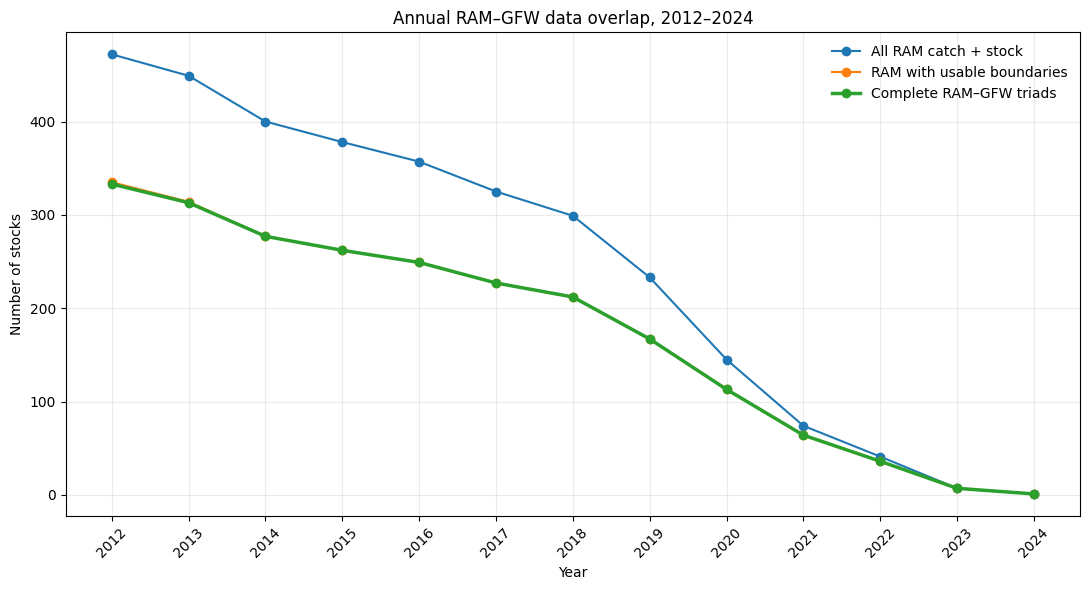


Saved downstream outputs:
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/ram_gfw_stock_year_triads_2012_2024.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_annual_overlap_diagnostics_2012_2024.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/figures/ram_gfw_annual_overlap_diagnostics_2012_2024.pdf


In [72]:
# Cell 72: Plot annual RAM–GFW overlap
# Plots annual RAM, boundary, and complete-triad coverage from 2012 through 2024.
# Produces the retained annual-overlap PDF used as year-selection provenance.

fig, ax = plt.subplots(
    figsize=(
        11,
        6,
    )
)

ax.plot(
    annual_overlap["year"],
    annual_overlap[
        "all_ram_positive_stocks"
    ],
    marker="o",
    label="All RAM catch + stock",
)

ax.plot(
    annual_overlap["year"],
    annual_overlap[
        "boundary_ram_positive_stocks"
    ],
    marker="o",
    label="RAM with usable boundaries",
)

ax.plot(
    annual_overlap["year"],
    annual_overlap[
        "complete_positive_triads"
    ],
    marker="o",
    linewidth=2.5,
    label="Complete RAM–GFW triads",
)

ax.set_xlabel(
    "Year"
)

ax.set_ylabel(
    "Number of stocks"
)

ax.set_title(
    "Annual RAM–GFW data overlap, 2012–2024"
)

ax.set_xticks(
    annual_overlap["year"]
)

ax.tick_params(
    axis="x",
    rotation=45,
)

ax.grid(
    True,
    alpha=0.25,
)

ax.legend(
    frameon=False
)

plt.tight_layout()

fig.savefig(
    ANNUAL_OVERLAP_FIG_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "\nSaved downstream outputs:"
)

print(
    RAM_GFW_TRIADS_PATH
)

print(
    ANNUAL_OVERLAP_PATH
)

print(
    ANNUAL_OVERLAP_FIG_PATH
)


In [73]:
# Cell 73: Configure 2012 gear-resolved GFW branch
# Defines the 2012 gear-resolved GFW branch year, run directory, and output paths.
# Produces gear-grid, stock-gear, inventory, and reconstruction-audit paths for strict/broad effort construction.

GEAR_YEAR = 2012
GEAR_RUN_DIR = OUTPUT_DIR / "gfw_gear_2012_20260804_v1"
GEAR_RUN_DIR.mkdir(parents=True, exist_ok=True)

GEAR_GRID_PATH = (
    GEAR_RUN_DIR
    / "gfw_annual_grid_gear_2012.parquet"
)

GEAR_STOCK_PARQUET_PATH = (
    GEAR_RUN_DIR
    / "gfw_stock_year_gear_effort_2012.parquet"
)

GEAR_STOCK_CSV_PATH = (
    WORKING_DIR
    / "gfw_stock_year_gear_effort_2012.csv"
)

GEAR_INVENTORY_PATH = (
    QC_DIR
    / "gfw_gear_inventory_2012.csv"
)

GEAR_RECONSTRUCTION_AUDIT_PATH = (
    QC_DIR
    / "gfw_stock_year_gear_reconstruction_audit_2012.csv"
)


print("\n" + "=" * 72)
print("BUILD 2012 GFW CELL x GEAR GRID")
print("=" * 72)



BUILD 2012 GFW CELL x GEAR GRID


In [74]:
# Cell 74: Copy only the twelve 2012 monthly files to local storage
# Copies only the twelve 2012 GFW monthly files to local scratch storage.
# Produces local source paths for the gear-resolved DuckDB aggregation.

stage_dir, local_sources = (
    copy_year_sources_locally(
        GEAR_YEAR
    )
)

local_grid_path = (
    LOCAL_WORK_DIR
    / "gfw_annual_grid_gear_2012.parquet"
)

if local_grid_path.exists():
    local_grid_path.unlink()

file_list_sql = ", ".join(
    f"'{sql_path(path)}'"
    for path in local_sources
)


  Copying consolidated GFW input once: fleet_monthly_2012_2024_combined.csv.gz


In [75]:
# Cell 75: Confirm raw schema before expensive aggregation
# Inspects the raw 2012 monthly GFW schema before running the expensive aggregation.
# Validates that required columns are present for the gear-resolved branch.

con = duckdb.connect()

try:

    schema = con.execute(
        f"""
        DESCRIBE SELECT *
        FROM read_csv_auto(
            [{file_list_sql}],
            header = TRUE,
            sample_size = 1000000,
            union_by_name = TRUE
        )
        """
    ).df()

finally:

    con.close()


raw_columns = set(
    schema["column_name"].astype(str)
)

required_raw_columns = {
    "year",
    "month",
    "cell_ll_lat",
    "cell_ll_lon",
    "geartype",
    "hours",
    "fishing_hours",
    "mmsi_present",
}

missing_raw_columns = sorted(
    required_raw_columns
    - raw_columns
)

if missing_raw_columns:

    raise ValueError(
        "Raw GFW files are missing required columns: "
        f"{missing_raw_columns}\n"
        f"Observed columns: {sorted(raw_columns)}"
    )


In [76]:
# Cell 76: Build 2012 year x cell x gear table
# Aggregates raw 2012 GFW rows to year x grid-cell x gear without collapsing gear classes.
# Produces the local gear-resolved annual grid used for strict and broad effort reconstruction.

con = duckdb.connect()

con.execute(
    "PRAGMA threads=4"
)

con.execute(
    "PRAGMA memory_limit='10GB'"
)

con.execute(
    "PRAGMA enable_progress_bar"
)

try:

    con.execute(
        f"""
        COPY (
            WITH monthly_cell_gear AS (
                SELECT
                    CAST(year AS INTEGER)
                        AS year,

                    CAST(month AS INTEGER)
                        AS month,

                    ROUND(
                        CAST(
                            cell_ll_lat
                            AS DOUBLE
                        ),
                        1
                    ) AS cell_ll_lat,

                    ROUND(
                        CAST(
                            cell_ll_lon
                            AS DOUBLE
                        ),
                        1
                    ) AS cell_ll_lon,

                    COALESCE(
                        NULLIF(
                            TRIM(
                                CAST(
                                    geartype
                                    AS VARCHAR
                                )
                            ),
                            ''
                        ),
                        'UNKNOWN'
                    ) AS geartype,

                    SUM(
                        CAST(
                            hours
                            AS DOUBLE
                        )
                    ) AS hours,

                    SUM(
                        CAST(
                            fishing_hours
                            AS DOUBLE
                        )
                    ) AS fishing_hours,

                    SUM(
                        CAST(
                            mmsi_present
                            AS BIGINT
                        )
                    ) AS mmsi_cell_records,

                    COUNT(*)
                        AS source_rows

                FROM read_csv_auto(
                    [{file_list_sql}],
                    header = TRUE,
                    sample_size = 1000000,
                    union_by_name = TRUE
                )

                WHERE year = {GEAR_YEAR}

                GROUP BY
                    year,
                    month,
                    cell_ll_lat,
                    cell_ll_lon,
                    geartype
            )

            SELECT
                year,
                cell_ll_lat,
                cell_ll_lon,
                geartype,

                SUM(hours)
                    AS hours,

                SUM(fishing_hours)
                    AS fishing_hours,

                SUM(mmsi_cell_records)
                    AS mmsi_cell_month_sum,

                SUM(source_rows)
                    AS source_rows,

                COUNT(*)
                    AS n_months

            FROM monthly_cell_gear

            GROUP BY
                year,
                cell_ll_lat,
                cell_ll_lon,
                geartype

            ORDER BY
                cell_ll_lat,
                cell_ll_lon,
                geartype
        )

        TO '{sql_path(local_grid_path)}'

        (
            FORMAT PARQUET,
            COMPRESSION ZSTD,
            ROW_GROUP_SIZE 500000
        )
        """
    )

finally:

    con.close()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [77]:
# Cell 77: Audit the new cell x gear grid
# Audits the new 2012 cell x gear grid for row counts, effort totals, and gear coverage.
# Produces QC metrics used before publishing the gear-resolved grid.

con = duckdb.connect()

try:

    gear_grid_audit = con.execute(
        f"""
        SELECT
            COUNT(*)
                AS cell_gear_rows,

            COUNT(DISTINCT geartype)
                AS n_geartypes,

            SUM(hours)
                AS vessel_presence_hours,

            SUM(fishing_hours)
                AS fishing_hours,

            SUM(mmsi_cell_month_sum)
                AS mmsi_cell_month_sum,

            SUM(source_rows)
                AS source_rows,

            SUM(n_months)
                AS occupied_cell_gear_months

        FROM read_parquet(
            '{sql_path(local_grid_path)}'
        )
        """
    ).df().iloc[0]

finally:

    con.close()


In [78]:
# Cell 78: Prove that summing gears reconstructs the old 2012 grid
# Compares summed gear effort against the all-gear 2012 annual grid.
# Validates that gear-resolved aggregation reconstructs the previous total-effort grid.

old_grid_audit = audit_annual_grid(
    annual_grid_path(
        GEAR_YEAR
    ),
    GEAR_YEAR,
)

grid_checks = {
    "hours": np.isclose(
        gear_grid_audit[
            "vessel_presence_hours"
        ],
        old_grid_audit[
            "vessel_presence_hours"
        ],
        rtol=1e-10,
        atol=1e-6,
    ),

    "fishing_hours": np.isclose(
        gear_grid_audit[
            "fishing_hours"
        ],
        old_grid_audit[
            "fishing_hours"
        ],
        rtol=1e-10,
        atol=1e-6,
    ),

    "mmsi": np.isclose(
        gear_grid_audit[
            "mmsi_cell_month_sum"
        ],
        old_grid_audit[
            "mmsi_cell_month_sum"
        ],
        rtol=0,
        atol=0,
    ),

    "source_rows": np.isclose(
        gear_grid_audit[
            "source_rows"
        ],
        old_grid_audit[
            "source_rows"
        ],
        rtol=0,
        atol=0,
    ),
}

if not all(
    grid_checks.values()
):

    raise RuntimeError(
        "The gear-resolved grid does not reconstruct "
        "the existing 2012 annual-grid totals: "
        f"{grid_checks}"
    )


In [79]:
# Cell 79: Publish validated gear grid
# Publishes the validated 2012 gear-resolved grid atomically.
# Produces the gear grid parquet consumed by stock-level gear spatial matching.

atomic_publish_file(
    local_grid_path,
    GEAR_GRID_PATH,
)


In [80]:
# Cell 80: Build gear inventory before spatial matching
# Summarizes gears observed in the published 2012 gear-resolved grid.
# Produces the gear inventory CSV consumed by compatibility metadata and QC.

con = duckdb.connect()

try:

    gear_inventory = con.execute(
        f"""
        SELECT
            geartype,

            COUNT(*)
                AS cell_gear_rows,

            SUM(hours)
                AS vessel_presence_hours,

            SUM(fishing_hours)
                AS fishing_hours,

            SUM(mmsi_cell_month_sum)
                AS mmsi_cell_month_sum,

            SUM(source_rows)
                AS source_rows,

            SUM(n_months)
                AS occupied_cell_gear_months

        FROM read_parquet(
            '{sql_path(GEAR_GRID_PATH)}'
        )

        GROUP BY
            geartype

        ORDER BY
            fishing_hours DESC,
            geartype
        """
    ).df()

finally:

    con.close()


atomic_write_dataframe(
    gear_inventory,
    GEAR_INVENTORY_PATH,
)


print("\n" + "=" * 72)
print("SPATIAL AGGREGATION: RAM STOCK x 2012 x GEAR")
print("=" * 72)



SPATIAL AGGREGATION: RAM STOCK x 2012 x GEAR


In [81]:
# Cell 81: Load one-year cell x gear grid
# Loads the published 2012 cell x gear grid and standardizes gear labels.
# Produces the grid dataframe used for stock x gear spatial matching.

gear_grid = pd.read_parquet(
    GEAR_GRID_PATH
)

gear_grid[
    "cell_center_lon"
] = (
    gear_grid[
        "cell_ll_lon"
    ]
    + 0.05
)

gear_grid[
    "cell_center_lat"
] = (
    gear_grid[
        "cell_ll_lat"
    ]
    + 0.05
)


n_grid_rows = len(
    gear_grid
)

n_chunks = math.ceil(
    n_grid_rows
    / SPATIAL_CHUNK_SIZE
)

chunk_summaries = []
total_matches = 0


In [82]:
# Cell 82: Spatially match cell x gear rows to RAM polygons
# Spatially joins gear-resolved grid cells to RAM stock polygons in chunks.
# Produces chunk summaries for stock x year x gear effort aggregation.

for chunk_number, chunk_start in enumerate(
    range(
        0,
        n_grid_rows,
        SPATIAL_CHUNK_SIZE,
    ),
    start=1,
):

    chunk_end = min(
        chunk_start
        + SPATIAL_CHUNK_SIZE,
        n_grid_rows,
    )

    chunk = gear_grid.iloc[
        chunk_start:chunk_end
    ].copy()

    points = gpd.GeoDataFrame(
        chunk,

        geometry=gpd.points_from_xy(
            chunk[
                "cell_center_lon"
            ],

            chunk[
                "cell_center_lat"
            ],
        ),

        crs="EPSG:4326",
    )

    hits = gpd.sjoin(
        points,

        stock_polygons[
            [
                "stockid",
                "geometry",
            ]
        ],

        how="inner",

        predicate="intersects",
    )

    total_matches += len(
        hits
    )

    if len(hits) > 0:

        chunk_summary = (
            hits
            .groupby(
                [
                    "stockid",
                    "year",
                    "geartype",
                ],
                as_index=False,
            )
            .agg(
                gfw_fishing_hours=(
                    "fishing_hours",
                    "sum",
                ),

                gfw_vessel_presence_hours=(
                    "hours",
                    "sum",
                ),

                gfw_mmsi_cell_month_sum=(
                    "mmsi_cell_month_sum",
                    "sum",
                ),

                gfw_source_rows=(
                    "source_rows",
                    "sum",
                ),

                gfw_cell_gear_rows=(
                    "cell_ll_lat",
                    "size",
                ),

                gfw_occupied_cell_gear_months=(
                    "n_months",
                    "sum",
                ),
            )
        )

        chunk_summaries.append(
            chunk_summary
        )

    print(
        f"  [{chunk_number:02d}/"
        f"{n_chunks:02d}] "
        f"cell-gear rows "
        f"{chunk_start + 1:,}–"
        f"{chunk_end:,} "
        f"| matches: {len(hits):,} "
        f"| running: {total_matches:,}"
    )

    del chunk
    del points
    del hits

    gc.collect()


if not chunk_summaries:

    raise RuntimeError(
        "No gear-resolved GFW rows "
        "matched RAM polygons."
    )


  [01/11] cell-gear rows 1–100,000 | matches: 882,322 | running: 882,322
  [02/11] cell-gear rows 100,001–200,000 | matches: 890,452 | running: 1,772,774
  [03/11] cell-gear rows 200,001–300,000 | matches: 742,495 | running: 2,515,269
  [04/11] cell-gear rows 300,001–400,000 | matches: 741,858 | running: 3,257,127
  [05/11] cell-gear rows 400,001–500,000 | matches: 791,976 | running: 4,049,103
  [06/11] cell-gear rows 500,001–600,000 | matches: 819,520 | running: 4,868,623
  [07/11] cell-gear rows 600,001–700,000 | matches: 894,268 | running: 5,762,891
  [08/11] cell-gear rows 700,001–800,000 | matches: 1,089,497 | running: 6,852,388
  [09/11] cell-gear rows 800,001–900,000 | matches: 856,392 | running: 7,708,780
  [10/11] cell-gear rows 900,001–1,000,000 | matches: 1,314,772 | running: 9,023,552
  [11/11] cell-gear rows 1,000,001–1,058,203 | matches: 963,142 | running: 9,986,694


In [83]:
# Cell 83: Assemble stock x year x gear table
# Combines spatial chunk summaries into one stock x year x gear table.
# Produces the stock_gear_focal dataframe before metadata and QC enrichment.

stock_gear = (
    pd.concat(
        chunk_summaries,
        ignore_index=True,
    )
    .groupby(
        [
            "stockid",
            "year",
            "geartype",
        ],
        as_index=False,
    )
    .agg(
        gfw_fishing_hours=(
            "gfw_fishing_hours",
            "sum",
        ),

        gfw_vessel_presence_hours=(
            "gfw_vessel_presence_hours",
            "sum",
        ),

        gfw_mmsi_cell_month_sum=(
            "gfw_mmsi_cell_month_sum",
            "sum",
        ),

        gfw_source_rows=(
            "gfw_source_rows",
            "sum",
        ),

        gfw_cell_gear_rows=(
            "gfw_cell_gear_rows",
            "sum",
        ),

        gfw_occupied_cell_gear_months=(
            "gfw_occupied_cell_gear_months",
            "sum",
        ),
    )
)


stock_gear[
    "gfw_mean_months_per_cell_gear"
] = (
    stock_gear[
        "gfw_occupied_cell_gear_months"
    ]
    / stock_gear[
        "gfw_cell_gear_rows"
    ]
)


In [84]:
# Cell 84: Standardize identifiers and validate
# Standardizes stock/year/gear identifiers and validates stock x year x gear uniqueness.
# Produces a clean gear-resolved stock table for metadata joins and effort variants.

stock_gear[
    "stockid"
] = (
    stock_gear[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)

stock_gear[
    "geartype"
] = (
    stock_gear[
        "geartype"
    ]
    .astype(str)
    .str.strip()
)

stock_gear[
    "year"
] = (
    pd.to_numeric(
        stock_gear[
            "year"
        ],
        errors="raise",
    )
    .astype(int)
)


if stock_gear.duplicated(
    [
        "stockid",
        "year",
        "geartype",
    ]
).any():

    raise RuntimeError(
        "Duplicate stock-year-gear "
        "rows were produced."
    )


numeric_columns = [
    "gfw_fishing_hours",
    "gfw_vessel_presence_hours",
    "gfw_mmsi_cell_month_sum",
    "gfw_source_rows",
    "gfw_cell_gear_rows",
    "gfw_occupied_cell_gear_months",
    "gfw_mean_months_per_cell_gear",
]

for column in numeric_columns:

    values = pd.to_numeric(
        stock_gear[
            column
        ],
        errors="coerce",
    )

    if (
        values.isna().any()
        or (
            values < 0
        ).any()
    ):

        raise RuntimeError(
            f"Invalid values in {column}."
        )


stock_gear = (
    stock_gear
    .sort_values(
        [
            "stockid",
            "year",
            "geartype",
        ]
    )
    .reset_index(
        drop=True
    )
)


atomic_write_dataframe(
    stock_gear,
    GEAR_STOCK_PARQUET_PATH,
)


In [85]:
# Cell 85: Add RAM metadata for biological stock-to-gear mapping
# Attaches RAM stock metadata to the 2012 stock x gear effort table.
# Produces the enriched stock-gear table used for biological mapping and compatibility rules.

metadata_columns = [
    column
    for column in [
        "stockid",
        "stocklong",
        "commonname",
        "scientificname",
        "region",
        "primary_country",
        "primary_FAOarea",
        "ISO3_code",
        "areaid",
        "GRSF_areaid",
    ]
    if column in candidates.columns
]


stock_gear_enriched = stock_gear.merge(
    candidates[
        metadata_columns
    ].drop_duplicates(
        "stockid"
    ),

    on="stockid",

    how="left",

    validate="many_to_one",
)


front_columns = list(
    dict.fromkeys(
        metadata_columns
        + [
            "year",
            "geartype",
        ]
    )
)

other_columns = [
    column
    for column in stock_gear_enriched.columns
    if column not in front_columns
]

stock_gear_enriched = (
    stock_gear_enriched[
        front_columns
        + other_columns
    ]
)


atomic_write_dataframe(
    stock_gear_enriched,
    GEAR_STOCK_CSV_PATH,
)


In [86]:
# Cell 86: Collapse gears and reconstruct old all-gear stock totals
# Collapses gear-resolved effort to all-gear stock totals and compares against the published 2012 total.
# Produces reconstruction QC before strict and broad gear filtering.

old_2012 = pd.read_csv(
    GFW_STOCK_YEAR_PATH
)

old_2012[
    "year"
] = (
    pd.to_numeric(
        old_2012[
            "year"
        ],
        errors="raise",
    )
    .astype(int)
)

old_2012[
    "stockid"
] = (
    old_2012[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)

old_2012 = old_2012.loc[
    old_2012[
        "year"
    ]
    == GEAR_YEAR
].copy()


gear_collapsed = (
    stock_gear
    .groupby(
        [
            "stockid",
            "year",
        ],
        as_index=False,
    )
    .agg(
        gear_sum_fishing_hours=(
            "gfw_fishing_hours",
            "sum",
        ),

        gear_sum_vessel_presence_hours=(
            "gfw_vessel_presence_hours",
            "sum",
        ),

        gear_sum_mmsi_cell_month_sum=(
            "gfw_mmsi_cell_month_sum",
            "sum",
        ),

        gear_sum_source_rows=(
            "gfw_source_rows",
            "sum",
        ),

        n_geartypes=(
            "geartype",
            "nunique",
        ),
    )
)


reconstruction_audit = old_2012[
    [
        "stockid",
        "year",
        "gfw_fishing_hours",
        "gfw_vessel_presence_hours",
        "gfw_mmsi_cell_month_sum",
        "gfw_source_rows",
    ]
].merge(
    gear_collapsed,

    on=[
        "stockid",
        "year",
    ],

    how="outer",

    validate="one_to_one",

    indicator=True,
)


comparison_pairs = [
    (
        "gfw_fishing_hours",
        "gear_sum_fishing_hours",
        "fishing_hours",
        1e-6,
    ),

    (
        "gfw_vessel_presence_hours",
        "gear_sum_vessel_presence_hours",
        "vessel_presence_hours",
        1e-6,
    ),

    (
        "gfw_mmsi_cell_month_sum",
        "gear_sum_mmsi_cell_month_sum",
        "mmsi_cell_month_sum",
        0,
    ),

    (
        "gfw_source_rows",
        "gear_sum_source_rows",
        "source_rows",
        0,
    ),
]


match_columns = []

for (
    old_column,
    gear_column,
    label,
    absolute_tolerance,
) in comparison_pairs:

    reconstruction_audit[
        f"difference_{label}"
    ] = (
        reconstruction_audit[
            gear_column
        ]
        - reconstruction_audit[
            old_column
        ]
    )

    match_column = (
        f"match_{label}"
    )

    reconstruction_audit[
        match_column
    ] = np.isclose(
        reconstruction_audit[
            gear_column
        ],

        reconstruction_audit[
            old_column
        ],

        rtol=1e-10,

        atol=absolute_tolerance,

        equal_nan=False,
    )

    match_columns.append(
        match_column
    )


reconstruction_audit[
    "same_stock_set"
] = (
    reconstruction_audit[
        "_merge"
    ]
    .eq("both")
)


reconstruction_audit[
    "reconstruction_pass"
] = (
    reconstruction_audit[
        "same_stock_set"
    ]

    & reconstruction_audit[
        match_columns
    ].all(
        axis=1
    )
)


atomic_write_dataframe(
    reconstruction_audit,
    GEAR_RECONSTRUCTION_AUDIT_PATH,
)


failed = reconstruction_audit.loc[
    ~reconstruction_audit[
        "reconstruction_pass"
    ]
]


if len(failed) > 0:

    display(
        failed.head(
            50
        )
    )

    raise RuntimeError(
        "The stock x gear table does not "
        "reconstruct the existing 2012 "
        "all-gear stock totals."
    )


In [87]:
# Cell 87: Local cleanup only after every audit succeeds
# Removes local scratch files only after gear-grid publication and reconstruction checks succeed.
# Performs operational cleanup without changing retained scientific outputs.

if local_grid_path.exists():
    local_grid_path.unlink()

if stage_dir.exists():
    shutil.rmtree(
        stage_dir
    )

del gear_grid
del chunk_summaries

gc.collect()


18

In [88]:
# Cell 88: Report 2012 gear-resolved GFW outputs
# Reports saved gear-resolved grid, inventory, stock x gear, and reconstruction-audit outputs.
# Provides provenance counts and file locations for the 2012 gear branch.

print("\n" + "=" * 72)
print("2012 GEAR-RESOLVED GFW BRANCH COMPLETE")
print("=" * 72)

print(
    "Cell x gear rows:",
    f"{int(gear_grid_audit['cell_gear_rows']):,}",
)

print(
    "Gear categories:",
    f"{int(gear_grid_audit['n_geartypes']):,}",
)

print(
    "Stock x gear rows:",
    f"{len(stock_gear):,}",
)

print(
    "Stocks:",
    f"{stock_gear['stockid'].nunique():,}",
)

print(
    "Reconstruction passed:",
    f"{int(reconstruction_audit['reconstruction_pass'].sum()):,} / "
    f"{len(reconstruction_audit):,}",
)

print("\nSaved:")

print(
    GEAR_GRID_PATH
)

print(
    GEAR_STOCK_PARQUET_PATH
)

print(
    GEAR_STOCK_CSV_PATH
)

print(
    GEAR_INVENTORY_PATH
)

print(
    GEAR_RECONSTRUCTION_AUDIT_PATH
)

print("\nGear inventory:")

display(
    gear_inventory
)

print("\nStock x gear preview:")

display(
    stock_gear_enriched.head(
        30
    )
)

print("\nReconstruction audit preview:")

display(
    reconstruction_audit.head(
        20
    )
)

# Commented out IPython magic to ensure Python compatibility.



2012 GEAR-RESOLVED GFW BRANCH COMPLETE
Cell x gear rows: 1,058,203
Gear categories: 16
Stock x gear rows: 2,881
Stocks: 439
Reconstruction passed: 439 / 439

Saved:
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_gear_2012_20260804_v1/gfw_annual_grid_gear_2012.parquet
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_gear_2012_20260804_v1/gfw_stock_year_gear_effort_2012.parquet
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/gfw_stock_year_gear_effort_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/gfw_gear_inventory_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/gfw_stock_year_gear_reconstruction_audit_2012.csv

Gear inventory:


,geartype,cell_gear_rows,vessel_presence_hours,fishing_hours,mmsi_cell_month_sum,source_rows,occupied_cell_gear_months
0,trawlers,185052,1.205788e+07,3.959741e+06,1471308.0,604376.0,499751.0
1,drifting_longlines,379736,2.635409e+06,1.680290e+06,814057.0,672504.0,649182.0
2,fishing,94981,3.000247e+06,6.778832e+05,294114.0,179903.0,170401.0
3,set_longlines,76884,1.718708e+06,6.013609e+05,206719.0,154377.0,146731.0
4,squid_jigger,66779,8.802816e+05,2.134299e+05,139915.0,90851.0,85147.0
5,set_gillnets,11462,8.075407e+05,1.363602e+05,45095.0,29826.0,27548.0
6,fixed_gear,16896,6.978630e+05,1.283027e+05,47021.0,35340.0,33800.0
7,other_purse_seines,28262,9.753614e+05,8.833779e+04,132229.0,57871.0,57314.0
8,pots_and_traps,11345,3.133461e+05,5.746500e+04,34024.0,23214.0,22660.0
9,tuna_purse_seines,134116,1.008131e+06,5.646508e+04,270440.0,238747.0,216500.0



Stock x gear preview:


,stockid,stocklong,commonname,scientificname,region,primary_country,primary_FAOarea,ISO3_code,areaid,GRSF_areaid,year,geartype,gfw_fishing_hours,gfw_vessel_presence_hours,gfw_mmsi_cell_month_sum,gfw_source_rows,gfw_cell_gear_rows,gfw_occupied_cell_gear_months,gfw_mean_months_per_cell_gear
0,ACADRED2J3K,Acadian redfish NAFO Division 2J3K,Acadian redfish,Sebastes fasciatus,Canada East Coast,Russian Federation,21,RUS,Canada-DFO-2J3K,fao:21.2.J;fao:21.3.K,2012,drifting_longlines,0.0000,6.4188,1.0,1.0,1,1,1.000000
1,ACADRED2J3K,Acadian redfish NAFO Division 2J3K,Acadian redfish,Sebastes fasciatus,Canada East Coast,Russian Federation,21,RUS,Canada-DFO-2J3K,fao:21.2.J;fao:21.3.K,2012,fishing,1189.6083,1763.0346,216.0,197.0,174,197,1.132184
2,ACADRED2J3K,Acadian redfish NAFO Division 2J3K,Acadian redfish,Sebastes fasciatus,Canada East Coast,Russian Federation,21,RUS,Canada-DFO-2J3K,fao:21.2.J;fao:21.3.K,2012,other_purse_seines,0.0000,2.6104,4.0,4.0,4,4,1.000000
3,ACADRED2J3K,Acadian redfish NAFO Division 2J3K,Acadian redfish,Sebastes fasciatus,Canada East Coast,Russian Federation,21,RUS,Canada-DFO-2J3K,fao:21.2.J;fao:21.3.K,2012,set_longlines,0.0000,174.2812,61.0,61.0,61,61,1.000000
4,ACADRED2J3K,Acadian redfish NAFO Division 2J3K,Acadian redfish,Sebastes fasciatus,Canada East Coast,Russian Federation,21,RUS,Canada-DFO-2J3K,fao:21.2.J;fao:21.3.K,2012,trawlers,12193.7488,20900.9977,3383.0,2836.0,1692,2835,1.675532
5,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,Acadian redfish,Sebastes fasciatus,US East Coast,USA,21,USA,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,2012,drifting_longlines,19.2135,100.0118,31.0,27.0,20,27,1.350000
6,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,Acadian redfish,Sebastes fasciatus,US East Coast,USA,21,USA,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,2012,fishing,2216.8405,5715.5760,754.0,723.0,291,723,2.484536
7,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,Acadian redfish,Sebastes fasciatus,US East Coast,USA,21,USA,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,2012,pole_and_line,23.3261,86.1115,23.0,23.0,21,23,1.095238
8,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,Acadian redfish,Sebastes fasciatus,US East Coast,USA,21,USA,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,2012,set_longlines,9.4627,38.9127,4.0,4.0,4,4,1.000000
9,ACADREDGOMGB,Acadian redfish Gulf of Maine / Georges Bank,Acadian redfish,Sebastes fasciatus,US East Coast,USA,21,USA,USA-NMFS-5YZ,fao:21.5.Y;fao:21.5.Zu,2012,trawlers,601.5285,3775.6006,527.0,458.0,214,450,2.102804



Reconstruction audit preview:


,stockid,year,gfw_fishing_hours,gfw_vessel_presence_hours,gfw_mmsi_cell_month_sum,gfw_source_rows,gear_sum_fishing_hours,gear_sum_vessel_presence_hours,gear_sum_mmsi_cell_month_sum,gear_sum_source_rows,n_geartypes,_merge,difference_fishing_hours,match_fishing_hours,difference_vessel_presence_hours,match_vessel_presence_hours,difference_mmsi_cell_month_sum,match_mmsi_cell_month_sum,difference_source_rows,match_source_rows,same_stock_set,reconstruction_pass
0,ACADRED2J3K,2012,1.338336e+04,2.284734e+04,3665.0,3099.0,1.338336e+04,2.284734e+04,3665.0,3099.0,5,both,1.818989e-12,True,0.000000e+00,True,0.0,True,0.0,True,True,True
1,ACADREDGOMGB,2012,2.870371e+03,9.716213e+03,1339.0,1235.0,2.870371e+03,9.716213e+03,1339.0,1235.0,5,both,0.000000e+00,True,0.000000e+00,True,0.0,True,0.0,True,True,True
2,ACADREDUT3,2012,1.368666e+03,6.180528e+03,673.0,627.0,1.368666e+03,6.180528e+03,673.0,627.0,3,both,0.000000e+00,True,0.000000e+00,True,0.0,True,0.0,True,True,True
3,ALBAIO,2012,2.688469e+05,5.665648e+05,152848.0,136648.0,2.688469e+05,5.665648e+05,152848.0,136648.0,7,both,0.000000e+00,True,0.000000e+00,True,0.0,True,0.0,True,True,True
4,ALBAMED,2012,1.953681e+05,5.327140e+05,62939.0,21263.0,1.953681e+05,5.327140e+05,62939.0,21263.0,8,both,0.000000e+00,True,-1.164153e-10,True,0.0,True,0.0,True,True,True
5,ALBANATL,2012,2.758105e+06,8.723889e+06,1328765.0,752066.0,2.758105e+06,8.723889e+06,1328765.0,752066.0,15,both,-4.656613e-10,True,0.000000e+00,True,0.0,True,0.0,True,True,True
6,ALBANPAC,2012,1.747655e+06,4.973746e+06,856414.0,475784.0,1.747655e+06,4.973746e+06,856414.0,475784.0,15,both,-2.328306e-10,True,-9.313226e-10,True,0.0,True,0.0,True,True,True
7,ALBASATL,2012,9.639837e+05,1.928514e+06,355320.0,217531.0,9.639837e+05,1.928514e+06,355320.0,217531.0,10,both,0.000000e+00,True,0.000000e+00,True,0.0,True,0.0,True,True,True
8,ALBASPAC,2012,8.033078e+05,1.803697e+06,515415.0,419655.0,8.033078e+05,1.803697e+06,515415.0,419655.0,9,both,0.000000e+00,True,2.328306e-10,True,0.0,True,0.0,True,True,True
9,ALPLAICBSAI,2012,1.648711e+05,2.749444e+05,51670.0,22284.0,1.648711e+05,2.749444e+05,51670.0,22284.0,7,both,0.000000e+00,True,0.000000e+00,True,0.0,True,0.0,True,True,True


In [89]:
# Cell 89: Define taxonomy query settings and output paths
# Defines WoRMS query settings and taxonomy/guild review output paths for the focal 2012 stock set.
# Produces file locations for query caches, taxonomy QC, and the editable guild worksheet.

TAXONOMY_YEAR = 2012
WORMS_CHECKPOINT_EVERY = 10
WORMS_MAX_ATTEMPTS = 3
WORMS_QUERY_PAUSE_SECONDS = 0.25

WORMS_QUERY_CACHE_PATH = (
    WORKING_DIR
    / "taxonomy_cache"
    / "ram_gfw_worms_query_cache_2012.csv"
)

RAM_STOCK_TAXONOMY_PATH = (
    TABLE_DIR
    / "ram_gfw_stock_taxonomy_2012.csv"
)

RAM_STOCK_TAXONOMY_QC_PATH = (
    TABLE_DIR
    / "ram_gfw_stock_taxonomy_qc_2012.csv"
)

FISHERY_GUILD_REVIEW_PATH = (
    TABLE_DIR
    / "ram_gfw_fishery_guild_review_2012.csv"
)


print("\n" + "=" * 72)
print("2012 RAM STOCK TAXONOMY AND FISHERY-GUILD SCAFFOLD")
print("=" * 72)



2012 RAM STOCK TAXONOMY AND FISHERY-GUILD SCAFFOLD


In [90]:
# Cell 90: Install or import pyworms
# Installs or imports pyworms for WoRMS taxonomic resolution.
# Provides the taxonomy-query dependency used by focal-stock matching cells.

try:

    import pyworms

except ImportError:

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyworms",
        ]
    )

    import pyworms


In [91]:
# Cell 91: Load the validated RAM-GFW stock-year panel
# Loads the retained RAM-GFW triad panel and selects focal 2012 complete positive stocks.
# Produces focal_2012 for taxonomy, guild, and gear-compatibility stages.

if "triads_all" in globals():

    focal_panel_source = triads_all.copy()

else:

    if not RAM_GFW_TRIADS_PATH.exists():

        raise FileNotFoundError(
            "RAM-GFW triad table not found:\n"
            f"{RAM_GFW_TRIADS_PATH}"
        )

    focal_panel_source = pd.read_csv(
        RAM_GFW_TRIADS_PATH
    )


required_focal_columns = [
    "stockid",
    "year",
    "complete_positive_triad",
]

missing_focal_columns = [
    column
    for column in required_focal_columns
    if column not in focal_panel_source.columns
]

if missing_focal_columns:

    raise ValueError(
        "Focal RAM-GFW panel is missing columns: "
        f"{missing_focal_columns}"
    )


focal_panel_source[
    "year"
] = pd.to_numeric(
    focal_panel_source[
        "year"
    ],
    errors="coerce",
)


# Handle complete_positive_triad whether loaded as bool or text.
if (
    focal_panel_source[
        "complete_positive_triad"
    ].dtype
    != bool
):

    focal_panel_source[
        "complete_positive_triad"
    ] = (
        focal_panel_source[
            "complete_positive_triad"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(
            [
                "true",
                "1",
                "yes",
            ]
        )
    )


focal_2012 = focal_panel_source.loc[
    (
        focal_panel_source[
            "year"
        ]
        == TAXONOMY_YEAR
    )
    & focal_panel_source[
        "complete_positive_triad"
    ]
].copy()


focal_2012[
    "stockid"
] = (
    focal_2012[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)


if focal_2012[
    "stockid"
].duplicated().any():

    duplicates = (
        focal_2012.loc[
            focal_2012[
                "stockid"
            ].duplicated(
                keep=False
            ),
            [
                "stockid",
                "year",
            ],
        ]
        .sort_values(
            "stockid"
        )
    )

    display(
        duplicates
    )

    raise RuntimeError(
        "The focal 2012 panel contains "
        "duplicate stock IDs."
    )


print(
    "Complete positive focal stocks:",
    f"{focal_2012['stockid'].nunique():,}",
)


Complete positive focal stocks: 333


In [92]:
# Cell 92: Load the stock x gear table produced by the preceding cell
# Loads the 2012 stock x gear table from memory or disk for taxonomy context.
# Produces stock_gear_for_taxonomy used to check focal-stock gear coverage.

if "stock_gear_enriched" in globals():

    stock_gear_for_taxonomy = (
        stock_gear_enriched.copy()
    )

elif "GEAR_STOCK_CSV_PATH" in globals():

    if not Path(
        GEAR_STOCK_CSV_PATH
    ).exists():

        raise FileNotFoundError(
            "Gear-resolved stock table not found:\n"
            f"{GEAR_STOCK_CSV_PATH}"
        )

    stock_gear_for_taxonomy = pd.read_csv(
        GEAR_STOCK_CSV_PATH
    )

else:

    fallback_gear_path = (
        GEAR_STOCK_CSV_PATH
    )

    if not fallback_gear_path.exists():

        raise FileNotFoundError(
            "Could not locate the 2012 "
            "stock x gear table:\n"
            f"{fallback_gear_path}"
        )

    stock_gear_for_taxonomy = pd.read_csv(
        fallback_gear_path
    )


required_gear_columns = [
    "stockid",
    "year",
    "geartype",
    "gfw_fishing_hours",
]

missing_gear_columns = [
    column
    for column in required_gear_columns
    if column not in stock_gear_for_taxonomy.columns
]

if missing_gear_columns:

    raise ValueError(
        "Stock x gear table is missing columns: "
        f"{missing_gear_columns}"
    )


stock_gear_for_taxonomy[
    "stockid"
] = (
    stock_gear_for_taxonomy[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)

stock_gear_for_taxonomy[
    "year"
] = pd.to_numeric(
    stock_gear_for_taxonomy[
        "year"
    ],
    errors="coerce",
)

stock_gear_for_taxonomy[
    "gfw_fishing_hours"
] = pd.to_numeric(
    stock_gear_for_taxonomy[
        "gfw_fishing_hours"
    ],
    errors="coerce",
)


stock_gear_for_taxonomy = (
    stock_gear_for_taxonomy.loc[
        stock_gear_for_taxonomy[
            "year"
        ]
        == TAXONOMY_YEAR
    ]
    .copy()
)


In [93]:
# Cell 93: Verify that every focal stock occurs in the gear table
# Verifies that every focal 2012 stock has a corresponding stock x gear record.
# Produces a coverage assertion before taxonomic review and gear compatibility.

focal_stock_ids = set(
    focal_2012[
        "stockid"
    ]
)

gear_stock_ids = set(
    stock_gear_for_taxonomy[
        "stockid"
    ]
)

missing_from_gear = sorted(
    focal_stock_ids
    - gear_stock_ids
)

if missing_from_gear:

    raise RuntimeError(
        "Some focal 2012 stocks are missing "
        "from the gear-resolved table:\n"
        f"{missing_from_gear[:30]}"
    )


# Restrict all subsequent work to focal analytical stocks.
stock_gear_focal = (
    stock_gear_for_taxonomy.loc[
        stock_gear_for_taxonomy[
            "stockid"
        ].isin(
            focal_stock_ids
        )
    ]
    .copy()
)


In [94]:
# Cell 94: Attach canonical RAM stock metadata
# Attaches canonical RAM stock metadata to the focal 2012 stock set.
# Produces focal_stocks, the stock-level table sent to WoRMS taxonomy matching.

required_candidate_metadata = [
    "stockid",
    "stocklong",
    "commonname",
    "scientificname",
    "region",
    "primary_country",
    "primary_FAOarea",
]

missing_candidate_metadata = [
    column
    for column in required_candidate_metadata
    if column not in candidates.columns
]

if missing_candidate_metadata:

    raise ValueError(
        "Canonical candidate table is missing "
        "RAM metadata columns: "
        f"{missing_candidate_metadata}"
    )


candidate_metadata_columns = [
    column
    for column in [
        "stockid",
        "stocklong",
        "commonname",
        "scientificname",
        "region",
        "primary_country",
        "primary_FAOarea",
        "ISO3_code",
        "areaid",
        "GRSF_areaid",
    ]
    if column in candidates.columns
]


focal_stocks = (
    focal_2012[
        [
            "stockid",
            "year",
        ]
    ]
    .drop_duplicates(
        "stockid"
    )
    .merge(
        candidates[
            candidate_metadata_columns
        ].drop_duplicates(
            "stockid"
        ),

        on="stockid",

        how="left",

        validate="one_to_one",
    )
)


focal_stocks = focal_stocks.rename(
    columns={
        "scientificname": (
            "scientificname_ram"
        ),
        "commonname": (
            "commonname_ram"
        ),
    }
)


for column in [
    "scientificname_ram",
    "commonname_ram",
    "stocklong",
]:

    if column in focal_stocks.columns:

        focal_stocks[
            column
        ] = (
            focal_stocks[
                column
            ]
            .fillna("")
            .astype(str)
            .str.strip()
        )


missing_scientific_names = focal_stocks.loc[
    focal_stocks[
        "scientificname_ram"
    ].eq("")
]


print(
    "Stocks missing RAM scientific name:",
    f"{len(missing_scientific_names):,}",
)


Stocks missing RAM scientific name: 0


In [95]:
# Cell 95: Helpers for WoRMS matching
# Defines name-normalization and WoRMS response parsing helpers.
# Produces reusable taxonomy-matching utilities for the query and cache cells.

def normalize_taxon_name(value):
    """
    Normalize a scientific name for exact-match scoring.
    """

    if value is None:
        return ""

    value = str(
        value
    )

    value = re.sub(
        r"\s+",
        " ",
        value,
    )

    return (
        value
        .strip()
        .casefold()
    )


def worms_record_score(
    record,
    query_name,
):
    """
    Rank candidate WoRMS records.

    Exact name matches dominate. Accepted records and
    species-level records receive smaller additional scores.
    """

    query_norm = normalize_taxon_name(
        query_name
    )

    scientific_norm = normalize_taxon_name(
        record.get(
            "scientificname"
        )
    )

    valid_norm = normalize_taxon_name(
        record.get(
            "valid_name"
        )
    )

    status_norm = normalize_taxon_name(
        record.get(
            "status"
        )
    )

    rank_norm = normalize_taxon_name(
        record.get(
            "rank"
        )
    )

    score = 0

    if scientific_norm == query_norm:
        score += 100

    if valid_norm == query_norm:
        score += 90

    if status_norm == "accepted":
        score += 20

    if rank_norm in {
        "species",
        "subspecies",
    }:
        score += 10

    if record.get(
        "isMarine"
    ) is True:
        score += 1

    return score


def classify_worms_match(
    record,
    query_name,
):
    """
    Describe how the selected record relates to the RAM name.
    """

    query_norm = normalize_taxon_name(
        query_name
    )

    scientific_norm = normalize_taxon_name(
        record.get(
            "scientificname"
        )
    )

    valid_norm = normalize_taxon_name(
        record.get(
            "valid_name"
        )
    )

    status_norm = normalize_taxon_name(
        record.get(
            "status"
        )
    )

    if (
        scientific_norm
        == query_norm
        and status_norm
        == "accepted"
    ):

        return "exact_accepted_name"

    if scientific_norm == query_norm:

        return "exact_scientific_name"

    if valid_norm == query_norm:

        return "exact_valid_name"

    return "nonexact_best_record"


def blank_worms_result(
    query_name,
    query_status,
    error_message="",
):
    """
    Construct a standard empty WoRMS result.
    """

    return {
        "scientificname_ram": query_name,
        "query_status": query_status,
        "worms_match_quality": query_status,
        "worms_n_records": 0,
        "worms_error": error_message,
        "aphia_id": np.nan,
        "valid_aphia_id": np.nan,
        "scientificname_worms": np.nan,
        "accepted_scientificname": np.nan,
        "taxon_status": np.nan,
        "taxon_rank": np.nan,
        "authority": np.nan,
        "valid_authority": np.nan,
        "kingdom": np.nan,
        "phylum": np.nan,
        "taxon_class": np.nan,
        "taxon_order": np.nan,
        "family": np.nan,
        "genus": np.nan,
        "is_marine": np.nan,
        "is_brackish": np.nan,
        "is_freshwater": np.nan,
        "is_terrestrial": np.nan,
        "is_extinct": np.nan,
        "worms_url": np.nan,
        "worms_lsid": np.nan,
    }


def query_worms_name(
    query_name,
):
    """
    Query WoRMS and select the best-supported record.

    Temporary request failures are retried. True no-match
    results are stored as completed no_match records.
    """

    last_error = ""

    for attempt in range(
        1,
        WORMS_MAX_ATTEMPTS + 1,
    ):

        try:

            records = (
                pyworms
                .aphiaRecordsByName(
                    query_name,
                    marine_only=False,
                )
            )

            if records is None:

                records = []

            if isinstance(
                records,
                dict,
            ):

                records = [
                    records
                ]

            records = [
                record
                for record in records
                if isinstance(
                    record,
                    dict,
                )
            ]

            if not records:

                return blank_worms_result(
                    query_name,
                    "no_match",
                )

            ranked_records = sorted(
                records,

                key=lambda record: (
                    worms_record_score(
                        record,
                        query_name,
                    )
                ),

                reverse=True,
            )

            selected = ranked_records[
                0
            ]

            accepted_name = (
                selected.get(
                    "valid_name"
                )
                or selected.get(
                    "scientificname"
                )
            )

            return {
                "scientificname_ram": query_name,
                "query_status": "matched",
                "worms_match_quality": (
                    classify_worms_match(
                        selected,
                        query_name,
                    )
                ),
                "worms_n_records": len(
                    records
                ),
                "worms_error": "",
                "aphia_id": selected.get(
                    "AphiaID"
                ),
                "valid_aphia_id": selected.get(
                    "valid_AphiaID"
                ),
                "scientificname_worms": (
                    selected.get(
                        "scientificname"
                    )
                ),
                "accepted_scientificname": (
                    accepted_name
                ),
                "taxon_status": selected.get(
                    "status"
                ),
                "taxon_rank": selected.get(
                    "rank"
                ),
                "authority": selected.get(
                    "authority"
                ),
                "valid_authority": selected.get(
                    "valid_authority"
                ),
                "kingdom": selected.get(
                    "kingdom"
                ),
                "phylum": selected.get(
                    "phylum"
                ),
                "taxon_class": selected.get(
                    "class"
                ),
                "taxon_order": selected.get(
                    "order"
                ),
                "family": selected.get(
                    "family"
                ),
                "genus": selected.get(
                    "genus"
                ),
                "is_marine": selected.get(
                    "isMarine"
                ),
                "is_brackish": selected.get(
                    "isBrackish"
                ),
                "is_freshwater": selected.get(
                    "isFreshwater"
                ),
                "is_terrestrial": selected.get(
                    "isTerrestrial"
                ),
                "is_extinct": selected.get(
                    "isExtinct"
                ),
                "worms_url": selected.get(
                    "url"
                ),
                "worms_lsid": selected.get(
                    "lsid"
                ),
            }

        except Exception as error:

            last_error = (
                f"{type(error).__name__}: "
                f"{error}"
            )

            print(
                f"  Attempt {attempt}/"
                f"{WORMS_MAX_ATTEMPTS} "
                f"failed for {query_name}: "
                f"{last_error}"
            )

            if (
                attempt
                < WORMS_MAX_ATTEMPTS
            ):

                time.sleep(
                    2 ** (
                        attempt - 1
                    )
                )

    return blank_worms_result(
        query_name,
        "query_error",
        error_message=last_error,
    )


In [96]:
# Cell 96: Load a previous cache if one exists
# Loads an existing WoRMS query cache when present and validates its required columns.
# Produces cached taxonomy results so prior completed queries are reused.

if WORMS_QUERY_CACHE_PATH.exists():

    worms_query_cache = pd.read_csv(
        WORMS_QUERY_CACHE_PATH
    )

    if (
        "scientificname_ram"
        not in worms_query_cache.columns
    ):

        raise ValueError(
            "Existing WoRMS cache lacks "
            "scientificname_ram."
        )

    worms_query_cache[
        "scientificname_ram"
    ] = (
        worms_query_cache[
            "scientificname_ram"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    worms_query_cache = (
        worms_query_cache
        .drop_duplicates(
            "scientificname_ram",
            keep="last",
        )
        .reset_index(
            drop=True
        )
    )

    print(
        "Loaded existing WoRMS cache:",
        f"{len(worms_query_cache):,} names",
    )

else:

    worms_query_cache = pd.DataFrame()


Loaded existing WoRMS cache: 156 names


In [97]:
# Cell 97: Identify WoRMS names still needing queries
# Identifies focal scientific names that still need WoRMS querying.
# Treats matched and true no-match cache rows as complete while retrying temporary query errors.

query_names = (
    focal_stocks[
        "scientificname_ram"
    ]
    .dropna()
    .astype(str)
    .str.strip()
    .loc[
        lambda values: (
            values.ne("")
        )
    ]
    .drop_duplicates()
    .sort_values()
    .tolist()
)


if len(
    worms_query_cache
) > 0:

    completed_cache_names = set(
        worms_query_cache.loc[
            worms_query_cache[
                "query_status"
            ].isin(
                [
                    "matched",
                    "no_match",
                ]
            ),
            "scientificname_ram",
        ]
    )

else:

    completed_cache_names = set()


names_to_query = [
    name
    for name in query_names
    if name not in completed_cache_names
]


print(
    "Unique RAM scientific names:",
    f"{len(query_names):,}",
)

print(
    "Names already complete in cache:",
    f"{len(completed_cache_names):,}",
)

print(
    "Names to query now:",
    f"{len(names_to_query):,}",
)


Unique RAM scientific names: 156
Names already complete in cache: 156
Names to query now: 0


In [98]:
# Cell 98: Query missing names with checkpointed caching
# Queries uncached focal scientific names and periodically checkpoints results.
# Produces updated WoRMS cache rows for taxonomy matching.

new_worms_records = []


for number, scientific_name in enumerate(
    names_to_query,
    start=1,
):

    print(
        f"  [{number:03d}/"
        f"{len(names_to_query):03d}] "
        f"{scientific_name}"
    )

    result = query_worms_name(
        scientific_name
    )

    new_worms_records.append(
        result
    )

    time.sleep(
        WORMS_QUERY_PAUSE_SECONDS
    )

    if (
        number
#         % WORMS_CHECKPOINT_EVERY
        == 0
        or number
        == len(names_to_query)
    ):

        checkpoint_parts = []

        if len(
            worms_query_cache
        ) > 0:

            checkpoint_parts.append(
                worms_query_cache
            )

        if new_worms_records:

            checkpoint_parts.append(
                pd.DataFrame(
                    new_worms_records
                )
            )

        checkpoint = (
            pd.concat(
                checkpoint_parts,
                ignore_index=True,
            )
            .drop_duplicates(
                "scientificname_ram",
                keep="last",
            )
            .sort_values(
                "scientificname_ram"
            )
            .reset_index(
                drop=True
            )
        )

        atomic_write_dataframe(
            checkpoint,
            WORMS_QUERY_CACHE_PATH,
        )

        print(
            "    Checkpoint saved:",
            f"{len(checkpoint):,} names",
        )


In [99]:
# Cell 99: Reload final query cache from disk
# Reloads the final WoRMS query cache after query/checkpoint completion.
# Produces the complete cache table used to join taxonomy back to RAM stocks.

if not WORMS_QUERY_CACHE_PATH.exists():

    if len(
        query_names
    ) == 0:

        worms_query_cache = pd.DataFrame(
            columns=[
                "scientificname_ram",
                "query_status",
            ]
        )

    else:

        raise RuntimeError(
            "WoRMS query cache was not created."
        )

else:

    worms_query_cache = pd.read_csv(
        WORMS_QUERY_CACHE_PATH
    )


worms_query_cache[
    "scientificname_ram"
] = (
    worms_query_cache[
        "scientificname_ram"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
)


In [100]:
# Cell 100: Join WoRMS taxonomy back to individual RAM stocks
# Joins WoRMS query results back to individual focal RAM stocks.
# Produces stock_taxonomy with accepted names and taxonomic metadata.

stock_taxonomy = focal_stocks.merge(
    worms_query_cache,

    on="scientificname_ram",

    how="left",

    validate="many_to_one",
)


# Create explicit rows for RAM stocks lacking a scientific name.
stock_taxonomy[
    "query_status"
] = stock_taxonomy[
    "query_status"
].fillna(
    "missing_ram_scientific_name"
)

stock_taxonomy[
    "worms_match_quality"
] = stock_taxonomy[
    "worms_match_quality"
].fillna(
    stock_taxonomy[
        "query_status"
    ]
)


In [101]:
# Cell 101: Taxonomy review flags
# Adds taxonomy confidence, family-availability, and review-need flags.
# Produces QC columns used in taxonomy review and downstream guild assignment.

acceptable_match_types = {
    "exact_accepted_name",
    "exact_scientific_name",
    "exact_valid_name",
}


stock_taxonomy[
    "taxonomy_match_acceptable"
] = (
    stock_taxonomy[
        "worms_match_quality"
    ].isin(
        acceptable_match_types
    )
)


stock_taxonomy[
    "taxonomy_has_family"
] = (
    stock_taxonomy[
        "family"
    ].notna()
    & stock_taxonomy[
        "family"
    ]
    .astype(str)
    .str.strip()
    .ne("")
)


stock_taxonomy[
    "taxonomy_needs_review"
] = (
    ~stock_taxonomy[
        "taxonomy_match_acceptable"
    ]
    | ~stock_taxonomy[
        "taxonomy_has_family"
    ]
)


In [102]:
# Cell 102: Add coarse taxonomic group
# Assigns a coarse taxonomic scaffold from WoRMS class/order/family fields.
# Produces taxonomic_group_auto for review; it is not the final gear-susceptibility class.

def infer_coarse_taxonomic_group(
    row,
):
    taxon_class = normalize_taxon_name(
        row.get(
            "taxon_class"
        )
    )

    phylum = normalize_taxon_name(
        row.get(
            "phylum"
        )
    )

    family = normalize_taxon_name(
        row.get(
            "family"
        )
    )

    if taxon_class in {
        "teleostei",
        "actinopteri",
        "actinopterygii",
        "sarcopterygii",
    }:

        return "finfish"

    if taxon_class in {
        "elasmobranchii",
        "holocephali",
        "chondrichthyes",
    }:

        return "shark_or_ray"

    if taxon_class == "cephalopoda":

        return "cephalopod"

    if taxon_class in {
        "malacostraca",
        "branchiopoda",
        "maxillopoda",
    }:

        return "crustacean"

    if taxon_class in {
        "bivalvia",
        "gastropoda",
        "polyplacophora",
        "scaphopoda",
    }:

        return "benthic_mollusc"

    if phylum == "mollusca":

        return "other_mollusc"

    if phylum == "arthropoda":

        return "other_arthropod"

    if family in {
        "carcharhinidae",
        "rajidae",
        "squalidae",
    }:

        return "shark_or_ray"

    return "other_or_unresolved"


stock_taxonomy[
    "taxonomic_group_auto"
] = stock_taxonomy.apply(
    infer_coarse_taxonomic_group,
    axis=1,
)


In [103]:
# Cell 103: Add observed gear context for manual review
# Adds observed gear context to each focal stock for manual review.
# Provides evidence columns without determining compatibility rules directly.

stock_gear_focal[
    "geartype"
] = (
    stock_gear_focal[
        "geartype"
    ]
    .fillna("UNKNOWN")
    .astype(str)
    .str.strip()
)


gear_context_rows = []


for stockid, subset in stock_gear_focal.groupby(
    "stockid",
    dropna=False,
):

    subset = subset.copy()

    subset[
        "gfw_fishing_hours"
    ] = pd.to_numeric(
        subset[
            "gfw_fishing_hours"
        ],
        errors="coerce",
    ).fillna(
        0
    )

    subset = subset.sort_values(
        [
            "gfw_fishing_hours",
            "geartype",
        ],
        ascending=[
            False,
            True,
        ],
    )

    total_hours = float(
        subset[
            "gfw_fishing_hours"
        ].sum()
    )

    top_gear = (
        subset.iloc[
            0
        ][
            "geartype"
        ]
        if len(
            subset
        ) > 0
        else np.nan
    )

    top_gear_hours = (
        float(
            subset.iloc[
                0
            ][
                "gfw_fishing_hours"
            ]
        )
        if len(
            subset
        ) > 0
        else np.nan
    )

    top_gear_share = (
        top_gear_hours
        / total_hours
        if total_hours > 0
        else np.nan
    )

    observed_geartypes = "; ".join(
        subset[
            "geartype"
        ]
        .dropna()
        .astype(str)
        .drop_duplicates()
        .tolist()
    )

    gear_context_rows.append({
        "stockid": str(
            stockid
        ).strip(),
        "n_observed_geartypes": int(
            subset[
                "geartype"
            ].nunique()
        ),
        "observed_geartypes": (
            observed_geartypes
        ),
        "total_polygon_fishing_hours": (
            total_hours
        ),
        "top_observed_geartype": (
            top_gear
        ),
        "top_observed_gear_hours": (
            top_gear_hours
        ),
        "top_observed_gear_share": (
            top_gear_share
        ),
    })


gear_context = pd.DataFrame(
    gear_context_rows
)


stock_taxonomy = stock_taxonomy.merge(
    gear_context,

    on="stockid",

    how="left",

    validate="one_to_one",
)


In [104]:
# Cell 104: Order and save stock taxonomy table
# Orders and writes the stock-level taxonomy scaffold table.
# Produces the saved taxonomy CSV consumed by repair, guild, and QC cells.

taxonomy_front_columns = [
    column
    for column in [
        "stockid",
        "year",
        "stocklong",
        "commonname_ram",
        "scientificname_ram",
        "accepted_scientificname",
        "aphia_id",
        "valid_aphia_id",
        "worms_match_quality",
        "query_status",
        "taxonomy_needs_review",
        "taxonomic_group_auto",
        "kingdom",
        "phylum",
        "taxon_class",
        "taxon_order",
        "family",
        "genus",
        "taxon_status",
        "taxon_rank",
        "region",
        "primary_country",
        "primary_FAOarea",
        "n_observed_geartypes",
        "observed_geartypes",
        "total_polygon_fishing_hours",
        "top_observed_geartype",
        "top_observed_gear_share",
    ]
    if column in stock_taxonomy.columns
]


taxonomy_other_columns = [
    column
    for column in stock_taxonomy.columns
    if column not in taxonomy_front_columns
]


stock_taxonomy = (
    stock_taxonomy[
        taxonomy_front_columns
        + taxonomy_other_columns
    ]
    .sort_values(
        [
            "taxonomy_needs_review",
            "family",
            "accepted_scientificname",
            "stockid",
        ],
        ascending=[
            False,
            True,
            True,
            True,
        ],
        na_position="last",
    )
    .reset_index(
        drop=True
    )
)


if stock_taxonomy[
    "stockid"
].duplicated().any():

    raise RuntimeError(
        "Taxonomy table contains duplicate stock IDs."
    )


if set(
    stock_taxonomy[
        "stockid"
    ]
) != focal_stock_ids:

    raise RuntimeError(
        "Taxonomy table stock set does not "
        "equal the focal 2012 stock set."
    )


atomic_write_dataframe(
    stock_taxonomy,
    RAM_STOCK_TAXONOMY_PATH,
)


In [105]:
# Cell 105: Create taxonomy QC table
# Builds taxonomy QC metrics for focal stocks, match types, and review flags.
# Writes the taxonomy QC table for provenance.

taxonomy_qc_rows = [
    {
        "metric": "focal_2012_stocks",
        "value": int(
            stock_taxonomy[
                "stockid"
            ].nunique()
        ),
    },
    {
        "metric": "unique_ram_scientific_names",
        "value": int(
            stock_taxonomy.loc[
                stock_taxonomy[
                    "scientificname_ram"
                ].ne(""),
                "scientificname_ram",
            ].nunique()
        ),
    },
    {
        "metric": "worms_matched_stocks",
        "value": int(
            stock_taxonomy[
                "query_status"
            ].eq(
                "matched"
            ).sum()
        ),
    },
    {
        "metric": "worms_no_match_stocks",
        "value": int(
            stock_taxonomy[
                "query_status"
            ].eq(
                "no_match"
            ).sum()
        ),
    },
    {
        "metric": "worms_query_error_stocks",
        "value": int(
            stock_taxonomy[
                "query_status"
            ].eq(
                "query_error"
            ).sum()
        ),
    },
    {
        "metric": "missing_ram_scientific_name_stocks",
        "value": int(
            stock_taxonomy[
                "query_status"
            ].eq(
                "missing_ram_scientific_name"
            ).sum()
        ),
    },
    {
        "metric": "stocks_with_family",
        "value": int(
            stock_taxonomy[
                "taxonomy_has_family"
            ].sum()
        ),
    },
    {
        "metric": "stocks_needing_taxonomy_review",
        "value": int(
            stock_taxonomy[
                "taxonomy_needs_review"
            ].sum()
        ),
    },
]


taxonomy_qc = pd.DataFrame(
    taxonomy_qc_rows
)


atomic_write_dataframe(
    taxonomy_qc,
    RAM_STOCK_TAXONOMY_QC_PATH,
)


In [106]:
# Cell 106: Create reviewable fishery-guild annotation worksheet
# Builds or updates the editable fishery-guild review worksheet.
# Preserves existing manual annotations while adding current taxonomy and gear context.

guild_base_columns = [
    column
    for column in [
        "stockid",
        "year",
        "stocklong",
        "commonname_ram",
        "scientificname_ram",
        "accepted_scientificname",
        "aphia_id",
        "taxon_class",
        "taxon_order",
        "family",
        "taxonomic_group_auto",
        "region",
        "primary_country",
        "primary_FAOarea",
        "taxonomy_needs_review",
        "n_observed_geartypes",
        "observed_geartypes",
        "total_polygon_fishing_hours",
        "top_observed_geartype",
        "top_observed_gear_share",
    ]
    if column in stock_taxonomy.columns
]


guild_review = stock_taxonomy[
    guild_base_columns
].copy()


manual_annotation_columns = [
    "accepted_scientificname_override",
    "family_override",
    "order_override",
    "taxonomic_group_override",
    "taxonomy_notes",
    "fishery_guild",
    "vertical_zone",
    "habitat",
    "schooling",
    "body_size_class",
    "target_or_bycatch",
    "guild_source",
    "guild_confidence",
    "guild_notes",
    "review_status",
]


# Preserve existing annotations if this table has already been edited.
if FISHERY_GUILD_REVIEW_PATH.exists():

    existing_guild_review = pd.read_csv(
        FISHERY_GUILD_REVIEW_PATH
    )

    existing_guild_review[
        "stockid"
    ] = (
        existing_guild_review[
            "stockid"
        ]
        .astype(str)
        .str.strip()
    )

    existing_manual_columns = [
        column
        for column in manual_annotation_columns
        if column in existing_guild_review.columns
    ]

    if existing_manual_columns:

        existing_manual = (
            existing_guild_review[
                [
                    "stockid",
                ]
                + existing_manual_columns
            ]
            .drop_duplicates(
                "stockid",
                keep="last",
            )
        )

        guild_review = guild_review.merge(
            existing_manual,

            on="stockid",

            how="left",

            validate="one_to_one",
        )

        print(
            "Preserved existing manual guild "
            "annotations from prior table."
        )


# Add any manual columns not already present.
for column in manual_annotation_columns:

    if column not in guild_review.columns:

        guild_review[
            column
        ] = ""


# Standardize annotation fields as editable text.
for column in manual_annotation_columns:

    guild_review[
        column
    ] = (
        guild_review[
            column
        ]
        .fillna("")
        .astype(str)
        .str.strip()
    )


# Assign a default review state only when none has been entered.
default_review_status = np.where(
    guild_review[
        "taxonomy_needs_review"
    ],
    "needs_taxonomy_review",
    "needs_guild_review",
)


guild_review[
    "review_status"
] = np.where(
    guild_review[
        "review_status"
    ].eq(""),
    default_review_status,
    guild_review[
        "review_status"
    ],
)


guild_review = (
    guild_review
    .sort_values(
        [
            "review_status",
            "family",
            "accepted_scientificname",
            "region",
            "stockid",
        ],
        na_position="last",
    )
    .reset_index(
        drop=True
    )
)


atomic_write_dataframe(
    guild_review,
    FISHERY_GUILD_REVIEW_PATH,
)


Preserved existing manual guild annotations from prior table.


In [107]:
# Cell 107: Report taxonomy scaffold outputs
# Reports saved taxonomy scaffold, QC, and guild-review worksheet outputs.
# Provides provenance counts for the focal 2012 taxonomy stage.

print("\n" + "=" * 72)
print("2012 TAXONOMY AND GUILD SCAFFOLD COMPLETE")
print("=" * 72)

print(
    "Focal stocks:",
    f"{stock_taxonomy['stockid'].nunique():,}",
)

print(
    "Unique RAM scientific names:",
    f"{stock_taxonomy['scientificname_ram'].nunique():,}",
)

print(
    "WoRMS matched stocks:",
    f"{stock_taxonomy['query_status'].eq('matched').sum():,}",
)

print(
    "Stocks with family:",
    f"{stock_taxonomy['taxonomy_has_family'].sum():,}",
)

print(
    "Stocks needing taxonomy review:",
    f"{stock_taxonomy['taxonomy_needs_review'].sum():,}",
)


print("\nSaved:")

print(
    WORMS_QUERY_CACHE_PATH
)

print(
    RAM_STOCK_TAXONOMY_PATH
)

print(
    RAM_STOCK_TAXONOMY_QC_PATH
)

print(
    FISHERY_GUILD_REVIEW_PATH
)


print("\nTaxonomy QC:")

display(
    taxonomy_qc
)


print("\nCoarse taxonomic groups:")

display(
    stock_taxonomy[
        "taxonomic_group_auto"
    ]
    .fillna(
        "MISSING"
    )
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "taxonomic_group_auto"
    )
    .reset_index(
        name="n_stocks"
    )
)


print("\nFamilies represented:")

display(
    stock_taxonomy[
        "family"
    ]
    .fillna(
        "MISSING"
    )
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "family"
    )
    .reset_index(
        name="n_stocks"
    )
    .head(
        40
    )
)


print("\nStocks requiring taxonomy review:")

display(
    stock_taxonomy.loc[
        stock_taxonomy[
            "taxonomy_needs_review"
        ],
        [
            column
            for column in [
                "stockid",
                "stocklong",
                "commonname_ram",
                "scientificname_ram",
                "accepted_scientificname",
                "worms_match_quality",
                "query_status",
                "taxon_class",
                "taxon_order",
                "family",
                "region",
            ]
            if column in stock_taxonomy.columns
        ],
    ].head(
        100
    )
)


print("\nFishery-guild review worksheet preview:")

display(
    guild_review.head(
        40
    )
)



2012 TAXONOMY AND GUILD SCAFFOLD COMPLETE
Focal stocks: 333
Unique RAM scientific names: 156
WoRMS matched stocks: 329
Stocks with family: 329
Stocks needing taxonomy review: 4

Saved:
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/taxonomy_cache/ram_gfw_worms_query_cache_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_stock_taxonomy_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_stock_taxonomy_qc_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_fishery_guild_review_2012.csv

Taxonomy QC:


,metric,value
0,focal_2012_stocks,333
1,unique_ram_scientific_names,156
2,worms_matched_stocks,329
3,worms_no_match_stocks,4
4,worms_query_error_stocks,0
5,missing_ram_scientific_name_stocks,0
6,stocks_with_family,329
7,stocks_needing_taxonomy_review,4



Coarse taxonomic groups:


,taxonomic_group_auto,n_stocks
0,finfish,276
1,crustacean,38
2,benthic_mollusc,9
3,shark_or_ray,5
4,other_or_unresolved,4
5,cephalopod,1



Families represented:


,family,n_stocks
0,Gadidae,45
1,Pleuronectidae,28
2,Scombridae,26
3,Sebastidae,24
4,Merlucciidae,19
5,Clupeidae,15
6,Mullidae,13
7,Palinuridae,11
8,Engraulidae,10
9,Sparidae,9



Stocks requiring taxonomy review:


,stockid,stocklong,commonname_ram,scientificname_ram,accepted_scientificname,worms_match_quality,query_status,taxon_class,taxon_order,family,region
0,REDFISHSPP3M,Redfish species Flemish Cap,Redfish species,Sebastes spp,NaN,no_match,no_match,NaN,NaN,NaN,Canada East Coast
1,SEELNSSA1,Sand eel Sandeel Area 1,Sand eel,Ammodytes spp,NaN,no_match,no_match,NaN,NaN,NaN,European Union
2,SEELNSSA2,Sand eel Sandeel Area 2,Sand eel,Ammodytes spp,NaN,no_match,no_match,NaN,NaN,NaN,European Union
3,SEELNSSA3,Sand eel Sandeel Area 3,Sand eel,Ammodytes spp,NaN,no_match,no_match,NaN,NaN,NaN,European Union



Fishery-guild review worksheet preview:


,stockid,year,stocklong,commonname_ram,scientificname_ram,accepted_scientificname,aphia_id,taxon_class,taxon_order,family,taxonomic_group_auto,region,primary_country,primary_FAOarea,taxonomy_needs_review,n_observed_geartypes,observed_geartypes,total_polygon_fishing_hours,top_observed_geartype,top_observed_gear_share,accepted_scientificname_override,family_override,order_override,taxonomic_group_override,taxonomy_notes,fishery_guild,vertical_zone,habitat,schooling,body_size_class,target_or_bycatch,guild_source,guild_confidence,guild_notes,review_status
0,MENATGM,2012,Gulf menhaden Gulf of Mexico,Gulf menhaden,Brevoortia patronus,Brevoortia patronus,275500.0,Teleostei,Clupeiformes,Alosidae,finfish,US Southeast and Gulf,USA,31,False,4,other_purse_seines; trawlers; fishing; tuna_pu...,6669.4862,other_purse_seines,0.553208,,,,,,,,,,,,,,,needs_guild_review
1,SARDPVIIIc-IXa,2012,Sardine ICES 8c-9a,Sardine,Sardina pilchardus,Sardina pilchardus,126421.0,Teleostei,Clupeiformes,Alosidae,finfish,European Union,Portugal,27,False,12,trawlers; set_gillnets; drifting_longlines; fi...,106668.3211,trawlers,0.877086,,,,,,,,,,,,,,,needs_guild_review
2,SARDMEDGSA17-18,2012,"Sardine Adriatic Sea (GSA 17,18)",Sardine,Sardina pilchardus,Sardina pilchardus,126421.0,Teleostei,Clupeiformes,Alosidae,finfish,Mediterranean-Black Sea,Croatia,37,False,5,trawlers; fishing; other_purse_seines; purse_s...,33458.5069,trawlers,0.952150,,,,,,,,,,,,,,,needs_guild_review
3,SARDMEDGSA6,2012,European pilchard Northern Spain,European pilchard,Sardina pilchardus,Sardina pilchardus,126421.0,Teleostei,Clupeiformes,Alosidae,finfish,Mediterranean-Black Sea,Spain,37,False,6,trawlers; drifting_longlines; other_purse_sein...,6291.1154,trawlers,0.950386,,,,,,,,,,,,,,,needs_guild_review
4,PILCHPJPN,2012,Japanese sardine Pacific Coast of Japan,Japanese sardine,Sardinops melanostictus,Sardinops sagax,309913.0,Teleostei,Clupeiformes,Alosidae,finfish,Japan,Japan,61,False,9,trawlers; squid_jigger; set_longlines; fishing...,31107.7348,trawlers,0.717718,,,,,,,,,,,,,,,needs_guild_review
5,PILCHTSST,2012,Japanese sardine Tsushima Strait,Japanese sardine,Sardinops melanostictus,Sardinops sagax,309913.0,Teleostei,Clupeiformes,Alosidae,finfish,Japan,Japan,61,False,11,set_longlines; trawlers; fishing; set_gillnets...,1188.4263,set_longlines,0.334261,,,,,,,,,,,,,,,needs_guild_review
6,SARDPCOAST,2012,Pacific sardine Pacific Coast,Pacific sardine,Sardinops sagax,Sardinops sagax,217452.0,Teleostei,Clupeiformes,Alosidae,finfish,US West Coast,USA,77,False,7,fishing; trawlers; trollers; pots_and_traps; p...,5078.1066,fishing,0.753671,,,,,,,,,,,,,,,needs_guild_review
7,SABLEFEBSAIGA,2012,Sablefish Eastern Bering Sea / Aleutian Island...,Sablefish,Anoplopoma fimbria,Anoplopoma fimbria,159463.0,Teleostei,Perciformes,Anoplopomatidae,finfish,US Alaska,USA,67,False,7,trawlers; set_longlines; pots_and_traps; fixed...,175661.8413,trawlers,0.571305,,,,,,,,,,,,,,,needs_guild_review
8,SABLEFPCOAST,2012,Sablefish Pacific Coast,Sablefish,Anoplopoma fimbria,Anoplopoma fimbria,159463.0,Teleostei,Perciformes,Anoplopomatidae,finfish,US West Coast,USA,67,False,6,trawlers; fishing; pots_and_traps; pole_and_li...,282.4731,trawlers,0.452334,,,,,,,,,,,,,,,needs_guild_review
9,QUAHATLC,2012,Ocean quahog Atlantic Coast,Ocean quahog,Arctica islandica,Arctica islandica,138802.0,Bivalvia,Venerida,Arcticidae,benthic_mollusc,US East Coast,USA,21,False,5,trawlers; fishing; pole_and_line; set_longline...,6324.4438,trawlers,0.620542,,,,,,,,,,,,,,,needs_guild_review


In [108]:
# Cell 108: Define taxonomy repair and guild output paths
# Defines output paths for resolved taxonomy, guild rules, stock guilds, and guild QC.
# Produces file locations used by the taxonomy repair and first-pass guild stage.

RAM_STOCK_TAXONOMY_RESOLVED_PATH = (
    TABLE_DIR
    / "ram_gfw_stock_taxonomy_resolved_2012.csv"
)

RAM_TAXON_GUILD_RULES_PATH = (
    TABLE_DIR
    / "ram_gfw_taxon_guild_rules_2012.csv"
)

RAM_STOCK_GUILDS_PATH = (
    TABLE_DIR
    / "ram_gfw_stock_guilds_2012.csv"
)

GUILD_RULE_CATALOG_PATH = (
    TABLE_DIR
    / "ram_gfw_guild_rule_catalog_2012.csv"
)

GUILD_QC_PATH = (
    TABLE_DIR
    / "ram_gfw_guild_qc_2012.csv"
)


print("\n" + "=" * 72)
print("TAXONOMY REPAIR AND FIRST-PASS FISHERY GUILDS")
print("=" * 72)



TAXONOMY REPAIR AND FIRST-PASS FISHERY GUILDS


In [109]:
# Cell 109: Load taxonomy scaffold output
# Loads the taxonomy scaffold produced by the focal-stock WoRMS stage.
# Produces the stock-level taxonomy source table used for genus repair and guild assignment.
# ------------------------------------------------------------
# Load taxonomy scaffold output
# ------------------------------------------------------------

if "stock_taxonomy" in globals():

    taxonomy_resolved = stock_taxonomy.copy()

else:

    if not RAM_STOCK_TAXONOMY_PATH.exists():

        raise FileNotFoundError(
            "Taxonomy scaffold table not found:\n"
            f"{RAM_STOCK_TAXONOMY_PATH}"
        )

    taxonomy_resolved = pd.read_csv(
        RAM_STOCK_TAXONOMY_PATH
    )


taxonomy_resolved[
    "stockid"
] = (
    taxonomy_resolved[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)


if taxonomy_resolved[
    "stockid"
].duplicated().any():

    raise RuntimeError(
        "Taxonomy scaffold table contains "
        "duplicate stock IDs."
    )


print(
    "Loaded focal stocks:",
    f"{taxonomy_resolved['stockid'].nunique():,}",
)


Loaded focal stocks: 333


In [110]:
# Cell 110: Text normalization helpers
# Defines text-normalization helpers for taxonomy and biological rule matching.
# Produces helper functions used by genus repair and guild classification.

def norm_text(value):

    if pd.isna(value):
        return ""

    return (
        re.sub(
            r"\s+",
            " ",
            str(value),
        )
        .strip()
        .casefold()
    )


def clean_text(value):

    if pd.isna(value):
        return ""

    return (
        re.sub(
            r"\s+",
            " ",
            str(value),
        )
        .strip()
    )


def extract_genus_from_spp(value):
    """
    Convert 'Sebastes spp' or 'Ammodytes spp.'
    to the genus name.
    """

    value = clean_text(
        value
    )

    match = re.match(
        r"^([A-Z][A-Za-z\-]+)\s+spp\.?$",
        value,
    )

    if match is None:
        return None

    return match.group(
        1
    )


In [111]:
# Cell 111: Query exact genus records for unresolved 'spp' names
# Defines and runs exact WoRMS genus lookups for unresolved spp names.
# Produces genus-level taxonomy records used to fill unresolved species rows.

def query_exact_worms_genus(
    genus_name,
):
    """
    Query WoRMS and retain an exact genus-level record.
    """

    records = pyworms.aphiaRecordsByName(
        genus_name,
        marine_only=False,
    )

    if records is None:
        return None

    if isinstance(
        records,
        dict,
    ):
        records = [
            records
        ]

    records = [
        record
        for record in records
        if isinstance(
            record,
            dict,
        )
    ]

    exact_genus_records = [
        record
        for record in records
        if (
            norm_text(
                record.get(
                    "scientificname"
                )
            )
            == norm_text(
                genus_name
            )
        )
        and (
            norm_text(
                record.get(
                    "rank"
                )
            )
            == "genus"
        )
    ]

    if not exact_genus_records:
        return None

    exact_genus_records = sorted(
        exact_genus_records,
        key=lambda record: (
            norm_text(
                record.get(
                    "status"
                )
            )
            == "accepted"
        ),
        reverse=True,
    )

    return exact_genus_records[
        0
    ]


taxonomy_resolved[
    "taxonomy_resolution_level"
] = np.where(
    taxonomy_resolved[
        "query_status"
    ].eq(
        "matched"
    ),
    "species",
    "unresolved",
)


spp_rows = taxonomy_resolved.loc[
    taxonomy_resolved[
        "query_status"
    ].eq(
        "no_match"
    )
].copy()


spp_rows[
    "fallback_genus"
] = spp_rows[
    "scientificname_ram"
].apply(
    extract_genus_from_spp
)


fallback_genera = (
    spp_rows[
        "fallback_genus"
    ]
    .dropna()
    .drop_duplicates()
    .sort_values()
    .tolist()
)


print(
    "Genus-level fallbacks to query:",
    fallback_genera,
)


genus_records = {}


for genus_name in fallback_genera:

    print(
        f"  Querying genus: {genus_name}"
    )

    try:

        genus_records[
            genus_name
        ] = query_exact_worms_genus(
            genus_name
        )

    except Exception as error:

        print(
            f"  Genus query failed for "
            f"{genus_name}: {error}"
        )

        genus_records[
            genus_name
        ] = None

    time.sleep(
        0.25
    )


Genus-level fallbacks to query: ['Ammodytes', 'Sebastes']
  Querying genus: Ammodytes
  Querying genus: Sebastes


In [112]:
# Cell 112: Apply genus-level taxonomy to the spp stocks
# Applies genus-level WoRMS results to focal spp stock records.
# Produces repaired taxonomy fields while preserving match-resolution provenance.

worms_to_dataframe_columns = {
    "AphiaID": "aphia_id",
    "valid_AphiaID": "valid_aphia_id",
    "scientificname": "scientificname_worms",
    "status": "taxon_status",
    "rank": "taxon_rank",
    "authority": "authority",
    "valid_authority": "valid_authority",
    "kingdom": "kingdom",
    "phylum": "phylum",
    "class": "taxon_class",
    "order": "taxon_order",
    "family": "family",
    "genus": "genus",
    "isMarine": "is_marine",
    "isBrackish": "is_brackish",
    "isFreshwater": "is_freshwater",
    "isTerrestrial": "is_terrestrial",
    "isExtinct": "is_extinct",
    "url": "worms_url",
    "lsid": "worms_lsid",
}


for genus_name, record in genus_records.items():

    if record is None:
        continue

    mask = (
        taxonomy_resolved[
            "scientificname_ram"
        ]
        .apply(
            extract_genus_from_spp
        )
        .eq(
            genus_name
        )
    )

    for worms_column, dataframe_column in (
        worms_to_dataframe_columns.items()
    ):

        taxonomy_resolved.loc[
            mask,
            dataframe_column,
        ] = record.get(
            worms_column
        )

    taxonomy_resolved.loc[
        mask,
        "accepted_scientificname",
    ] = (
        genus_name
        + " spp."
    )

    taxonomy_resolved.loc[
        mask,
        "query_status",
    ] = "matched_genus_fallback"

    taxonomy_resolved.loc[
        mask,
        "worms_match_quality",
    ] = "exact_genus_fallback"

    taxonomy_resolved.loc[
        mask,
        "taxonomy_resolution_level",
    ] = "genus"

taxonomy_resolved[
    "taxonomic_group_auto"
] = taxonomy_resolved.apply(
    infer_coarse_taxonomic_group,
    axis=1,
)


In [113]:
# Cell 113: Recalculate taxonomy QC flags
# Recomputes taxonomy QC flags after genus-level repairs.
# Produces updated completeness and review flags for the resolved taxonomy table.

taxonomy_resolved[
    "taxonomy_has_family"
] = (
    taxonomy_resolved[
        "family"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)


taxonomy_resolved[
    "taxonomy_match_acceptable"
] = (
    taxonomy_resolved[
        "query_status"
    ].isin(
        [
            "matched",
            "matched_genus_fallback",
        ]
    )
    & taxonomy_resolved[
        "taxonomy_has_family"
    ]
)


taxonomy_resolved[
    "taxonomy_needs_review"
] = (
    ~taxonomy_resolved[
        "taxonomy_match_acceptable"
    ]
)


In [114]:
# Cell 114: Transparent biological rule sets
# Defines transparent family, order, and text-pattern rule sets for guild assignment.
# Produces curated biological rule inputs for the first-pass classifier.

FLATFISH_FAMILIES = {
    "Jordaniidae",
    "Paralichthyidae",
    "Pleuronectidae",
    "Scophthalmidae",
    "Soleidae",
}


SMALL_PELAGIC_FAMILIES = {
    "Alosidae",
    "Ammodytidae",
    "Clupeidae",
    "Dussumieriidae",
    "Engraulidae",
    "Osmeridae",
}


SMALL_PELAGIC_GENERA = {
    "Ammodytes",
    "Brevoortia",
    "Clupea",
    "Cololabis",
    "Engraulis",
    "Etrumeus",
    "Mallotus",
    "Sardina",
    "Sardinops",
    "Scomber",
    "Sprattus",
    "Thaleichthys",
    "Trachurus",
}


LARGE_PELAGIC_FAMILIES = {
    "Istiophoridae",
    "Xiphiidae",
}


LARGE_PELAGIC_GENERA = {
    "Istiompax",
    "Kajikia",
    "Katsuwonus",
    "Makaira",
    "Thunnus",
    "Xiphias",
}


PELAGIC_PREDATORY_FAMILIES = {
    "Arripidae",
    "Carangidae",
    "Gempylidae",
    "Pomatomidae",
    "Scombridae",
    "Stromateidae",
}


PELAGIC_PREDATORY_GENERA = {
    "Pseudocaranx",
    "Scomberomorus",
    "Seriola",
}


REEF_COASTAL_FAMILIES = {
    "Balistidae",
    "Centropristidae",
    "Epinephelidae",
    "Lopholatilidae",
    "Lutjanidae",
    "Malacanthidae",
    "Moronidae",
    "Mullidae",
    "Serranidae",
    "Sillaginidae",
    "Sparidae",
}


DEMERSAL_FAMILIES = {
    "Anoplopomatidae",
    "Gadidae",
    "Hexagrammidae",
    "Lophiidae",
    "Lotidae",
    "Merlucciidae",
    "Nototheniidae",
    "Ophidiidae",
    "Oreosomatidae",
    "Phycidae",
    "Scorpaenidae",
    "Scorpaenichthyidae",
    "Sebastidae",
    "Trachichthyidae",
}


BENTHIC_CRUSTACEAN_FAMILIES = {
    "Aristeidae",
    "Lithodidae",
    "Nephropidae",
    "Oregoniidae",
    "Palinuridae",
    "Pandalidae",
    "Penaeidae",
    "Squillidae",
}


BENTHIC_MOLLUSC_FAMILIES = {
    "Arcticidae",
    "Haliotidae",
    "Ostreidae",
    "Pectinidae",
}


In [115]:
# Cell 115: Save a human-readable rule catalog
# Writes a human-readable catalog of biological rule sets used by the classifier.
# Produces the rule-catalog CSV for methods provenance.

rule_rows = []


def add_rule_rows(
    values,
    rule_type,
    guild,
):

    for value in sorted(
        values
    ):

        rule_rows.append({
            "rule_type": rule_type,
            "rule_value": value,
            "fishery_guild_auto": guild,
        })


add_rule_rows(
    FLATFISH_FAMILIES,
    "family",
    "demersal_flatfish",
)

add_rule_rows(
    SMALL_PELAGIC_FAMILIES,
    "family",
    "small_pelagic_schooling_finfish",
)

add_rule_rows(
    SMALL_PELAGIC_GENERA,
    "genus",
    "small_pelagic_schooling_finfish",
)

add_rule_rows(
    LARGE_PELAGIC_FAMILIES,
    "family",
    "large_pelagic_finfish",
)

add_rule_rows(
    LARGE_PELAGIC_GENERA,
    "genus",
    "large_pelagic_finfish",
)

add_rule_rows(
    PELAGIC_PREDATORY_FAMILIES,
    "family",
    "pelagic_predatory_finfish",
)

add_rule_rows(
    PELAGIC_PREDATORY_GENERA,
    "genus",
    "pelagic_predatory_finfish",
)

add_rule_rows(
    REEF_COASTAL_FAMILIES,
    "family",
    "reef_or_coastal_finfish",
)

add_rule_rows(
    DEMERSAL_FAMILIES,
    "family",
    "demersal_groundfish",
)

add_rule_rows(
    BENTHIC_CRUSTACEAN_FAMILIES,
    "family",
    "benthic_crustacean",
)

add_rule_rows(
    BENTHIC_MOLLUSC_FAMILIES,
    "family",
    "benthic_mollusc",
)


guild_rule_catalog = pd.DataFrame(
    rule_rows
)


atomic_write_dataframe(
    guild_rule_catalog,
    GUILD_RULE_CATALOG_PATH,
)


In [116]:
# Cell 116: First-pass fishery-guild classifier
# Defines and applies the first-pass fishery-guild classifier.
# Produces automatic guild labels and reasons for each focal stock.

def infer_first_pass_guild(
    row,
):

    taxonomic_group = clean_text(
        row.get(
            "taxonomic_group_auto"
        )
    )

    family = clean_text(
        row.get(
            "family"
        )
    )

    genus = clean_text(
        row.get(
            "genus"
        )
    )

    taxon_order = clean_text(
        row.get(
            "taxon_order"
        )
    )

    common_name = norm_text(
        row.get(
            "commonname_ram"
        )
    )

    scientific_name = norm_text(
        row.get(
            "scientificname_ram"
        )
    )

    # Non-finfish groups
    if taxonomic_group == "shark_or_ray":

        return {
            "fishery_guild_auto": "shark_or_ray",
            "guild_rule_level": "taxonomic_class",
            "guild_rule_value": clean_text(
                row.get(
                    "taxon_class"
                )
            ),
            "guild_confidence_auto": "high",
        }

    if taxonomic_group == "cephalopod":

        return {
            "fishery_guild_auto": "cephalopod",
            "guild_rule_level": "taxonomic_class",
            "guild_rule_value": "Cephalopoda",
            "guild_confidence_auto": "high",
        }

    if (
        taxonomic_group
        == "crustacean"
        or family
        in BENTHIC_CRUSTACEAN_FAMILIES
    ):

        return {
            "fishery_guild_auto": "benthic_crustacean",
            "guild_rule_level": "family_or_class",
            "guild_rule_value": family,
            "guild_confidence_auto": "high",
        }

    if (
        taxonomic_group
        in {
            "benthic_mollusc",
            "other_mollusc",
        }
        or family
        in BENTHIC_MOLLUSC_FAMILIES
    ):

        return {
            "fishery_guild_auto": "benthic_mollusc",
            "guild_rule_level": "family_or_class",
            "guild_rule_value": family,
            "guild_confidence_auto": "high",
        }

    # Finfish groups
    if (
        family
        in FLATFISH_FAMILIES
        or norm_text(
            taxon_order
        )
        == "pleuronectiformes"
    ):

        return {
            "fishery_guild_auto": "demersal_flatfish",
            "guild_rule_level": "family_or_order",
            "guild_rule_value": (
                family
                if family
                else taxon_order
            ),
            "guild_confidence_auto": "high",
        }

    if (
        genus
        in LARGE_PELAGIC_GENERA
        or family
        in LARGE_PELAGIC_FAMILIES
    ):

        return {
            "fishery_guild_auto": "large_pelagic_finfish",
            "guild_rule_level": (
                "genus"
                if genus
                in LARGE_PELAGIC_GENERA
                else "family"
            ),
            "guild_rule_value": (
                genus
                if genus
                in LARGE_PELAGIC_GENERA
                else family
            ),
            "guild_confidence_auto": "high",
        }

    if (
        genus
        in SMALL_PELAGIC_GENERA
        or family
        in SMALL_PELAGIC_FAMILIES
        or norm_text(
            taxon_order
        )
        == "clupeiformes"
    ):

        return {
            "fishery_guild_auto": (
                "small_pelagic_schooling_finfish"
            ),
            "guild_rule_level": (
                "genus"
                if genus
                in SMALL_PELAGIC_GENERA
                else "family_or_order"
            ),
            "guild_rule_value": (
                genus
                if genus
                in SMALL_PELAGIC_GENERA
                else (
                    family
                    if family
                    else taxon_order
                )
            ),
            "guild_confidence_auto": "high",
        }

    if (
        genus
        in PELAGIC_PREDATORY_GENERA
        or family
        in PELAGIC_PREDATORY_FAMILIES
    ):

        return {
            "fishery_guild_auto": "pelagic_predatory_finfish",
            "guild_rule_level": (
                "genus"
                if genus
                in PELAGIC_PREDATORY_GENERA
                else "family"
            ),
            "guild_rule_value": (
                genus
                if genus
                in PELAGIC_PREDATORY_GENERA
                else family
            ),
            "guild_confidence_auto": "high",
        }

    if family in REEF_COASTAL_FAMILIES:

        return {
            "fishery_guild_auto": "reef_or_coastal_finfish",
            "guild_rule_level": "family",
            "guild_rule_value": family,
            "guild_confidence_auto": "high",
        }

    if family in DEMERSAL_FAMILIES:

        return {
            "fishery_guild_auto": "demersal_groundfish",
            "guild_rule_level": "family",
            "guild_rule_value": family,
            "guild_confidence_auto": "high",
        }

    # Conservative common-name fallback
    if any(
        word in common_name
        for word in [
            "herring",
            "sardine",
            "pilchard",
            "anchov",
            "sprat",
            "menhaden",
            "sand eel",
            "mackerel",
        ]
    ):

        return {
            "fishery_guild_auto": (
                "small_pelagic_schooling_finfish"
            ),
            "guild_rule_level": "common_name",
            "guild_rule_value": common_name,
            "guild_confidence_auto": "medium",
        }

    if any(
        word in common_name
        for word in [
            "flounder",
            "flatfish",
            "halibut",
            "plaice",
            "sole",
            "turbot",
        ]
    ):

        return {
            "fishery_guild_auto": "demersal_flatfish",
            "guild_rule_level": "common_name",
            "guild_rule_value": common_name,
            "guild_confidence_auto": "medium",
        }

    if any(
        word in common_name
        for word in [
            "tuna",
            "swordfish",
            "marlin",
        ]
    ):

        return {
            "fishery_guild_auto": "large_pelagic_finfish",
            "guild_rule_level": "common_name",
            "guild_rule_value": common_name,
            "guild_confidence_auto": "medium",
        }

    if any(
        word in common_name
        for word in [
            "cod",
            "haddock",
            "hake",
            "redfish",
            "rockfish",
            "sablefish",
            "pollock",
            "whiting",
            "monkfish",
        ]
    ):

        return {
            "fishery_guild_auto": "demersal_groundfish",
            "guild_rule_level": "common_name",
            "guild_rule_value": common_name,
            "guild_confidence_auto": "medium",
        }

    if (
        taxonomic_group
        == "finfish"
    ):

        return {
            "fishery_guild_auto": (
                "other_finfish_unresolved"
            ),
            "guild_rule_level": (
                "finfish_fallback"
            ),
            "guild_rule_value": (
                scientific_name
            ),
            "guild_confidence_auto": "low",
        }

    return {
        "fishery_guild_auto": "unresolved",
        "guild_rule_level": "no_rule",
        "guild_rule_value": scientific_name,
        "guild_confidence_auto": "low",
    }


guild_assignments = pd.DataFrame(
    taxonomy_resolved.apply(
        infer_first_pass_guild,
        axis=1,
    ).tolist()
)


taxonomy_resolved = pd.concat(
    [
        taxonomy_resolved.reset_index(
            drop=True
        ),
        guild_assignments.reset_index(
            drop=True
        ),
    ],
    axis=1,
)


In [117]:
# Cell 117: Add ecological descriptors implied by guild
# Adds ecological descriptor columns implied by each automatic guild.
# Produces habitat, vertical-zone, mobility, and body-form annotations for review.

GUILD_ECOLOGY = {
    "small_pelagic_schooling_finfish": {
        "vertical_zone_auto": "pelagic",
        "habitat_auto": "open_water",
        "schooling_auto": "strongly_schooling",
    },
    "large_pelagic_finfish": {
        "vertical_zone_auto": "pelagic",
        "habitat_auto": "oceanic_open_water",
        "schooling_auto": "variable",
    },
    "pelagic_predatory_finfish": {
        "vertical_zone_auto": "pelagic",
        "habitat_auto": "coastal_or_open_water",
        "schooling_auto": "often_schooling",
    },
    "demersal_flatfish": {
        "vertical_zone_auto": "demersal",
        "habitat_auto": "soft_bottom",
        "schooling_auto": "not_strongly_schooling",
    },
    "demersal_groundfish": {
        "vertical_zone_auto": "demersal",
        "habitat_auto": "shelf_or_slope_bottom",
        "schooling_auto": "variable",
    },
    "reef_or_coastal_finfish": {
        "vertical_zone_auto": "demersal_or_reef",
        "habitat_auto": "structured_coastal",
        "schooling_auto": "variable",
    },
    "shark_or_ray": {
        "vertical_zone_auto": "pelagic_or_demersal",
        "habitat_auto": "variable",
        "schooling_auto": "not_strongly_schooling",
    },
    "benthic_crustacean": {
        "vertical_zone_auto": "benthic",
        "habitat_auto": "seafloor",
        "schooling_auto": "not_applicable",
    },
    "benthic_mollusc": {
        "vertical_zone_auto": "benthic",
        "habitat_auto": "seafloor",
        "schooling_auto": "not_applicable",
    },
    "cephalopod": {
        "vertical_zone_auto": "pelagic_or_demersal",
        "habitat_auto": "open_water_or_bottom",
        "schooling_auto": "often_aggregating",
    },
    "other_finfish_unresolved": {
        "vertical_zone_auto": "unresolved",
        "habitat_auto": "unresolved",
        "schooling_auto": "unresolved",
    },
    "unresolved": {
        "vertical_zone_auto": "unresolved",
        "habitat_auto": "unresolved",
        "schooling_auto": "unresolved",
    },
}


for ecology_column in [
    "vertical_zone_auto",
    "habitat_auto",
    "schooling_auto",
]:

    taxonomy_resolved[
        ecology_column
    ] = taxonomy_resolved[
        "fishery_guild_auto"
    ].map(
        lambda guild: (
            GUILD_ECOLOGY.get(
                guild,
                {},
            ).get(
                ecology_column,
                "unresolved",
            )
        )
    )


In [118]:
# Cell 118: Review status
# Adds guild review-status flags based on automatic classification and taxonomy completeness.
# Produces review triage columns for the editable worksheet and QC.

taxonomy_resolved[
    "guild_needs_review"
] = (
    taxonomy_resolved[
        "taxonomy_needs_review"
    ]
    | taxonomy_resolved[
        "guild_confidence_auto"
    ].eq(
        "low"
    )
)


taxonomy_resolved[
    "auto_review_status"
] = np.select(
    [
        taxonomy_resolved[
            "taxonomy_needs_review"
        ],
        taxonomy_resolved[
            "guild_confidence_auto"
        ].eq(
            "low"
        ),
        taxonomy_resolved[
            "taxonomy_resolution_level"
        ].eq(
            "genus"
        ),
    ],
    [
        "needs_taxonomy_review",
        "needs_guild_review",
        "auto_assigned_genus_level",
    ],
    default="auto_assigned",
)


In [119]:
# Cell 119: Save repaired stock taxonomy
# Orders and writes the repaired stock taxonomy table.
# Produces the resolved stock-level taxonomy CSV consumed by guild and final-correction stages.

taxonomy_resolved = (
    taxonomy_resolved
    .sort_values(
        [
            "guild_needs_review",
            "fishery_guild_auto",
            "family",
            "accepted_scientificname",
            "stockid",
        ],
        ascending=[
            False,
            True,
            True,
            True,
            True,
        ],
        na_position="last",
    )
    .reset_index(
        drop=True
    )
)


atomic_write_dataframe(
    taxonomy_resolved,
    RAM_STOCK_TAXONOMY_RESOLVED_PATH,
)


In [120]:
# Cell 120: Build one row per unique RAM taxon
# Collapses repaired taxonomy to one row per unique RAM taxon.
# Produces taxon-level guild-review rows while preserving stock-to-taxon links.

taxonomy_resolved[
    "taxon_key"
] = (
    taxonomy_resolved[
        "accepted_scientificname"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
)


taxonomy_resolved.loc[
    taxonomy_resolved[
        "taxon_key"
    ].eq(""),
    "taxon_key",
] = taxonomy_resolved.loc[
    taxonomy_resolved[
        "taxon_key"
    ].eq(""),
    "scientificname_ram",
]


taxon_guild_rules = (
    taxonomy_resolved
    .groupby(
        "taxon_key",
        as_index=False,
        dropna=False,
    )
    .agg(
        n_stocks=(
            "stockid",
            "nunique",
        ),
        scientificname_ram=(
            "scientificname_ram",
            "first",
        ),
        accepted_scientificname=(
            "accepted_scientificname",
            "first",
        ),
        taxonomy_resolution_level=(
            "taxonomy_resolution_level",
            "first",
        ),
        taxon_class=(
            "taxon_class",
            "first",
        ),
        taxon_order=(
            "taxon_order",
            "first",
        ),
        family=(
            "family",
            "first",
        ),
        genus=(
            "genus",
            "first",
        ),
        taxonomic_group_auto=(
            "taxonomic_group_auto",
            "first",
        ),
        fishery_guild_auto=(
            "fishery_guild_auto",
            "first",
        ),
        guild_rule_level=(
            "guild_rule_level",
            "first",
        ),
        guild_rule_value=(
            "guild_rule_value",
            "first",
        ),
        guild_confidence_auto=(
            "guild_confidence_auto",
            "first",
        ),
        vertical_zone_auto=(
            "vertical_zone_auto",
            "first",
        ),
        habitat_auto=(
            "habitat_auto",
            "first",
        ),
        schooling_auto=(
            "schooling_auto",
            "first",
        ),
        guild_needs_review=(
            "guild_needs_review",
            "max",
        ),
    )
    .sort_values(
        [
            "guild_needs_review",
            "fishery_guild_auto",
            "family",
            "taxon_key",
        ],
        ascending=[
            False,
            True,
            True,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


atomic_write_dataframe(
    taxon_guild_rules,
    RAM_TAXON_GUILD_RULES_PATH,
)


In [121]:
# Cell 121: Build stock-level guild table
# Builds the stock-level guild table from repaired taxonomy and first-pass guild assignments.
# Produces RAM_STOCK_GUILDS_PATH for gear compatibility and final corrections.

stock_guild_columns = [
    column
    for column in [
        "stockid",
        "year",
        "stocklong",
        "commonname_ram",
        "scientificname_ram",
        "accepted_scientificname",
        "taxonomy_resolution_level",
        "taxon_class",
        "taxon_order",
        "family",
        "genus",
        "taxonomic_group_auto",
        "fishery_guild_auto",
        "guild_rule_level",
        "guild_rule_value",
        "guild_confidence_auto",
        "vertical_zone_auto",
        "habitat_auto",
        "schooling_auto",
        "guild_needs_review",
        "auto_review_status",
        "region",
        "primary_country",
        "primary_FAOarea",
        "n_observed_geartypes",
        "observed_geartypes",
        "total_polygon_fishing_hours",
        "top_observed_geartype",
        "top_observed_gear_share",
    ]
    if column in taxonomy_resolved.columns
]


stock_guilds = taxonomy_resolved[
    stock_guild_columns
].copy()


atomic_write_dataframe(
    stock_guilds,
    RAM_STOCK_GUILDS_PATH,
)


In [122]:
# Cell 122: Update editable guild-review worksheet
# Updates the editable guild-review worksheet while preserving existing manual annotations.
# Produces the review worksheet used as a curated provenance layer.

manual_columns = [
    "accepted_scientificname_override",
    "family_override",
    "order_override",
    "taxonomic_group_override",
    "taxonomy_notes",
    "fishery_guild",
    "vertical_zone",
    "habitat",
    "schooling",
    "body_size_class",
    "target_or_bycatch",
    "guild_source",
    "guild_confidence",
    "guild_notes",
    "review_status",
]


existing_manual = None


if FISHERY_GUILD_REVIEW_PATH.exists():

    previous_review = pd.read_csv(
        FISHERY_GUILD_REVIEW_PATH
    )

    previous_review[
        "stockid"
    ] = (
        previous_review[
            "stockid"
        ]
        .astype(str)
        .str.strip()
    )

    existing_manual_columns = [
        column
        for column in manual_columns
        if column in previous_review.columns
    ]

    if existing_manual_columns:

        existing_manual = (
            previous_review[
                [
                    "stockid",
                ]
                + existing_manual_columns
            ]
            .drop_duplicates(
                "stockid",
                keep="last",
            )
        )


guild_review = stock_guilds.copy()


if existing_manual is not None:

    guild_review = guild_review.merge(
        existing_manual,
        on="stockid",
        how="left",
        validate="one_to_one",
    )


for column in manual_columns:

    if column not in guild_review.columns:

        guild_review[
            column
        ] = ""


for column in manual_columns:

    guild_review[
        column
    ] = (
        guild_review[
            column
        ]
        .fillna("")
        .astype(str)
        .str.strip()
    )


guild_review[
    "review_status"
] = np.where(
    guild_review[
        "review_status"
    ].eq(""),
    guild_review[
        "auto_review_status"
    ],
    guild_review[
        "review_status"
    ],
)


guild_review[
    "fishery_guild_effective"
] = np.where(
    guild_review[
        "fishery_guild"
    ].ne(""),
    guild_review[
        "fishery_guild"
    ],
    guild_review[
        "fishery_guild_auto"
    ],
)


guild_review[
    "vertical_zone_effective"
] = np.where(
    guild_review[
        "vertical_zone"
    ].ne(""),
    guild_review[
        "vertical_zone"
    ],
    guild_review[
        "vertical_zone_auto"
    ],
)


guild_review[
    "habitat_effective"
] = np.where(
    guild_review[
        "habitat"
    ].ne(""),
    guild_review[
        "habitat"
    ],
    guild_review[
        "habitat_auto"
    ],
)


guild_review[
    "schooling_effective"
] = np.where(
    guild_review[
        "schooling"
    ].ne(""),
    guild_review[
        "schooling"
    ],
    guild_review[
        "schooling_auto"
    ],
)


guild_review[
    "guild_assignment_source"
] = np.where(
    guild_review[
        "fishery_guild"
    ].ne(""),
    "manual_override",
    "automatic_rule",
)


guild_review = (
    guild_review
    .sort_values(
        [
            "review_status",
            "fishery_guild_effective",
            "family",
            "accepted_scientificname",
            "stockid",
        ],
        na_position="last",
    )
    .reset_index(
        drop=True
    )
)


atomic_write_dataframe(
    guild_review,
    FISHERY_GUILD_REVIEW_PATH,
)


In [123]:
# Cell 123: QC and assertions
# Runs uniqueness, coverage, and taxonomy/guild QC assertions for the repaired guild stage.
# Writes the guild QC table used for provenance before gear compatibility.

if stock_guilds[
    "stockid"
].duplicated().any():

    raise RuntimeError(
        "Stock guild table contains "
        "duplicate stock IDs."
    )


if len(
    stock_guilds
) != len(
    taxonomy_resolved
):

    raise RuntimeError(
        "Stock guild table lost rows."
    )


guild_qc = pd.DataFrame([
    {
        "metric": "focal_stocks",
        "value": int(
            len(
                taxonomy_resolved
            )
        ),
    },
    {
        "metric": "species_level_taxonomy",
        "value": int(
            taxonomy_resolved[
                "taxonomy_resolution_level"
            ].eq(
                "species"
            ).sum()
        ),
    },
    {
        "metric": "genus_level_taxonomy",
        "value": int(
            taxonomy_resolved[
                "taxonomy_resolution_level"
            ].eq(
                "genus"
            ).sum()
        ),
    },
    {
        "metric": "unresolved_taxonomy",
        "value": int(
            taxonomy_resolved[
                "taxonomy_resolution_level"
            ].eq(
                "unresolved"
            ).sum()
        ),
    },
    {
        "metric": "finfish_after_fix",
        "value": int(
            taxonomy_resolved[
                "taxonomic_group_auto"
            ].eq(
                "finfish"
            ).sum()
        ),
    },
    {
        "metric": "unique_taxa",
        "value": int(
            taxon_guild_rules[
                "taxon_key"
            ].nunique()
        ),
    },
    {
        "metric": "high_confidence_guilds",
        "value": int(
            taxonomy_resolved[
                "guild_confidence_auto"
            ].eq(
                "high"
            ).sum()
        ),
    },
    {
        "metric": "medium_confidence_guilds",
        "value": int(
            taxonomy_resolved[
                "guild_confidence_auto"
            ].eq(
                "medium"
            ).sum()
        ),
    },
    {
        "metric": "low_confidence_guilds",
        "value": int(
            taxonomy_resolved[
                "guild_confidence_auto"
            ].eq(
                "low"
            ).sum()
        ),
    },
    {
        "metric": "stocks_needing_guild_review",
        "value": int(
            taxonomy_resolved[
                "guild_needs_review"
            ].sum()
        ),
    },
])


atomic_write_dataframe(
    guild_qc,
    GUILD_QC_PATH,
)


In [124]:
# Cell 124: Report taxonomy repair and guild outputs
# Reports resolved taxonomy, stock guild, review worksheet, rule catalog, and QC outputs.
# Provides provenance counts for taxonomy repair and first-pass guild assignment.

print("\n" + "=" * 72)
print("TAXONOMY REPAIR AND FIRST-PASS FISHERY GUILDS COMPLETE")
print("=" * 72)

print(
    "Focal stocks:",
    f"{len(taxonomy_resolved):,}",
)

print(
    "Unique taxa:",
    f"{len(taxon_guild_rules):,}",
)

print(
    "Genus-level spp resolutions:",
    f"{taxonomy_resolved['taxonomy_resolution_level'].eq('genus').sum():,}",
)

print(
    "Unresolved taxonomy:",
    f"{taxonomy_resolved['taxonomy_resolution_level'].eq('unresolved').sum():,}",
)

print(
    "Stocks needing guild review:",
    f"{taxonomy_resolved['guild_needs_review'].sum():,}",
)


print("\nSaved:")

print(
    RAM_STOCK_TAXONOMY_RESOLVED_PATH
)

print(
    RAM_TAXON_GUILD_RULES_PATH
)

print(
    RAM_STOCK_GUILDS_PATH
)

print(
    GUILD_RULE_CATALOG_PATH
)

print(
    FISHERY_GUILD_REVIEW_PATH
)

print(
    GUILD_QC_PATH
)


print("\nGuild QC:")

display(
    guild_qc
)


print("\nCorrected taxonomic groups:")

display(
    taxonomy_resolved[
        "taxonomic_group_auto"
    ]
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "taxonomic_group_auto"
    )
    .reset_index(
        name="n_stocks"
    )
)


print("\nFirst-pass fishery guilds:")

display(
    taxonomy_resolved[
        "fishery_guild_auto"
    ]
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "fishery_guild_auto"
    )
    .reset_index(
        name="n_stocks"
    )
)


print("\nGenus-level fallback stocks:")

display(
    taxonomy_resolved.loc[
        taxonomy_resolved[
            "taxonomy_resolution_level"
        ].eq(
            "genus"
        ),
        [
            "stockid",
            "scientificname_ram",
            "accepted_scientificname",
            "taxon_class",
            "taxon_order",
            "family",
            "fishery_guild_auto",
        ],
    ]
)


print("\nStocks still needing guild review:")

display(
    guild_review.loc[
        guild_review[
            "guild_needs_review"
        ],
        [
            column
            for column in [
                "stockid",
                "commonname_ram",
                "scientificname_ram",
                "accepted_scientificname",
                "family",
                "taxonomic_group_auto",
                "fishery_guild_auto",
                "guild_rule_level",
                "guild_confidence_auto",
                "region",
                "observed_geartypes",
            ]
            if column in guild_review.columns
        ],
    ].head(
        100
    )
)



TAXONOMY REPAIR AND FIRST-PASS FISHERY GUILDS COMPLETE
Focal stocks: 333
Unique taxa: 155
Genus-level spp resolutions: 4
Unresolved taxonomy: 0
Stocks needing guild review: 0

Saved:
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_stock_taxonomy_resolved_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_taxon_guild_rules_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_stock_guilds_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_guild_rule_catalog_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_fishery_guild_review_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_guild_qc_2012.csv

Guild QC:


,metric,value
0,focal_stocks,333
1,species_level_taxonomy,329
2,genus_level_taxonomy,4
3,unresolved_taxonomy,0
4,finfish_after_fix,280
5,unique_taxa,155
6,high_confidence_guilds,333
7,medium_confidence_guilds,0
8,low_confidence_guilds,0
9,stocks_needing_guild_review,0



Corrected taxonomic groups:


,taxonomic_group_auto,n_stocks
0,finfish,280
1,crustacean,38
2,benthic_mollusc,9
3,shark_or_ray,5
4,cephalopod,1



First-pass fishery guilds:


,fishery_guild_auto,n_stocks
0,demersal_groundfish,109
1,small_pelagic_schooling_finfish,50
2,demersal_flatfish,45
3,benthic_crustacean,38
4,reef_or_coastal_finfish,38
5,large_pelagic_finfish,29
6,benthic_mollusc,9
7,pelagic_predatory_finfish,9
8,shark_or_ray,5
9,cephalopod,1



Genus-level fallback stocks:


,stockid,scientificname_ram,accepted_scientificname,taxon_class,taxon_order,family,fishery_guild_auto
194,REDFISHSPP3M,Sebastes spp,Sebastes spp.,Teleostei,Perciformes,Sebastidae,demersal_groundfish
290,SEELNSSA1,Ammodytes spp,Ammodytes spp.,Teleostei,Perciformes,Ammodytidae,small_pelagic_schooling_finfish
291,SEELNSSA2,Ammodytes spp,Ammodytes spp.,Teleostei,Perciformes,Ammodytidae,small_pelagic_schooling_finfish
292,SEELNSSA3,Ammodytes spp,Ammodytes spp.,Teleostei,Perciformes,Ammodytidae,small_pelagic_schooling_finfish



Stocks still needing guild review:


,stockid,commonname_ram,scientificname_ram,accepted_scientificname,family,taxonomic_group_auto,fishery_guild_auto,guild_rule_level,guild_confidence_auto,region,observed_geartypes


In [125]:
# Cell 125: Define gear compatibility output paths
# Defines the 2012 gear metadata, compatibility review, and effort-variant output paths.
# Produces file locations used by the guild x gear compatibility stage.

COMPATIBILITY_YEAR = 2012

GEAR_METADATA_PATH = (
    TABLE_DIR
    / "gfw_gear_metadata_2012.csv"
)

GUILD_GEAR_RULES_PATH = (
    TABLE_DIR
    / "ram_gfw_guild_gear_compatibility_rules_2012.csv"
)

TAXON_GEAR_OVERRIDES_PATH = (
    TABLE_DIR
    / "ram_gfw_taxon_gear_overrides_2012.csv"
)

STOCK_GEAR_COMPATIBILITY_REVIEW_PATH = (
    TABLE_DIR
    / "ram_gfw_stock_gear_compatibility_review_2012.csv"
)

STOCK_GEAR_COMPATIBILITY_MATRIX_PATH = (
    TABLE_DIR
    / "ram_gfw_stock_gear_compatibility_matrix_2012.csv"
)

STOCK_EFFORT_VARIANTS_PATH = (
    TABLE_DIR
    / "ram_gfw_stock_effort_variants_2012.csv"
)

STOCK_EFFORT_VARIANTS_QC_PATH = (
    TABLE_DIR
    / "ram_gfw_stock_effort_variants_qc_2012.csv"
)

GUILD_GEAR_EFFORT_SUMMARY_PATH = (
    TABLE_DIR
    / "ram_gfw_guild_gear_effort_summary_2012.csv"
)


print("\n" + "=" * 72)
print("GUILD x GEAR COMPATIBILITY MATRIX")
print("=" * 72)



GUILD x GEAR COMPATIBILITY MATRIX


In [126]:
# Cell 126: Define gear-compatibility labels and helpers
# Defines compatibility labels, rule-record helpers, and rule-setting helpers.
# Produces the scaffolding used to build guild x gear compatibility rules.

COMPATIBILITY_LABELS = {
    0: "incompatible",
    1: "plausible",
    2: "strong",
}


In [127]:
# Cell 127: Load the stock-guild table
# Loads the stock-guild review or resolved guild table from memory or disk.
# Produces the stock-level guild source used to expand gear compatibility rules.
# ------------------------------------------------------------
# Load the stock-guild table
# ------------------------------------------------------------

if "guild_review" in globals():

    stock_guild_source = guild_review.copy()

elif FISHERY_GUILD_REVIEW_PATH.exists():

    stock_guild_source = pd.read_csv(
        FISHERY_GUILD_REVIEW_PATH
    )

elif RAM_STOCK_GUILDS_PATH.exists():

    stock_guild_source = pd.read_csv(
        RAM_STOCK_GUILDS_PATH
    )

else:

    raise FileNotFoundError(
        "Could not locate the "
        "stock-guild output."
    )


stock_guild_source[
    "stockid"
] = (
    stock_guild_source[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)


if stock_guild_source[
    "stockid"
].duplicated().any():

    raise RuntimeError(
        "The stock-guild table contains "
        "duplicate stock IDs."
    )


In [128]:
# Cell 128: Construct effective guild columns
# Combines automatic and manual guild columns into effective guild fields.
# Produces stock_guild_source with manual review overrides applied for compatibility rules.

if (
    "fishery_guild_effective"
    not in stock_guild_source.columns
):

    if (
        "fishery_guild"
        in stock_guild_source.columns
    ):

        manual_guild = (
            stock_guild_source[
                "fishery_guild"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
        )

    else:

        manual_guild = pd.Series(
            "",
            index=stock_guild_source.index,
        )

    stock_guild_source[
        "fishery_guild_effective"
    ] = np.where(
        manual_guild.ne(""),
        manual_guild,
        stock_guild_source[
            "fishery_guild_auto"
        ],
    )


if (
    "guild_assignment_source"
    not in stock_guild_source.columns
):

    if (
        "fishery_guild"
        in stock_guild_source.columns
    ):

        stock_guild_source[
            "guild_assignment_source"
        ] = np.where(
            stock_guild_source[
                "fishery_guild"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            .ne(""),
            "manual_override",
            "automatic_rule",
        )

    else:

        stock_guild_source[
            "guild_assignment_source"
        ] = "automatic_rule"


stock_guild_source[
    "fishery_guild_effective"
] = (
    stock_guild_source[
        "fishery_guild_effective"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
)


In [129]:
# Cell 129: Load focal 2012 stock x gear effort
# Loads inputs for the gear compatibility stage.
# Produces validated source dataframes consumed by the following transformation cells.

if "stock_gear_focal" in globals():

    stock_gear_effort = (
        stock_gear_focal.copy()
    )

elif "stock_gear_enriched" in globals():

    stock_gear_effort = (
        stock_gear_enriched.copy()
    )

elif "GEAR_STOCK_CSV_PATH" in globals():

    stock_gear_effort = pd.read_csv(
        GEAR_STOCK_CSV_PATH
    )

else:

    fallback_path = (
        GEAR_STOCK_CSV_PATH
    )

    if not fallback_path.exists():

        raise FileNotFoundError(
            "Could not locate the 2012 "
            "stock x gear effort table."
        )

    stock_gear_effort = pd.read_csv(
        fallback_path
    )


stock_gear_effort[
    "stockid"
] = (
    stock_gear_effort[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)

stock_gear_effort[
    "year"
] = pd.to_numeric(
    stock_gear_effort[
        "year"
    ],
    errors="raise",
).astype(int)

stock_gear_effort[
    "geartype"
] = (
    stock_gear_effort[
        "geartype"
    ]
    .fillna("UNKNOWN")
    .astype(str)
    .str.strip()
)

stock_gear_effort[
    "gfw_fishing_hours"
] = pd.to_numeric(
    stock_gear_effort[
        "gfw_fishing_hours"
    ],
    errors="raise",
)


stock_gear_effort = (
    stock_gear_effort.loc[
        (
            stock_gear_effort[
                "year"
            ]
            == COMPATIBILITY_YEAR
        )
        & stock_gear_effort[
            "stockid"
        ].isin(
            set(
                stock_guild_source[
                    "stockid"
                ]
            )
        )
    ]
    .copy()
)


if stock_gear_effort.duplicated(
    [
        "stockid",
        "year",
        "geartype",
    ]
).any():

    raise RuntimeError(
        "The focal stock x gear effort table "
        "contains duplicate keys."
    )


focal_stock_ids = set(
    stock_guild_source[
        "stockid"
    ]
)

gear_stock_ids = set(
    stock_gear_effort[
        "stockid"
    ]
)

missing_stock_ids = sorted(
    focal_stock_ids
    - gear_stock_ids
)

if missing_stock_ids:

    raise RuntimeError(
        "Some focal stocks are missing "
        "from the gear table:\n"
        f"{missing_stock_ids[:30]}"
    )


print(
    "Focal stocks:",
    f"{len(focal_stock_ids):,}",
)

print(
    "Observed stock x gear rows:",
    f"{len(stock_gear_effort):,}",
)


Focal stocks: 333
Observed stock x gear rows: 2,283


In [130]:
# Cell 130: GFW gear metadata
# Defines GFW gear metadata and writes the 2012 gear metadata table.
# Produces gear family/label metadata used by compatibility rules and summaries.

gear_metadata_rows = [
    {
        "geartype": "trawlers",
        "gear_family": "trawl",
        "operating_zone": "pelagic_or_demersal",
        "mobile_or_passive": "mobile",
        "gear_resolution": "broad",
        "gear_notes": (
            "GFW does not distinguish "
            "pelagic from bottom trawling."
        ),
    },
    {
        "geartype": "drifting_longlines",
        "gear_family": "drifting_longline",
        "operating_zone": "pelagic",
        "mobile_or_passive": "passive",
        "gear_resolution": "specific",
        "gear_notes": "",
    },
    {
        "geartype": "fishing",
        "gear_family": "unresolved_fishing",
        "operating_zone": "unresolved",
        "mobile_or_passive": "unresolved",
        "gear_resolution": "unresolved",
        "gear_notes": (
            "Fishing vessel classification "
            "could not be resolved to gear."
        ),
    },
    {
        "geartype": "set_longlines",
        "gear_family": "set_longline",
        "operating_zone": "demersal_or_coastal",
        "mobile_or_passive": "passive",
        "gear_resolution": "specific",
        "gear_notes": "",
    },
    {
        "geartype": "squid_jigger",
        "gear_family": "jig",
        "operating_zone": "pelagic_or_demersal",
        "mobile_or_passive": "active",
        "gear_resolution": "specific",
        "gear_notes": "",
    },
    {
        "geartype": "set_gillnets",
        "gear_family": "set_gillnet",
        "operating_zone": "coastal_or_demersal",
        "mobile_or_passive": "passive",
        "gear_resolution": "specific",
        "gear_notes": "",
    },
    {
        "geartype": "fixed_gear",
        "gear_family": "fixed_gear_unresolved",
        "operating_zone": "coastal_or_demersal",
        "mobile_or_passive": "passive",
        "gear_resolution": "broad",
        "gear_notes": (
            "Parent class including pots, "
            "set longlines, and set gillnets."
        ),
    },
    {
        "geartype": "other_purse_seines",
        "gear_family": "purse_seine",
        "operating_zone": "pelagic",
        "mobile_or_passive": "mobile",
        "gear_resolution": "intermediate",
        "gear_notes": "",
    },
    {
        "geartype": "pots_and_traps",
        "gear_family": "pot_or_trap",
        "operating_zone": "benthic_or_coastal",
        "mobile_or_passive": "passive",
        "gear_resolution": "specific",
        "gear_notes": "",
    },
    {
        "geartype": "tuna_purse_seines",
        "gear_family": "tuna_purse_seine",
        "operating_zone": "pelagic",
        "mobile_or_passive": "mobile",
        "gear_resolution": "specific",
        "gear_notes": "",
    },
    {
        "geartype": "dredge_fishing",
        "gear_family": "dredge",
        "operating_zone": "benthic",
        "mobile_or_passive": "mobile",
        "gear_resolution": "specific",
        "gear_notes": "",
    },
    {
        "geartype": "seiners",
        "gear_family": "seine",
        "operating_zone": "pelagic_or_coastal",
        "mobile_or_passive": "mobile",
        "gear_resolution": "broad",
        "gear_notes": "",
    },
    {
        "geartype": "pole_and_line",
        "gear_family": "pole_and_line",
        "operating_zone": "pelagic_or_coastal",
        "mobile_or_passive": "active",
        "gear_resolution": "specific",
        "gear_notes": "",
    },
    {
        "geartype": "other_seines",
        "gear_family": "seine",
        "operating_zone": "pelagic_or_coastal",
        "mobile_or_passive": "mobile",
        "gear_resolution": "broad",
        "gear_notes": "",
    },
    {
        "geartype": "purse_seines",
        "gear_family": "purse_seine",
        "operating_zone": "pelagic",
        "mobile_or_passive": "mobile",
        "gear_resolution": "broad",
        "gear_notes": "",
    },
    {
        "geartype": "trollers",
        "gear_family": "troll",
        "operating_zone": "pelagic_or_coastal",
        "mobile_or_passive": "active",
        "gear_resolution": "specific",
        "gear_notes": "",
    },
]


gear_metadata = pd.DataFrame(
    gear_metadata_rows
)


# Add any unexpected observed gear as unresolved rather
# than silently discarding it.
observed_gears = sorted(
    stock_gear_effort[
        "geartype"
    ].unique()
)

known_gears = set(
    gear_metadata[
        "geartype"
    ]
)

unexpected_gears = [
    gear
    for gear in observed_gears
    if gear not in known_gears
]


if unexpected_gears:

    unexpected_rows = pd.DataFrame([
        {
            "geartype": gear,
            "gear_family": "unresolved_fishing",
            "operating_zone": "unresolved",
            "mobile_or_passive": "unresolved",
            "gear_resolution": "unresolved",
            "gear_notes": (
                "Unexpected GFW gear category; "
                "requires review."
            ),
        }
        for gear in unexpected_gears
    ])

    gear_metadata = pd.concat(
        [
            gear_metadata,
            unexpected_rows,
        ],
        ignore_index=True,
    )


gear_metadata = (
    gear_metadata
    .sort_values(
        "geartype"
    )
    .reset_index(
        drop=True
    )
)


atomic_write_dataframe(
    gear_metadata,
    GEAR_METADATA_PATH,
)


In [131]:
# Cell 131: Canonical fishery guilds
# Defines the canonical ordered list of fishery guilds used in compatibility rules.
# Produces the guild universe for the complete guild x gear rule grid.

CANONICAL_GUILDS = [
    "small_pelagic_schooling_finfish",
    "large_pelagic_finfish",
    "pelagic_predatory_finfish",
    "demersal_flatfish",
    "demersal_groundfish",
    "reef_or_coastal_finfish",
    "shark_or_ray",
    "benthic_crustacean",
    "benthic_mollusc",
    "cephalopod",
    "other_finfish_unresolved",
    "unresolved",
]


observed_guilds = sorted(
    stock_guild_source[
        "fishery_guild_effective"
    ].unique()
)


unknown_guilds = [
    guild
    for guild in observed_guilds
    if guild not in CANONICAL_GUILDS
]


if unknown_guilds:

    raise ValueError(
        "The following guild values have no "
        "compatibility rules:\n"
        f"{unknown_guilds}"
    )


In [132]:
# Cell 132: Initialize complete guild x gear rule grid
# Initializes every guild x gear combination with unknown compatibility.
# Produces the mutable rule grid populated by the following guild-specific rule cells.

rule_records = {}


for guild in CANONICAL_GUILDS:

    for geartype in gear_metadata[
        "geartype"
    ]:

        key = (
            guild,
            geartype,
        )

        if guild in {
            "other_finfish_unresolved",
            "unresolved",
        }:

            rule_records[
                key
            ] = {
                "fishery_guild": guild,
                "geartype": geartype,
                "compatibility_bin": pd.NA,
                "compatibility_reason": (
                    "Biological guild is unresolved; "
                    "gear compatibility cannot be assigned."
                ),
            }

        elif geartype == "fishing":

            rule_records[
                key
            ] = {
                "fishery_guild": guild,
                "geartype": geartype,
                "compatibility_bin": pd.NA,
                "compatibility_reason": (
                    "GFW fishing class does not identify "
                    "the gear used."
                ),
            }

        else:

            rule_records[
                key
            ] = {
                "fishery_guild": guild,
                "geartype": geartype,
                "compatibility_bin": 0,
                "compatibility_reason": (
                    "Gear is not normally used to capture "
                    "this biological guild."
                ),
            }


def set_compatibility(
    guild,
    gears,
    compatibility_bin,
    reason,
):
    """
    Set explicit compatibility rules for one guild.
    """

    for geartype in gears:

        key = (
            guild,
            geartype,
        )

        if key not in rule_records:

            raise KeyError(
                f"Unknown guild-gear rule: {key}"
            )

        rule_records[
            key
        ][
            "compatibility_bin"
        ] = compatibility_bin

        rule_records[
            key
        ][
            "compatibility_reason"
        ] = reason


In [133]:
# Cell 133: Small pelagic schooling finfish
# Sets compatibility rules for small pelagic schooling finfish.
# Updates the guild x gear rule grid for this guild.

set_compatibility(
    "small_pelagic_schooling_finfish",
    [
        "trawlers",
        "other_purse_seines",
        "seiners",
        "other_seines",
        "purse_seines",
    ],
    2,
    (
        "Trawls and seines are major gears "
        "for schooling small pelagic fishes."
    ),
)

set_compatibility(
    "small_pelagic_schooling_finfish",
    [
        "set_gillnets",
        "fixed_gear",
    ],
    1,
    (
        "Gillnets can capture small pelagics; "
        "the broader fixed-gear class is plausible."
    ),
)


In [134]:
# Cell 134: Large pelagic finfish
# Sets compatibility rules for large pelagic finfish.
# Updates the guild x gear rule grid for this guild.

set_compatibility(
    "large_pelagic_finfish",
    [
        "drifting_longlines",
        "tuna_purse_seines",
        "pole_and_line",
        "trollers",
    ],
    2,
    (
        "Primary gears for tunas, swordfish, "
        "and related large pelagic fishes."
    ),
)

set_compatibility(
    "large_pelagic_finfish",
    [
        "set_longlines",
        "set_gillnets",
        "fixed_gear",
        "other_purse_seines",
        "seiners",
        "other_seines",
        "purse_seines",
    ],
    1,
    (
        "Plausible secondary, regional, "
        "or bycatch interaction."
    ),
)


In [135]:
# Cell 135: Pelagic predatory finfish
# Sets compatibility rules for pelagic predatory finfish.
# Updates the guild x gear rule grid for this guild.

set_compatibility(
    "pelagic_predatory_finfish",
    [
        "trollers",
    ],
    2,
    (
        "Trolling is a primary gear for many "
        "pelagic predatory finfishes."
    ),
)

set_compatibility(
    "pelagic_predatory_finfish",
    [
        "trawlers",
        "drifting_longlines",
        "set_longlines",
        "set_gillnets",
        "fixed_gear",
        "other_purse_seines",
        "tuna_purse_seines",
        "seiners",
        "pole_and_line",
        "other_seines",
        "purse_seines",
    ],
    1,
    (
        "Gear can plausibly target or incidentally "
        "capture pelagic predatory finfishes."
    ),
)


In [136]:
# Cell 136: Demersal flatfish
# Sets compatibility rules for demersal flatfish.
# Updates the guild x gear rule grid for this guild.

set_compatibility(
    "demersal_flatfish",
    [
        "trawlers",
    ],
    2,
    (
        "Bottom trawling is a primary fishing "
        "method for many flatfish stocks."
    ),
)

set_compatibility(
    "demersal_flatfish",
    [
        "set_longlines",
        "set_gillnets",
        "fixed_gear",
        "pole_and_line",
    ],
    1,
    (
        "Hooks and fixed nets can capture "
        "some demersal flatfish."
    ),
)


In [137]:
# Cell 137: Demersal groundfish
# Sets compatibility rules for demersal groundfish.
# Updates the guild x gear rule grid for this guild.

set_compatibility(
    "demersal_groundfish",
    [
        "trawlers",
        "set_longlines",
    ],
    2,
    (
        "Trawls and set longlines are primary "
        "gears for many demersal groundfish."
    ),
)

set_compatibility(
    "demersal_groundfish",
    [
        "set_gillnets",
        "fixed_gear",
        "pots_and_traps",
        "pole_and_line",
        "trollers",
    ],
    1,
    (
        "Plausible secondary or regional "
        "groundfish gear."
    ),
)


In [138]:
# Cell 138: Reef or coastal finfish
# Sets compatibility rules for reef or coastal finfish.
# Updates the guild x gear rule grid for this guild.

set_compatibility(
    "reef_or_coastal_finfish",
    [
        "set_longlines",
        "set_gillnets",
        "pots_and_traps",
        "pole_and_line",
    ],
    2,
    (
        "Common targeted gears for reef "
        "and coastal finfishes."
    ),
)

set_compatibility(
    "reef_or_coastal_finfish",
    [
        "trawlers",
        "fixed_gear",
        "seiners",
        "other_seines",
        "trollers",
    ],
    1,
    (
        "Plausible regional or secondary "
        "capture of coastal finfishes."
    ),
)


In [139]:
# Cell 139: Sharks and rays
# Sets compatibility rules for sharks and rays.
# Updates the guild x gear rule grid for this guild.

set_compatibility(
    "shark_or_ray",
    [
        "drifting_longlines",
        "set_longlines",
        "set_gillnets",
    ],
    2,
    (
        "Longlines and gillnets are major "
        "target or bycatch gears for sharks and rays."
    ),
)

set_compatibility(
    "shark_or_ray",
    [
        "trawlers",
        "fixed_gear",
        "other_purse_seines",
        "tuna_purse_seines",
        "seiners",
        "pole_and_line",
        "other_seines",
        "purse_seines",
        "trollers",
    ],
    1,
    (
        "Plausible incidental or secondary "
        "capture of sharks and rays."
    ),
)


In [140]:
# Cell 140: Benthic crustaceans
# Sets compatibility rules for benthic crustaceans.
# Updates the guild x gear rule grid for this guild.

set_compatibility(
    "benthic_crustacean",
    [
        "trawlers",
        "pots_and_traps",
    ],
    2,
    (
        "Trawls and pots or traps are primary "
        "gears for benthic crustaceans."
    ),
)

set_compatibility(
    "benthic_crustacean",
    [
        "fixed_gear",
        "dredge_fishing",
    ],
    1,
    (
        "Plausible broad fixed-gear assignment "
        "or secondary benthic capture."
    ),
)


In [141]:
# Cell 141: Benthic molluscs
# Sets compatibility rules for benthic molluscs.
# Updates the guild x gear rule grid for this guild.

set_compatibility(
    "benthic_mollusc",
    [
        "dredge_fishing",
    ],
    2,
    (
        "Dredging is a primary gear for many "
        "bivalve and benthic mollusc fisheries."
    ),
)

set_compatibility(
    "benthic_mollusc",
    [
        "trawlers",
    ],
    1,
    (
        "Trawls can incidentally capture "
        "some benthic molluscs."
    ),
)


In [142]:
# Cell 142: Cephalopods
# Sets compatibility rules for cephalopods.
# Updates the guild x gear rule grid for this guild.

set_compatibility(
    "cephalopod",
    [
        "squid_jigger",
        "trawlers",
    ],
    2,
    (
        "Jigging and trawling are primary "
        "gears for commercial squid."
    ),
)

set_compatibility(
    "cephalopod",
    [
        "set_gillnets",
        "fixed_gear",
        "pots_and_traps",
        "seiners",
        "other_seines",
        "purse_seines",
    ],
    1,
    (
        "Plausible secondary or species-specific "
        "cephalopod capture."
    ),
)


In [143]:
# Cell 143: Assemble and save guild x gear rule table
# Assembles, validates, and writes the guild x gear compatibility rule table.
# Produces the rule CSV used to expand stock x gear compatibility.

guild_gear_rules = pd.DataFrame(
    list(
        rule_records.values()
    )
)


guild_gear_rules[
    "compatibility_bin"
] = pd.array(
    guild_gear_rules[
        "compatibility_bin"
    ],
    dtype="Int64",
)


guild_gear_rules[
    "compatibility_label"
] = guild_gear_rules[
    "compatibility_bin"
].map(
    COMPATIBILITY_LABELS
).fillna(
    "unresolved"
)


guild_gear_rules = guild_gear_rules.merge(
    gear_metadata,

    on="geartype",

    how="left",

    validate="many_to_one",
)


guild_gear_rules = (
    guild_gear_rules
    .sort_values(
        [
            "fishery_guild",
            "compatibility_bin",
            "geartype",
        ],
        ascending=[
            True,
            False,
            True,
        ],
        na_position="last",
    )
    .reset_index(
        drop=True
    )
)


expected_rule_rows = (
    len(
        CANONICAL_GUILDS
    )
    * gear_metadata[
        "geartype"
    ].nunique()
)


if len(
    guild_gear_rules
) != expected_rule_rows:

    raise RuntimeError(
        "Guild x gear rule table is incomplete."
    )


atomic_write_dataframe(
    guild_gear_rules,
    GUILD_GEAR_RULES_PATH,
)


In [144]:
# Cell 144: Define taxon-level automatic gear overrides
# Defines automatic taxon-level gear overrides for known broad-guild exceptions.
# Produces override rules that preserve provenance for biologically specific corrections.

taxon_override_rows = []


def add_taxon_override(
    match_level,
    match_value,
    geartype,
    override_bin,
    reason,
):

    taxon_override_rows.append({
        "match_level": match_level,
        "match_value": match_value,
        "geartype": geartype,
        "override_bin": override_bin,
        "override_reason": reason,
    })


# Billfishes are frequently caught in tuna fisheries,
# but tuna purse seine and pole-and-line are not treated
# as primary billfish gears.
for billfish_family in [
    "Istiophoridae",
    "Xiphiidae",
]:

    add_taxon_override(
        "family",
        billfish_family,
        "tuna_purse_seines",
        1,
        (
            "Billfish may be taken as bycatch in "
            "tuna purse-seine fisheries, but the "
            "gear is not a primary billfish gear."
        ),
    )

    add_taxon_override(
        "family",
        billfish_family,
        "pole_and_line",
        1,
        (
            "Pole-and-line is plausible but not "
            "a primary commercial billfish gear."
        ),
    )


# Abalone fisheries are commonly diver or hand-collected.
# Those methods are not represented in GFW gear classes,
# so polygon vessel activity should not be interpreted as
# observed abalone fishing effort.
for geartype in gear_metadata[
    "geartype"
]:

    add_taxon_override(
        "family",
        "Haliotidae",
        geartype,
        pd.NA,
        (
            "Primary abalone fishing methods are "
            "not represented by the GFW vessel "
            "gear classes; compatibility is unresolved."
        ),
    )


taxon_gear_overrides = pd.DataFrame(
    taxon_override_rows
)


taxon_gear_overrides[
    "override_bin"
] = pd.array(
    taxon_gear_overrides[
        "override_bin"
    ],
    dtype="Int64",
)


atomic_write_dataframe(
    taxon_gear_overrides,
    TAXON_GEAR_OVERRIDES_PATH,
)


In [145]:
# Cell 145: Select stock-level metadata for joining
# Selects stock-level taxonomy and guild metadata for joining to gear effort.
# Produces stock_metadata used to expand stock x gear compatibility.

stock_metadata_columns = [
    column
    for column in [
        "stockid",
        "stocklong",
        "commonname_ram",
        "scientificname_ram",
        "accepted_scientificname",
        "taxonomy_resolution_level",
        "taxon_class",
        "taxon_order",
        "family",
        "genus",
        "taxonomic_group_auto",
        "fishery_guild_auto",
        "fishery_guild_effective",
        "guild_assignment_source",
        "guild_confidence_auto",
        "guild_needs_review",
        "region",
        "primary_country",
        "primary_FAOarea",
    ]
    if column in stock_guild_source.columns
]


stock_metadata = (
    stock_guild_source[
        stock_metadata_columns
    ]
    .drop_duplicates(
        "stockid"
    )
)


In [146]:
# Cell 146: Expand stock x gear effort into stock x gear compatibility
# Joins stock x gear effort to stock metadata and guild x gear rules.
# Produces stock_gear_matrix with automatic compatibility bins.

stock_gear_matrix = stock_gear_effort.merge(
    stock_metadata,

    on="stockid",

    how="left",

    validate="many_to_one",
)


stock_gear_matrix = stock_gear_matrix.merge(
    guild_gear_rules[
        [
            "fishery_guild",
            "geartype",
            "compatibility_bin",
            "compatibility_label",
            "compatibility_reason",
            "gear_family",
            "operating_zone",
            "mobile_or_passive",
            "gear_resolution",
            "gear_notes",
        ]
    ],

    left_on=[
        "fishery_guild_effective",
        "geartype",
    ],

    right_on=[
        "fishery_guild",
        "geartype",
    ],

    how="left",

    validate="many_to_one",
)


stock_gear_matrix = stock_gear_matrix.rename(
    columns={
        "compatibility_bin": (
            "compatibility_bin_base"
        ),
        "compatibility_label": (
            "compatibility_label_base"
        ),
        "compatibility_reason": (
            "compatibility_reason_base"
        ),
    }
)


if stock_gear_matrix[
    "fishery_guild"
].isna().any():

    missing_rules = stock_gear_matrix.loc[
        stock_gear_matrix[
            "fishery_guild"
        ].isna(),
        [
            "stockid",
            "fishery_guild_effective",
            "geartype",
        ],
    ].drop_duplicates()

    display(
        missing_rules
    )

    raise RuntimeError(
        "Some stock x gear rows did not "
        "receive a compatibility rule."
    )


In [147]:
# Cell 147: Apply automatic taxon-level overrides
# Applies automatic taxon-level gear overrides to the stock x gear matrix.
# Updates compatibility bins and reasons while retaining override provenance.

stock_gear_matrix[
    "compatibility_bin_auto"
] = pd.array(
    stock_gear_matrix[
        "compatibility_bin_base"
    ],
    dtype="Int64",
)

stock_gear_matrix[
    "compatibility_reason_auto"
] = stock_gear_matrix[
    "compatibility_reason_base"
]

stock_gear_matrix[
    "auto_rule_source"
] = "guild_rule"


for override in taxon_gear_overrides.itertuples(
    index=False
):

    if override.match_level == "family":

        taxon_mask = (
            stock_gear_matrix[
                "family"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq(
                override.match_value
            )
        )

    elif override.match_level == "genus":

        taxon_mask = (
            stock_gear_matrix[
                "genus"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq(
                override.match_value
            )
        )

    elif override.match_level == "species":

        taxon_mask = (
            stock_gear_matrix[
                "accepted_scientificname"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq(
                override.match_value
            )
        )

    else:

        raise ValueError(
            "Unknown taxon override level: "
            f"{override.match_level}"
        )

    gear_mask = (
        stock_gear_matrix[
            "geartype"
        ].eq(
            override.geartype
        )
    )

    override_mask = (
        taxon_mask
        & gear_mask
    )

    stock_gear_matrix.loc[
        override_mask,
        "compatibility_bin_auto",
    ] = override.override_bin

    stock_gear_matrix.loc[
        override_mask,
        "compatibility_reason_auto",
    ] = override.override_reason

    stock_gear_matrix.loc[
        override_mask,
        "auto_rule_source",
    ] = (
        "taxon_"
        + override.match_level
        + "_override"
    )


stock_gear_matrix[
    "compatibility_bin_auto"
] = pd.array(
    stock_gear_matrix[
        "compatibility_bin_auto"
    ],
    dtype="Int64",
)


stock_gear_matrix[
    "compatibility_label_auto"
] = stock_gear_matrix[
    "compatibility_bin_auto"
].map(
    COMPATIBILITY_LABELS
).fillna(
    "unresolved"
)


In [148]:
# Cell 148: Create or preserve stock-level manual review fields
# Creates or preserves editable stock-level manual compatibility override fields.
# Produces compatibility_review for optional manual curation.

manual_review_columns = [
    "compatibility_override",
    "override_reason",
    "override_source",
    "override_review_status",
]


existing_manual_review = None


if STOCK_GEAR_COMPATIBILITY_REVIEW_PATH.exists():

    previous_review = pd.read_csv(
        STOCK_GEAR_COMPATIBILITY_REVIEW_PATH
    )

    previous_review[
        "stockid"
    ] = (
        previous_review[
            "stockid"
        ]
        .astype(str)
        .str.strip()
    )

    previous_review[
        "year"
    ] = pd.to_numeric(
        previous_review[
            "year"
        ],
        errors="coerce",
    ).astype(
        "Int64"
    )

    previous_review[
        "geartype"
    ] = (
        previous_review[
            "geartype"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    available_manual_columns = [
        column
        for column in manual_review_columns
        if column in previous_review.columns
    ]

    if available_manual_columns:

        existing_manual_review = (
            previous_review[
                [
                    "stockid",
                    "year",
                    "geartype",
                ]
                + available_manual_columns
            ]
            .drop_duplicates(
                [
                    "stockid",
                    "year",
                    "geartype",
                ],
                keep="last",
            )
        )


compatibility_review = (
    stock_gear_matrix.copy()
)


if existing_manual_review is not None:

    compatibility_review = (
        compatibility_review.merge(
            existing_manual_review,

            on=[
                "stockid",
                "year",
                "geartype",
            ],

            how="left",

            validate="one_to_one",
        )
    )


for column in manual_review_columns:

    if column not in compatibility_review.columns:

        compatibility_review[
            column
        ] = ""


for column in [
    "override_reason",
    "override_source",
    "override_review_status",
]:

    compatibility_review[
        column
    ] = (
        compatibility_review[
            column
        ]
        .fillna("")
        .astype(str)
        .str.strip()
    )


In [149]:
# Cell 149: Validate manual override values
# Validates manual compatibility override values and coerces them to nullable integers.
# Protects downstream effective-compatibility calculations from invalid review entries.

override_raw = (
    compatibility_review[
        "compatibility_override"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
)


override_numeric = pd.to_numeric(
    override_raw.mask(
        override_raw.eq(""),
        np.nan,
    ),
    errors="coerce",
)


invalid_override_mask = (
    override_raw.ne("")
    & ~override_numeric.isin(
        [
            0,
            1,
            2,
        ]
    )
)


if invalid_override_mask.any():

    display(
        compatibility_review.loc[
            invalid_override_mask,
            [
                "stockid",
                "geartype",
                "compatibility_override",
            ],
        ]
    )

    raise ValueError(
        "Manual compatibility overrides must "
        "be blank, 0, 1, or 2."
    )


compatibility_review[
    "compatibility_override"
] = pd.array(
    override_numeric,
    dtype="Int64",
)


In [150]:
# Cell 150: Calculate effective compatibility
# Combines automatic and manual compatibility values into effective compatibility fields.
# Produces the effective bin, reason, and source columns used for effort partitioning.

compatibility_review[
    "compatibility_bin_effective"
] = compatibility_review[
    "compatibility_bin_auto"
].copy()


manual_override_mask = compatibility_review[
    "compatibility_override"
].notna()


compatibility_review.loc[
    manual_override_mask,
    "compatibility_bin_effective",
] = compatibility_review.loc[
    manual_override_mask,
    "compatibility_override",
]


compatibility_review[
    "compatibility_bin_effective"
] = pd.array(
    compatibility_review[
        "compatibility_bin_effective"
    ],
    dtype="Int64",
)


compatibility_review[
    "compatibility_label_effective"
] = compatibility_review[
    "compatibility_bin_effective"
].map(
    COMPATIBILITY_LABELS
).fillna(
    "unresolved"
)


compatibility_review[
    "effective_rule_source"
] = np.where(
    manual_override_mask,
    "manual_stock_gear_override",
    compatibility_review[
        "auto_rule_source"
    ],
)


compatibility_review[
    "effective_rule_reason"
] = np.where(
    manual_override_mask
    & compatibility_review[
        "override_reason"
    ].ne(""),
    compatibility_review[
        "override_reason"
    ],
    compatibility_review[
        "compatibility_reason_auto"
    ],
)


compatibility_review[
    "override_review_status"
] = np.where(
    compatibility_review[
        "override_review_status"
    ].eq(""),
    np.where(
        compatibility_review[
            "compatibility_bin_effective"
        ].isna(),
        "unresolved",
        "auto_assigned",
    ),
    compatibility_review[
        "override_review_status"
    ],
)


compatibility_review = (
    compatibility_review
    .sort_values(
        [
            "stockid",
            "year",
            "compatibility_bin_effective",
            "gfw_fishing_hours",
            "geartype",
        ],
        ascending=[
            True,
            True,
            False,
            False,
            True,
        ],
        na_position="last",
    )
    .reset_index(
        drop=True
    )
)


atomic_write_dataframe(
    compatibility_review,
    STOCK_GEAR_COMPATIBILITY_REVIEW_PATH,
)


In [151]:
# Cell 151: Final stock x gear compatibility matrix
# Finalizes and writes the stock x gear compatibility matrix.
# Produces the compatibility matrix consumed by effort variant and final-correction stages.

stock_gear_compatibility = (
    compatibility_review.copy()
)


if stock_gear_compatibility.duplicated(
    [
        "stockid",
        "year",
        "geartype",
    ]
).any():

    raise RuntimeError(
        "Compatibility matrix contains "
        "duplicate stock-year-gear rows."
    )


In [152]:
# Cell 152: Assign fishing hours to exclusive compatibility bins
# Partitions each stock x gear row's fishing hours into strong, broad-only, or unresolved bins.
# Produces exclusive effort-bin columns used for stock-level effort variants.

effective_bin = stock_gear_compatibility[
    "compatibility_bin_effective"
]

fishing_hours = pd.to_numeric(
    stock_gear_compatibility[
        "gfw_fishing_hours"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


is_strong = (
    effective_bin
    .eq(2)
    .fillna(False)
    .to_numpy(
        dtype=bool
    )
)

is_plausible = (
    effective_bin
    .eq(1)
    .fillna(False)
    .to_numpy(
        dtype=bool
    )
)

is_incompatible = (
    effective_bin
    .eq(0)
    .fillna(False)
    .to_numpy(
        dtype=bool
    )
)

is_unresolved = (
    effective_bin
    .isna()
    .to_numpy(
        dtype=bool
    )
)


# Every row must belong to exactly one category.
category_count = (
    is_strong.astype(int)
    + is_plausible.astype(int)
    + is_incompatible.astype(int)
    + is_unresolved.astype(int)
)


if not np.all(
    category_count
    == 1
):

    raise RuntimeError(
        "Some stock x gear rows do not belong "
        "to exactly one compatibility category."
    )


stock_gear_compatibility[
    "effort_strong_hours"
] = np.where(
    is_strong,
    fishing_hours,
    0.0,
)

stock_gear_compatibility[
    "effort_plausible_hours"
] = np.where(
    is_plausible,
    fishing_hours,
    0.0,
)

stock_gear_compatibility[
    "effort_incompatible_hours"
] = np.where(
    is_incompatible,
    fishing_hours,
    0.0,
)

stock_gear_compatibility[
    "effort_unresolved_hours"
] = np.where(
    is_unresolved,
    fishing_hours,
    0.0,
)


stock_gear_compatibility[
    "effort_broad_matched_hours"
] = (
    stock_gear_compatibility[
        "effort_strong_hours"
    ]
    + stock_gear_compatibility[
        "effort_plausible_hours"
    ]
)


row_reconstruction = (
    stock_gear_compatibility[
        "effort_strong_hours"
    ]
    + stock_gear_compatibility[
        "effort_plausible_hours"
    ]
    + stock_gear_compatibility[
        "effort_incompatible_hours"
    ]
    + stock_gear_compatibility[
        "effort_unresolved_hours"
    ]
)


if not np.allclose(
    row_reconstruction,
    fishing_hours,
    rtol=1e-10,
    atol=1e-8,
):

    raise RuntimeError(
        "Stock x gear compatibility bins "
        "do not reconstruct fishing hours."
    )


atomic_write_dataframe(
    stock_gear_compatibility,
    STOCK_GEAR_COMPATIBILITY_MATRIX_PATH,
)


In [153]:
# Cell 153: Aggregate to stock-level effort variants
# Aggregates gear-binned fishing hours to stock-level total, broad, and strict effort variants.
# Produces stock_effort_variants for retained total/broad/strict analysis panels.

positive_effort = (
    fishing_hours
    > 0
)


stock_gear_compatibility[
    "gear_count_strong"
] = (
    positive_effort
    & is_strong
).astype(int)

stock_gear_compatibility[
    "gear_count_plausible"
] = (
    positive_effort
    & is_plausible
).astype(int)

stock_gear_compatibility[
    "gear_count_incompatible"
] = (
    positive_effort
    & is_incompatible
).astype(int)

stock_gear_compatibility[
    "gear_count_unresolved"
] = (
    positive_effort
    & is_unresolved
).astype(int)


stock_effort_variants = (
    stock_gear_compatibility
    .groupby(
        [
            "stockid",
            "year",
        ],
        as_index=False,
    )
    .agg(
        P_total_polygon_hours=(
            "gfw_fishing_hours",
            "sum",
        ),
        P_strict_gear_hours=(
            "effort_strong_hours",
            "sum",
        ),
        P_plausible_only_hours=(
            "effort_plausible_hours",
            "sum",
        ),
        P_broad_gear_hours=(
            "effort_broad_matched_hours",
            "sum",
        ),
        P_incompatible_gear_hours=(
            "effort_incompatible_hours",
            "sum",
        ),
        P_unresolved_gear_hours=(
            "effort_unresolved_hours",
            "sum",
        ),
        n_gears_observed=(
            "geartype",
            "nunique",
        ),
        n_gears_strong=(
            "gear_count_strong",
            "sum",
        ),
        n_gears_plausible=(
            "gear_count_plausible",
            "sum",
        ),
        n_gears_incompatible=(
            "gear_count_incompatible",
            "sum",
        ),
        n_gears_unresolved=(
            "gear_count_unresolved",
            "sum",
        ),
    )
)


In [154]:
# Cell 154: Stock-level reconstruction checks
# Checks that exclusive gear bins reconstruct total polygon effort at the stock level.
# Produces reconstruction differences and fails if the partition is inconsistent.

stock_effort_variants[
    "P_partition_reconstructed"
] = (
    stock_effort_variants[
        "P_strict_gear_hours"
    ]
    + stock_effort_variants[
        "P_plausible_only_hours"
    ]
    + stock_effort_variants[
        "P_incompatible_gear_hours"
    ]
    + stock_effort_variants[
        "P_unresolved_gear_hours"
    ]
)


stock_effort_variants[
    "P_partition_difference"
] = (
    stock_effort_variants[
        "P_partition_reconstructed"
    ]
    - stock_effort_variants[
        "P_total_polygon_hours"
    ]
)


stock_effort_variants[
    "P_partition_pass"
] = np.isclose(
    stock_effort_variants[
        "P_partition_reconstructed"
    ],
    stock_effort_variants[
        "P_total_polygon_hours"
    ],
    rtol=1e-10,
    atol=1e-6,
)


if not stock_effort_variants[
    "P_partition_pass"
].all():

    raise RuntimeError(
        "Stock-level effort bins do not "
        "reconstruct total polygon effort."
    )


if (
    stock_effort_variants[
        "P_strict_gear_hours"
    ]
    > stock_effort_variants[
        "P_broad_gear_hours"
    ]
    + 1e-8
).any():

    raise RuntimeError(
        "Strict effort exceeds broad effort."
    )


if (
    stock_effort_variants[
        "P_broad_gear_hours"
    ]
    > stock_effort_variants[
        "P_total_polygon_hours"
    ]
    + 1e-8
).any():

    raise RuntimeError(
        "Broad matched effort exceeds "
        "total polygon effort."
    )


In [155]:
# Cell 155: Add effort shares
# Computes broad, strict, and unresolved effort shares from stock-level effort variants.
# Produces share columns used for interpretation and final handoff metadata.

positive_total_mask = (
    stock_effort_variants[
        "P_total_polygon_hours"
    ]
    > 0
)


for numerator_column, share_column in [
    (
        "P_strict_gear_hours",
        "share_strict",
    ),
    (
        "P_broad_gear_hours",
        "share_broad",
    ),
    (
        "P_incompatible_gear_hours",
        "share_incompatible",
    ),
    (
        "P_unresolved_gear_hours",
        "share_unresolved",
    ),
]:

    stock_effort_variants[
        share_column
    ] = np.where(
        positive_total_mask,
        stock_effort_variants[
            numerator_column
        ]
        / stock_effort_variants[
            "P_total_polygon_hours"
        ],
        np.nan,
    )


In [156]:
# Cell 156: Add interpretation flags
# Adds stock-level gear-match interpretation flags from effort availability and shares.
# Produces gear_match_status for QC and final metadata.

stock_effort_variants[
    "gear_match_status"
] = np.select(
    [
        stock_effort_variants[
            "P_total_polygon_hours"
        ].le(
            0
        ),
        stock_effort_variants[
            "share_unresolved"
        ].ge(
            0.50
        ),
        (
            stock_effort_variants[
                "P_broad_gear_hours"
            ].le(
                0
            )
            & stock_effort_variants[
                "P_unresolved_gear_hours"
            ].gt(
                0
            )
        ),
        stock_effort_variants[
            "P_broad_gear_hours"
        ].le(
            0
        ),
    ],
    [
        "no_polygon_effort",
        "unresolved_effort_dominant",
        "unresolved_only",
        "no_compatible_effort",
    ],
    default="matched_effort_available",
)


In [157]:
# Cell 157: Attach stock metadata and guild
# Attaches taxonomy and guild metadata to stock-level effort variants.
# Produces the annotated effort-variant table.

summary_metadata_columns = [
    column
    for column in [
        "stockid",
        "stocklong",
        "commonname_ram",
        "scientificname_ram",
        "accepted_scientificname",
        "taxonomy_resolution_level",
        "taxon_class",
        "taxon_order",
        "family",
        "genus",
        "taxonomic_group_auto",
        "fishery_guild_auto",
        "fishery_guild_effective",
        "guild_assignment_source",
        "guild_confidence_auto",
        "guild_needs_review",
        "region",
        "primary_country",
        "primary_FAOarea",
    ]
    if column in stock_guild_source.columns
]


stock_effort_variants = (
    stock_guild_source[
        summary_metadata_columns
    ]
    .drop_duplicates(
        "stockid"
    )
    .merge(
        stock_effort_variants,

        on="stockid",

        how="left",

        validate="one_to_one",
    )
)


if len(
    stock_effort_variants
) != len(
    stock_guild_source
):

    raise RuntimeError(
        "Stock effort summary lost focal stocks."
    )


atomic_write_dataframe(
    stock_effort_variants,
    STOCK_EFFORT_VARIANTS_PATH,
)


In [158]:
# Cell 158: Guild x gear effort summary
# Summarizes fishing hours by fishery guild, gear type, and compatibility bin.
# Produces the guild x gear effort summary table for QC/provenance.

guild_gear_effort_summary = (
    stock_gear_compatibility
    .groupby(
        [
            "fishery_guild_effective",
            "geartype",
            "gear_family",
            "compatibility_label_effective",
        ],
        as_index=False,
        dropna=False,
    )
    .agg(
        n_stocks=(
            "stockid",
            "nunique",
        ),
        fishing_hours=(
            "gfw_fishing_hours",
            "sum",
        ),
    )
    .sort_values(
        [
            "fishery_guild_effective",
            "compatibility_label_effective",
            "fishing_hours",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


atomic_write_dataframe(
    guild_gear_effort_summary,
    GUILD_GEAR_EFFORT_SUMMARY_PATH,
)


In [159]:
# Cell 159: QC table
# Builds stock-effort variant QC metrics for focal stocks, effort presence, and gear-match status.
# Writes the QC table for the gear compatibility stage.

stock_effort_variants_qc = pd.DataFrame([
    {
        "metric": "focal_stocks",
        "value": int(
            stock_effort_variants[
                "stockid"
            ].nunique()
        ),
    },
    {
        "metric": "stock_gear_rows",
        "value": int(
            len(
                stock_gear_compatibility
            )
        ),
    },
    {
        "metric": "guilds",
        "value": int(
            stock_effort_variants[
                "fishery_guild_effective"
            ].nunique()
        ),
    },
    {
        "metric": "gears",
        "value": int(
            stock_gear_compatibility[
                "geartype"
            ].nunique()
        ),
    },
    {
        "metric": "stocks_with_strict_effort",
        "value": int(
            stock_effort_variants[
                "P_strict_gear_hours"
            ].gt(
                0
            ).sum()
        ),
    },
    {
        "metric": "stocks_with_broad_effort",
        "value": int(
            stock_effort_variants[
                "P_broad_gear_hours"
            ].gt(
                0
            ).sum()
        ),
    },
    {
        "metric": "stocks_with_unresolved_effort",
        "value": int(
            stock_effort_variants[
                "P_unresolved_gear_hours"
            ].gt(
                0
            ).sum()
        ),
    },
    {
        "metric": "stocks_unresolved_effort_dominant",
        "value": int(
            stock_effort_variants[
                "gear_match_status"
            ].eq(
                "unresolved_effort_dominant"
            ).sum()
        ),
    },
    {
        "metric": "stocks_no_compatible_effort",
        "value": int(
            stock_effort_variants[
                "gear_match_status"
            ].eq(
                "no_compatible_effort"
            ).sum()
        ),
    },
    {
        "metric": "stock_partition_checks_passed",
        "value": int(
            stock_effort_variants[
                "P_partition_pass"
            ].sum()
        ),
    },
])


atomic_write_dataframe(
    stock_effort_variants_qc,
    STOCK_EFFORT_VARIANTS_QC_PATH,
)


In [160]:
# Cell 160: Report gear compatibility outputs
# Reports saved gear metadata, rules, compatibility matrix, effort variants, and QC outputs.
# Provides provenance counts for the guild x gear compatibility stage.

print("\n" + "=" * 72)
print("GUILD x GEAR COMPATIBILITY MATRIX COMPLETE")
print("=" * 72)

print(
    "Focal stocks:",
    f"{stock_effort_variants['stockid'].nunique():,}",
)

print(
    "Stock x gear rows:",
    f"{len(stock_gear_compatibility):,}",
)

print(
    "Guild x gear rules:",
    f"{len(guild_gear_rules):,}",
)

print(
    "Stock partitions passed:",
    f"{stock_effort_variants['P_partition_pass'].sum():,}"
    f" / {len(stock_effort_variants):,}",
)


print("\nSaved:")

print(
    GEAR_METADATA_PATH
)

print(
    GUILD_GEAR_RULES_PATH
)

print(
    TAXON_GEAR_OVERRIDES_PATH
)

print(
    STOCK_GEAR_COMPATIBILITY_REVIEW_PATH
)

print(
    STOCK_GEAR_COMPATIBILITY_MATRIX_PATH
)

print(
    STOCK_EFFORT_VARIANTS_PATH
)

print(
    STOCK_EFFORT_VARIANTS_QC_PATH
)

print(
    GUILD_GEAR_EFFORT_SUMMARY_PATH
)


print("\nQC:")

display(
    stock_effort_variants_qc
)


print("\nGuild x gear rules:")

display(
    guild_gear_rules[
        [
            "fishery_guild",
            "geartype",
            "compatibility_bin",
            "compatibility_label",
            "compatibility_reason",
        ]
    ]
)


print("\nEffort variants preview:")

display(
    stock_effort_variants[
        [
            column
            for column in [
                "stockid",
                "commonname_ram",
                "accepted_scientificname",
                "family",
                "fishery_guild_effective",
                "P_total_polygon_hours",
                "P_strict_gear_hours",
                "P_broad_gear_hours",
                "P_incompatible_gear_hours",
                "P_unresolved_gear_hours",
                "share_strict",
                "share_broad",
                "share_unresolved",
                "gear_match_status",
            ]
            if column
            in stock_effort_variants.columns
        ]
    ].head(
        40
    )
)


print("\nStocks with the highest unresolved effort share:")

display(
    stock_effort_variants[
        [
            column
            for column in [
                "stockid",
                "commonname_ram",
                "accepted_scientificname",
                "family",
                "fishery_guild_effective",
                "P_total_polygon_hours",
                "P_broad_gear_hours",
                "P_unresolved_gear_hours",
                "share_unresolved",
                "gear_match_status",
            ]
            if column
            in stock_effort_variants.columns
        ]
    ]
    .sort_values(
        [
            "share_unresolved",
            "P_unresolved_gear_hours",
        ],
        ascending=[
            False,
            False,
        ],
        na_position="last",
    )
    .head(
        40
    )
)


print("\nStocks with the largest reduction from total to broad effort:")

reduction_preview = (
    stock_effort_variants.copy()
)

reduction_preview[
    "total_minus_broad_hours"
] = (
    reduction_preview[
        "P_total_polygon_hours"
    ]
    - reduction_preview[
        "P_broad_gear_hours"
    ]
)

display(
    reduction_preview[
        [
            column
            for column in [
                "stockid",
                "commonname_ram",
                "accepted_scientificname",
                "fishery_guild_effective",
                "P_total_polygon_hours",
                "P_broad_gear_hours",
                "total_minus_broad_hours",
                "share_broad",
                "share_unresolved",
            ]
            if column
            in reduction_preview.columns
        ]
    ]
    .sort_values(
        "total_minus_broad_hours",
        ascending=False,
    )
    .head(
        40
    )
)



GUILD x GEAR COMPATIBILITY MATRIX COMPLETE
Focal stocks: 333
Stock x gear rows: 2,283
Guild x gear rules: 192
Stock partitions passed: 333 / 333

Saved:
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/gfw_gear_metadata_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_guild_gear_compatibility_rules_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_taxon_gear_overrides_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_stock_gear_compatibility_review_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_stock_gear_compatibility_matrix_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_stock_effort_variants_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Da

,metric,value
0,focal_stocks,333
1,stock_gear_rows,2283
2,guilds,10
3,gears,16
4,stocks_with_strict_effort,280
5,stocks_with_broad_effort,321
6,stocks_with_unresolved_effort,281
7,stocks_unresolved_effort_dominant,29
8,stocks_no_compatible_effort,5
9,stock_partition_checks_passed,333



Guild x gear rules:


,fishery_guild,geartype,compatibility_bin,compatibility_label,compatibility_reason
0,benthic_crustacean,pots_and_traps,2,strong,Trawls and pots or traps are primary gears for...
1,benthic_crustacean,trawlers,2,strong,Trawls and pots or traps are primary gears for...
2,benthic_crustacean,dredge_fishing,1,plausible,Plausible broad fixed-gear assignment or secon...
3,benthic_crustacean,fixed_gear,1,plausible,Plausible broad fixed-gear assignment or secon...
4,benthic_crustacean,drifting_longlines,0,incompatible,Gear is not normally used to capture this biol...
...,...,...,...,...,...
187,unresolved,set_longlines,<NA>,unresolved,Biological guild is unresolved; gear compatibi...
188,unresolved,squid_jigger,<NA>,unresolved,Biological guild is unresolved; gear compatibi...
189,unresolved,trawlers,<NA>,unresolved,Biological guild is unresolved; gear compatibi...
190,unresolved,trollers,<NA>,unresolved,Biological guild is unresolved; gear compatibi...



Effort variants preview:


,stockid,commonname_ram,accepted_scientificname,family,fishery_guild_effective,P_total_polygon_hours,P_strict_gear_hours,P_broad_gear_hours,P_incompatible_gear_hours,P_unresolved_gear_hours,share_strict,share_broad,share_unresolved,gear_match_status
0,GRSHRIMPMEDGSA18-19,Giant red shrimp,Aristaeomorpha foliacea,Aristeidae,benthic_crustacean,6676.3603,6525.9796,6525.9796,150.3807,0.0000,0.977476,0.977476,0.000000,matched_effort_available
1,RDSHRMPMEDGSA1,Red shrimp,Aristeus antennatus,Aristeidae,benthic_crustacean,1872.0136,1758.3717,1758.3717,110.1436,3.4983,0.939294,0.939294,0.001869,matched_effort_available
2,RKCRABBB,Red king crab,Paralithodes camtschaticus,Lithodidae,benthic_crustacean,108680.4245,75062.5468,79394.3547,26762.9850,2523.0848,0.690672,0.730530,0.023216,matched_effort_available
3,RKCRABNS,Red king crab,Paralithodes camtschaticus,Lithodidae,benthic_crustacean,24.1585,24.1585,24.1585,0.0000,0.0000,1.000000,1.000000,0.000000,matched_effort_available
4,RKCRABPI,Red king crab,Paralithodes camtschaticus,Lithodidae,benthic_crustacean,540.2948,312.3032,364.0696,174.6200,1.6052,0.578024,0.673835,0.002971,matched_effort_available
5,BKINGCRABSMI,Blue king crab,Paralithodes platypus,Lithodidae,benthic_crustacean,9188.0521,3853.6129,4985.6428,4186.4233,15.9860,0.419416,0.542622,0.001740,matched_effort_available
6,SCMPBP,Scampi,Metanephrops challengeri,Nephropidae,benthic_crustacean,614.6879,552.2779,552.2779,0.0000,62.4100,0.898469,0.898469,0.101531,matched_effort_available
7,SCMPMB,Scampi,Metanephrops challengeri,Nephropidae,benthic_crustacean,15370.7147,14979.6285,14979.6285,20.0819,371.0043,0.974556,0.974556,0.024137,matched_effort_available
8,SCMPWHB,Scampi,Metanephrops challengeri,Nephropidae,benthic_crustacean,3046.6765,3034.3105,3034.3105,12.3660,0.0000,0.995941,0.995941,0.000000,matched_effort_available
9,NEPHMEDGSA15-16,Norway lobster,Nephrops norvegicus,Nephropidae,benthic_crustacean,7546.2233,7405.2450,7405.2450,105.9904,34.9879,0.981318,0.981318,0.004636,matched_effort_available



Stocks with the highest unresolved effort share:


,stockid,commonname_ram,accepted_scientificname,family,fishery_guild_effective,P_total_polygon_hours,P_broad_gear_hours,P_unresolved_gear_hours,share_unresolved,gear_match_status
44,SAABALONESA,South African abalone,Haliotis midae,Haliotidae,benthic_mollusc,6844.1197,0.0000,6844.1197,1.000000,unresolved_effort_dominant
42,PAUAPAU7,Paua,Haliotis iris,Haliotidae,benthic_mollusc,292.7436,0.0000,292.7436,1.000000,unresolved_effort_dominant
40,PAUAPAU5B,Paua,Haliotis iris,Haliotidae,benthic_mollusc,238.6763,0.0000,238.6763,1.000000,unresolved_effort_dominant
41,PAUAPAU5D,Paua,Haliotis iris,Haliotidae,benthic_mollusc,42.5201,0.0000,42.5201,1.000000,unresolved_effort_dominant
21,CRLOBSTERSA12,West coast rock lobster,Jasus lalandii,Palinuridae,benthic_crustacean,29.9010,0.0000,29.9010,1.000000,unresolved_effort_dominant
39,PAUANPAU5A,Paua,Haliotis iris,Haliotidae,benthic_mollusc,19.2846,0.0000,19.2846,1.000000,unresolved_effort_dominant
43,PAUASPAU5A,Paua,Haliotis iris,Haliotidae,benthic_mollusc,10.7615,0.0000,10.7615,1.000000,unresolved_effort_dominant
181,ACADREDGOMGB,Acadian redfish,Sebastes fasciatus,Sebastidae,demersal_groundfish,2870.3713,634.3173,2216.8405,0.772318,unresolved_effort_dominant
70,DSOLEPCOAST,Dover sole,Microstomus pacificus,Pleuronectidae,demersal_flatfish,5078.1066,1102.5121,3827.2223,0.753671,unresolved_effort_dominant
179,DKROCKPCOAST,Darkblotched rockfish,Sebastes crameri,Sebastidae,demersal_groundfish,5078.1066,1250.8843,3827.2223,0.753671,unresolved_effort_dominant



Stocks with the largest reduction from total to broad effort:


,stockid,commonname_ram,accepted_scientificname,fishery_guild_effective,P_total_polygon_hours,P_broad_gear_hours,total_minus_broad_hours,share_broad,share_unresolved
205,BMARLINATL,Blue marlin,Makaira nigricans,large_pelagic_finfish,3.722088e+06,9.598629e+05,2.762226e+06,0.257883,0.069482
223,ATBTUNAEATL,Atlantic bluefin tuna,Thunnus thynnus,large_pelagic_finfish,2.850236e+06,8.084979e+05,2.041738e+06,0.283660,0.071792
227,SWORDNATL,Swordfish,Xiphias gladius,large_pelagic_finfish,2.758105e+06,7.335712e+05,2.024534e+06,0.265969,0.081226
211,ALBANATL,Albacore tuna,Thunnus alalunga,large_pelagic_finfish,2.758105e+06,7.335712e+05,2.024534e+06,0.265969,0.081226
206,BMARLINPAC,Blue marlin,Makaira nigricans,large_pelagic_finfish,2.702291e+06,1.301217e+06,1.401073e+06,0.481524,0.112119
222,PACBTUNA,Pacific bluefin tuna,Thunnus orientalis,large_pelagic_finfish,2.702291e+06,1.301217e+06,1.401073e+06,0.481524,0.112119
228,SWORDNPAC,Swordfish,Xiphias gladius,large_pelagic_finfish,1.620846e+06,4.262590e+05,1.194587e+06,0.262985,0.168671
212,ALBANPAC,Albacore tuna,Thunnus alalunga,large_pelagic_finfish,1.747655e+06,6.229766e+05,1.124678e+06,0.356464,0.155010
219,BIGEYECWPAC,Bigeye tuna,Thunnus obesus,large_pelagic_finfish,2.219734e+06,1.152933e+06,1.066801e+06,0.519401,0.117328
215,YFINCWPAC,Yellowfin tuna,Thunnus albacares,large_pelagic_finfish,1.889909e+06,8.289221e+05,1.060987e+06,0.438604,0.135261


In [161]:
# Cell 161: Define final biological-correction output paths
# Defines output paths for final biological corrections and total, broad, and strict effort panels.
# Produces file locations used to build the final fisheries analysis handoff.

FINAL_COMPATIBILITY_MATRIX_PATH = (
    TABLE_DIR
    / "ram_gfw_stock_gear_compatibility_matrix_final_2012.csv"
)

FINAL_EFFORT_VARIANTS_PATH = (
    TABLE_DIR
    / "ram_gfw_stock_effort_variants_final_2012.csv"
)

FINAL_BIOLOGICAL_CORRECTIONS_PATH = (
    TABLE_DIR
    / "ram_gfw_biological_gear_corrections_2012.csv"
)

GFW_ANALYSIS_WIDE_PATH = (
    WORKING_DIR
    / "ram_gfw_model_inputs_wide_2012.csv"
)

GFW_ANALYSIS_LONG_PATH = (
    WORKING_DIR
    / "ram_gfw_model_inputs_long_2012.csv"
)

GFW_ANALYSIS_COVERAGE_PATH = (
    TABLE_DIR
    / "ram_gfw_analysis_coverage_by_p_definition_2012.csv"
)

GFW_FAMILY_ELIGIBILITY_PATH = (
    TABLE_DIR
    / "ram_gfw_family_eligibility_by_p_definition_2012.csv"
)


MIN_FAMILY_N = MIN_GROUP_N

print("\n" + "=" * 72)
print("FINAL BIOLOGICAL CORRECTIONS AND ANALYSIS HANDOFF")
print("=" * 72)



FINAL BIOLOGICAL CORRECTIONS AND ANALYSIS HANDOFF


In [162]:
# Cell 162: Load compatibility matrix
# Loads the stock x gear compatibility matrix from memory or disk.
# Produces the final matrix base used for biological guild corrections.
# ------------------------------------------------------------
# Load compatibility matrix
# ------------------------------------------------------------

if "stock_gear_compatibility" in globals():

    final_matrix = (
        stock_gear_compatibility.copy()
    )

else:

    if not STOCK_GEAR_COMPATIBILITY_MATRIX_PATH.exists():

        raise FileNotFoundError(
            "Compatibility matrix not found:\n"
            f"{STOCK_GEAR_COMPATIBILITY_MATRIX_PATH}"
        )

    final_matrix = pd.read_csv(
        STOCK_GEAR_COMPATIBILITY_MATRIX_PATH
    )


final_matrix[
    "stockid"
] = (
    final_matrix[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)

final_matrix[
    "year"
] = pd.to_numeric(
    final_matrix[
        "year"
    ],
    errors="raise",
).astype(int)

final_matrix[
    "geartype"
] = (
    final_matrix[
        "geartype"
    ]
    .fillna("UNKNOWN")
    .astype(str)
    .str.strip()
)

final_matrix[
    "gfw_fishing_hours"
] = pd.to_numeric(
    final_matrix[
        "gfw_fishing_hours"
    ],
    errors="raise",
)


if final_matrix.duplicated(
    [
        "stockid",
        "year",
        "geartype",
    ]
).any():

    raise RuntimeError(
        "Compatibility matrix contains duplicate "
        "stock-year-gear rows."
    )


In [163]:
# Cell 163: Load guild x gear rules
# Loads the saved guild x gear rule table from memory or disk.
# Produces final_guild_rules used to recalculate compatibility after biological corrections.

if "guild_gear_rules" in globals():

    final_guild_rules = (
        guild_gear_rules.copy()
    )

else:

    final_guild_rules = pd.read_csv(
        GUILD_GEAR_RULES_PATH
    )


final_guild_rules[
    "compatibility_bin"
] = pd.array(
    pd.to_numeric(
        final_guild_rules[
            "compatibility_bin"
        ],
        errors="coerce",
    ),
    dtype="Int64",
)


In [164]:
# Cell 164: Load stock guild table
# Loads the stock-level guild table from memory or disk.
# Produces final guild inputs for the biological correction layer.
# ------------------------------------------------------------
# Load stock guild table
# ------------------------------------------------------------

if "guild_review" in globals():

    final_stock_guilds = (
        guild_review.copy()
    )

else:

    final_stock_guilds = pd.read_csv(
        FISHERY_GUILD_REVIEW_PATH
    )


final_stock_guilds[
    "stockid"
] = (
    final_stock_guilds[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)


if final_stock_guilds[
    "stockid"
].duplicated().any():

    raise RuntimeError(
        "Stock guild table contains "
        "duplicate stock IDs."
    )


In [165]:
# Cell 165: Determine starting effective guild
# Determines each stock's starting final guild from effective or automatic guild fields.
# Produces baseline final-guild columns before curated biological corrections.

if (
    "fishery_guild_effective"
    in final_stock_guilds.columns
):

    final_stock_guilds[
        "fishery_guild_final"
    ] = (
        final_stock_guilds[
            "fishery_guild_effective"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
    )

else:

    manual_guild = (
        final_stock_guilds[
            "fishery_guild"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        if (
            "fishery_guild"
            in final_stock_guilds.columns
        )
        else pd.Series(
            "",
            index=final_stock_guilds.index,
        )
    )

    final_stock_guilds[
        "fishery_guild_final"
    ] = np.where(
        manual_guild.ne(""),
        manual_guild,
        final_stock_guilds[
            "fishery_guild_auto"
        ],
    )


final_stock_guilds[
    "guild_final_source"
] = np.where(
    final_stock_guilds[
        "fishery_guild_final"
    ].eq(
        final_stock_guilds[
            "fishery_guild_auto"
        ]
    ),
    "cell_51_automatic_rule",
    "existing_manual_override",
)


In [166]:
# Cell 166: Explicit biological guild corrections
# Defines and applies explicit biological guild corrections as a transparent curation layer.
# Produces corrected final guild labels and source annotations.

guild_corrections = pd.DataFrame([
    {
        "match_level": "species",
        "match_value": (
            "Scorpaenichthys marmoratus"
        ),
        "old_guild": "demersal_flatfish",
        "new_guild": "reef_or_coastal_finfish",
        "reason": (
            "Cabezon is a coastal benthic "
            "sculpin-like fish, not a flatfish. "
            "Jordaniidae was erroneously included "
            "in the flatfish family rule."
        ),
    },
    {
        "match_level": "species",
        "match_value": (
            "Peprilus triacanthus"
        ),
        "old_guild": "pelagic_predatory_finfish",
        "new_guild": (
            "small_pelagic_schooling_finfish"
        ),
        "reason": (
            "Atlantic butterfish is a small "
            "schooling pelagic fish rather than "
            "a large pelagic predator."
        ),
    },
])


for correction in guild_corrections.itertuples(
    index=False
):

    if correction.match_level == "species":

        correction_mask = (
            final_stock_guilds[
                "scientificname_ram"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq(
                correction.match_value
            )
        )

    elif correction.match_level == "family":

        correction_mask = (
            final_stock_guilds[
                "family"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq(
                correction.match_value
            )
        )

    else:

        raise ValueError(
            "Unknown guild correction level: "
            f"{correction.match_level}"
        )

    final_stock_guilds.loc[
        correction_mask,
        "fishery_guild_final",
    ] = correction.new_guild

    final_stock_guilds.loc[
        correction_mask,
        "guild_final_source",
    ] = "cell_53_biological_correction"


In [167]:
# Cell 167: Merge final guilds into stock x gear matrix
# Merges corrected final guild assignments into the stock x gear matrix.
# Produces final_matrix with biological correction provenance attached.

final_guild_columns = [
    "stockid",
    "fishery_guild_final",
    "guild_final_source",
]


final_matrix = final_matrix.drop(
    columns=[
        column
        for column in [
            "fishery_guild_final",
            "guild_final_source",
        ]
        if column in final_matrix.columns
    ]
)


final_matrix = final_matrix.merge(
    final_stock_guilds[
        final_guild_columns
    ],

    on="stockid",

    how="left",

    validate="many_to_one",
)


if final_matrix[
    "fishery_guild_final"
].isna().any():

    raise RuntimeError(
        "Some stock x gear rows lack "
        "a final fishery guild."
    )


In [168]:
# Cell 168: Reassign guild-level compatibility from the final guild
# Recalculates guild-level compatibility using the final corrected guilds.
# Updates final compatibility bins and reasons before taxon and manual overrides.

final_rule_lookup = (
    final_guild_rules[
        [
            "fishery_guild",
            "geartype",
            "compatibility_bin",
            "compatibility_label",
            "compatibility_reason",
            "gear_family",
            "operating_zone",
            "mobile_or_passive",
            "gear_resolution",
            "gear_notes",
        ]
    ]
    .rename(
        columns={
            "fishery_guild": (
                "fishery_guild_rule"
            ),
            "compatibility_bin": (
                "compatibility_bin_final"
            ),
            "compatibility_label": (
                "compatibility_label_final"
            ),
            "compatibility_reason": (
                "compatibility_reason_final"
            ),
        }
    )
)


columns_to_drop = [
    column
    for column in [
        "fishery_guild_rule",
        "compatibility_bin_final",
        "compatibility_label_final",
        "compatibility_reason_final",
        "gear_family_final",
        "operating_zone_final",
        "mobile_or_passive_final",
        "gear_resolution_final",
        "gear_notes_final",
    ]
    if column in final_matrix.columns
]


final_matrix = final_matrix.drop(
    columns=columns_to_drop
)


final_matrix = final_matrix.merge(
    final_rule_lookup,

    left_on=[
        "fishery_guild_final",
        "geartype",
    ],

    right_on=[
        "fishery_guild_rule",
        "geartype",
    ],

    how="left",

    validate="many_to_one",
)


if final_matrix[
    "fishery_guild_rule"
].isna().any():

    missing_rule_rows = (
        final_matrix.loc[
            final_matrix[
                "fishery_guild_rule"
            ].isna(),
            [
                "stockid",
                "fishery_guild_final",
                "geartype",
            ],
        ]
        .drop_duplicates()
    )

    display(
        missing_rule_rows
    )

    raise RuntimeError(
        "Some corrected guild x gear "
        "combinations lack rules."
    )


final_matrix[
    "compatibility_bin_final"
] = pd.array(
    final_matrix[
        "compatibility_bin_final"
    ],
    dtype="Int64",
)

final_matrix[
    "final_rule_source"
] = "guild_rule"


In [169]:
# Cell 169: Reapply automatic taxon overrides
# Reapplies saved automatic taxon-level gear overrides after final guild reassignment.
# Preserves curated override provenance while updating the final compatibility matrix.
# ------------------------------------------------------------
# Reapply automatic taxon overrides
# ------------------------------------------------------------

if "taxon_gear_overrides" in globals():

    final_taxon_overrides = (
        taxon_gear_overrides.copy()
    )

elif TAXON_GEAR_OVERRIDES_PATH.exists():

    final_taxon_overrides = pd.read_csv(
        TAXON_GEAR_OVERRIDES_PATH
    )

else:

    final_taxon_overrides = pd.DataFrame()


if len(
    final_taxon_overrides
) > 0:

    final_taxon_overrides[
        "override_bin"
    ] = pd.array(
        pd.to_numeric(
            final_taxon_overrides[
                "override_bin"
            ],
            errors="coerce",
        ),
        dtype="Int64",
    )

    for override in final_taxon_overrides.itertuples(
        index=False
    ):

        if override.match_level == "family":

            taxon_mask = (
                final_matrix[
                    "family"
                ]
                .fillna("")
                .astype(str)
                .str.strip()
                .eq(
                    override.match_value
                )
            )

        elif override.match_level == "genus":

            taxon_mask = (
                final_matrix[
                    "genus"
                ]
                .fillna("")
                .astype(str)
                .str.strip()
                .eq(
                    override.match_value
                )
            )

        elif override.match_level == "species":

            taxon_mask = (
                final_matrix[
                    "accepted_scientificname"
                ]
                .fillna("")
                .astype(str)
                .str.strip()
                .eq(
                    override.match_value
                )
            )

        else:

            raise ValueError(
                "Unknown taxon override level: "
                f"{override.match_level}"
            )

        gear_mask = (
            final_matrix[
                "geartype"
            ].eq(
                override.geartype
            )
        )

        override_mask = (
            taxon_mask
            & gear_mask
        )

        final_matrix.loc[
            override_mask,
            "compatibility_bin_final",
        ] = override.override_bin

        final_matrix.loc[
            override_mask,
            "compatibility_reason_final",
        ] = override.override_reason

        final_matrix.loc[
            override_mask,
            "final_rule_source",
        ] = (
            "cell_52_taxon_"
            + override.match_level
            + "_override"
        )


In [170]:
# Cell 170: Refine strict crustacean compatibility
# Refines strict compatibility for crustacean families while retaining broad compatibility where appropriate.
# Updates final compatibility bins and reasons for targeted crustacean gear cases.

TRAP_TARGET_CRUSTACEAN_FAMILIES = {
    "Lithodidae",
    "Oregoniidae",
    "Palinuridae",
}

TRAWL_TARGET_CRUSTACEAN_FAMILIES = {
    "Aristeidae",
    "Pandalidae",
    "Penaeidae",
    "Squillidae",
}


trap_target_trawl_mask = (
    final_matrix[
        "family"
    ].isin(
        TRAP_TARGET_CRUSTACEAN_FAMILIES
    )
    & final_matrix[
        "geartype"
    ].eq(
        "trawlers"
    )
)


final_matrix.loc[
    trap_target_trawl_mask,
    "compatibility_bin_final",
] = 1

final_matrix.loc[
    trap_target_trawl_mask,
    "compatibility_reason_final",
] = (
    "Trawlers can capture crabs or lobsters, "
    "but pots and traps are the stronger "
    "target-fishery match."
)

final_matrix.loc[
    trap_target_trawl_mask,
    "final_rule_source",
] = (
    "cell_53_crustacean_family_refinement"
)


trawl_target_pot_mask = (
    final_matrix[
        "family"
    ].isin(
        TRAWL_TARGET_CRUSTACEAN_FAMILIES
    )
    & final_matrix[
        "geartype"
    ].eq(
        "pots_and_traps"
    )
)


final_matrix.loc[
    trawl_target_pot_mask,
    "compatibility_bin_final",
] = 1

final_matrix.loc[
    trawl_target_pot_mask,
    "compatibility_reason_final",
] = (
    "Pots or traps may capture these "
    "crustaceans, but trawling is the "
    "stronger target-fishery match."
)

final_matrix.loc[
    trawl_target_pot_mask,
    "final_rule_source",
] = (
    "cell_53_crustacean_family_refinement"
)


In [171]:
# Cell 171: Preserve any manual stock x gear overrides
# Reapplies manual stock x gear compatibility overrides after final automatic corrections.
# Preserves human-curated decisions in the final compatibility matrix.

if (
    "compatibility_override"
    in final_matrix.columns
):

    manual_override = pd.to_numeric(
        final_matrix[
            "compatibility_override"
        ],
        errors="coerce",
    )

    invalid_manual_override = (
        manual_override.notna()
        & ~manual_override.isin(
            [
                0,
                1,
                2,
            ]
        )
    )

    if invalid_manual_override.any():

        raise ValueError(
            "Manual compatibility overrides "
            "must be 0, 1, 2, or missing."
        )

    manual_override_mask = (
        manual_override.notna()
    )

    final_matrix.loc[
        manual_override_mask,
        "compatibility_bin_final",
    ] = manual_override.loc[
        manual_override_mask
    ].astype(int)

    final_matrix.loc[
        manual_override_mask,
        "final_rule_source",
    ] = "manual_stock_gear_override"

    if (
        "override_reason"
        in final_matrix.columns
    ):

        manual_reason_mask = (
            manual_override_mask
            & final_matrix[
                "override_reason"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            .ne("")
        )

        final_matrix.loc[
            manual_reason_mask,
            "compatibility_reason_final",
        ] = final_matrix.loc[
            manual_reason_mask,
            "override_reason",
        ]


final_matrix[
    "compatibility_bin_final"
] = pd.array(
    final_matrix[
        "compatibility_bin_final"
    ],
    dtype="Int64",
)


FINAL_COMPATIBILITY_LABELS = {
    0: "incompatible",
    1: "plausible",
    2: "strong",
}


final_matrix[
    "compatibility_label_final"
] = final_matrix[
    "compatibility_bin_final"
].map(
    FINAL_COMPATIBILITY_LABELS
).fillna(
    "unresolved"
)


In [172]:
# Cell 172: Assign fishing hours to exclusive final bins
# Partitions fishing hours into exclusive final strong, broad-only, and unresolved bins.
# Produces final effort-bin columns used by the final stock-level effort variants.

final_bin = final_matrix[
    "compatibility_bin_final"
]

final_hours = pd.to_numeric(
    final_matrix[
        "gfw_fishing_hours"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


final_is_strong = (
    final_bin
    .eq(2)
    .fillna(False)
    .to_numpy(
        dtype=bool
    )
)

final_is_plausible = (
    final_bin
    .eq(1)
    .fillna(False)
    .to_numpy(
        dtype=bool
    )
)

final_is_incompatible = (
    final_bin
    .eq(0)
    .fillna(False)
    .to_numpy(
        dtype=bool
    )
)

final_is_unresolved = (
    final_bin
    .isna()
    .to_numpy(
        dtype=bool
    )
)


final_category_count = (
    final_is_strong.astype(int)
    + final_is_plausible.astype(int)
    + final_is_incompatible.astype(int)
    + final_is_unresolved.astype(int)
)


if not np.all(
    final_category_count
    == 1
):

    raise RuntimeError(
        "Some final matrix rows do not belong "
        "to exactly one compatibility bin."
    )


final_matrix[
    "effort_strong_hours_final"
] = np.where(
    final_is_strong,
    final_hours,
    0.0,
)

final_matrix[
    "effort_plausible_hours_final"
] = np.where(
    final_is_plausible,
    final_hours,
    0.0,
)

final_matrix[
    "effort_incompatible_hours_final"
] = np.where(
    final_is_incompatible,
    final_hours,
    0.0,
)

final_matrix[
    "effort_unresolved_hours_final"
] = np.where(
    final_is_unresolved,
    final_hours,
    0.0,
)

final_matrix[
    "effort_broad_hours_final"
] = (
    final_matrix[
        "effort_strong_hours_final"
    ]
    + final_matrix[
        "effort_plausible_hours_final"
    ]
)


final_row_reconstruction = (
    final_matrix[
        "effort_strong_hours_final"
    ]
    + final_matrix[
        "effort_plausible_hours_final"
    ]
    + final_matrix[
        "effort_incompatible_hours_final"
    ]
    + final_matrix[
        "effort_unresolved_hours_final"
    ]
)


if not np.allclose(
    final_row_reconstruction,
    final_hours,
    rtol=1e-10,
    atol=1e-8,
):

    raise RuntimeError(
        "Final compatibility bins do not "
        "reconstruct stock x gear effort."
    )


atomic_write_dataframe(
    final_matrix,
    FINAL_COMPATIBILITY_MATRIX_PATH,
)


In [173]:
# Cell 173: Build final stock-level effort variants
# Aggregates final compatibility-binned fishing hours to stock-level effort variants.
# Produces final total, broad, strict, and unresolved effort fields.

final_effort = (
    final_matrix
    .groupby(
        [
            "stockid",
            "year",
        ],
        as_index=False,
    )
    .agg(
        P_total_polygon_hours=(
            "gfw_fishing_hours",
            "sum",
        ),
        P_strict_gear_hours=(
            "effort_strong_hours_final",
            "sum",
        ),
        P_plausible_only_hours=(
            "effort_plausible_hours_final",
            "sum",
        ),
        P_broad_gear_hours=(
            "effort_broad_hours_final",
            "sum",
        ),
        P_incompatible_gear_hours=(
            "effort_incompatible_hours_final",
            "sum",
        ),
        P_unresolved_gear_hours=(
            "effort_unresolved_hours_final",
            "sum",
        ),
        n_gears_observed=(
            "geartype",
            "nunique",
        ),
    )
)


final_effort[
    "P_partition_reconstructed"
] = (
    final_effort[
        "P_strict_gear_hours"
    ]
    + final_effort[
        "P_plausible_only_hours"
    ]
    + final_effort[
        "P_incompatible_gear_hours"
    ]
    + final_effort[
        "P_unresolved_gear_hours"
    ]
)


final_effort[
    "P_partition_pass"
] = np.isclose(
    final_effort[
        "P_partition_reconstructed"
    ],
    final_effort[
        "P_total_polygon_hours"
    ],
    rtol=1e-10,
    atol=1e-6,
)


if not final_effort[
    "P_partition_pass"
].all():

    raise RuntimeError(
        "Final stock-level partitions failed."
    )


positive_total = (
    final_effort[
        "P_total_polygon_hours"
    ]
    > 0
)


for numerator, share_name in [
    (
        "P_strict_gear_hours",
        "share_strict",
    ),
    (
        "P_broad_gear_hours",
        "share_broad",
    ),
    (
        "P_incompatible_gear_hours",
        "share_incompatible",
    ),
    (
        "P_unresolved_gear_hours",
        "share_unresolved",
    ),
]:

    final_effort[
        share_name
    ] = np.where(
        positive_total,
        final_effort[
            numerator
        ]
        / final_effort[
            "P_total_polygon_hours"
        ],
        np.nan,
    )


final_effort[
    "gear_match_status"
] = np.select(
    [
        final_effort[
            "P_total_polygon_hours"
        ].le(0),
        final_effort[
            "share_unresolved"
        ].ge(0.50),
        (
            final_effort[
                "P_broad_gear_hours"
            ].le(0)
            & final_effort[
                "P_unresolved_gear_hours"
            ].gt(0)
        ),
        final_effort[
            "P_broad_gear_hours"
        ].le(0),
    ],
    [
        "no_polygon_effort",
        "unresolved_effort_dominant",
        "unresolved_only",
        "no_compatible_effort",
    ],
    default="matched_effort_available",
)


In [174]:
# Cell 174: Attach final biological metadata
# Attaches final taxonomy, guild, and gear-status metadata to stock-level effort variants.
# Produces the final annotated effort-variant table.

final_metadata_columns = [
    column
    for column in [
        "stockid",
        "stocklong",
        "commonname_ram",
        "scientificname_ram",
        "accepted_scientificname",
        "taxonomy_resolution_level",
        "taxon_class",
        "taxon_order",
        "family",
        "genus",
        "taxonomic_group_auto",
        "fishery_guild_auto",
        "fishery_guild_final",
        "guild_final_source",
        "region",
        "primary_country",
        "primary_FAOarea",
    ]
    if column in final_stock_guilds.columns
]


final_effort = (
    final_stock_guilds[
        final_metadata_columns
    ]
    .drop_duplicates(
        "stockid"
    )
    .merge(
        final_effort,

        on="stockid",

        how="left",

        validate="one_to_one",
    )
)


atomic_write_dataframe(
    final_effort,
    FINAL_EFFORT_VARIANTS_PATH,
)


In [175]:
# Cell 175: Save correction audit table
# Writes an audit table documenting biological guild and crustacean compatibility corrections.
# Produces the correction provenance CSV for the final fisheries handoff.

crustacean_corrections = pd.DataFrame([
    {
        "match_level": "family_set",
        "match_value": "; ".join(
            sorted(
                TRAP_TARGET_CRUSTACEAN_FAMILIES
            )
        ),
        "old_guild": "benthic_crustacean",
        "new_guild": "benthic_crustacean",
        "reason": (
            "Trawler effort changed from strong "
            "to plausible for trap-targeted "
            "crabs and lobsters."
        ),
    },
    {
        "match_level": "family_set",
        "match_value": "; ".join(
            sorted(
                TRAWL_TARGET_CRUSTACEAN_FAMILIES
            )
        ),
        "old_guild": "benthic_crustacean",
        "new_guild": "benthic_crustacean",
        "reason": (
            "Pot-and-trap effort changed from "
            "strong to plausible for primarily "
            "trawl-targeted shrimps and mantis shrimp."
        ),
    },
])


biological_corrections = pd.concat(
    [
        guild_corrections,
        crustacean_corrections,
    ],
    ignore_index=True,
)


atomic_write_dataframe(
    biological_corrections,
    FINAL_BIOLOGICAL_CORRECTIONS_PATH,
)


In [176]:
# Cell 176: Load focal 2012 RAM triads
# Loads the focal 2012 RAM N and R triads from memory or the retained temporal panel.
# Produces focal_triads for joining final effort variants to RAM response variables.

if "triads_all" in globals():

    focal_triads = triads_all.copy()

else:

    focal_triads = pd.read_csv(
        RAM_GFW_TRIADS_PATH
    )


focal_triads[
    "stockid"
] = (
    focal_triads[
        "stockid"
    ]
    .astype(str)
    .str.strip()
)

focal_triads[
    "year"
] = pd.to_numeric(
    focal_triads[
        "year"
    ],
    errors="raise",
).astype(int)


if (
    focal_triads[
        "complete_positive_triad"
    ].dtype
    != bool
):

    focal_triads[
        "complete_positive_triad"
    ] = (
        focal_triads[
            "complete_positive_triad"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(
            [
                "true",
                "1",
                "yes",
            ]
        )
    )


focal_triads = (
    focal_triads.loc[
        (
            focal_triads[
                "year"
            ]
            == ANALYSIS_YEAR
        )
        & focal_triads[
            "complete_positive_triad"
        ]
    ]
    .copy()
)


if focal_triads[
    "stockid"
].duplicated().any():

    raise RuntimeError(
        "Focal 2012 triads contain "
        "duplicate stock IDs."
    )


In [177]:
# Cell 177: Join final P variants to RAM N and R
# Joins final total, broad, and strict P variants to RAM biomass and catch variables.
# Produces the wide analysis table used to build the retained P-definition panels.

analysis_wide = focal_triads.merge(
    final_effort,

    on=[
        "stockid",
        "year",
    ],

    how="left",

    validate="one_to_one",

    suffixes=(
        "",
        "_gear",
    ),
)


if len(
    analysis_wide
) != len(
    focal_triads
):

    raise RuntimeError(
        "Analysis join changed the focal row count."
    )


if analysis_wide[
    "P_total_polygon_hours"
].isna().any():

    raise RuntimeError(
        "Some focal stocks lack final "
        "gear-effort variants."
    )


analysis_wide[
    "N"
] = pd.to_numeric(
    analysis_wide[
        "stock_biomass"
    ],
    errors="coerce",
)

analysis_wide[
    "R"
] = pd.to_numeric(
    analysis_wide[
        "TC"
    ],
    errors="coerce",
)

analysis_wide[
    "P_total"
] = analysis_wide[
    "P_total_polygon_hours"
]

analysis_wide[
    "P_broad"
] = analysis_wide[
    "P_broad_gear_hours"
]

analysis_wide[
    "P_strict"
] = analysis_wide[
    "P_strict_gear_hours"
]


analysis_wide[
    "group"
] = (
    analysis_wide[
        "family"
    ]
    .fillna("MISSING")
    .astype(str)
    .str.strip()
)

analysis_wide[
    "system"
] = "Fisheries"


analysis_wide[
    "species"
] = (
    analysis_wide[
        "accepted_scientificname"
    ]
    .fillna(
        analysis_wide[
            "scientificname_ram"
        ]
    )
)


for p_name in [
    "total",
    "broad",
    "strict",
]:

    p_column = (
        "P_"
        + p_name
    )

    analysis_wide[
        "valid_"
        + p_name
    ] = (
        analysis_wide[
            "N"
        ].notna()
        & analysis_wide[
            "R"
        ].notna()
        & analysis_wide[
            p_column
        ].notna()
        & (
            analysis_wide[
                "N"
            ]
            > 0
        )
        & (
            analysis_wide[
                "R"
            ]
            > 0
        )
        & (
            analysis_wide[
                p_column
            ]
            > 0
        )
    )


analysis_wide = (
    analysis_wide
    .sort_values(
        "stockid"
    )
    .reset_index(
        drop=True
    )
)


analysis_wide.insert(
    0,
    "obsid",
    np.arange(
        1,
        len(
            analysis_wide
        )
        + 1,
    ),
)


atomic_write_dataframe(
    analysis_wide,
    GFW_ANALYSIS_WIDE_PATH,
)


In [178]:
# Cell 178: Build long total / broad / strict analysis panel
# Builds the long total, broad, and strict analysis panel from the wide fisheries table.
# Produces analysis_long and writes the retained total/broad/strict panel.

long_parts = []


P_DEFINITIONS = {
    "total_polygon": "P_total",
    "broad_gear": "P_broad",
    "strict_gear": "P_strict",
}


for p_definition, p_column in (
    P_DEFINITIONS.items()
):

    part = analysis_wide.copy()

    part[
        "P_definition"
    ] = p_definition

    part[
        "P"
    ] = pd.to_numeric(
        part[
            p_column
        ],
        errors="coerce",
    )

    part[
        "valid_npr"
    ] = (
        part[
            "N"
        ].notna()
        & part[
            "P"
        ].notna()
        & part[
            "R"
        ].notna()
        & (
            part[
                "N"
            ]
            > 0
        )
        & (
            part[
                "P"
            ]
            > 0
        )
        & (
            part[
                "R"
            ]
            > 0
        )
    )

    part[
        "mass_action"
    ] = np.where(
        part[
            "valid_npr"
        ],
        part[
            "N"
        ]
        * part[
            "P"
        ],
        np.nan,
    )

    part[
        "poisson_thinning"
    ] = np.where(
        part[
            "valid_npr"
        ],
        part[
            "N"
        ]
        * (
            1
            - np.exp(
                -part[
                    "P"
                ]
                / part[
                    "N"
                ]
            )
        ),
        np.nan,
    )

    part[
        "reqq"
    ] = np.where(
        part[
            "valid_npr"
        ],
        part[
            "R"
        ]
        / (
            part[
                "N"
            ]
            * part[
                "P"
            ]
        ),
        np.nan,
    )

    part[
        "reqz"
    ] = np.nan

    reqz_mask = (
        part[
            "valid_npr"
        ]
        & (
            part[
                "R"
            ]
            < part[
                "N"
            ]
        )
    )

    part.loc[
        reqz_mask,
        "reqz",
    ] = (
        -part.loc[
            reqz_mask,
            "N",
        ]
        / part.loc[
            reqz_mask,
            "P",
        ]
        * np.log(
            1
            - part.loc[
                reqz_mask,
                "R",
            ]
            / part.loc[
                reqz_mask,
                "N",
            ]
        )
    )

    for source_column, log_column in {
        "N": "log10N",
        "P": "log10P",
        "R": "log10R",
        "mass_action": "log10mass_action",
        "poisson_thinning": (
            "log10poisson_thinning"
        ),
        "reqq": "log10reqq",
        "reqz": "log10reqz",
    }.items():

        part[
            log_column
        ] = np.nan

        positive_mask = (
            pd.to_numeric(
                part[
                    source_column
                ],
                errors="coerce",
            )
            > 0
        )

        part.loc[
            positive_mask,
            log_column,
        ] = np.log10(
            part.loc[
                positive_mask,
                source_column,
            ]
        )

    long_parts.append(
        part
    )


analysis_long = pd.concat(
    long_parts,
    ignore_index=True,
)


analysis_long[
    "P_definition"
] = pd.Categorical(
    analysis_long[
        "P_definition"
    ],
    categories=[
        "total_polygon",
        "broad_gear",
        "strict_gear",
    ],
    ordered=True,
)


analysis_long = (
    analysis_long
    .sort_values(
        [
            "P_definition",
            "stockid",
        ]
    )
    .reset_index(
        drop=True
    )
)


atomic_write_dataframe(
    analysis_long,
    GFW_ANALYSIS_LONG_PATH,
)


In [179]:
# Cell 179: Coverage by P definition
# Summarizes valid N/P/R coverage by total, broad, and strict P definition.
# Writes coverage diagnostics for retained fisheries effort definitions.

coverage_rows = []


for p_definition, subset in analysis_long.groupby(
    "P_definition",
    observed=True,
):

    valid_subset = subset.loc[
        subset[
            "valid_npr"
        ]
    ]

    family_counts = (
        valid_subset[
            "group"
        ]
        .value_counts()
    )

    coverage_rows.append({
        "P_definition": str(
            p_definition
        ),
        "focal_stocks": int(
            subset[
                "stockid"
            ].nunique()
        ),
        "positive_NPR_stocks": int(
            valid_subset[
                "stockid"
            ].nunique()
        ),
        "stocks_excluded_for_zero_P": int(
            (
                subset[
                    "P"
                ]
                <= 0
            ).sum()
        ),
        "stocks_with_reqz": int(
            valid_subset[
                "reqz"
            ].notna()
            .sum()
        ),
        "families_with_positive_NPR": int(
            valid_subset[
                "group"
            ].nunique()
        ),
        "families_n_ge_minimum": int(
            (
                family_counts
                >= MIN_FAMILY_N
            ).sum()
        ),
        "minimum_family_n": (
            MIN_FAMILY_N
        ),
        "median_P": float(
            valid_subset[
                "P"
            ].median()
        ),
        "median_log10P": float(
            valid_subset[
                "log10P"
            ].median()
        ),
        "median_share_of_total": (
            1.0
            if str(
                p_definition
            )
            == "total_polygon"
            else float(
                (
                    valid_subset[
                        "P"
                    ]
                    / valid_subset[
                        "P_total"
                    ]
                ).median()
            )
        ),
    })


analysis_coverage = pd.DataFrame(
    coverage_rows
)


atomic_write_dataframe(
    analysis_coverage,
    GFW_ANALYSIS_COVERAGE_PATH,
)


In [180]:
# Cell 180: Family eligibility by P definition
# Counts family-level eligibility by P definition using the configured group threshold.
# Writes eligibility diagnostics for retained fisheries effort definitions.

family_eligibility = (
    analysis_long.loc[
        analysis_long[
            "valid_npr"
        ]
    ]
    .groupby(
        [
            "P_definition",
            "group",
        ],
        observed=True,
        as_index=False,
    )
    .agg(
        n_stocks=(
            "stockid",
            "nunique",
        ),
        median_N=(
            "N",
            "median",
        ),
        median_P=(
            "P",
            "median",
        ),
        median_R=(
            "R",
            "median",
        ),
        median_share_broad=(
            "share_broad",
            "median",
        ),
        median_share_strict=(
            "share_strict",
            "median",
        ),
        median_share_unresolved=(
            "share_unresolved",
            "median",
        ),
    )
)


family_eligibility[
    "eligible"
] = (
    family_eligibility[
        "n_stocks"
    ]
    >= MIN_FAMILY_N
)


family_eligibility = (
    family_eligibility
    .sort_values(
        [
            "P_definition",
            "n_stocks",
            "group",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


atomic_write_dataframe(
    family_eligibility,
    GFW_FAMILY_ELIGIBILITY_PATH,
)


In [181]:
# Cell 181: Report final biological-correction outputs
# Reports saved final compatibility, effort-variant, correction, coverage, and eligibility outputs.
# Provides provenance counts before freezing the strict-gear canonical handoff.

print("\n" + "=" * 72)
print("FINAL BIOLOGICAL CORRECTIONS AND ANALYSIS HANDOFF COMPLETE")
print("=" * 72)

print(
    "Final compatibility rows:",
    f"{len(final_matrix):,}",
)

print(
    "Final stock effort rows:",
    f"{len(final_effort):,}",
)

print(
    "Focal analysis stocks:",
    f"{len(analysis_wide):,}",
)

print(
    "Long analysis rows:",
    f"{len(analysis_long):,}",
)

print(
    "All final stock partitions passed:",
    bool(
        final_effort[
            "P_partition_pass"
        ].all()
    ),
)


print("\nSaved:")

print(
    FINAL_COMPATIBILITY_MATRIX_PATH
)

print(
    FINAL_EFFORT_VARIANTS_PATH
)

print(
    FINAL_BIOLOGICAL_CORRECTIONS_PATH
)

print(
    GFW_ANALYSIS_WIDE_PATH
)

print(
    GFW_ANALYSIS_LONG_PATH
)

print(
    GFW_ANALYSIS_COVERAGE_PATH
)

print(
    GFW_FAMILY_ELIGIBILITY_PATH
)


print("\nBiological corrections:")

display(
    biological_corrections
)


print("\nAnalysis coverage by P definition:")

display(
    analysis_coverage
)


print("\nEligible families by P definition:")

display(
    family_eligibility.loc[
        family_eligibility[
            "eligible"
        ]
    ]
)


print("\nStocks excluded from broad matched analysis:")

display(
    analysis_wide.loc[
        ~analysis_wide[
            "valid_broad"
        ],
        [
            column
            for column in [
                "stockid",
                "commonname_ram",
                "accepted_scientificname",
                "family",
                "fishery_guild_final",
                "P_total",
                "P_broad",
                "P_strict",
                "P_unresolved_gear_hours",
                "share_unresolved",
                "gear_match_status",
            ]
            if column
            in analysis_wide.columns
        ],
    ]
    .sort_values(
        [
            "gear_match_status",
            "P_total",
        ],
        ascending=[
            True,
            False,
        ],
    )
)


print("\nCorrected cabezon and butterfish records:")

display(
    analysis_wide.loc[
        analysis_wide[
            "scientificname_ram"
        ].isin(
            [
                "Scorpaenichthys marmoratus",
                "Peprilus triacanthus",
            ]
        ),
        [
            column
            for column in [
                "stockid",
                "commonname_ram",
                "scientificname_ram",
                "family",
                "fishery_guild_auto",
                "fishery_guild_final",
                "guild_final_source",
                "P_total",
                "P_broad",
                "P_strict",
            ]
            if column
            in analysis_wide.columns
        ],
    ]
)



FINAL BIOLOGICAL CORRECTIONS AND ANALYSIS HANDOFF COMPLETE
Final compatibility rows: 2,283
Final stock effort rows: 333
Focal analysis stocks: 333
Long analysis rows: 999
All final stock partitions passed: True

Saved:
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_stock_gear_compatibility_matrix_final_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_stock_effort_variants_final_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_biological_gear_corrections_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/ram_gfw_model_inputs_wide_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/working/ram_gfw_model_inputs_long_2012.csv
/content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/ram_gfw_analysis_coverage_b

,match_level,match_value,old_guild,new_guild,reason
0,species,Scorpaenichthys marmoratus,demersal_flatfish,reef_or_coastal_finfish,Cabezon is a coastal benthic sculpin-like fish...
1,species,Peprilus triacanthus,pelagic_predatory_finfish,small_pelagic_schooling_finfish,Atlantic butterfish is a small schooling pelag...
2,family_set,Lithodidae; Oregoniidae; Palinuridae,benthic_crustacean,benthic_crustacean,Trawler effort changed from strong to plausibl...
3,family_set,Aristeidae; Pandalidae; Penaeidae; Squillidae,benthic_crustacean,benthic_crustacean,Pot-and-trap effort changed from strong to pla...



Analysis coverage by P definition:


,P_definition,focal_stocks,positive_NPR_stocks,stocks_excluded_for_zero_P,stocks_with_reqz,families_with_positive_NPR,families_n_ge_minimum,minimum_family_n,median_P,median_log10P,median_share_of_total
0,total_polygon,333,333,0,313,57,9,10,15899.0872,4.201372,1.000000
1,broad_gear,333,321,12,301,56,8,10,15304.0404,4.184806,0.824070
2,strict_gear,333,273,60,257,45,7,10,20979.1179,4.321787,0.732839



Eligible families by P definition:


,P_definition,group,n_stocks,median_N,median_P,median_R,median_share_broad,median_share_strict,median_share_unresolved,eligible
0,total_polygon,Gadidae,45,116243.000000,45247.32240,11800.000,0.854796,0.785132,0.082152,True
1,total_polygon,Pleuronectidae,28,62884.550000,40064.25920,2666.500,0.822948,0.572207,0.097616,True
2,total_polygon,Scombridae,26,477500.000000,678404.77435,85575.000,0.556080,0.419931,0.048546,True
3,total_polygon,Sebastidae,25,68300.000000,22317.73510,382.000,0.785449,0.769432,0.182994,True
4,total_polygon,Merlucciidae,19,362847.000000,33458.50690,28040.000,0.896211,0.883994,0.016482,True
5,total_polygon,Clupeidae,15,152266.000000,23428.20610,28100.000,0.866735,0.829722,0.050982,True
6,total_polygon,Mullidae,13,548.123755,4867.05170,316.010,0.951674,0.000000,0.001869,True
7,total_polygon,Palinuridae,11,2462.330903,42.04430,324.000,0.289988,0.000000,0.000000,True
8,total_polygon,Engraulidae,10,501382.400000,46196.05165,43614.525,0.903230,0.848934,0.037005,True
57,broad_gear,Gadidae,45,116243.000000,42165.69150,11800.000,0.854796,0.785132,0.082152,True



Stocks excluded from broad matched analysis:


,stockid,commonname_ram,accepted_scientificname,family,fishery_guild_final,P_total,P_broad,P_strict,P_unresolved_gear_hours,share_unresolved,gear_match_status
79,CTRACSA,Cape horse mackerel,Trachurus capensis,Carangidae,small_pelagic_schooling_finfish,2498.6522,0.0,0.0,0.0000,0.0,no_compatible_effort
291,SSLOBSTERSASC,Southern spiny lobster,Palinurus gilchristi,Palinuridae,benthic_crustacean,2498.6522,0.0,0.0,0.0000,0.0,no_compatible_effort
76,CRLOBSTERSA7,West coast rock lobster,Jasus lalandii,Palinuridae,benthic_crustacean,42.8187,0.0,0.0,0.0000,0.0,no_compatible_effort
77,CRLOBSTERSA8,West coast rock lobster,Jasus lalandii,Palinuridae,benthic_crustacean,42.0443,0.0,0.0,0.0000,0.0,no_compatible_effort
75,CRLOBSTERSA56,West coast rock lobster,Jasus lalandii,Palinuridae,benthic_crustacean,8.1641,0.0,0.0,0.0000,0.0,no_compatible_effort
241,SAABALONESA,South African abalone,Haliotis midae,Haliotidae,benthic_mollusc,6844.1197,0.0,0.0,6844.1197,1.0,unresolved_effort_dominant
177,PAUAPAU7,Paua,Haliotis iris,Haliotidae,benthic_mollusc,292.7436,0.0,0.0,292.7436,1.0,unresolved_effort_dominant
175,PAUAPAU5B,Paua,Haliotis iris,Haliotidae,benthic_mollusc,238.6763,0.0,0.0,238.6763,1.0,unresolved_effort_dominant
176,PAUAPAU5D,Paua,Haliotis iris,Haliotidae,benthic_mollusc,42.5201,0.0,0.0,42.5201,1.0,unresolved_effort_dominant
74,CRLOBSTERSA12,West coast rock lobster,Jasus lalandii,Palinuridae,benthic_crustacean,29.9010,0.0,0.0,29.9010,1.0,unresolved_effort_dominant



Corrected cabezon and butterfish records:


,stockid,commonname_ram,scientificname_ram,family,fishery_guild_auto,fishery_guild_final,guild_final_source,P_total,P_broad,P_strict
44,BUTTERGOMCHATT,Atlantic butterfish,Peprilus triacanthus,Stromateidae,pelagic_predatory_finfish,small_pelagic_schooling_finfish,cell_53_biological_correction,11486.1717,6240.8081,6240.8081
48,CABEZNCAL,Cabezon,Scorpaenichthys marmoratus,Jordaniidae,demersal_flatfish,reef_or_coastal_finfish,cell_53_biological_correction,5225.2549,1497.2229,0.0000
49,CABEZORECOAST,Cabezon,Scorpaenichthys marmoratus,Jordaniidae,demersal_flatfish,reef_or_coastal_finfish,cell_53_biological_correction,22311.8943,21369.6506,206.3068
50,CABEZSCAL,Cabezon,Scorpaenichthys marmoratus,Jordaniidae,demersal_flatfish,reef_or_coastal_finfish,cell_53_biological_correction,282.4731,179.9448,52.1726


In [182]:
# Cell 182: Construct the strict-gear candidate dataset before the canonical boundary
# Freezes the strict-gear fisheries subset and maps stock-year records into candidate group/N/P/R triads.
# Produces a traceable constructed dataframe that still contains rows requiring dataset-level QC.


print_header("PHASE 1: Freeze strict-gear mapping and construct candidate N/P/R triads")

GFW_HARMONIZED_STRICT_PATH = CANONICAL_HANDOFF_PATH
GFW_HANDOFF_SUMMARY_PATH = CANONICAL_QC_PATH

if "analysis_long" in globals():
    source_long = analysis_long.copy()
else:
    if not GFW_ANALYSIS_LONG_PATH.exists():
        raise FileNotFoundError(f"Long analysis table not found: {GFW_ANALYSIS_LONG_PATH}")
    source_long = pd.read_csv(GFW_ANALYSIS_LONG_PATH)

required_source_columns = ["stockid", "year", "P_definition", "N", "P", "R", "family"]
check_required_columns(source_long, required_source_columns, df_name="fisheries long analysis table")

source_long["stockid"] = source_long["stockid"].astype(str).str.strip()
source_long["P_definition"] = source_long["P_definition"].astype("string").str.strip()
for col in ["year", "N", "P", "R"]:
    source_long[col] = pd.to_numeric(source_long[col], errors="coerce")

strict_source = (
    source_long.loc[source_long["P_definition"].eq(PRIMARY_P_DEFINITION)]
    .copy()
    .sort_values("stockid")
    .reset_index(drop=True)
)

if len(strict_source) != 333:
    raise RuntimeError(f"Strict-gear handoff should contain 333 focal stocks; found {len(strict_source)}")
if strict_source.duplicated(["stockid", "year"]).any():
    raise RuntimeError("Strict-gear handoff contains duplicate stock-year rows")
if not strict_source["year"].eq(ANALYSIS_YEAR).all():
    raise RuntimeError(f"Strict-gear handoff contains years other than {ANALYSIS_YEAR}")

if "P_strict" in strict_source.columns:
    p_strict = pd.to_numeric(strict_source["P_strict"], errors="coerce")
    comparable = strict_source["P"].notna() & p_strict.notna()
    if not np.allclose(strict_source.loc[comparable, "P"], p_strict.loc[comparable], rtol=1e-10, atol=1e-8):
        raise RuntimeError("Strict-gear P does not match the stored P_strict column")

preferred_columns = [
    "stockid",
    "stocklong",
    "commonname_ram",
    "species",
    "scientificname_ram",
    "accepted_scientificname",
    "taxonomy_resolution_level",
    "taxon_class",
    "taxon_order",
    "family",
    "genus",
    "taxonomic_group_auto",
    "fishery_guild_final",
    "guild_final_source",
    "region",
    "primary_country",
    "primary_FAOarea",
    "year",
    "P_definition",
    "N",
    "P",
    "R",
    "P_strict",
    "share_strict",
    "share_unresolved",
    "gear_match_status",
]

handoff_columns = [col for col in preferred_columns if col in strict_source.columns]
constructed = strict_source[handoff_columns].copy()
constructed["group"] = constructed["family"].fillna("MISSING").astype(str).str.strip()
constructed["system"] = SYSTEM_NAME
constructed["P_definition"] = PRIMARY_P_DEFINITION

if "species" not in constructed.columns and {"accepted_scientificname", "scientificname_ram"}.issubset(constructed.columns):
    constructed["species"] = constructed["accepted_scientificname"].fillna(constructed["scientificname_ram"])

for col in ["N", "P", "R"]:
    constructed[col] = pd.to_numeric(constructed[col], errors="coerce")

constructed["handoff_complete_npr"] = constructed[["N", "P", "R"]].notna().all(axis=1)
constructed["handoff_positive_npr"] = (
    constructed["handoff_complete_npr"]
    & np.isfinite(constructed[["N", "P", "R"]]).all(axis=1)
    & constructed[["N", "P", "R"]].gt(0).all(axis=1)
)
constructed = constructed.sort_values("stockid").reset_index(drop=True)
constructed.insert(0, "obs_id", np.arange(1, len(constructed) + 1))

front_cols = CANONICAL_REQUIRED_COLUMNS
other_cols = [col for col in constructed.columns if col not in front_cols]
constructed = constructed[front_cols + other_cols].copy()

if int(constructed["handoff_positive_npr"].sum()) != 273:
    raise RuntimeError(
        "Strict-gear candidates should contain 273 positive N,P,R stocks; "
        f"found {int(constructed['handoff_positive_npr'].sum())}"
    )
if constructed["stockid"].duplicated().any():
    raise RuntimeError("Strict-gear candidates contain duplicate stock IDs")
if not constructed["P_definition"].eq(PRIMARY_P_DEFINITION).all():
    raise RuntimeError("Strict-gear candidates contain the wrong P definition")



PHASE 1: Freeze strict-gear mapping and construct candidate N/P/R triads
All required columns present in fisheries long analysis table: ['stockid', 'year', 'P_definition', 'N', 'P', 'R', 'family']


In [183]:
# Cell 183: Apply the dataset contract and save the authoritative fisheries dataset
# Audits all strict-gear candidates, excludes incomplete/nonfinite/nonpositive N/P/R rows, and freezes the canonical dataset.
# Saves one minimal canonical CSV plus rejected-row and construction QC evidence.

construction_qc = canonical_handoff_qc(
    constructed,
    expected_rows=len(strict_source),
    label="fisheries strict-gear constructed candidates",
)
valid_npr = constructed["handoff_positive_npr"].copy()
rejected_npr = constructed.loc[~valid_npr].copy()
canonical_columns = [
    "obs_id", "system", "group", "N", "P", "R",
    "stockid", "year", "P_definition",
]
canonical = constructed.loc[valid_npr, canonical_columns].copy().reset_index(drop=True)
if len(canonical) != EXPECTED_CANONICAL_ROWS:
    raise RuntimeError(
        f"Expected {EXPECTED_CANONICAL_ROWS} fisheries canonical rows from the audited dataset; "
        f"found {len(canonical)}"
    )
canonical_qc = canonical_handoff_qc(
    canonical,
    expected_rows=int(valid_npr.sum()),
    label="fisheries strict-gear canonical dataset",
)
canonical_qc["expected_positive_NPR"] = 273
group_counts_raw = value_counts_table(constructed, "group")

if not np.isfinite(canonical[["N", "P", "R"]]).all().all():
    raise RuntimeError("Fisheries canonical dataset contains nonfinite N/P/R values")
if not canonical[["N", "P", "R"]].gt(0).all().all():
    raise RuntimeError("Fisheries canonical dataset contains nonpositive N/P/R values")
if canonical.duplicated(["stockid", "year", "P_definition"]).any():
    raise RuntimeError("Fisheries canonical dataset contains duplicate stock/year/P-definition keys")

save_csv(canonical, CANONICAL_HANDOFF_PATH, index=False)
save_csv(canonical_qc, CANONICAL_QC_PATH, index=False)
save_csv(construction_qc, CONSTRUCTION_QC_PATH, index=False)
save_csv(rejected_npr, REJECTED_NPR_PATH, index=False)
save_csv(group_counts_raw, GROUP_COUNTS_PATH, index=False)

print_header("PHASE 1 complete")
print("Canonical object: canonical")
print("P definition:", PRIMARY_P_DEFINITION)
print(f"Constructed strict-gear rows: {len(constructed):,}")
print(f"Canonical rows admitted to analysis: {len(canonical):,}")
print(f"Rejected rows retained in QC: {len(rejected_npr):,}")
print(f"Families represented: {canonical['group'].nunique():,}")
display_df(canonical.head(20))



CANONICAL HANDOFF QC
All required columns present in fisheries strict-gear constructed candidates: ['obs_id', 'system', 'group', 'N', 'P', 'R']
All required columns present in complete-row check input: ['N', 'P', 'R']
All required columns present in positive-row check input: ['N', 'P', 'R']
N/P/R numeric conversion status:
  column  nonmissing_before  numeric_after
0      N                333            333
1      P                333            333
2      R                333            333
Canonical handoff summary:
      system  rows  expected_rows  complete_NPR  positive_NPR  groups  expected_groups
0  Fisheries   333            333           333           273      57              NaN

CANONICAL HANDOFF QC
All required columns present in fisheries strict-gear canonical dataset: ['obs_id', 'system', 'group', 'N', 'P', 'R']
All required columns present in complete-row check input: ['N', 'P', 'R']
All required columns present in positive-row check input: ['N', 'P', 'R']
N/P/R numeric

In [184]:
# Cell 184: Build analysis-ready dataframe with shared derived variables
# Asserts the canonical contract and computes the shared MA/PT predictors without changing dataset membership.
# Produces the in-memory analysis dataframe used by downstream fitting and plotting.

print_header("PHASE 2: Derive analysis variables from the canonical dataset")

analysis = canonical.copy()
check_required_columns(analysis, CANONICAL_REQUIRED_COLUMNS, df_name="canonical")

for col in ["N", "P", "R"]:
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce")

analysis["group"] = analysis["group"].fillna("MISSING").astype(str).str.strip()
analysis["system"] = SYSTEM_NAME

analysis["valid_npr"] = (
    analysis[["N", "P", "R"]].notna().all(axis=1)
    & np.isfinite(analysis[["N", "P", "R"]]).all(axis=1)
    & analysis[["N", "P", "R"]].gt(0).all(axis=1)
)
if not analysis["valid_npr"].all():
    raise RuntimeError("Canonical fisheries dataset violates the positive finite N/P/R contract")
if not analysis["obs_id"].tolist() == canonical["obs_id"].tolist():
    raise RuntimeError("Analysis membership differs from the saved fisheries canonical dataset")

analysis["mass_action"] = analysis["N"] * analysis["P"]
analysis["poisson_thinning"] = analysis["N"] * (1 - np.exp(-analysis["P"] / analysis["N"]))
analysis["reqq"] = analysis["R"] / (analysis["N"] * analysis["P"])
analysis["reqz"] = np.nan

reqz_mask = (
    analysis["N"].notna()
    & analysis["P"].notna()
    & analysis["R"].notna()
    & analysis["N"].gt(0)
    & analysis["P"].gt(0)
    & analysis["R"].gt(0)
    & analysis["R"].lt(analysis["N"])
)
analysis.loc[reqz_mask, "reqz"] = (
    -analysis.loc[reqz_mask, "N"]
    / analysis.loc[reqz_mask, "P"]
    * np.log(1 - analysis.loc[reqz_mask, "R"] / analysis.loc[reqz_mask, "N"])
)
analysis["reqz_defined"] = analysis["reqz"].notna()
analysis["consumer_resource_ratio"] = analysis["P"] / analysis["N"]
analysis["observed_resource_fraction"] = analysis["R"] / analysis["N"]
analysis["ma_to_pt_ratio"] = analysis["mass_action"] / analysis["poisson_thinning"]

log_cols = {
    "N": "log10N",
    "P": "log10P",
    "R": "log10R",
    "mass_action": "log10mass_action",
    "poisson_thinning": "log10poisson_thinning",
    "reqq": "log10reqq",
    "reqz": "log10reqz",
    "consumer_resource_ratio": "log10_consumer_resource_ratio",
    "observed_resource_fraction": "log10_observed_resource_fraction",
    "ma_to_pt_ratio": "log10_ma_to_pt_ratio",
}

for src, dst in log_cols.items():
    values = pd.to_numeric(analysis[src], errors="coerce")
    analysis[dst] = np.nan
    positive = values.gt(0)
    analysis.loc[positive, dst] = np.log10(values.loc[positive])

analysis["analysis_obs_id"] = np.arange(1, len(analysis) + 1)

print(f"In-memory analysis shape: {analysis.shape}")
display_df(analysis.head())



PHASE 2: Derive analysis variables from the canonical dataset
All required columns present in canonical: ['obs_id', 'system', 'group', 'N', 'P', 'R']
In-memory analysis shape: (273, 29)
   obs_id     system       group         N            P         R       stockid  year P_definition  valid_npr   mass_action  \
0       1  Fisheries  Sebastidae  248231.0     610.9912   4196.96  ACADREDGOMGB  2012  strict_gear       True  1.516670e+08   
1       2  Fisheries  Scombridae  217600.0  229832.8916  33400.00        ALBAIO  2012  strict_gear       True  5.001164e+10   
2       3  Fisheries  Scombridae  543000.0  272627.0604  25700.00      ALBANATL  2012  strict_gear       True  1.480365e+11   
3       4  Fisheries  Scombridae  723446.0  423055.5345  83150.00      ALBANPAC  2012  strict_gear       True  3.060578e+11   
4       5  Fisheries  Scombridae  130500.0  183608.8658  25100.00      ALBASATL  2012  strict_gear       True  2.396096e+10   

   poisson_thinning          reqq      reqz  reqz_

In [185]:
# Cell 185: Shared group eligibility and QC tables
# Applies shared group-count, completeness, range, and eligibility checks using MIN_GROUP_N.
# Produces QC tables and group eligibility outputs for the analysis-ready dataframe.

print_header("PHASE 2: Group-level tables")

MODEL_SPECS = {
    "MA": {"xcol": "log10R", "ycol": "log10mass_action", "keep_col": "keep_ma"},
    "PT": {"xcol": "log10R", "ycol": "log10poisson_thinning", "keep_col": "keep_pt"},
    "reqq": {"xcol": "log10mass_action", "ycol": "log10reqq", "keep_col": "keep_reqq"},
    "reqz": {"xcol": "log10poisson_thinning", "ycol": "log10reqz", "keep_col": "keep_reqz"},
    "MAxPT": {"xcol": "log10poisson_thinning", "ycol": "log10mass_action", "keep_col": "keep_mapt"},
}

MODEL_ORDER = {model_name: order for order, model_name in enumerate(MODEL_SPECS)}


def group_valid_counts(df, group_col="group"):
    rows = []
    for group_name, subset in df.groupby(group_col, dropna=False):
        row = {"group": group_name, "n_rows": int(len(subset))}
        for model_name, spec in MODEL_SPECS.items():
            n_complete = int(subset[[spec["xcol"], spec["ycol"]]].notna().all(axis=1).sum())
            suffix = "mapt" if model_name == "MAxPT" else model_name.lower()
            row[f"n_{suffix}"] = n_complete
            row[spec["keep_col"]] = n_complete >= MIN_GROUP_N
        rows.append(row)
    return pd.DataFrame(rows).sort_values("group").reset_index(drop=True)


def group_numeric_ranges(df, group_col="group", cols=None):
    if cols is None:
        cols = ["log10mass_action", "log10poisson_thinning", "log10R"]
    rows = []
    for group_name, subset in df.groupby(group_col, dropna=False):
        row = {group_col: group_name}
        for col in cols:
            values = pd.to_numeric(subset[col], errors="coerce")
            row[f"{col}_nonmissing"] = int(values.notna().sum())
            row[f"{col}_min"] = float(values.min()) if values.notna().any() else np.nan
            row[f"{col}_median"] = float(values.median()) if values.notna().any() else np.nan
            row[f"{col}_max"] = float(values.max()) if values.notna().any() else np.nan
        rows.append(row)
    return pd.DataFrame(rows).sort_values(group_col).reset_index(drop=True)


group_eligibility = group_valid_counts(analysis, group_col="group")
group_ranges = group_numeric_ranges(
    analysis,
    group_col="group",
    cols=["log10mass_action", "log10poisson_thinning", "log10R"],
)

valid_counts = pd.DataFrame([
    {
        "model": model_name,
        "n": int(analysis[[spec["xcol"], spec["ycol"]]].notna().all(axis=1).sum()),
    }
    for model_name, spec in MODEL_SPECS.items()
])

eligible_counts = pd.DataFrame([
    {
        "model": model_name,
        f"eligible_groups_n_ge_{MIN_GROUP_N}": int(group_eligibility[spec["keep_col"]].sum()),
    }
    for model_name, spec in MODEL_SPECS.items()
])

analysis_qc = pd.DataFrame([
    {
        "system": SYSTEM_NAME,
        "analysis_rows": int(len(analysis)),
        "groups": int(analysis["group"].nunique(dropna=True)),
        "reqz_defined": int(analysis["reqz_defined"].sum()),
        "min_group_n": int(MIN_GROUP_N),
        "n_boot": int(N_BOOT),
        "random_seed": int(RANDOM_SEED),
        "median_N": float(analysis["N"].median()) if len(analysis) else np.nan,
        "median_P": float(analysis["P"].median()) if len(analysis) else np.nan,
        "median_R": float(analysis["R"].median()) if len(analysis) else np.nan,
        "median_P_over_N": float(analysis["consumer_resource_ratio"].median()) if len(analysis) else np.nan,
        "median_MA_over_PT": float(analysis["ma_to_pt_ratio"].median()) if len(analysis) else np.nan,
    }
])

print("Valid row counts by model:")
display_df(valid_counts)
print("Eligible groups by model:")
display_df(eligible_counts)
print("Group eligibility preview:")
display_df(group_eligibility.head(20))
print("Global log summaries:")
display_df(summarize_numeric(
    analysis,
    ["log10R", "log10mass_action", "log10poisson_thinning", "log10reqq", "log10reqz"],
))

save_csv(group_eligibility, GROUP_ELIGIBILITY_PATH, index=False)
save_csv(group_ranges, GROUP_RANGES_PATH, index=False)
save_csv(valid_counts, VALID_COUNTS_PATH, index=False)
save_csv(eligible_counts, ELIGIBLE_COUNTS_PATH, index=False)
save_csv(analysis_qc, ANALYSIS_QC_PATH, index=False)



PHASE 2: Group-level tables
Valid row counts by model:
   model    n
0     MA  273
1     PT  273
2   reqq  273
3   reqz  257
4  MAxPT  273
Eligible groups by model:
   model  eligible_groups_n_ge_10
0     MA                        7
1     PT                        7
2   reqq                        7
3   reqz                        7
4  MAxPT                        7
Group eligibility preview:
              group  n_rows  n_ma  keep_ma  n_pt  keep_pt  n_reqq  keep_reqq  n_reqz  keep_reqz  n_mapt  keep_mapt
0          Alosidae       7     7    False     7    False       7      False       7      False       7      False
1       Ammodytidae       3     3    False     3    False       3      False       3      False       3      False
2   Anoplopomatidae       2     2    False     2    False       2      False       2      False       2      False
3        Aristeidae       2     2    False     2    False       2      False       2      False       2      False
4        Carangidae       4 

In [186]:
# Cell 186: Shared bootstrap Type II / SMA fit functions
# Defines bootstrap Type II/SMA regression utilities and model-specific fitting helpers.
# Produces reusable functions for global and per-group fit estimation.

print_header("PHASE 3: Define shared fit functions")


def pearson_r(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 2:
        return np.nan
    sx = np.std(x, ddof=1)
    sy = np.std(y, ddof=1)
    if sx == 0 or sy == 0:
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])


def finite_percentile(values, percentile):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan
    return float(np.percentile(values, percentile))


def sma_fit(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    n = len(x)
    if n < 2:
        return None

    xbar = np.mean(x)
    ybar = np.mean(y)
    sx = np.std(x, ddof=1)
    sy = np.std(y, ddof=1)
    r = pearson_r(x, y)

    if not np.isfinite(r) or sx == 0 or sy == 0:
        return None

    slope = np.sign(r) * (sy / sx)
    intercept = ybar - slope * xbar
    r2 = r ** 2

    crossing = np.nan
    if np.isfinite(slope) and slope != 1:
        crossing = intercept / (1 - slope)

    return {
        "n": int(n),
        "slope": float(slope),
        "intercept": float(intercept),
        "r": float(r),
        "r2": float(r2),
        "crossing_with_unity": float(crossing) if np.isfinite(crossing) else np.nan,
    }


def bootstrap_sma_fit(x, y, n_boot=N_BOOT, random_seed=RANDOM_SEED):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    n = len(x)
    if n < 2:
        return None

    base = sma_fit(x, y)
    if base is None:
        return None

    rng = np.random.default_rng(random_seed)
    slopes = np.full(n_boot, np.nan)
    intercepts = np.full(n_boot, np.nan)
    rs = np.full(n_boot, np.nan)
    r2s = np.full(n_boot, np.nan)
    crossings = np.full(n_boot, np.nan)

    for bootstrap_number in range(n_boot):
        idx = rng.integers(0, n, n)
        fitb = sma_fit(x[idx], y[idx])
        if fitb is None:
            continue
        slopes[bootstrap_number] = fitb["slope"]
        intercepts[bootstrap_number] = fitb["intercept"]
        rs[bootstrap_number] = fitb["r"]
        r2s[bootstrap_number] = fitb["r2"]
        crossings[bootstrap_number] = fitb["crossing_with_unity"]

    return {
        "n": int(base["n"]),
        "slope": float(base["slope"]),
        "slope_lo": finite_percentile(slopes, 2.5),
        "slope_hi": finite_percentile(slopes, 97.5),
        "intercept": float(base["intercept"]),
        "intercept_lo": finite_percentile(intercepts, 2.5),
        "intercept_hi": finite_percentile(intercepts, 97.5),
        "r": float(base["r"]),
        "r_lo": finite_percentile(rs, 2.5),
        "r_hi": finite_percentile(rs, 97.5),
        "r2": float(base["r2"]),
        "r2_lo": finite_percentile(r2s, 2.5),
        "r2_hi": finite_percentile(r2s, 97.5),
        "crossing_with_unity": float(base["crossing_with_unity"]) if np.isfinite(base["crossing_with_unity"]) else np.nan,
        "crossing_lo": finite_percentile(crossings, 2.5),
        "crossing_hi": finite_percentile(crossings, 97.5),
        "boot_n": int(n_boot),
        "valid_boot_n": int(np.isfinite(slopes).sum()),
        "valid_crossing_boot_n": int(np.isfinite(crossings).sum()),
        "fit_type": "SMA_TypeII",
    }


def fit_global(df, xcol, ycol, model_name):
    sub = df[[xcol, ycol]].dropna().copy()
    fit = bootstrap_sma_fit(sub[xcol].values, sub[ycol].values, n_boot=N_BOOT, random_seed=RANDOM_SEED)
    if fit is None:
        return None
    row = {
        "system": SYSTEM_NAME,
        "model": model_name,
        "group_label": "Global",
        "is_global": True,
        "xcol": xcol,
        "ycol": ycol,
    }
    if ANALYSIS_YEAR is not None:
        row["year"] = ANALYSIS_YEAR
    if PRIMARY_P_DEFINITION is not None:
        row["P_definition"] = PRIMARY_P_DEFINITION
    row.update(fit)
    return row


def fit_by_group(df, xcol, ycol, model_name, min_n=MIN_GROUP_N, group_col="group"):
    rows = []
    for group_name, subset in df.groupby(group_col, dropna=False):
        sub = subset[[xcol, ycol]].dropna().copy()
        if len(sub) < min_n:
            continue
        fit = bootstrap_sma_fit(sub[xcol].values, sub[ycol].values, n_boot=N_BOOT, random_seed=RANDOM_SEED)
        if fit is None:
            continue
        row = {
            "system": SYSTEM_NAME,
            "model": model_name,
            "group_label": group_name,
            "is_global": False,
            "xcol": xcol,
            "ycol": ycol,
        }
        if ANALYSIS_YEAR is not None:
            row["year"] = ANALYSIS_YEAR
        if PRIMARY_P_DEFINITION is not None:
            row["P_definition"] = PRIMARY_P_DEFINITION
        row.update(fit)
        rows.append(row)
    return pd.DataFrame(rows)


def fit_reqq_global(df):
    return fit_global(df, "log10mass_action", "log10reqq", "reqq")


def fit_reqq_by_group(df, min_n=MIN_GROUP_N, group_col="group"):
    return fit_by_group(df, "log10mass_action", "log10reqq", "reqq", min_n=min_n, group_col=group_col)


def fit_reqz_global(df):
    return fit_global(df, "log10poisson_thinning", "log10reqz", "reqz")


def fit_reqz_by_group(df, min_n=MIN_GROUP_N, group_col="group"):
    return fit_by_group(df, "log10poisson_thinning", "log10reqz", "reqz", min_n=min_n, group_col=group_col)


def fit_mapt_global(df):
    return fit_global(df, "log10poisson_thinning", "log10mass_action", "MAxPT")


def fit_mapt_by_group(df, min_n=MIN_GROUP_N, group_col="group"):
    return fit_by_group(df, "log10poisson_thinning", "log10mass_action", "MAxPT", min_n=min_n, group_col=group_col)



PHASE 3: Define shared fit functions


In [187]:
# Cell 187: Shared global and group fit tables
# Fits the shared global and eligible-group regression models with the configured bootstrap settings.
# Produces global and group fit summary tables for all model orientations.

print_header("PHASE 4: Global fits")

global_rows = []
for fit_fun in [
    lambda df: fit_global(df, "log10R", "log10mass_action", "MA"),
    lambda df: fit_global(df, "log10R", "log10poisson_thinning", "PT"),
    fit_reqq_global,
    fit_reqz_global,
    fit_mapt_global,
]:
    row = fit_fun(analysis)
    if row is not None:
        global_rows.append(row)

global_fits = pd.DataFrame(global_rows)
if len(global_fits):
    global_fits["_model_order"] = global_fits["model"].map(MODEL_ORDER)
    global_fits = global_fits.sort_values("_model_order").drop(columns="_model_order").reset_index(drop=True)

display_df(global_fits)
save_csv(global_fits, GLOBAL_FITS_PATH, index=False)

print_header("PHASE 4: Group fits")

group_tables = []
for model_name, spec in MODEL_SPECS.items():
    group_fit = fit_by_group(
        analysis,
        spec["xcol"],
        spec["ycol"],
        model_name,
        min_n=MIN_GROUP_N,
        group_col="group",
    )
    if len(group_fit) > 0:
        group_tables.append(group_fit)

group_fits = pd.concat(group_tables, ignore_index=True) if group_tables else pd.DataFrame()
if len(group_fits):
    group_fits["_model_order"] = group_fits["model"].map(MODEL_ORDER)
    group_fits = (
        group_fits
        .sort_values(["_model_order", "group_label"])
        .drop(columns="_model_order")
        .reset_index(drop=True)
    )

display_df(group_fits.head())
save_csv(group_fits, GROUP_FITS_PATH, index=False)



PHASE 4: Global fits
      system  model group_label  is_global                   xcol                   ycol  year P_definition    n     slope  slope_lo  \
0  Fisheries     MA      Global       True                 log10R       log10mass_action  2012  strict_gear  273  1.785688  1.654796   
1  Fisheries     PT      Global       True                 log10R  log10poisson_thinning  2012  strict_gear  273  1.070372  0.960522   
2  Fisheries   reqq      Global       True       log10mass_action              log10reqq  2012  strict_gear  273 -0.690136 -0.745661   
3  Fisheries   reqz      Global       True  log10poisson_thinning              log10reqz  2012  strict_gear  257 -0.992491 -1.092951   
4  Fisheries  MAxPT      Global       True  log10poisson_thinning       log10mass_action  2012  strict_gear  273  1.668287  1.581442   

   slope_hi  intercept  intercept_lo  intercept_hi         r      r_lo      r_hi        r2     r2_lo     r2_hi  crossing_with_unity  \
0  1.938400   1.982477    

In [188]:
# Cell 188: Shared forest and crossover tables
# Builds forest-plot and crossover tables from the shared fit outputs.
# Produces the tabular summaries used for effect-size and crossover visualization.

print_header("PHASE 4: Build forest and crossover tables")

forest_tables = []
for model_name in MODEL_SPECS:
    global_part = global_fits.loc[global_fits["model"].eq(model_name)].copy() if len(global_fits) else pd.DataFrame()
    group_part = group_fits.loc[group_fits["model"].eq(model_name)].copy() if len(group_fits) else pd.DataFrame()
    if len(group_part) > 0:
        group_part = group_part.sort_values("slope").reset_index(drop=True)
    combo = pd.concat([global_part, group_part], ignore_index=True)
    combo["forest_model"] = model_name
    forest_tables.append(combo)

forest_table = pd.concat(forest_tables, ignore_index=True) if forest_tables else pd.DataFrame()

crossover_table = forest_table.loc[forest_table["forest_model"].eq("MAxPT")].copy().reset_index(drop=True)
if len(crossover_table):
    crossover_table["estimate"] = crossover_table["crossing_with_unity"]
    crossover_table["ci_lo"] = crossover_table["crossing_lo"]
    crossover_table["ci_hi"] = crossover_table["crossing_hi"]

    range_rows = []
    for _, row in crossover_table.iterrows():
        if bool(row["is_global"]):
            subset = analysis
        else:
            subset = analysis.loc[analysis["group"].eq(row["group_label"])]

        observed_pt = pd.to_numeric(subset["log10poisson_thinning"], errors="coerce").dropna()
        observed_ma = pd.to_numeric(subset["log10mass_action"], errors="coerce").dropna()
        pt_lo = float(observed_pt.min()) if len(observed_pt) else np.nan
        pt_hi = float(observed_pt.max()) if len(observed_pt) else np.nan
        ma_lo = float(observed_ma.min()) if len(observed_ma) else np.nan
        ma_hi = float(observed_ma.max()) if len(observed_ma) else np.nan
        overlap_lo = max(pt_lo, ma_lo) if np.isfinite(pt_lo) and np.isfinite(ma_lo) else np.nan
        overlap_hi = min(pt_hi, ma_hi) if np.isfinite(pt_hi) and np.isfinite(ma_hi) else np.nan
        has_overlap = bool(np.isfinite(overlap_lo) and np.isfinite(overlap_hi) and overlap_lo <= overlap_hi)
        range_rows.append({
            "group_label": row["group_label"],
            "is_global": bool(row["is_global"]),
            "pt_lo": pt_lo,
            "pt_hi": pt_hi,
            "ma_lo": ma_lo,
            "ma_hi": ma_hi,
            "overlap_lo": overlap_lo,
            "overlap_hi": overlap_hi,
            "has_observed_overlap": has_overlap,
        })

    crossover_ranges = pd.DataFrame(range_rows)
    crossover_table = crossover_table.merge(
        crossover_ranges,
        on=["group_label", "is_global"],
        how="left",
        validate="one_to_one",
    )
    crossover_table["crossing_inside_observed_overlap"] = (
        crossover_table["has_observed_overlap"]
        & crossover_table["estimate"].notna()
        & crossover_table["estimate"].ge(crossover_table["overlap_lo"])
        & crossover_table["estimate"].le(crossover_table["overlap_hi"])
    )
    crossover_table["crossing_inside_observed_ma_range"] = (
        np.isfinite(crossover_table["estimate"])
        & np.isfinite(crossover_table["ma_lo"])
        & np.isfinite(crossover_table["ma_hi"])
        & crossover_table["estimate"].ge(crossover_table["ma_lo"])
        & crossover_table["estimate"].le(crossover_table["ma_hi"])
    )
else:
    crossover_table = pd.DataFrame()

fit_summary = global_fits.copy()
if len(fit_summary):
    fit_summary = fit_summary[[
        col for col in [
            "system", "year", "P_definition", "model", "n", "slope", "slope_lo", "slope_hi",
            "intercept", "intercept_lo", "intercept_hi", "r2", "r2_lo", "r2_hi",
            "crossing_with_unity", "boot_n", "valid_boot_n",
        ]
        if col in fit_summary.columns
    ]]
    group_fit_counts = group_fits.groupby("model").size().rename("eligible_group_fits") if len(group_fits) else pd.Series(dtype=int, name="eligible_group_fits")
    fit_summary = fit_summary.merge(group_fit_counts, on="model", how="left")
    fit_summary["eligible_group_fits"] = fit_summary["eligible_group_fits"].fillna(0).astype(int)

if len(global_fits) != len(MODEL_SPECS):
    raise RuntimeError(f"Expected {len(MODEL_SPECS)} global fits; found {len(global_fits)}")

if len(group_fits) and group_fits.duplicated(["model", "group_label"]).any():
    raise RuntimeError("Duplicate group fit keys detected")

save_csv(fit_summary, FIT_SUMMARY_PATH, index=False)

print("Global fits:")
display_df(global_fits)
print("Group counts by model:")
if len(group_fits):
    display_df(group_fits.groupby("model", as_index=False).size().rename(columns={"size": "n_groups"}))
else:
    display_df(pd.DataFrame(columns=["model", "n_groups"]))
print("Crossover table preview:")
display_df(crossover_table.head())



PHASE 4: Build forest and crossover tables
Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/tables/fisheries_gfw_fit_summary_strict_gear_2012.csv
Global fits:
      system  model group_label  is_global                   xcol                   ycol  year P_definition    n     slope  slope_lo  \
0  Fisheries     MA      Global       True                 log10R       log10mass_action  2012  strict_gear  273  1.785688  1.654796   
1  Fisheries     PT      Global       True                 log10R  log10poisson_thinning  2012  strict_gear  273  1.070372  0.960522   
2  Fisheries   reqq      Global       True       log10mass_action              log10reqq  2012  strict_gear  273 -0.690136 -0.745661   
3  Fisheries   reqz      Global       True  log10poisson_thinning              log10reqz  2012  strict_gear  257 -0.992491 -1.092951   
4  Fisheries  MAxPT      Global       True  log10poisson_thinning       log10mass_action  2012  strict_

In [189]:
# Cell 189: Shared plotting helpers
# Defines shared plotting utilities for scatter, fit-line, forest, and crossover figures.
# Produces reusable plotting functions with consistent styling and saved displayed-stat tables.

print_header("PHASE 5: Plot helpers")

PLOT_STYLE = {
    "scatter_figsize": (8, 6),
    "equal_figsize": (8, 8),
    "forest_width": 9,
    "point_size": 26,
    "point_alpha": 0.70,
    "other_alpha": 0.65,
    "global_linewidth": 2.5,
    "group_linewidth": 1.8,
    "unity_linewidth": 1.0,
    "confidence_alpha": 0.12,
    "grid_alpha": 0.25,
    "legend_fontsize": 8,
    "legend_title_fontsize": 9,
    "group_cmap": "tab10",
}

FOREST_REFERENCE_LINES = (0.0, 1.0)


def add_forest_reference_lines(ax):
    for x_value in FOREST_REFERENCE_LINES:
        ax.axvline(
            x_value,
            color="0.74",
            linestyle=":",
            linewidth=0.8,
            zorder=0,
        )


MODEL_PLOT_SPECS = {
    "MA": {
        "x": "log10R",
        "y": "log10mass_action",
        "xlabel": "Observed R, log10(R)",
        "ylabel": "Mass Action prediction, log10(NP)",
        "title": f"{SYSTEM_NAME}: observed R vs Mass Action",
        "path": PLOT_MA_PATH,
        "keep_col": "keep_ma",
        "equal_axes": True,
        "unity": True,
    },
    "PT": {
        "x": "log10R",
        "y": "log10poisson_thinning",
        "xlabel": "Observed R, log10(R)",
        "ylabel": "Poisson-thinning prediction, log10[N(1-exp(-P/N))]",
        "title": f"{SYSTEM_NAME}: observed R vs Poisson thinning",
        "path": PLOT_PT_PATH,
        "keep_col": "keep_pt",
        "equal_axes": True,
        "unity": True,
    },
    "reqq": {
        "x": "log10mass_action",
        "y": "log10reqq",
        "xlabel": "Mass Action prediction, log10(NP)",
        "ylabel": "Required coefficient, log10(q)",
        "title": f"{SYSTEM_NAME}: required Mass Action coefficient",
        "path": PLOT_REQQ_PATH,
        "keep_col": "keep_reqq",
        "equal_axes": False,
        "unity": False,
    },
    "reqz": {
        "x": "log10poisson_thinning",
        "y": "log10reqz",
        "xlabel": "Poisson-thinning prediction, log10[N(1-exp(-P/N))]",
        "ylabel": "Required coefficient, log10(z)",
        "title": f"{SYSTEM_NAME}: required Poisson-thinning coefficient",
        "path": PLOT_REQZ_PATH,
        "keep_col": "keep_reqz",
        "equal_axes": False,
        "unity": False,
    },
    "MAxPT": {
        "x": "log10poisson_thinning",
        "y": "log10mass_action",
        "xlabel": "Poisson-thinning prediction, log10[N(1-exp(-P/N))]",
        "ylabel": "Mass Action prediction, log10(NP)",
        "title": f"{SYSTEM_NAME}: Poisson thinning vs Mass Action",
        "path": PLOT_MAPT_PATH,
        "keep_col": "keep_mapt",
        "equal_axes": True,
        "unity": True,
    },
}


def get_eligible_groups(group_eligibility, keep_col):
    sub = group_eligibility.loc[group_eligibility[keep_col]].copy()
    return sub["group"].dropna().astype(str).tolist()


def get_group_palette_from_eligibility(group_eligibility, keep_col, cmap_name=None):
    if cmap_name is None:
        cmap_name = PLOT_STYLE["group_cmap"]
    eligible = sorted(get_eligible_groups(group_eligibility, keep_col))
    cmap = plt.get_cmap(cmap_name)
    return {group_name: cmap(index % cmap.N) for index, group_name in enumerate(eligible)}


def add_group_legend(ax, palette, show_other=True, title=None):
    if title is None:
        title = f"Eligible groups (n >= {MIN_GROUP_N})"
    handles = []
    labels = []
    if show_other:
        handles.append(Line2D([0], [0], marker="o", linestyle="", color="lightgrey", markersize=6))
        labels.append("Other / ineligible")
    for group_name in sorted(palette):
        handles.append(Line2D([0], [0], marker="o", linestyle="-", color=palette[group_name], markersize=6, linewidth=1.5))
        labels.append(group_name)
    if handles:
        ax.legend(
            handles,
            labels,
            title=title,
            frameon=False,
            loc="upper left",
            bbox_to_anchor=(1.02, 1.0),
            borderaxespad=0,
            fontsize=PLOT_STYLE["legend_fontsize"],
            title_fontsize=PLOT_STYLE["legend_title_fontsize"],
        )


def padded_limits(values, pad_frac=0.05):
    values = pd.to_numeric(pd.Series(values), errors="coerce").dropna().to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return (-1.0, 1.0)
    vmin = float(values.min())
    vmax = float(values.max())
    if np.isclose(vmin, vmax):
        pad = max(abs(vmin) * pad_frac, 0.1)
    else:
        pad = (vmax - vmin) * pad_frac
    return (vmin - pad, vmax + pad)


def bootstrap_envelope_from_fit(df, xcol, ycol, n_boot=N_BOOT, random_seed=RANDOM_SEED, n_grid=200):
    sub = df[[xcol, ycol]].dropna().copy()
    x = sub[xcol].to_numpy(dtype=float)
    y = sub[ycol].to_numpy(dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 3:
        return None
    x_grid = np.linspace(float(x.min()), float(x.max()), n_grid)
    rng = np.random.default_rng(random_seed)
    y_fits = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        fit_b = sma_fit(x[idx], y[idx])
        if fit_b is not None:
            y_fits.append(fit_b["slope"] * x_grid + fit_b["intercept"])
    if len(y_fits) == 0:
        return None
    y_fits = np.asarray(y_fits, dtype=float)
    return {
        "x_grid": x_grid,
        "y_lo": np.nanpercentile(y_fits, 2.5, axis=0),
        "y_hi": np.nanpercentile(y_fits, 97.5, axis=0),
    }


def build_displayed_line_stats(sub, global_row, group_rows, xcol, ycol, eligible_groups):
    rows = []
    if len(global_row) == 1 and pd.notna(global_row.iloc[0]["intercept"]):
        row = global_row.iloc[0]
        x_min = float(sub[xcol].min())
        x_max = float(sub[xcol].max())
        rows.append({
            "model": row.get("model", np.nan),
            "line_label": "Global",
            "is_global": True,
            "n": row.get("n", np.nan),
            "slope": row.get("slope", np.nan),
            "slope_lo": row.get("slope_lo", np.nan),
            "slope_hi": row.get("slope_hi", np.nan),
            "intercept": row.get("intercept", np.nan),
            "intercept_lo": row.get("intercept_lo", np.nan),
            "intercept_hi": row.get("intercept_hi", np.nan),
            "r2": row.get("r2", np.nan),
            "r2_lo": row.get("r2_lo", np.nan),
            "r2_hi": row.get("r2_hi", np.nan),
            "x_min": x_min,
            "x_max": x_max,
            "y_min": float(row["slope"] * x_min + row["intercept"]),
            "y_max": float(row["slope"] * x_max + row["intercept"]),
        })
    for _, row in group_rows.iterrows():
        group_name = row["group_label"]
        if group_name not in eligible_groups:
            continue
        group_sub = sub.loc[sub["group"].eq(group_name)].copy()
        if len(group_sub) < 2 or pd.isna(row["intercept"]):
            continue
        x_min = float(group_sub[xcol].min())
        x_max = float(group_sub[xcol].max())
        rows.append({
            "model": row.get("model", np.nan),
            "line_label": group_name,
            "is_global": False,
            "n": row.get("n", np.nan),
            "slope": row.get("slope", np.nan),
            "slope_lo": row.get("slope_lo", np.nan),
            "slope_hi": row.get("slope_hi", np.nan),
            "intercept": row.get("intercept", np.nan),
            "intercept_lo": row.get("intercept_lo", np.nan),
            "intercept_hi": row.get("intercept_hi", np.nan),
            "r2": row.get("r2", np.nan),
            "r2_lo": row.get("r2_lo", np.nan),
            "r2_hi": row.get("r2_hi", np.nan),
            "x_min": x_min,
            "x_max": x_max,
            "y_min": float(row["slope"] * x_min + row["intercept"]),
            "y_max": float(row["slope"] * x_max + row["intercept"]),
        })
    stats = pd.DataFrame(rows)
    numeric_cols = [
        "n", "slope", "slope_lo", "slope_hi", "intercept", "intercept_lo", "intercept_hi",
        "r2", "r2_lo", "r2_hi", "x_min", "x_max", "y_min", "y_max",
    ]
    for col in numeric_cols:
        if col in stats.columns:
            stats[col] = pd.to_numeric(stats[col], errors="coerce").round(4)
    return stats


def plot_global_plus_group_lines(df, global_row, group_rows, model_name, specification):
    xcol = specification["x"]
    ycol = specification["y"]
    sub = df[[xcol, ycol, "group"]].dropna().copy()
    sub["group"] = sub["group"].astype(str)
    eligible_groups = set(get_eligible_groups(group_eligibility, specification["keep_col"]))
    palette = get_group_palette_from_eligibility(group_eligibility, specification["keep_col"])
    sub_eligible = sub.loc[sub["group"].isin(eligible_groups)].copy()
    sub_other = sub.loc[~sub["group"].isin(eligible_groups)].copy()
    group_rows = group_rows.loc[group_rows["group_label"].isin(eligible_groups)].copy()

    figsize = PLOT_STYLE["equal_figsize"] if specification["equal_axes"] else PLOT_STYLE["scatter_figsize"]
    fig, ax = plt.subplots(figsize=figsize)

    if len(sub_other) > 0:
        ax.scatter(
            sub_other[xcol],
            sub_other[ycol],
            color="lightgrey",
            alpha=PLOT_STYLE["other_alpha"],
            s=PLOT_STYLE["point_size"],
            zorder=1,
        )
    for group_name, group_sub in sub_eligible.groupby("group"):
        ax.scatter(
            group_sub[xcol],
            group_sub[ycol],
            color=palette[group_name],
            alpha=PLOT_STYLE["point_alpha"],
            s=PLOT_STYLE["point_size"],
            zorder=2,
        )

    envelope = bootstrap_envelope_from_fit(sub, xcol, ycol, n_boot=N_BOOT, random_seed=RANDOM_SEED)
    if envelope is not None:
        ax.fill_between(
            envelope["x_grid"],
            envelope["y_lo"],
            envelope["y_hi"],
            color="black",
            alpha=PLOT_STYLE["confidence_alpha"],
            linewidth=0,
            zorder=0,
        )

    x_values = sub[xcol].to_numpy(dtype=float)
    y_values = sub[ycol].to_numpy(dtype=float)
    x_min = float(np.nanmin(x_values))
    x_max = float(np.nanmax(x_values))
    y_min = float(np.nanmin(y_values))
    y_max = float(np.nanmax(y_values))

    if len(global_row) == 1 and pd.notna(global_row.iloc[0]["intercept"]):
        row = global_row.iloc[0]
        x_line = np.linspace(x_min, x_max, 200)
        ax.plot(
            x_line,
            row["slope"] * x_line + row["intercept"],
            color="black",
            lw=PLOT_STYLE["global_linewidth"],
            zorder=4,
        )

    for _, row in group_rows.iterrows():
        group_name = row["group_label"]
        group_sub = sub_eligible.loc[sub_eligible["group"].eq(group_name)].copy()
        if len(group_sub) < 2 or pd.isna(row["intercept"]):
            continue
        gx_min = float(group_sub[xcol].min())
        gx_max = float(group_sub[xcol].max())
        x_line = np.array([gx_min]) if np.isclose(gx_min, gx_max) else np.linspace(gx_min, gx_max, 100)
        ax.plot(
            x_line,
            row["slope"] * x_line + row["intercept"],
            color=palette[group_name],
            lw=PLOT_STYLE["group_linewidth"],
            alpha=0.95,
            zorder=3,
        )

    if specification["equal_axes"]:
        lim_lo, lim_hi = padded_limits([min(x_min, y_min), max(x_max, y_max)], pad_frac=0.05)
        ax.set_xlim(lim_lo, lim_hi)
        ax.set_ylim(lim_lo, lim_hi)
        if specification["unity"]:
            ax.plot([lim_lo, lim_hi], [lim_lo, lim_hi], "k--", lw=PLOT_STYLE["unity_linewidth"], alpha=0.70, zorder=0)
        ax.set_aspect("equal", adjustable="box")
    else:
        ax.set_xlim(*padded_limits(x_values, pad_frac=0.05))
        ax.set_ylim(*padded_limits(y_values, pad_frac=0.05))

    ax.set_xlabel(specification["xlabel"])
    ax.set_ylabel(specification["ylabel"])
    ax.set_title(specification["title"])
    ax.grid(True, alpha=PLOT_STYLE["grid_alpha"])
    add_group_legend(ax, palette, show_other=(len(sub_other) > 0))
    plt.tight_layout()
    save_figure(fig, specification["path"])

    stats = build_displayed_line_stats(sub, global_row, group_rows, xcol, ycol, eligible_groups)
    stats.insert(0, "figure", model_name)
    return stats


def plot_merged_forest(model_names, model_colors, title, output_path):
    plot_data = forest_table.loc[forest_table["forest_model"].isin(model_names)].copy()
    plot_data["model_order"] = plot_data["forest_model"].map({model: idx for idx, model in enumerate(model_names)})
    plot_data["group_sort"] = plot_data["group_label"].astype(str)
    plot_data.loc[plot_data["is_global"], "group_sort"] = ""
    plot_data["label"] = plot_data["group_label"].astype(str) + " | " + plot_data["forest_model"].astype(str)
    plot_data = plot_data.sort_values(
        ["is_global", "group_sort", "model_order", "slope"],
        ascending=[False, True, True, True],
    ).reset_index(drop=True)

    fig_h = max(5, 0.38 * len(plot_data) + 1.5)
    fig, ax = plt.subplots(figsize=(PLOT_STYLE["forest_width"], fig_h))
    x_candidates = list(FOREST_REFERENCE_LINES)
    for row_number, row in plot_data.iterrows():
        estimate = row["slope"]
        lower = row["slope_lo"]
        upper = row["slope_hi"]
        if not np.all(np.isfinite([estimate, lower, upper])):
            continue
        color = "black" if row["is_global"] else model_colors[row["forest_model"]]
        linewidth = 3 if row["is_global"] else 2
        markersize = 7 if row["is_global"] else 5
        ax.errorbar(
            estimate,
            row_number,
            xerr=[[max(estimate - lower, 0)], [max(upper - estimate, 0)]],
            fmt="o",
            color=color,
            ecolor=color,
            capsize=4,
            lw=linewidth,
            ms=markersize,
        )
        x_candidates.extend([lower, upper])

    ax.set_xlim(*padded_limits(x_candidates, pad_frac=0.08))
    add_forest_reference_lines(ax)
    ax.set_yticks(np.arange(len(plot_data)))
    ax.set_yticklabels(plot_data["label"])
    ax.invert_yaxis()
    ax.set_xlabel("Slope")
    ax.set_title(title)
    ax.grid(axis="x", alpha=PLOT_STYLE["grid_alpha"])
    plt.tight_layout()
    save_figure(fig, output_path)
    return {
        "figure": Path(output_path).stem,
        "figure_type": "merged_slope_forest",
        "n_points": int(len(plot_data)),
        "n_group_fits": int((~plot_data["is_global"]).sum()) if len(plot_data) else 0,
        "path": str(output_path),
    }


def plot_crossover_forest(output_path):
    plot_data = crossover_table.loc[crossover_table["estimate"].notna()].copy()
    if len(plot_data) == 0:
        return {
            "figure": Path(output_path).stem,
            "figure_type": "crossover_forest",
            "n_points": 0,
            "n_group_fits": 0,
            "path": str(output_path),
        }
    plot_data["group_sort"] = plot_data["group_label"].astype(str)
    plot_data.loc[plot_data["is_global"], "group_sort"] = ""
    plot_data = plot_data.sort_values(["is_global", "group_sort"], ascending=[False, True]).reset_index(drop=True)

    fig_h = max(4, 0.50 * len(plot_data) + 1.5)
    fig, ax = plt.subplots(figsize=(PLOT_STYLE["forest_width"], fig_h))
    x_candidates = list(FOREST_REFERENCE_LINES)
    range_label_added = False
    for row_number, row in plot_data.iterrows():
        ma_lower = row["ma_lo"]
        ma_upper = row["ma_hi"]
        if np.all(np.isfinite([ma_lower, ma_upper])) and ma_lower <= ma_upper:
            ax.barh(
                row_number,
                ma_upper - ma_lower,
                left=ma_lower,
                height=0.72,
                color="gold",
                alpha=0.25,
                edgecolor="none",
                label=("observed Mass Action range" if not range_label_added else None),
                zorder=1,
            )
            range_label_added = True
            x_candidates.extend([ma_lower, ma_upper])

        estimate = row["estimate"]
        lower = row["ci_lo"]
        upper = row["ci_hi"]
        if not np.all(np.isfinite([estimate, lower, upper])):
            continue
        color = "black" if row["is_global"] else "steelblue"
        ax.errorbar(
            estimate,
            row_number,
            xerr=[[max(estimate - lower, 0)], [max(upper - estimate, 0)]],
            fmt="o",
            color=color,
            ecolor=color,
            capsize=4,
            lw=(3 if row["is_global"] else 2),
            ms=(7 if row["is_global"] else 5),
            zorder=3,
        )
        x_candidates.extend([lower, upper])

    ax.set_xlim(*padded_limits(x_candidates, pad_frac=0.08))
    add_forest_reference_lines(ax)
    ax.set_yticks(np.arange(len(plot_data)))
    ax.set_yticklabels(plot_data["group_label"])
    ax.invert_yaxis()
    ax.set_xlabel("Crossover point on shared log10 prediction scale")
    ax.set_title(f"{SYSTEM_NAME}: PT x MA crossover forest with observed Mass Action range")
    ax.grid(axis="x", alpha=PLOT_STYLE["grid_alpha"])
    if range_label_added:
        ax.legend(frameon=False, loc="lower right", fontsize=PLOT_STYLE["legend_fontsize"])
    plt.tight_layout()
    save_figure(fig, output_path)
    return {
        "figure": Path(output_path).stem,
        "figure_type": "crossover_forest",
        "n_points": int(len(plot_data)),
        "n_group_fits": int((~plot_data["is_global"]).sum()),
        "path": str(output_path),
    }



PHASE 5: Plot helpers



PHASE 5: Generate plots
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_global_log10R_vs_log10MA_strict_gear_2012.pdf


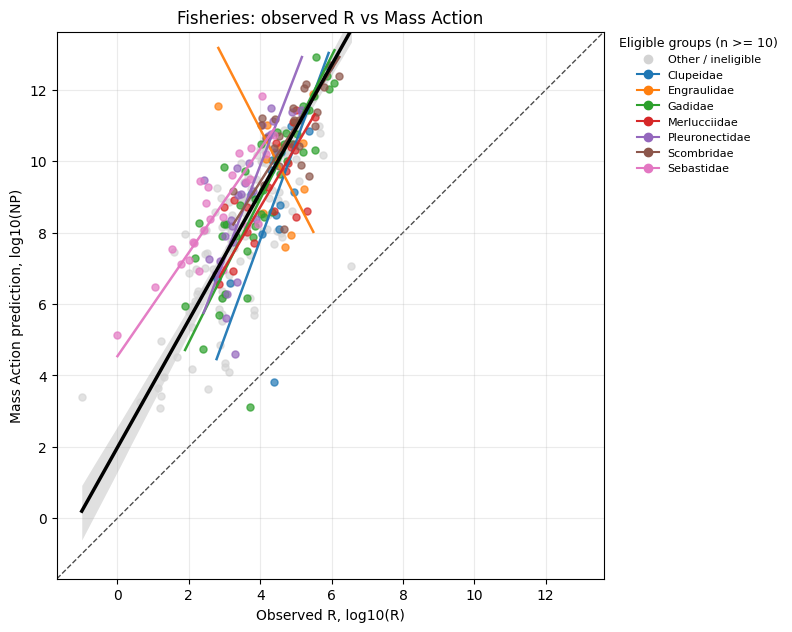

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_global_log10R_vs_log10PT_strict_gear_2012.pdf


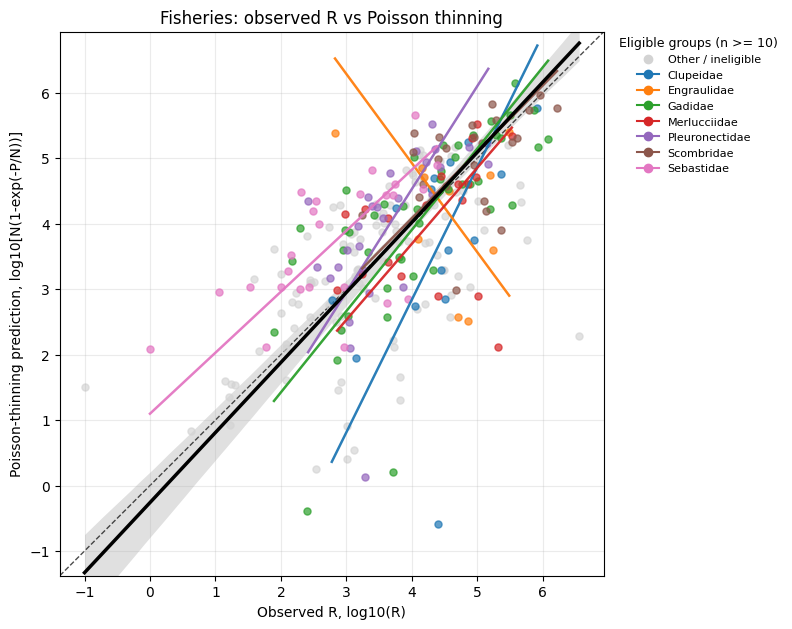

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_global_log10MA_vs_log10reqq_strict_gear_2012.pdf


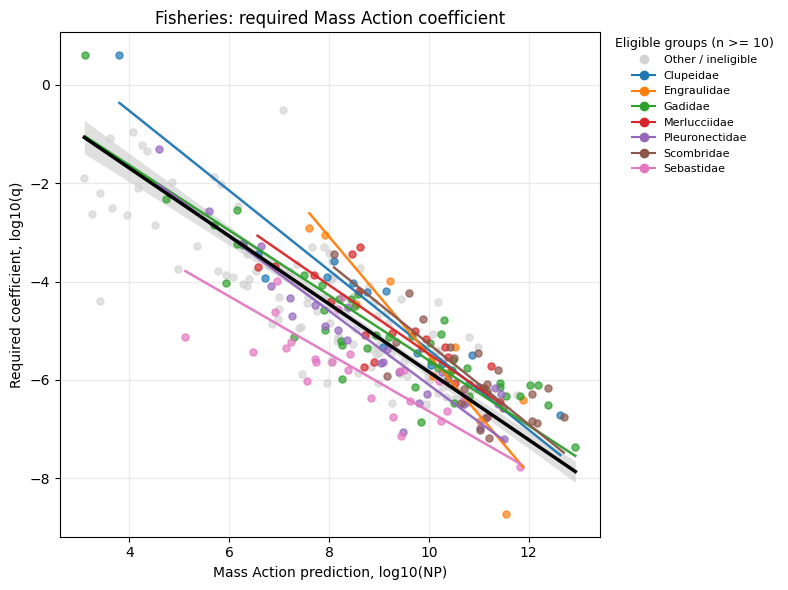

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_global_log10PT_vs_log10reqz_strict_gear_2012.pdf


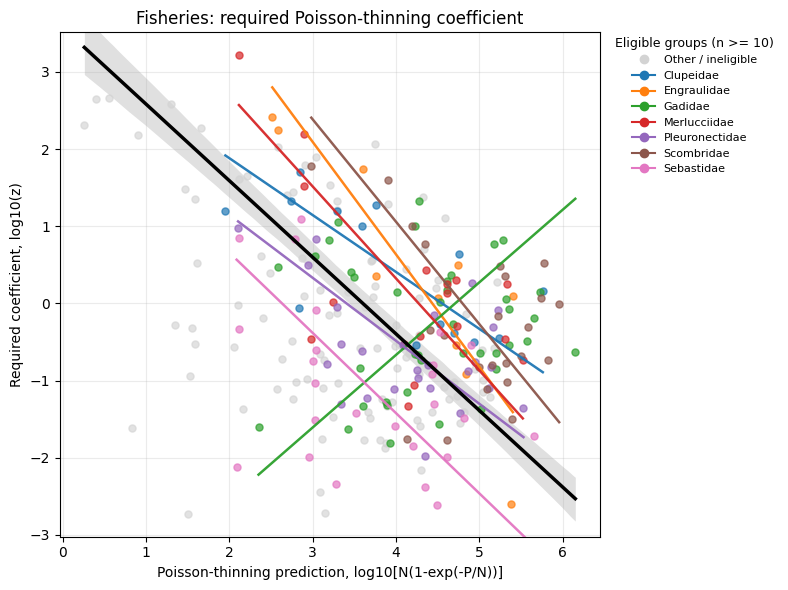

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_log10PT_vs_log10MA_strict_gear_2012.pdf


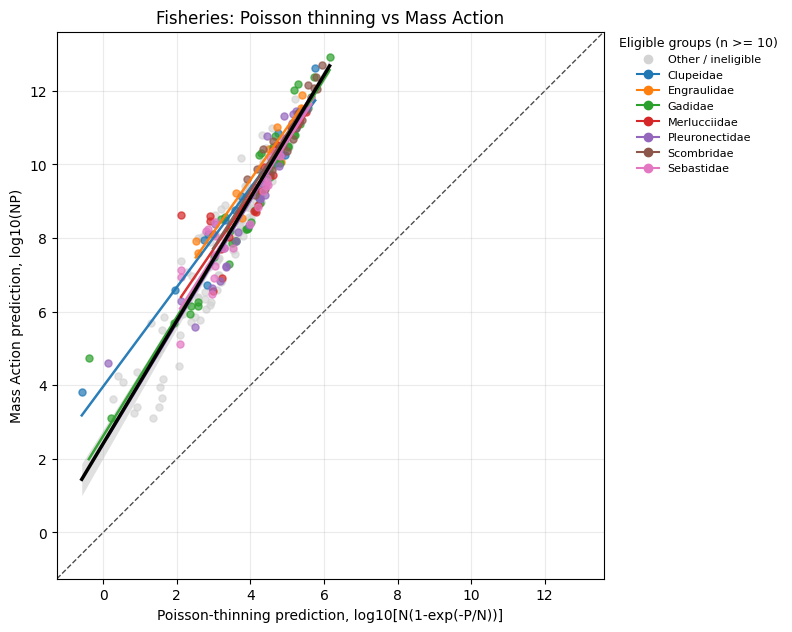

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_forest_MA_PT_merged_strict_gear_2012.pdf


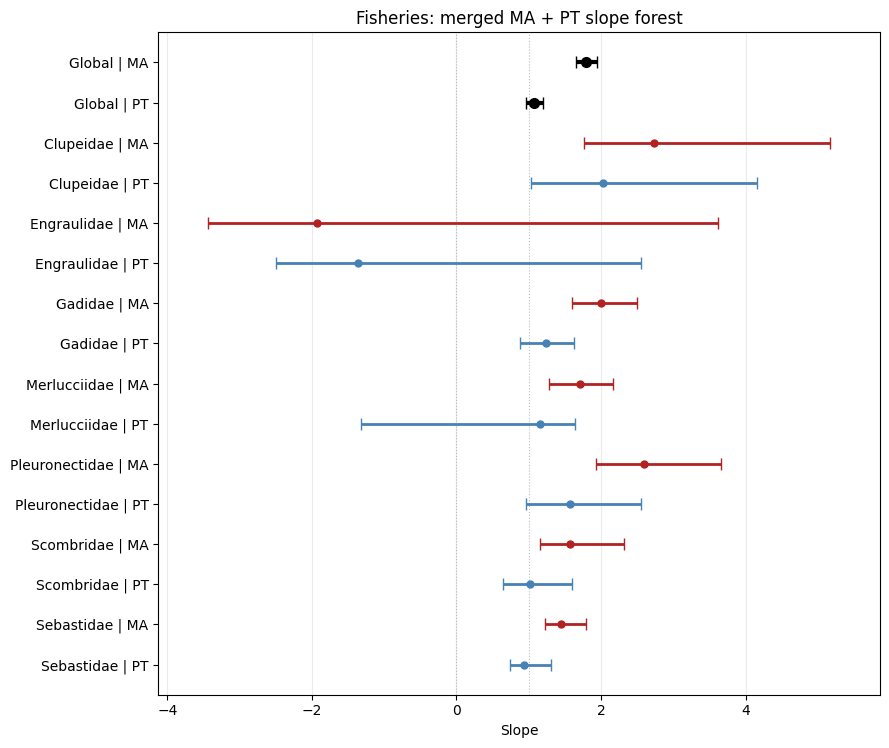

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_forest_reqq_reqz_merged_strict_gear_2012.pdf


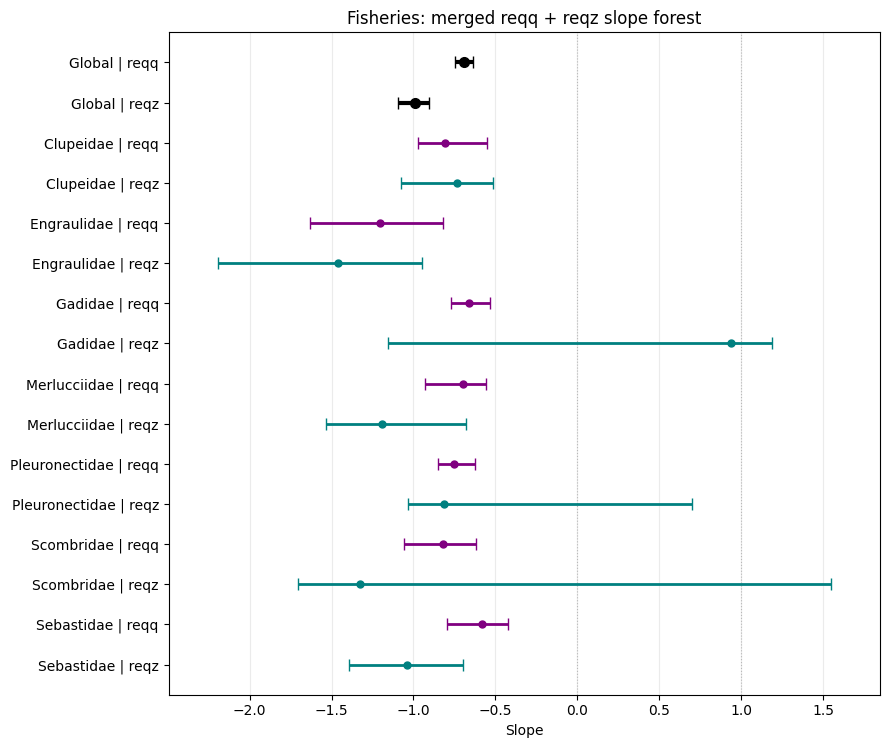

Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_forest_crossover_strict_gear_2012.pdf


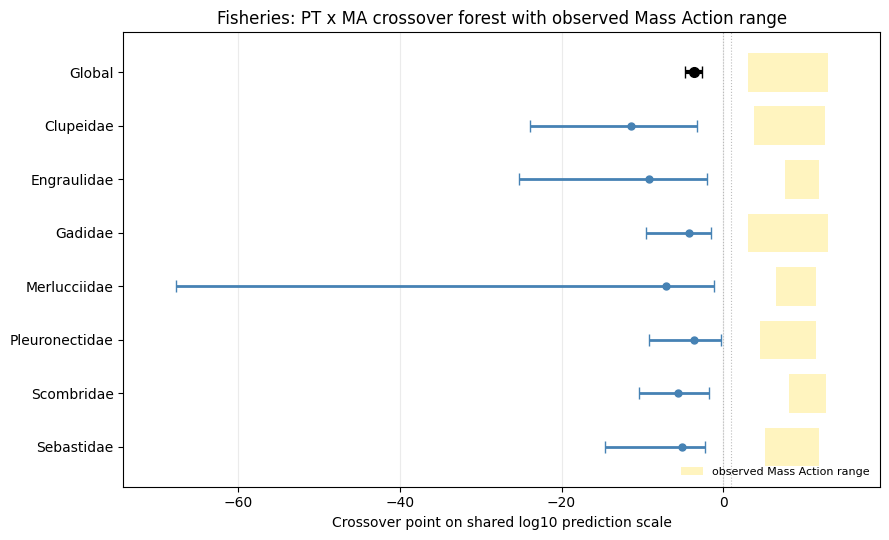

Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/tables/fisheries_gfw_displayed_line_stats_strict_gear_2012.csv
Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/fisheries_gfw_plot_manifest_strict_gear_2012.csv


In [190]:
# Cell 190: Shared plot generation and output manifest
# Generates the shared analysis figures and writes the output manifest.
# Produces PDF plots, plot metadata, fit summaries, and the final manifest table.

print_header("PHASE 5: Generate plots")

manifest_rows = []
displayed_stats_parts = []
for model_name, specification in MODEL_PLOT_SPECS.items():
    global_row = global_fits.loc[global_fits["model"].eq(model_name)].copy()
    group_rows = group_fits.loc[group_fits["model"].eq(model_name)].copy() if len(group_fits) else pd.DataFrame()
    stats = plot_global_plus_group_lines(analysis, global_row, group_rows, model_name, specification)
    displayed_stats_parts.append(stats)
    manifest_rows.append({
        "figure": model_name,
        "figure_type": "scatter_with_SMA_lines",
        "n_points": int(analysis[[specification["x"], specification["y"]]].dropna().shape[0]),
        "n_group_fits": int(len(group_rows)),
        "path": str(specification["path"]),
    })

manifest_rows.append(plot_merged_forest(
    ["MA", "PT"],
    {"MA": "firebrick", "PT": "steelblue"},
    f"{SYSTEM_NAME}: merged MA + PT slope forest",
    FOREST_MA_PT_MERGED_PATH,
))
manifest_rows.append(plot_merged_forest(
    ["reqq", "reqz"],
    {"reqq": "purple", "reqz": "teal"},
    f"{SYSTEM_NAME}: merged reqq + reqz slope forest",
    FOREST_REQQ_REQZ_MERGED_PATH,
))
manifest_rows.append(plot_crossover_forest(FOREST_CROSSOVER_PATH))

all_displayed_stats = pd.concat(displayed_stats_parts, ignore_index=True) if displayed_stats_parts else pd.DataFrame()
plot_manifest = pd.DataFrame(manifest_rows)
plot_manifest["exists"] = plot_manifest["path"].map(lambda path: Path(path).exists())

save_csv(all_displayed_stats, DISPLAYED_STATS_PATH, index=False)
save_csv(plot_manifest, PLOT_MANIFEST_PATH, index=False)



In [191]:
# Cell 191: Bayesian SMA configuration and dependencies
# Defines the symmetric Bayesian verification layer without changing primary SMA fits.

# This symmetric hierarchical Bayesian verification replaces the earlier
# collaborator-derived directional regression and subsequent theory-prior
# sensitivity experiments. The production Bayesian model now matches the
# Type-II/SMA inferential question used in the primary analysis.

bayesian_plot_manifest_rows = []
bayesian_line_stats = pd.DataFrame()
bayesian_model_diagnostics = pd.DataFrame()
bayesian_sma_comparison = pd.DataFrame()
bayesian_idata_by_model = {}


def load_bayesian_dependencies():
    global pm, az, pt
    try:
        import pymc as pm_import
        import arviz as az_import
        import pytensor.tensor as pt
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", "pymc", "arviz"]
        )
        import pymc as pm_import
        import arviz as az_import
        import pytensor.tensor as pt
    pm = pm_import
    az = az_import
    print(f"PyMC version: {pm.__version__}")
    print(f"ArviZ version: {az.__version__}")
    return pm, az


def load_arviz_dependency():
    global az
    if "az" in globals():
        return az
    try:
        import arviz as az_import
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "arviz"])
        import arviz as az_import
    az = az_import
    print(f"ArviZ version: {az.__version__}")
    return az


def bayesian_context_fields():
    return {
        "system": SYSTEM_NAME,
        "year": ANALYSIS_YEAR if ANALYSIS_YEAR is not None else np.nan,
        "P_definition": PRIMARY_P_DEFINITION if PRIMARY_P_DEFINITION is not None else np.nan,
    }


def bayesian_prior_widths(multiplier=BAYES_PRIOR_WIDTH_MULTIPLIER):
    multiplier = float(multiplier)
    if not np.isfinite(multiplier) or multiplier <= 0:
        raise ValueError("Bayesian prior-width multiplier must be finite and positive")
    return {
        "prior_location_sd": BAYES_PRIOR_LOCATION_SD * multiplier,
        "prior_log_scale_sd": BAYES_PRIOR_LOG_SCALE_SD * multiplier,
        "prior_fisher_rho_sd": BAYES_PRIOR_FISHER_RHO_SD * multiplier,
        "prior_group_location_sd": BAYES_PRIOR_GROUP_LOCATION_SD * multiplier,
        "prior_group_log_scale_sd": BAYES_PRIOR_GROUP_LOG_SCALE_SD * multiplier,
        "prior_group_fisher_rho_sd": BAYES_PRIOR_GROUP_FISHER_RHO_SD * multiplier,
        "prior_width_multiplier": multiplier,
    }


def bayesian_figure_path(specification):
    source = Path(specification["path"])
    return source.with_name(f"{source.stem}_bayesian_sma{source.suffix}")


def bayesian_draws_dir():
    root = WORKING_DIR if "WORKING_DIR" in globals() else DATA_DIR / "working"
    return Path(root) / "bayesian_draws"


def save_bayesian_draws_if_requested(idata, fit_type, model_name):
    if not SAVE_BAYESIAN_DRAWS:
        return np.nan
    out_dir = ensure_dir(bayesian_draws_dir())
    out_path = out_dir / f"{SYSTEM_PREFIX}_{model_name}_{fit_type}{OUTPUT_SUFFIX}.nc"
    idata.to_netcdf(out_path)
    return str(out_path)



In [192]:
# Cell 192: Bayesian SMA helper functions
# Prepares identical relationship membership, symmetric MVN models, diagnostics, and summaries.

def prepare_bayesian_fit_data(df, xcol, ycol, group_col=None):
    required = [xcol, ycol] + ([group_col] if group_col is not None else [])
    check_required_columns(df, required, df_name="Bayesian SMA input")
    identity_columns = [col for col in ["analysis_obs_id", "obs_id"] if col in df.columns]
    columns = list(dict.fromkeys(identity_columns + required))
    sub = df[columns].copy()
    sub[xcol] = pd.to_numeric(sub[xcol], errors="coerce")
    sub[ycol] = pd.to_numeric(sub[ycol], errors="coerce")
    finite = np.isfinite(sub[xcol].to_numpy(dtype=float)) & np.isfinite(sub[ycol].to_numpy(dtype=float))
    sub = sub.loc[finite].copy().reset_index(drop=True)
    if group_col is not None:
        sub[group_col] = sub[group_col].astype(str)
    return sub


def standardize_bayesian_xy(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_center = float(np.mean(x))
    y_center = float(np.mean(y))
    x_scale = float(np.std(x, ddof=1))
    y_scale = float(np.std(y, ddof=1))
    constants = np.array([x_center, x_scale, y_center, y_scale], dtype=float)
    if not np.isfinite(constants).all() or x_scale <= 0 or y_scale <= 0:
        raise ValueError("Bayesian SMA standardization requires finite centers and positive sample SDs")
    return {
        "x": (x - x_center) / x_scale,
        "y": (y - y_center) / y_scale,
        "x_center": x_center,
        "x_scale": x_scale,
        "y_center": y_center,
        "y_scale": y_scale,
    }


def sma_slope_from_components(rho, sigma_x, sigma_y):
    return np.sign(rho) * np.asarray(sigma_y) / np.asarray(sigma_x)


def backtransform_sma_line(slope_std, intercept_std, standardization):
    slope = np.asarray(slope_std) * standardization["y_scale"] / standardization["x_scale"]
    intercept = (
        standardization["y_center"]
        + standardization["y_scale"] * np.asarray(intercept_std)
        - slope * standardization["x_center"]
    )
    return slope, intercept


def covariance_from_components(sigma_x, sigma_y, rho):
    return np.array(
        [[sigma_x ** 2, rho * sigma_x * sigma_y],
         [rho * sigma_x * sigma_y, sigma_y ** 2]],
        dtype=float,
    )


def bayesian_sma_helper_tests():
    """Runtime helper checks; defined here but not executed automatically."""
    assert np.isclose(sma_slope_from_components(0.5, 2.0, 6.0), 3.0)
    assert np.isclose(sma_slope_from_components(-0.5, 2.0, 6.0), -3.0)
    slope_xy = sma_slope_from_components(0.5, 2.0, 6.0)
    slope_yx = sma_slope_from_components(0.5, 6.0, 2.0)
    assert np.isclose(slope_xy * slope_yx, 1.0)
    constants = {"x_center": 3.0, "x_scale": 2.0, "y_center": -1.0, "y_scale": 4.0}
    expected_slope, expected_intercept = 1.5, -0.25
    slope_std = expected_slope * constants["x_scale"] / constants["y_scale"]
    intercept_std = (
        expected_intercept - constants["y_center"] + expected_slope * constants["x_center"]
    ) / constants["y_scale"]
    recovered = backtransform_sma_line(slope_std, intercept_std, constants)
    assert np.allclose(recovered, [expected_slope, expected_intercept])
    for sigma_x, sigma_y in [(0.2, 0.5), (1.0, 1.0), (2.0, 3.0)]:
        for fisher_rho in [-3.0, -0.7, 0.0, 0.7, 3.0]:
            covariance = covariance_from_components(sigma_x, sigma_y, np.tanh(fisher_rho))
            assert np.all(np.linalg.eigvalsh(covariance) > -1e-12)
    return True


def current_eligible_groups(keep_col, group_col=GROUP_COL):
    check_required_columns(group_eligibility, [group_col, keep_col], df_name="group_eligibility")
    groups = group_eligibility.loc[group_eligibility[keep_col], group_col].dropna().astype(str).tolist()
    if len(groups) != len(set(groups)):
        raise RuntimeError(f"Duplicate eligible group labels for {keep_col}")
    return groups


def assert_pooled_membership(sub, model_name):
    classical = global_fits.loc[global_fits["model"].eq(model_name), "n"]
    if len(classical) != 1 or int(classical.iloc[0]) != len(sub):
        raise RuntimeError(f"Pooled Bayesian membership differs from global SMA for {model_name}")


def prepare_bayesian_hierarchical_data(df, spec, model_name, group_col=GROUP_COL):
    groups = current_eligible_groups(spec["keep_col"], group_col=group_col)
    if len(groups) < 2:
        raise ValueError(f"Hierarchical Bayesian SMA requires at least two eligible groups for {model_name}")
    finite = prepare_bayesian_fit_data(df, spec["xcol"], spec["ycol"], group_col=group_col)
    sub = finite.loc[finite[group_col].isin(groups)].copy().reset_index(drop=True)
    counts = sub.groupby(group_col).size().reindex(groups)
    if counts.isna().any() or set(sub[group_col]) != set(groups):
        raise RuntimeError(f"Bayesian groups differ from group_eligibility for {model_name}")
    classical = group_fits.loc[group_fits["model"].eq(model_name), ["group_label", "n"]].copy()
    classical_counts = classical.set_index("group_label")["n"].to_dict()
    for group_name, count in counts.items():
        if int(classical_counts.get(group_name, -1)) != int(count):
            raise RuntimeError(f"Bayesian and classical group membership differ for {model_name} / {group_name}")
    group_index = pd.Categorical(sub[group_col], categories=groups, ordered=True).codes.astype(int)
    standardized = standardize_bayesian_xy(sub[spec["xcol"]], sub[spec["ycol"]])
    return {
        "data": sub,
        "group_names": groups,
        "group_index": group_index,
        "group_counts": counts.astype(int).to_dict(),
        **standardized,
    }


def _factorized_bivariate_gaussian_likelihood(
    name_prefix, observed_x, observed_y, mu_x, mu_y, sigma_x, sigma_y, rho, dims=None,
):
    """Same joint MVN density evaluated as p(x) * p(y | x)."""
    prefix = f"{name_prefix}_" if name_prefix else ""
    x_observation = pm.Normal(
        f"{prefix}x_obs", mu=mu_x, sigma=sigma_x, observed=observed_x, dims=dims
    )
    conditional_y_mean = mu_y + rho * (sigma_y / sigma_x) * (x_observation - mu_x)
    conditional_y_sigma = sigma_y * pm.math.sqrt(1.0 - rho ** 2)
    pm.Normal(
        f"{prefix}y_obs", mu=conditional_y_mean, sigma=conditional_y_sigma,
        observed=observed_y, dims=dims,
    )


def _deterministic_original_line(prefix, mu_x, mu_y, sigma_x, sigma_y, rho, standardization, dims=None):
    slope_std = pt.sign(rho) * sigma_y / sigma_x
    intercept_std = mu_y - slope_std * mu_x
    slope = pm.Deterministic(
        f"{prefix}sma_slope", slope_std * standardization["y_scale"] / standardization["x_scale"], dims=dims
    )
    intercept = pm.Deterministic(
        f"{prefix}sma_intercept",
        standardization["y_center"] + standardization["y_scale"] * intercept_std
        - slope * standardization["x_center"],
        dims=dims,
    )
    pm.Deterministic(f"{prefix}rho", rho, dims=dims)
    pm.Deterministic(f"{prefix}sigma_x", sigma_x * standardization["x_scale"], dims=dims)
    pm.Deterministic(f"{prefix}sigma_y", sigma_y * standardization["y_scale"], dims=dims)
    return slope, intercept


def build_bayesian_pooled_sma_model(prepared, prior_multiplier=BAYES_PRIOR_WIDTH_MULTIPLIER):
    widths = bayesian_prior_widths(prior_multiplier)
    with pm.Model(coords={"observation": np.arange(len(prepared["x"]))}) as model:
        mu_x = pm.Normal("mu_x", 0.0, widths["prior_location_sd"])
        mu_y = pm.Normal("mu_y", 0.0, widths["prior_location_sd"])
        log_sigma_x = pm.Normal("log_sigma_x", 0.0, widths["prior_log_scale_sd"])
        log_sigma_y = pm.Normal("log_sigma_y", 0.0, widths["prior_log_scale_sd"])
        fisher_rho = pm.Normal("fisher_rho", 0.0, widths["prior_fisher_rho_sd"])
        sigma_x = pm.math.exp(log_sigma_x)
        sigma_y = pm.math.exp(log_sigma_y)
        rho = pm.math.tanh(fisher_rho)
        _deterministic_original_line("", mu_x, mu_y, sigma_x, sigma_y, rho, prepared)
        _factorized_bivariate_gaussian_likelihood(
            "", prepared["x"], prepared["y"], mu_x, mu_y,
            sigma_x, sigma_y, rho, dims="observation",
        )
    return model, widths


def build_bayesian_hierarchical_sma_model(prepared, prior_multiplier=BAYES_PRIOR_WIDTH_MULTIPLIER):
    widths = bayesian_prior_widths(prior_multiplier)
    coords = {"group": prepared["group_names"]}
    with pm.Model(coords=coords) as model:
        mu_x_population = pm.Normal("mu_x_population", 0.0, widths["prior_location_sd"])
        mu_y_population = pm.Normal("mu_y_population", 0.0, widths["prior_location_sd"])
        tau_mu_x = pm.HalfNormal("tau_mu_x", widths["prior_group_location_sd"])
        tau_mu_y = pm.HalfNormal("tau_mu_y", widths["prior_group_location_sd"])
        z_mu_x = pm.Normal("z_mu_x", 0.0, 1.0, dims="group")
        z_mu_y = pm.Normal("z_mu_y", 0.0, 1.0, dims="group")
        mu_x_group = pm.Deterministic("mu_x_group", mu_x_population + tau_mu_x * z_mu_x, dims="group")
        mu_y_group = pm.Deterministic("mu_y_group", mu_y_population + tau_mu_y * z_mu_y, dims="group")

        log_sigma_x_population = pm.Normal("log_sigma_x_population", 0.0, widths["prior_log_scale_sd"])
        log_sigma_y_population = pm.Normal("log_sigma_y_population", 0.0, widths["prior_log_scale_sd"])
        tau_log_sigma_x = pm.HalfNormal("tau_log_sigma_x", widths["prior_group_log_scale_sd"])
        tau_log_sigma_y = pm.HalfNormal("tau_log_sigma_y", widths["prior_group_log_scale_sd"])
        z_log_sigma_x = pm.Normal("z_log_sigma_x", 0.0, 1.0, dims="group")
        z_log_sigma_y = pm.Normal("z_log_sigma_y", 0.0, 1.0, dims="group")
        sigma_x_population = pm.math.exp(log_sigma_x_population)
        sigma_y_population = pm.math.exp(log_sigma_y_population)
        sigma_x_group_std = pm.math.exp(log_sigma_x_population + tau_log_sigma_x * z_log_sigma_x)
        sigma_y_group_std = pm.math.exp(log_sigma_y_population + tau_log_sigma_y * z_log_sigma_y)

        fisher_rho_population = pm.Normal("fisher_rho_population", 0.0, widths["prior_fisher_rho_sd"])
        tau_fisher_rho = pm.HalfNormal("tau_fisher_rho", widths["prior_group_fisher_rho_sd"])
        z_fisher_rho = pm.Normal("z_fisher_rho", 0.0, 1.0, dims="group")
        rho_population_std = pm.math.tanh(fisher_rho_population)
        rho_group_std = pm.math.tanh(fisher_rho_population + tau_fisher_rho * z_fisher_rho)

        _deterministic_original_line(
            "population_", mu_x_population, mu_y_population, sigma_x_population,
            sigma_y_population, rho_population_std, prepared,
        )
        _deterministic_original_line(
            "group_", mu_x_group, mu_y_group, sigma_x_group_std,
            sigma_y_group_std, rho_group_std, prepared, dims="group",
        )
        for group_number, group_name in enumerate(prepared["group_names"]):
            group_mask = prepared["group_index"] == group_number
            _factorized_bivariate_gaussian_likelihood(
                f"group_{group_number}",
                prepared["x"][group_mask], prepared["y"][group_mask],
                mu_x_group[group_number], mu_y_group[group_number],
                sigma_x_group_std[group_number], sigma_y_group_std[group_number],
                rho_group_std[group_number],
            )
    return model, widths


def sample_bayesian_sma_model(model, fit_type):
    with model:
        prior = pm.sample_prior_predictive(
            samples=BAYES_PRIOR_PREDICTIVE_DRAWS,
            random_seed=RANDOM_SEED,
            return_inferencedata=True,
        )
        sample_kwargs = {
            "draws": BAYES_DRAWS,
            "tune": BAYES_TUNE,
            "chains": BAYES_CHAINS,
            "cores": min(BAYES_CHAINS, os.cpu_count() or 1),
            "random_seed": RANDOM_SEED,
            "return_inferencedata": True,
        }
        if fit_type == "hierarchical":
            sample_kwargs.update(
                target_accept=BAYES_TARGET_ACCEPT_HIERARCHICAL,
                nuts={"max_treedepth": BAYES_MAX_TREEDEPTH_HIERARCHICAL},
            )
        idata = pm.sample(**sample_kwargs)
        posterior_predictive = pm.sample_posterior_predictive(
            idata, random_seed=RANDOM_SEED, return_inferencedata=True
        )
    idata.extend(prior)
    idata.extend(posterior_predictive)
    return idata


def posterior_values(idata, var_name, selector=None, group="posterior"):
    values = getattr(idata, group)[var_name]
    if selector:
        values = values.sel(selector)
    return np.asarray(values).reshape(-1)


def diagnostic_scalar(idata, var_name, selector, kind):
    if kind == "rhat":
        values = az.rhat(idata, var_names=[var_name])[var_name]
    else:
        values = az.ess(idata, var_names=[var_name], method=kind)[var_name]
    if selector:
        values = values.sel(selector)
    array = np.asarray(values, dtype=float)
    reducer = np.nanmax if kind == "rhat" else np.nanmin
    return float(reducer(array))


def distribution_summary(values, prefix, include_05_95=False):
    values = np.asarray(values, dtype=float).reshape(-1)
    result = {
        f"{prefix}_mean": float(np.mean(values)),
        f"{prefix}_median": float(np.median(values)),
        f"{prefix}_q025": float(np.percentile(values, 2.5)),
        f"{prefix}_q975": float(np.percentile(values, 97.5)),
    }
    if include_05_95:
        result.update({
            f"{prefix}_q05": float(np.percentile(values, 5.0)),
            f"{prefix}_q95": float(np.percentile(values, 95.0)),
        })
    return result


def bayesian_line_summary(idata, model_name, fit_level, group_label, n, n_groups, xcol, ycol, variables, selector=None):
    slope = posterior_values(idata, variables["slope"], selector)
    intercept = posterior_values(idata, variables["intercept"], selector)
    rho = posterior_values(idata, variables["rho"], selector)
    sigma_x = posterior_values(idata, variables["sigma_x"], selector)
    sigma_y = posterior_values(idata, variables["sigma_y"], selector)
    reference = float(SLOPE_REFERENCE_VALUES[model_name])
    row = {
        **bayesian_context_fields(), "model": model_name, "fit_level": fit_level,
        "group_label": group_label, "is_global": fit_level == "pooled_global",
        "xcol": xcol, "ycol": ycol, "n": int(n), "n_groups": int(n_groups),
        "reference_slope": reference,
        "p_slope_below_reference": float(np.mean(slope < reference)),
        "p_slope_above_reference": float(np.mean(slope > reference)),
        "fit_status": "completed",
    }
    row.update(distribution_summary(slope, "slope", include_05_95=True))
    row.update(distribution_summary(intercept, "intercept", include_05_95=True))
    row.update(distribution_summary(rho, "rho"))
    row.update(distribution_summary(sigma_x, "sigma_x"))
    row.update(distribution_summary(sigma_y, "sigma_y"))
    for prefix, variable in variables.items():
        if prefix not in {"slope", "intercept", "rho", "sigma_x", "sigma_y"}:
            continue
        row[f"{prefix}_rhat"] = diagnostic_scalar(idata, variable, selector, "rhat")
        row[f"{prefix}_ess_bulk"] = diagnostic_scalar(idata, variable, selector, "bulk")
        row[f"{prefix}_ess_tail"] = diagnostic_scalar(idata, variable, selector, "tail")
    rhats = [row[f"{name}_rhat"] for name in ["slope", "intercept", "rho", "sigma_x", "sigma_y"]]
    row["max_line_rhat"] = float(np.nanmax(rhats))
    row["rhat_converged"] = bool(row["max_line_rhat"] <= BAYES_RHAT_THRESHOLD)
    return row


def failed_line_rows(
    model_name, spec, fit_type, group_names=None, group_counts=None,
    total_n=np.nan, error_message="",
):
    keys = ["slope", "intercept", "rho", "sigma_x", "sigma_y"]
    levels = [("pooled_global", "Global", total_n)] if fit_type == "pooled_global" else [
        ("hierarchical_population", "Hierarchical population", total_n)
    ] + [("hierarchical_group", group, (group_counts or {}).get(group, np.nan)) for group in (group_names or [])]
    rows = []
    for level, label, n in levels:
        row = {
            **bayesian_context_fields(), "model": model_name, "fit_level": level,
            "group_label": label, "is_global": level == "pooled_global",
            "xcol": spec["xcol"], "ycol": spec["ycol"], "n": n,
            "n_groups": len(group_names or []), "reference_slope": SLOPE_REFERENCE_VALUES[model_name],
            "fit_status": "failed", "error_message": str(error_message), "rhat_converged": False,
        }
        for key in keys:
            for suffix in ["mean", "median", "q025", "q975", "rhat", "ess_bulk", "ess_tail"]:
                row[f"{key}_{suffix}"] = np.nan
        for key in ["slope", "intercept"]:
            row[f"{key}_q05"] = np.nan
            row[f"{key}_q95"] = np.nan
        row.update(p_slope_below_reference=np.nan, p_slope_above_reference=np.nan, max_line_rhat=np.nan)
        rows.append(row)
    return rows


def _joint_statistics(values):
    return np.array([
        np.mean(values[..., 0], axis=-1), np.mean(values[..., 1], axis=-1),
        np.std(values[..., 0], axis=-1, ddof=1), np.std(values[..., 1], axis=-1, ddof=1),
        np.array([np.corrcoef(draw[:, 0], draw[:, 1])[0, 1] for draw in values.reshape(-1, values.shape[-2], 2)]).reshape(values.shape[:-2]),
    ])


def ppc_coverage(observed, predicted):
    observed_stats = _joint_statistics(np.asarray(observed)[None, ...]).reshape(5)
    predicted_stats = _joint_statistics(np.asarray(predicted).reshape(-1, predicted.shape[-2], 2))
    labels = ["mean_x", "mean_y", "sd_x", "sd_y", "r"]
    return {
        label: bool(np.percentile(predicted_stats[index], 2.5) <= observed_stats[index]
                    <= np.percentile(predicted_stats[index], 97.5))
        for index, label in enumerate(labels)
    }


def posterior_predictive_xy(idata, x_name, y_name):
    predicted_x = np.asarray(idata.posterior_predictive[x_name])
    predicted_y = np.asarray(idata.posterior_predictive[y_name])
    return np.stack([predicted_x, predicted_y], axis=-1)


def summarize_ppc(idata, prepared, fit_type):
    if fit_type == "pooled_global":
        observed = np.column_stack([prepared["x"], prepared["y"]])
        predicted = posterior_predictive_xy(idata, "x_obs", "y_obs")
        return {f"ppc_{name}_covered": value for name, value in ppc_coverage(observed, predicted).items()}
    covered = []
    for number in range(len(prepared["group_names"])):
        mask = prepared["group_index"] == number
        observed = np.column_stack([prepared["x"][mask], prepared["y"][mask]])
        predicted = posterior_predictive_xy(
            idata, f"group_{number}_x_obs", f"group_{number}_y_obs"
        )
        covered.append(ppc_coverage(observed, predicted))
    return {
        f"ppc_fraction_groups_{name}_covered": float(np.mean([row[name] for row in covered]))
        for name in ["mean_x", "mean_y", "sd_x", "sd_y", "r"]
    }


def prior_slope_summary(idata, fit_type):
    variable = "sma_slope" if fit_type == "pooled_global" else "population_sma_slope"
    values = posterior_values(idata, variable, group="prior")
    return {
        "prior_slope_q025": float(np.percentile(values, 2.5)),
        "prior_slope_q50": float(np.percentile(values, 50.0)),
        "prior_slope_q975": float(np.percentile(values, 97.5)),
    }


def model_diagnostics(idata, model_name, spec, fit_type, prepared, widths):
    rhat = np.asarray(az.rhat(idata).to_array(), dtype=float)
    ess_bulk = np.asarray(az.ess(idata, method="bulk").to_array(), dtype=float)
    ess_tail = np.asarray(az.ess(idata, method="tail").to_array(), dtype=float)
    divergences = int(np.asarray(idata.sample_stats["diverging"]).sum())
    depths = np.asarray(idata.sample_stats["tree_depth"])
    max_depth = BAYES_MAX_TREEDEPTH_HIERARCHICAL if fit_type == "hierarchical" else np.nan
    treedepth_hits = int(np.sum(depths >= max_depth)) if np.isfinite(max_depth) else 0
    max_rhat = float(np.nanmax(rhat))
    converged_rhat = bool(max_rhat <= BAYES_RHAT_THRESHOLD)
    row = {
        **bayesian_context_fields(), "model": model_name, "fit_type": fit_type,
        "xcol": spec["xcol"], "ycol": spec["ycol"], "n": len(prepared["x"]),
        "n_groups": len(prepared.get("group_names", [])),
        "x_center": prepared["x_center"], "x_scale": prepared["x_scale"],
        "y_center": prepared["y_center"], "y_scale": prepared["y_scale"],
        **widths, "chains": BAYES_CHAINS, "draws": BAYES_DRAWS, "tune": BAYES_TUNE,
        "target_accept": BAYES_TARGET_ACCEPT_HIERARCHICAL if fit_type == "hierarchical" else np.nan,
        "max_treedepth": max_depth, "random_seed": RANDOM_SEED,
        "max_model_rhat": max_rhat, "min_ess_bulk": float(np.nanmin(ess_bulk)),
        "min_ess_tail": float(np.nanmin(ess_tail)), "divergences": divergences,
        "treedepth_hits": treedepth_hits, "rhat_threshold": BAYES_RHAT_THRESHOLD,
        "model_rhat_converged": converged_rhat, "zero_divergences": divergences == 0,
        "model_converged": converged_rhat and divergences == 0,
        "fit_status": "completed", "error_message": "",
    }
    row.update(prior_slope_summary(idata, fit_type))
    row.update(summarize_ppc(idata, prepared, fit_type))
    return row


def failed_model_diagnostic(
    model_name, spec, fit_type, prepared=None, error_message="",
    n_override=None, n_groups_override=None,
):
    widths = bayesian_prior_widths()
    prepared = prepared or {}
    row = {
        **bayesian_context_fields(), "model": model_name, "fit_type": fit_type,
        "xcol": spec["xcol"], "ycol": spec["ycol"],
        "n": len(prepared.get("x", [])) if n_override is None else n_override,
        "n_groups": len(prepared.get("group_names", [])) if n_groups_override is None else n_groups_override,
        **widths,
        "x_center": prepared.get("x_center", np.nan), "x_scale": prepared.get("x_scale", np.nan),
        "y_center": prepared.get("y_center", np.nan), "y_scale": prepared.get("y_scale", np.nan),
        "chains": BAYES_CHAINS, "draws": BAYES_DRAWS, "tune": BAYES_TUNE,
        "target_accept": BAYES_TARGET_ACCEPT_HIERARCHICAL if fit_type == "hierarchical" else np.nan,
        "max_treedepth": BAYES_MAX_TREEDEPTH_HIERARCHICAL if fit_type == "hierarchical" else np.nan,
        "random_seed": RANDOM_SEED, "rhat_threshold": BAYES_RHAT_THRESHOLD,
        "max_model_rhat": np.nan, "min_ess_bulk": np.nan, "min_ess_tail": np.nan,
        "divergences": np.nan, "treedepth_hits": np.nan, "model_rhat_converged": False,
        "zero_divergences": False, "model_converged": False, "fit_status": "failed",
        "error_message": str(error_message), "prior_slope_q025": np.nan,
        "prior_slope_q50": np.nan, "prior_slope_q975": np.nan,
    }
    for name in ["mean_x", "mean_y", "sd_x", "sd_y", "r"]:
        row[f"ppc_{name}_covered"] = np.nan
        row[f"ppc_fraction_groups_{name}_covered"] = np.nan
    return row


POOLED_LINE_VARIABLES = {
    "slope": "sma_slope", "intercept": "sma_intercept", "rho": "rho",
    "sigma_x": "sigma_x", "sigma_y": "sigma_y",
}
POPULATION_LINE_VARIABLES = {
    "slope": "population_sma_slope", "intercept": "population_sma_intercept",
    "rho": "population_rho", "sigma_x": "population_sigma_x", "sigma_y": "population_sigma_y",
}
GROUP_LINE_VARIABLES = {
    "slope": "group_sma_slope", "intercept": "group_sma_intercept", "rho": "group_rho",
    "sigma_x": "group_sigma_x", "sigma_y": "group_sigma_y",
}

BAYESIAN_LINE_STATS_COLUMNS = [
    "system", "year", "P_definition", "model", "fit_level", "group_label",
    "is_global", "xcol", "ycol", "n", "n_groups",
    "slope_mean", "slope_median", "slope_q025", "slope_q05", "slope_q95", "slope_q975",
    "intercept_mean", "intercept_median", "intercept_q025", "intercept_q05",
    "intercept_q95", "intercept_q975",
    "rho_mean", "rho_median", "rho_q025", "rho_q975",
    "sigma_x_mean", "sigma_x_median", "sigma_x_q025", "sigma_x_q975",
    "sigma_y_mean", "sigma_y_median", "sigma_y_q025", "sigma_y_q975",
    "reference_slope", "p_slope_below_reference", "p_slope_above_reference",
    "slope_rhat", "slope_ess_bulk", "slope_ess_tail",
    "intercept_rhat", "intercept_ess_bulk", "intercept_ess_tail",
    "rho_rhat", "rho_ess_bulk", "rho_ess_tail",
    "sigma_x_rhat", "sigma_x_ess_bulk", "sigma_x_ess_tail",
    "sigma_y_rhat", "sigma_y_ess_bulk", "sigma_y_ess_tail",
    "max_line_rhat", "rhat_converged", "fit_status", "error_message",
]

BAYESIAN_MODEL_DIAGNOSTIC_COLUMNS = [
    "system", "year", "P_definition", "model", "fit_type", "xcol", "ycol", "n", "n_groups",
    "prior_location_sd", "prior_log_scale_sd", "prior_fisher_rho_sd",
    "prior_group_location_sd", "prior_group_log_scale_sd", "prior_group_fisher_rho_sd",
    "prior_width_multiplier", "x_center", "x_scale", "y_center", "y_scale",
    "chains", "draws", "tune", "target_accept", "max_treedepth", "random_seed",
    "max_model_rhat", "min_ess_bulk", "min_ess_tail", "divergences", "treedepth_hits",
    "rhat_threshold", "model_rhat_converged", "zero_divergences", "model_converged",
    "fit_status", "error_message", "prior_slope_q025", "prior_slope_q50", "prior_slope_q975",
    "ppc_mean_x_covered", "ppc_mean_y_covered", "ppc_sd_x_covered", "ppc_sd_y_covered",
    "ppc_r_covered", "ppc_fraction_groups_mean_x_covered",
    "ppc_fraction_groups_mean_y_covered", "ppc_fraction_groups_sd_x_covered",
    "ppc_fraction_groups_sd_y_covered", "ppc_fraction_groups_r_covered",
]


def build_classical_bayesian_sma_comparison(line_stats):
    rows = []
    pooled = line_stats.loc[line_stats["fit_level"].eq("pooled_global")]
    for _, bayes_row in pooled.iterrows():
        classical = global_fits.loc[global_fits["model"].eq(bayes_row["model"])]
        if len(classical) == 1:
            rows.append({
                "model": bayes_row["model"], "fit_level": "pooled_global", "group_label": "Global",
                "n": bayes_row["n"], "classical_sma_slope": classical.iloc[0]["slope"],
                "bayesian_sma_slope_median": bayes_row["slope_median"],
                "difference": bayes_row["slope_median"] - classical.iloc[0]["slope"],
            })
    groups = line_stats.loc[line_stats["fit_level"].eq("hierarchical_group")]
    for _, bayes_row in groups.iterrows():
        classical = group_fits.loc[
            group_fits["model"].eq(bayes_row["model"])
            & group_fits["group_label"].eq(bayes_row["group_label"])
        ]
        if len(classical) == 1:
            rows.append({
                "model": bayes_row["model"], "fit_level": "hierarchical_group",
                "group_label": bayes_row["group_label"], "n": bayes_row["n"],
                "classical_sma_slope": classical.iloc[0]["slope"],
                "bayesian_sma_slope_median": bayes_row["slope_median"],
                "difference": bayes_row["slope_median"] - classical.iloc[0]["slope"],
            })
    return pd.DataFrame(rows)


def bayesian_model_names_to_run():
    if BAYES_MODELS_TO_RUN is None:
        return list(MODEL_SPECS)
    if isinstance(BAYES_MODELS_TO_RUN, str) or not isinstance(BAYES_MODELS_TO_RUN, (tuple, list)):
        raise TypeError("BAYES_MODELS_TO_RUN must be None or a tuple/list of MODEL_SPECS names")
    selected = list(BAYES_MODELS_TO_RUN)
    if not selected:
        raise ValueError("BAYES_MODELS_TO_RUN cannot be empty; use None for all Bayesian models")
    if not all(isinstance(model_name, str) for model_name in selected):
        raise TypeError("Every BAYES_MODELS_TO_RUN entry must be a MODEL_SPECS name string")
    if len(selected) != len(set(selected)):
        raise ValueError("BAYES_MODELS_TO_RUN contains duplicate model names")
    unknown = sorted(set(selected) - set(MODEL_SPECS))
    if unknown:
        raise ValueError(f"Unknown BAYES_MODELS_TO_RUN names: {unknown}")
    return selected


BAYESIAN_CHECKPOINT_SCHEMA_VERSION = "bayesian-relationship-checkpoint-v1"


def checkpoint_jsonable(value):
    if isinstance(value, dict):
        return {
            str(key): checkpoint_jsonable(value[key])
            for key in sorted(value, key=lambda item: str(item))
        }
    if isinstance(value, (list, tuple)):
        return [checkpoint_jsonable(item) for item in value]
    if isinstance(value, np.ndarray):
        return [checkpoint_jsonable(item) for item in value.tolist()]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        numeric = float(value)
        return numeric if np.isfinite(numeric) else None
    if value is None:
        return None
    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass
    return str(value) if not isinstance(value, str) else value


def checkpoint_json_dumps(value):
    return json.dumps(
        checkpoint_jsonable(value),
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    )


def checkpoint_json_sha256(value):
    return hashlib.sha256(checkpoint_json_dumps(value).encode("utf-8")).hexdigest()


def bayesian_checkpoint_relationship_dir(model_name):
    return Path(BAYESIAN_CHECKPOINT_DIR) / model_name


def bayesian_checkpoint_file_stem(model_name):
    return f"{SYSTEM_PREFIX}_{model_name}{OUTPUT_SUFFIX}"


def bayesian_checkpoint_filenames(model_name):
    stem = bayesian_checkpoint_file_stem(model_name)
    return {
        "pooled_idata": f"{stem}_pooled_global.nc",
        "hierarchical_idata": f"{stem}_hierarchical.nc",
        "line_stats": f"{stem}_line_stats.csv",
        "model_diagnostics": f"{stem}_model_diagnostics.csv",
        "manifest": f"{stem}_manifest.json",
        "marker": f"{stem}_COMPLETE.json",
    }


def bayesian_checkpoint_identity_columns(df, spec, include_group=False):
    columns = [col for col in ["analysis_obs_id", "obs_id"] if col in df.columns]
    columns.extend([spec["xcol"], spec["ycol"]])
    if include_group and GROUP_COL in df.columns:
        columns.append(GROUP_COL)
    return list(dict.fromkeys(columns))


def dataframe_checkpoint_sha256(df, columns):
    records = [
        [checkpoint_jsonable(value) for value in row]
        for row in df.loc[:, columns].itertuples(index=False, name=None)
    ]
    return checkpoint_json_sha256({"columns": columns, "records": records})


def bayesian_checkpoint_standardization(prepared):
    return {
        "x_center": prepared["x_center"],
        "x_scale": prepared["x_scale"],
        "y_center": prepared["y_center"],
        "y_scale": prepared["y_scale"],
    }


def bayesian_checkpoint_expected_metadata(model_name, spec, pooled_sub, pooled_prepared, hierarchical_prepared):
    pooled_columns = bayesian_checkpoint_identity_columns(pooled_sub, spec, include_group=False)
    hierarchical_columns = bayesian_checkpoint_identity_columns(
        hierarchical_prepared["data"], spec, include_group=True
    )
    return {
        "schema_version": BAYESIAN_CHECKPOINT_SCHEMA_VERSION,
        "system_name": SYSTEM_NAME,
        "system_prefix": SYSTEM_PREFIX,
        "analysis_year": ANALYSIS_YEAR,
        "P_definition": PRIMARY_P_DEFINITION,
        "output_suffix": OUTPUT_SUFFIX,
        "model": model_name,
        "xcol": spec["xcol"],
        "ycol": spec["ycol"],
        "keep_col": spec["keep_col"],
        "model_spec": dict(spec),
        "fit_membership_n": int(len(pooled_sub)),
        "hierarchical_fit_membership_n": int(len(hierarchical_prepared["data"])),
        "hierarchical_group_names": [str(group) for group in hierarchical_prepared["group_names"]],
        "hierarchical_group_counts": {
            str(group): int(count)
            for group, count in hierarchical_prepared["group_counts"].items()
        },
        "random_seed": int(RANDOM_SEED),
        "bayes_chains": int(BAYES_CHAINS),
        "bayes_draws": int(BAYES_DRAWS),
        "bayes_tune": int(BAYES_TUNE),
        "bayes_prior_predictive_draws": int(BAYES_PRIOR_PREDICTIVE_DRAWS),
        "bayes_target_accept_hierarchical": float(BAYES_TARGET_ACCEPT_HIERARCHICAL),
        "bayes_max_treedepth_hierarchical": int(BAYES_MAX_TREEDEPTH_HIERARCHICAL),
        "bayes_rhat_threshold": float(BAYES_RHAT_THRESHOLD),
        "bayes_prior_width_multiplier": float(BAYES_PRIOR_WIDTH_MULTIPLIER),
        "bayes_prior_location_sd": float(BAYES_PRIOR_LOCATION_SD),
        "bayes_prior_log_scale_sd": float(BAYES_PRIOR_LOG_SCALE_SD),
        "bayes_prior_fisher_rho_sd": float(BAYES_PRIOR_FISHER_RHO_SD),
        "bayes_prior_group_location_sd": float(BAYES_PRIOR_GROUP_LOCATION_SD),
        "bayes_prior_group_log_scale_sd": float(BAYES_PRIOR_GROUP_LOG_SCALE_SD),
        "bayes_prior_group_fisher_rho_sd": float(BAYES_PRIOR_GROUP_FISHER_RHO_SD),
        "min_group_n": int(MIN_GROUP_N),
        "slope_reference": float(SLOPE_REFERENCE_VALUES[model_name]),
        "pooled_standardization": bayesian_checkpoint_standardization(pooled_prepared),
        "hierarchical_standardization": bayesian_checkpoint_standardization(hierarchical_prepared),
        "bayesian_line_stats_columns": BAYESIAN_LINE_STATS_COLUMNS,
        "bayesian_model_diagnostic_columns": BAYESIAN_MODEL_DIAGNOSTIC_COLUMNS,
        "pooled_input_columns": pooled_columns,
        "hierarchical_input_columns": hierarchical_columns,
        "pooled_input_sha256": dataframe_checkpoint_sha256(pooled_sub, pooled_columns),
        "hierarchical_input_sha256": dataframe_checkpoint_sha256(
            hierarchical_prepared["data"], hierarchical_columns
        ),
        "canonical_handoff_path": str(CANONICAL_HANDOFF_PATH),
        "canonical_handoff_sha256": (
            sha256_file(CANONICAL_HANDOFF_PATH)
            if Path(CANONICAL_HANDOFF_PATH).is_file()
            else None
        ),
    }


def prepare_bayesian_checkpoint_context(model_name, spec):
    pooled_sub = prepare_bayesian_fit_data(analysis, spec["xcol"], spec["ycol"])
    assert_pooled_membership(pooled_sub, model_name)
    pooled_prepared = standardize_bayesian_xy(pooled_sub[spec["xcol"]], pooled_sub[spec["ycol"]])
    hierarchical_prepared = prepare_bayesian_hierarchical_data(analysis, spec, model_name)
    metadata = bayesian_checkpoint_expected_metadata(
        model_name, spec, pooled_sub, pooled_prepared, hierarchical_prepared
    )
    return {
        "pooled_sub": pooled_sub,
        "pooled_prepared": pooled_prepared,
        "hierarchical_prepared": hierarchical_prepared,
        "metadata": metadata,
    }


def checkpoint_metadata_mismatches(expected, observed):
    expected = checkpoint_jsonable(expected)
    observed = checkpoint_jsonable(observed)
    mismatches = []

    def walk(left, right, path):
        if isinstance(left, dict):
            if not isinstance(right, dict):
                mismatches.append(f"{path or 'metadata'} type differs")
                return
            for key, left_value in left.items():
                next_path = f"{path}.{key}" if path else key
                if key not in right:
                    mismatches.append(f"{next_path} missing")
                else:
                    walk(left_value, right[key], next_path)
            return
        if isinstance(left, list):
            if not isinstance(right, list):
                mismatches.append(f"{path} type differs")
                return
            if len(left) != len(right):
                mismatches.append(f"{path} length differs")
                return
            for index, (left_value, right_value) in enumerate(zip(left, right)):
                walk(left_value, right_value, f"{path}[{index}]")
            return
        if left != right:
            mismatches.append(f"{path} differs")

    walk(expected, observed, "")
    return mismatches


def read_checkpoint_json(path):
    with Path(path).open("r", encoding="utf-8") as stream:
        return json.load(stream)


def write_checkpoint_json(path, payload):
    path = Path(path)
    with path.open("w", encoding="utf-8") as stream:
        json.dump(checkpoint_jsonable(payload), stream, indent=2, sort_keys=True, allow_nan=False)
        stream.write("\n")
    if not path.is_file() or path.stat().st_size <= 0:
        raise IOError(f"Checkpoint JSON was not written: {path}")


def safe_checkpoint_generation_dir(relationship_dir, generation_name):
    generation_name = str(generation_name)
    generation_path = Path(generation_name)
    if (
        not generation_name
        or generation_path.is_absolute()
        or generation_name in {".", ".."}
        or "/" in generation_name
        or "\\" in generation_name
    ):
        raise ValueError(f"Invalid checkpoint generation directory: {generation_name}")
    return Path(relationship_dir) / generation_name


def new_checkpoint_generation_paths(relationship_dir):
    relationship_dir = ensure_dir(relationship_dir)
    for _ in range(100):
        generation_name = f"checkpoint_{uuid.uuid4().hex}"
        generation_dir = relationship_dir / generation_name
        staging_dir = relationship_dir / f".{generation_name}.partial"
        if not generation_dir.exists() and not staging_dir.exists():
            return generation_dir, staging_dir
    raise RuntimeError("Could not allocate a unique Bayesian checkpoint staging directory")


def checkpoint_artifact_specs(paths):
    return {
        key: {"filename": path.name, "sha256": sha256_file(path)}
        for key, path in paths.items()
    }


def validate_checkpoint_artifacts(generation_dir, filenames, artifact_specs):
    paths = {}
    required = ["pooled_idata", "hierarchical_idata", "line_stats", "model_diagnostics"]
    for key in required:
        spec = artifact_specs.get(key)
        if not isinstance(spec, dict):
            raise ValueError(f"{key} artifact metadata missing")
        if spec.get("filename") != filenames[key]:
            raise ValueError(f"{key} filename differs")
        path = Path(generation_dir) / spec["filename"]
        if not path.is_file() or path.stat().st_size <= 0:
            raise FileNotFoundError(f"{key} artifact missing or empty: {path}")
        observed_hash = sha256_file(path)
        if observed_hash != spec.get("sha256"):
            raise ValueError(f"{key} SHA-256 differs")
        paths[key] = path
    return paths


def validate_checkpoint_tables(model_name, line_stats, diagnostics, metadata):
    if list(line_stats.columns) != BAYESIAN_LINE_STATS_COLUMNS:
        raise ValueError("line-stats schema differs")
    if list(diagnostics.columns) != BAYESIAN_MODEL_DIAGNOSTIC_COLUMNS:
        raise ValueError("model-diagnostics schema differs")
    if set(line_stats["model"].dropna().astype(str)) != {model_name}:
        raise ValueError("line-stats model membership differs")
    if set(diagnostics["model"].dropna().astype(str)) != {model_name}:
        raise ValueError("model-diagnostics model membership differs")
    expected_line_rows = 2 + len(metadata["hierarchical_group_names"])
    if len(line_stats) != expected_line_rows:
        raise ValueError("line-stats row count differs")
    expected_fit_levels = {"pooled_global", "hierarchical_population", "hierarchical_group"}
    if set(line_stats["fit_level"].dropna().astype(str)) != expected_fit_levels:
        raise ValueError("line-stats fit levels differ")
    if set(diagnostics["fit_type"].dropna().astype(str)) != {"pooled_global", "hierarchical"}:
        raise ValueError("model-diagnostics fit types differ")


def load_bayesian_relationship_checkpoint(model_name, expected_metadata):
    relationship_dir = bayesian_checkpoint_relationship_dir(model_name)
    filenames = bayesian_checkpoint_filenames(model_name)
    marker_path = relationship_dir / filenames["marker"]
    if not marker_path.is_file():
        return {"status": "missing", "reason": "completion marker is absent"}
    try:
        marker = read_checkpoint_json(marker_path)
        if marker.get("schema_version") != BAYESIAN_CHECKPOINT_SCHEMA_VERSION:
            return {"status": "stale", "reason": "schema_version differs"}
        if marker.get("status") != "complete":
            return {"status": "incomplete", "reason": "completion marker is not complete"}
        generation_dir = safe_checkpoint_generation_dir(relationship_dir, marker.get("generation_dir"))
        manifest_info = marker.get("manifest", {})
        if manifest_info.get("filename") != filenames["manifest"]:
            return {"status": "stale", "reason": "manifest filename differs"}
        manifest_path = generation_dir / manifest_info["filename"]
        if not manifest_path.is_file() or manifest_path.stat().st_size <= 0:
            return {"status": "incomplete", "reason": "manifest is missing or empty"}
        if sha256_file(manifest_path) != manifest_info.get("sha256"):
            return {"status": "incomplete", "reason": "manifest SHA-256 differs"}
        manifest = read_checkpoint_json(manifest_path)
        if manifest.get("schema_version") != BAYESIAN_CHECKPOINT_SCHEMA_VERSION:
            return {"status": "stale", "reason": "manifest schema_version differs"}
        mismatches = checkpoint_metadata_mismatches(
            expected_metadata, manifest.get("metadata", {})
        )
        if mismatches:
            return {"status": "stale", "reason": "; ".join(mismatches[:3])}
        artifact_specs = manifest.get("artifacts", {})
        if marker.get("artifacts") != artifact_specs:
            return {"status": "incomplete", "reason": "marker and manifest artifact hashes differ"}
        artifact_paths = validate_checkpoint_artifacts(generation_dir, filenames, artifact_specs)
        line_stats = pd.read_csv(artifact_paths["line_stats"])
        diagnostics = pd.read_csv(artifact_paths["model_diagnostics"])
        validate_checkpoint_tables(model_name, line_stats, diagnostics, expected_metadata)
        load_arviz_dependency()
        idata = {
            "pooled_global": az.from_netcdf(str(artifact_paths["pooled_idata"])),
            "hierarchical": az.from_netcdf(str(artifact_paths["hierarchical_idata"])),
        }
        return {
            "status": "valid",
            "line_stats": line_stats,
            "diagnostics": diagnostics,
            "idata": idata,
        }
    except Exception as exc:
        return {"status": "incomplete", "reason": f"checkpoint validation failed: {exc}"}


def write_bayesian_relationship_checkpoint(
    model_name, metadata, relationship_line_rows, relationship_diagnostic_rows, idata_for_model
):
    if "pooled_global" not in idata_for_model or "hierarchical" not in idata_for_model:
        raise RuntimeError("Both pooled_global and hierarchical InferenceData are required")
    relationship_dir = ensure_dir(bayesian_checkpoint_relationship_dir(model_name))
    filenames = bayesian_checkpoint_filenames(model_name)
    generation_dir, staging_dir = new_checkpoint_generation_paths(relationship_dir)
    staging_dir.mkdir(parents=True, exist_ok=False)
    artifact_paths = {
        "pooled_idata": staging_dir / filenames["pooled_idata"],
        "hierarchical_idata": staging_dir / filenames["hierarchical_idata"],
        "line_stats": staging_dir / filenames["line_stats"],
        "model_diagnostics": staging_dir / filenames["model_diagnostics"],
    }
    idata_for_model["pooled_global"].to_netcdf(artifact_paths["pooled_idata"])
    idata_for_model["hierarchical"].to_netcdf(artifact_paths["hierarchical_idata"])
    pd.DataFrame(relationship_line_rows).reindex(columns=BAYESIAN_LINE_STATS_COLUMNS).to_csv(
        artifact_paths["line_stats"], index=False
    )
    pd.DataFrame(relationship_diagnostic_rows).reindex(columns=BAYESIAN_MODEL_DIAGNOSTIC_COLUMNS).to_csv(
        artifact_paths["model_diagnostics"], index=False
    )
    for path in artifact_paths.values():
        if not path.is_file() or path.stat().st_size <= 0:
            raise IOError(f"Checkpoint artifact was not written: {path}")
    artifact_specs = checkpoint_artifact_specs(artifact_paths)
    manifest = {
        "schema_version": BAYESIAN_CHECKPOINT_SCHEMA_VERSION,
        "metadata": metadata,
        "artifacts": artifact_specs,
    }
    manifest_path = staging_dir / filenames["manifest"]
    write_checkpoint_json(manifest_path, manifest)
    manifest_spec = {"filename": manifest_path.name, "sha256": sha256_file(manifest_path)}
    os.replace(staging_dir, generation_dir)
    marker_path = relationship_dir / filenames["marker"]
    marker_tmp = relationship_dir / f".{filenames['marker']}.{uuid.uuid4().hex}.partial"
    marker = {
        "schema_version": BAYESIAN_CHECKPOINT_SCHEMA_VERSION,
        "status": "complete",
        "generation_dir": generation_dir.name,
        "manifest": manifest_spec,
        "artifacts": artifact_specs,
    }
    write_checkpoint_json(marker_tmp, marker)
    os.replace(marker_tmp, marker_path)
    print(f"BAYESIAN CHECKPOINT COMPLETE: {model_name}")



In [193]:
# Cell 193: Bayesian SMA pooled and hierarchical verification
# Fits the downstream models, retains failures, and writes the two compact Bayesian tables.

def fit_bayesian_relationship(model_name, spec):
    line_rows, diagnostic_rows, idata_by_fit = [], [], {}
    relationship_completed = True

    pooled_prepared = None
    pooled_sub = None
    try:
        pooled_sub = prepare_bayesian_fit_data(analysis, spec["xcol"], spec["ycol"])
        assert_pooled_membership(pooled_sub, model_name)
        pooled_prepared = standardize_bayesian_xy(pooled_sub[spec["xcol"]], pooled_sub[spec["ycol"]])
        pooled_model, widths = build_bayesian_pooled_sma_model(pooled_prepared)
        pooled_idata = sample_bayesian_sma_model(pooled_model, "pooled_global")
        save_bayesian_draws_if_requested(pooled_idata, "pooled_global", model_name)
        line_rows.append(bayesian_line_summary(
            pooled_idata, model_name, "pooled_global", "Global", len(pooled_sub), 0,
            spec["xcol"], spec["ycol"], POOLED_LINE_VARIABLES,
        ))
        diagnostic_rows.append(model_diagnostics(
            pooled_idata, model_name, spec, "pooled_global", pooled_prepared, widths
        ))
        idata_by_fit["pooled_global"] = pooled_idata
    except Exception as exc:
        relationship_completed = False
        diagnostic_rows.append(failed_model_diagnostic(
            model_name, spec, "pooled_global", pooled_prepared, exc,
            n_override=len(pooled_sub) if pooled_sub is not None else 0,
        ))
        line_rows.extend(failed_line_rows(
            model_name, spec, "pooled_global",
            total_n=len(pooled_sub) if pooled_sub is not None else np.nan,
            error_message=exc,
        ))

    hierarchical_prepared = None
    try:
        hierarchical_prepared = prepare_bayesian_hierarchical_data(analysis, spec, model_name)
        hierarchical_model, widths = build_bayesian_hierarchical_sma_model(hierarchical_prepared)
        hierarchical_idata = sample_bayesian_sma_model(hierarchical_model, "hierarchical")
        save_bayesian_draws_if_requested(hierarchical_idata, "hierarchical", model_name)
        line_rows.append(bayesian_line_summary(
            hierarchical_idata, model_name, "hierarchical_population", "Hierarchical population",
            len(hierarchical_prepared["data"]), len(hierarchical_prepared["group_names"]),
            spec["xcol"], spec["ycol"], POPULATION_LINE_VARIABLES,
        ))
        for group_name in hierarchical_prepared["group_names"]:
            line_rows.append(bayesian_line_summary(
                hierarchical_idata, model_name, "hierarchical_group", group_name,
                hierarchical_prepared["group_counts"][group_name],
                len(hierarchical_prepared["group_names"]), spec["xcol"], spec["ycol"],
                GROUP_LINE_VARIABLES, selector={"group": group_name},
            ))
        diagnostic_rows.append(model_diagnostics(
            hierarchical_idata, model_name, spec, "hierarchical", hierarchical_prepared, widths
        ))
        idata_by_fit["hierarchical"] = hierarchical_idata
    except Exception as exc:
        relationship_completed = False
        expected_groups = (
            hierarchical_prepared["group_names"]
            if hierarchical_prepared is not None
            else current_eligible_groups(spec["keep_col"])
        )
        expected_counts = (
            hierarchical_prepared["group_counts"]
            if hierarchical_prepared is not None
            else group_fits.loc[
                group_fits["model"].eq(model_name)
                & group_fits["group_label"].isin(expected_groups),
                ["group_label", "n"],
            ].set_index("group_label")["n"].astype(int).to_dict()
        )
        expected_n = int(np.sum(list(expected_counts.values()))) if expected_counts else np.nan
        diagnostic_rows.append(failed_model_diagnostic(
            model_name, spec, "hierarchical", hierarchical_prepared, exc,
            n_override=expected_n, n_groups_override=len(expected_groups),
        ))
        line_rows.extend(failed_line_rows(
            model_name, spec, "hierarchical",
            group_names=expected_groups, group_counts=expected_counts,
            total_n=expected_n, error_message=exc,
        ))

    checkpointable = (
        relationship_completed
        and "pooled_global" in idata_by_fit
        and "hierarchical" in idata_by_fit
    )
    return {
        "line_rows": line_rows,
        "diagnostic_rows": diagnostic_rows,
        "idata": idata_by_fit,
        "checkpointable": checkpointable,
    }


def run_bayesian_sma_verification():
    print_header("PHASE 6: Symmetric Bayesian SMA verification")
    model_names = bayesian_model_names_to_run()
    if BAYES_MODELS_TO_RUN is not None:
        print(f"BAYESIAN DEVELOPMENT FILTER ACTIVE: running {', '.join(model_names)} only")
    bayesian_dependencies_loaded = False
    line_rows, diagnostic_rows, idata_by_model = [], [], {}
    for model_name in model_names:
        spec = MODEL_SPECS[model_name]
        checkpoint_context = None
        try:
            checkpoint_context = prepare_bayesian_checkpoint_context(model_name, spec)
        except Exception as exc:
            print(
                f"BAYESIAN CHECKPOINT UNAVAILABLE: {model_name} - "
                f"current metadata could not be built ({exc}); running Bayesian fit"
            )
        if checkpoint_context is not None:
            if BAYES_FORCE_RERUN:
                print(f"BAYESIAN CHECKPOINT FORCE-RERUN: {model_name} - recomputing selected relationship")
            else:
                checkpoint = load_bayesian_relationship_checkpoint(
                    model_name, checkpoint_context["metadata"]
                )
                if checkpoint["status"] == "valid":
                    print(f"BAYESIAN CHECKPOINT VALID: {model_name} - loading completed result, no sampling")
                    line_rows.extend(checkpoint["line_stats"].to_dict("records"))
                    diagnostic_rows.extend(checkpoint["diagnostics"].to_dict("records"))
                    idata_by_model[model_name] = checkpoint["idata"]
                    continue
                if checkpoint["status"] == "missing":
                    print(f"BAYESIAN CHECKPOINT MISSING: {model_name} - running Bayesian fit")
                elif checkpoint["status"] == "stale":
                    print(f"BAYESIAN CHECKPOINT STALE: {model_name} - {checkpoint['reason']}. Recomputing {model_name}.")
                else:
                    print(f"BAYESIAN CHECKPOINT INCOMPLETE: {model_name} - {checkpoint['reason']}; running Bayesian fit")

        if not bayesian_dependencies_loaded:
            load_bayesian_dependencies()
            bayesian_dependencies_loaded = True
        relationship_result = fit_bayesian_relationship(model_name, spec)
        line_rows.extend(relationship_result["line_rows"])
        diagnostic_rows.extend(relationship_result["diagnostic_rows"])
        if relationship_result["idata"]:
            idata_by_model[model_name] = relationship_result["idata"]
        if relationship_result["checkpointable"] and checkpoint_context is not None:
            write_bayesian_relationship_checkpoint(
                model_name,
                checkpoint_context["metadata"],
                relationship_result["line_rows"],
                relationship_result["diagnostic_rows"],
                relationship_result["idata"],
            )

    line_stats = pd.DataFrame(line_rows)
    diagnostics = pd.DataFrame(diagnostic_rows)
    fit_order = {"pooled_global": 0, "hierarchical_population": 1, "hierarchical_group": 2}
    if len(line_stats):
        line_stats["_model_order"] = line_stats["model"].map(MODEL_ORDER)
        line_stats["_fit_order"] = line_stats["fit_level"].map(fit_order)
        line_stats = line_stats.sort_values(["_model_order", "_fit_order", "group_label"]).drop(
            columns=["_model_order", "_fit_order"]
        ).reset_index(drop=True)
    line_stats = line_stats.reindex(columns=BAYESIAN_LINE_STATS_COLUMNS)
    diagnostics = diagnostics.reindex(columns=BAYESIAN_MODEL_DIAGNOSTIC_COLUMNS)
    save_csv(line_stats, BAYESIAN_LINE_STATS_PATH, index=False)
    save_csv(diagnostics, BAYESIAN_MODEL_DIAGNOSTICS_PATH, index=False)
    comparison = build_classical_bayesian_sma_comparison(line_stats)
    display_df(comparison)
    return line_stats, diagnostics, comparison, idata_by_model


if RUN_BAYESIAN:
    (
        bayesian_line_stats,
        bayesian_model_diagnostics,
        bayesian_sma_comparison,
        bayesian_idata_by_model,
    ) = run_bayesian_sma_verification()
else:
    print_header("PHASE 6: Symmetric Bayesian SMA verification skipped")
    print("RUN_BAYESIAN is False; primary SMA outputs are unchanged.")




PHASE 6: Symmetric Bayesian SMA verification
All required columns present in Bayesian SMA input: ['log10R', 'log10mass_action']
All required columns present in group_eligibility: ['group', 'keep_ma']
All required columns present in Bayesian SMA input: ['log10R', 'log10mass_action', 'group']
BAYESIAN CHECKPOINT STALE: MA - bayes_max_treedepth_hierarchical differs; canonical_handoff_sha256 differs. Recomputing MA.
PyMC version: 5.28.5
ArviZ version: 0.22.0
All required columns present in Bayesian SMA input: ['log10R', 'log10mass_action']


Output()

Output()

All required columns present in group_eligibility: ['group', 'keep_ma']
All required columns present in Bayesian SMA input: ['log10R', 'log10mass_action', 'group']


Output()

...

All required columns present in group_eligibility: ['group', 'keep_mapt']
All required columns present in Bayesian SMA input: ['log10poisson_thinning', 'log10mass_action', 'group']


Output()

ERROR:pymc.stats.convergence:There were 43 divergences after tuning. Increase `target_accept` or reparameterize.


Output()

BAYESIAN CHECKPOINT COMPLETE: MAxPT
Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/tables/fisheries_gfw_bayesian_sma_line_stats_strict_gear_2012.csv
Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/fisheries_gfw_bayesian_sma_model_diagnostics_strict_gear_2012.csv
    model           fit_level     group_label    n  classical_sma_slope  bayesian_sma_slope_median  difference
0      MA       pooled_global          Global  273             1.785688                   1.785597   -0.000091
1      PT       pooled_global          Global  273             1.070372                   1.071536    0.001164
2    reqq       pooled_global          Global  273            -0.690136                  -0.690200   -0.000064
3    reqz       pooled_global          Global  257            -0.992491                  -0.992614   -0.000124
4   MAxPT       pooled_global          Global  273             1.66828

All required columns present in Bayesian SMA input: ['log10R', 'log10mass_action', 'group']
All required columns present in group_eligibility: ['group', 'keep_ma']
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_global_log10R_vs_log10MA_strict_gear_2012_bayesian_sma.pdf


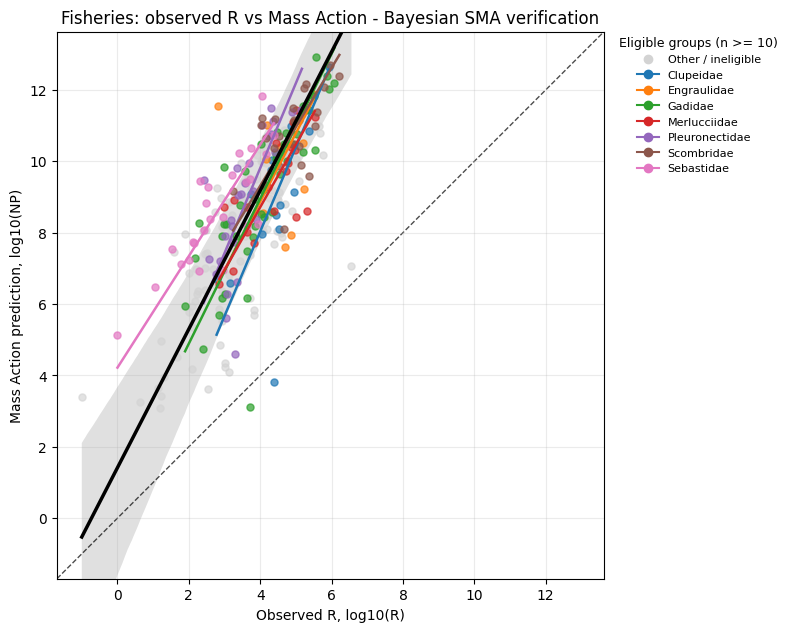

All required columns present in Bayesian SMA input: ['log10R', 'log10poisson_thinning', 'group']
All required columns present in group_eligibility: ['group', 'keep_pt']
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_global_log10R_vs_log10PT_strict_gear_2012_bayesian_sma.pdf


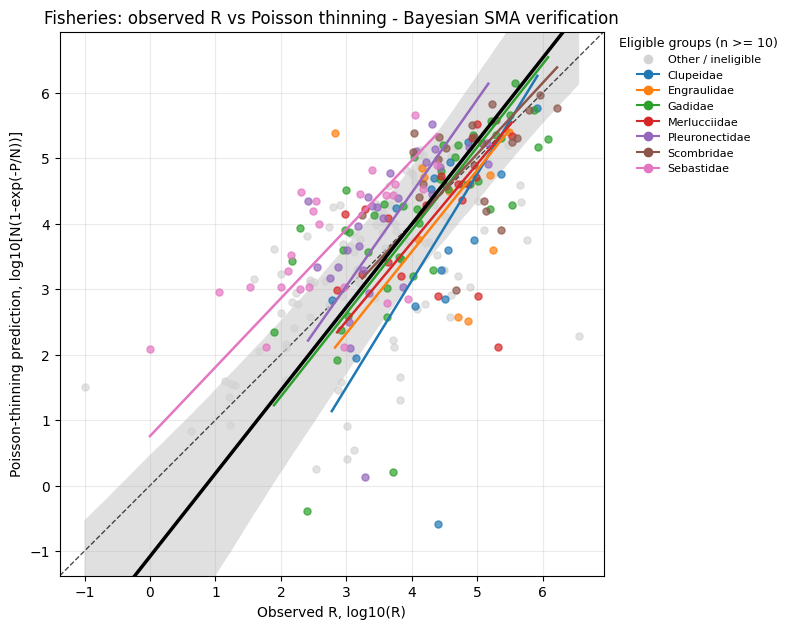

All required columns present in Bayesian SMA input: ['log10mass_action', 'log10reqq', 'group']
All required columns present in group_eligibility: ['group', 'keep_reqq']
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_global_log10MA_vs_log10reqq_strict_gear_2012_bayesian_sma.pdf


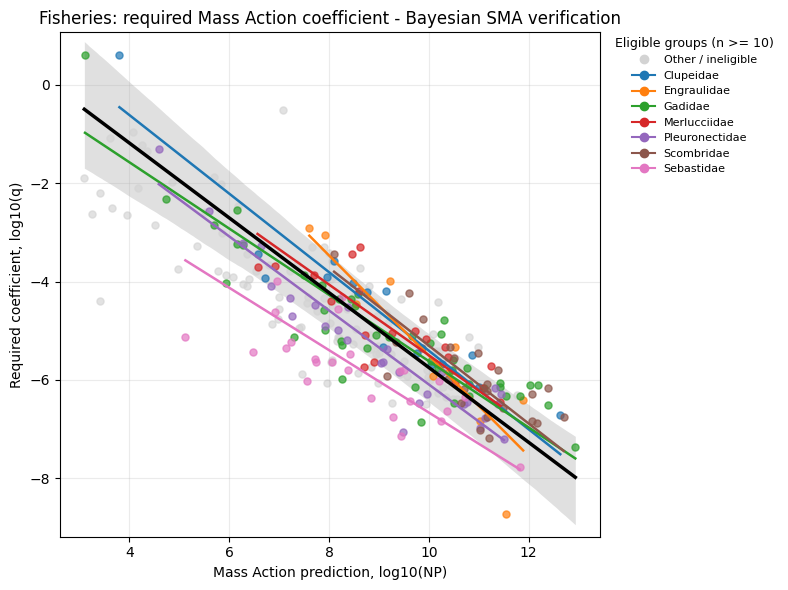

All required columns present in Bayesian SMA input: ['log10poisson_thinning', 'log10reqz', 'group']
All required columns present in group_eligibility: ['group', 'keep_reqz']
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_global_log10PT_vs_log10reqz_strict_gear_2012_bayesian_sma.pdf


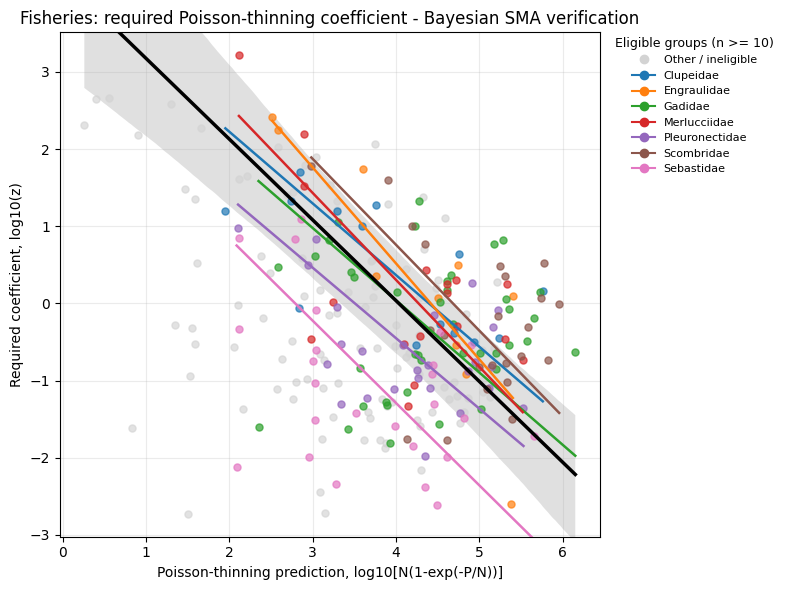

All required columns present in Bayesian SMA input: ['log10poisson_thinning', 'log10mass_action', 'group']
All required columns present in group_eligibility: ['group', 'keep_mapt']
Saved figure: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/results/figures/fisheries_gfw_log10PT_vs_log10MA_strict_gear_2012_bayesian_sma.pdf


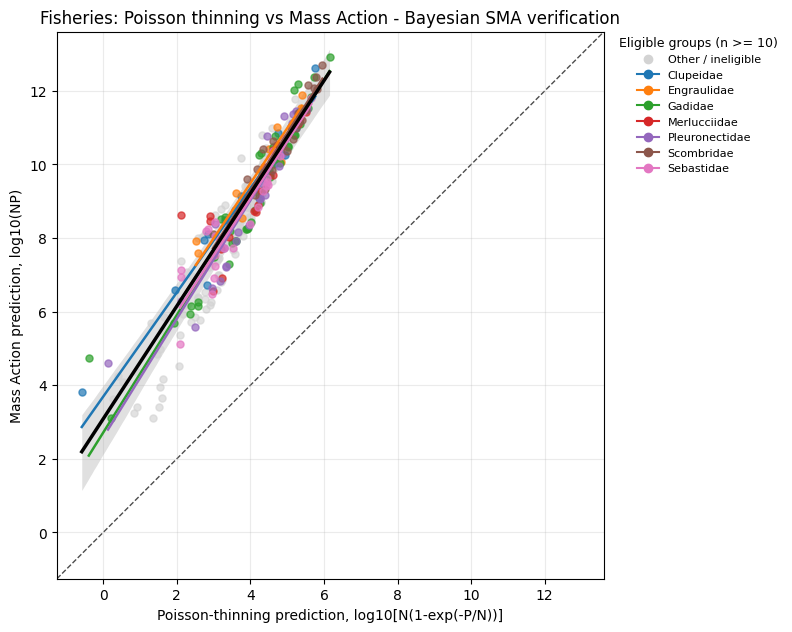

Saved table: /content/drive/MyDrive/Hopeful Monsters/Projects/Mass Action 2026/Datasets/Fisheries/qc/fisheries_gfw_plot_manifest_strict_gear_2012.csv


In [194]:
# Cell 194: Bayesian SMA supplementary figures
# Draws posterior line uncertainty and partially pooled group lines without changing primary figures.

def plot_bayesian_sma_analogue(df, model_name, specification, line_stats, idata):
    xcol, ycol = specification["x"], specification["y"]
    sub = prepare_bayesian_fit_data(df, xcol, ycol, group_col=GROUP_COL)
    eligible = set(current_eligible_groups(specification["keep_col"]))
    palette = get_group_palette_from_eligibility(group_eligibility, specification["keep_col"])
    eligible_data = sub.loc[sub[GROUP_COL].isin(eligible)]
    other_data = sub.loc[~sub[GROUP_COL].isin(eligible)]
    figsize = PLOT_STYLE["equal_figsize"] if specification["equal_axes"] else PLOT_STYLE["scatter_figsize"]
    fig, ax = plt.subplots(figsize=figsize)
    if len(other_data):
        ax.scatter(other_data[xcol], other_data[ycol], color="lightgrey",
                   alpha=PLOT_STYLE["other_alpha"], s=PLOT_STYLE["point_size"], zorder=1)
    for group_name, group_data in eligible_data.groupby(GROUP_COL):
        ax.scatter(group_data[xcol], group_data[ycol], color=palette[group_name],
                   alpha=PLOT_STYLE["point_alpha"], s=PLOT_STYLE["point_size"], zorder=2)
    x_values = sub[xcol].to_numpy(dtype=float)
    y_values = sub[ycol].to_numpy(dtype=float)
    x_grid = np.linspace(np.min(x_values), np.max(x_values), 200)
    population = line_stats.loc[
        line_stats["model"].eq(model_name) & line_stats["fit_level"].eq("hierarchical_population")
    ]
    if len(population) == 1 and population.iloc[0]["fit_status"] == "completed" and idata is not None:
        slope_draws = posterior_values(idata, "population_sma_slope")
        intercept_draws = posterior_values(idata, "population_sma_intercept")
        line_draws = intercept_draws[:, None] + slope_draws[:, None] * x_grid[None, :]
        ax.fill_between(x_grid, np.percentile(line_draws, 2.5, axis=0),
                        np.percentile(line_draws, 97.5, axis=0), color="black",
                        alpha=PLOT_STYLE["confidence_alpha"], linewidth=0, zorder=0,
                        label="95% credible band for hierarchical SMA line")
        ax.plot(x_grid, population.iloc[0]["intercept_median"] + population.iloc[0]["slope_median"] * x_grid,
                color="black", lw=PLOT_STYLE["global_linewidth"], zorder=4)
    group_rows = line_stats.loc[
        line_stats["model"].eq(model_name) & line_stats["fit_level"].eq("hierarchical_group")
    ]
    for _, row in group_rows.iterrows():
        group_data = eligible_data.loc[eligible_data[GROUP_COL].eq(row["group_label"])]
        if len(group_data) < 2 or not np.isfinite(row["slope_median"]):
            continue
        group_x = np.linspace(group_data[xcol].min(), group_data[xcol].max(), 100)
        ax.plot(group_x, row["intercept_median"] + row["slope_median"] * group_x,
                color=palette[row["group_label"]], lw=PLOT_STYLE["group_linewidth"], zorder=3)
    if specification["equal_axes"]:
        low, high = padded_limits([min(x_values.min(), y_values.min()), max(x_values.max(), y_values.max())])
        ax.set_xlim(low, high)
        ax.set_ylim(low, high)
        if specification["unity"]:
            ax.plot([low, high], [low, high], "k--", lw=PLOT_STYLE["unity_linewidth"], alpha=0.70, zorder=0)
        ax.set_aspect("equal", adjustable="box")
    else:
        ax.set_xlim(*padded_limits(x_values))
        ax.set_ylim(*padded_limits(y_values))
    ax.set_xlabel(specification["xlabel"])
    ax.set_ylabel(specification["ylabel"])
    ax.set_title(f"{specification['title']} - Bayesian SMA verification")
    ax.grid(True, alpha=PLOT_STYLE["grid_alpha"])
    add_group_legend(ax, palette, show_other=len(other_data) > 0)
    plt.tight_layout()
    output_path = bayesian_figure_path(specification)
    save_figure(fig, output_path)
    return {"figure": model_name, "figure_type": "supplementary_bayesian_sma", "path": str(output_path)}


if RUN_BAYESIAN:
    selected_bayesian_models = set(bayesian_model_names_to_run())
    for bayesian_model_name, bayesian_plot_specification in MODEL_PLOT_SPECS.items():
        if bayesian_model_name not in selected_bayesian_models:
            continue
        hierarchical_idata = bayesian_idata_by_model.get(bayesian_model_name, {}).get("hierarchical")
        bayesian_plot_manifest_rows.append(plot_bayesian_sma_analogue(
            analysis, bayesian_model_name, bayesian_plot_specification,
            bayesian_line_stats, hierarchical_idata,
        ))
    if bayesian_plot_manifest_rows:
        plot_manifest = pd.concat(
            [plot_manifest, pd.DataFrame(bayesian_plot_manifest_rows)], ignore_index=True
        )
        plot_manifest["exists"] = plot_manifest["path"].map(lambda path: Path(path).exists())
        save_csv(plot_manifest, PLOT_MANIFEST_PATH, index=False)



In [195]:
# Cell 195: Final output manifest
# Keeps primary SMA outputs separate from supplementary Bayesian SMA verification outputs.

print_header("FINAL OUTPUT MANIFEST")

output_manifest = pd.DataFrame([
    {"class": "dataset", "type": "table", "path": str(CANONICAL_HANDOFF_PATH)},
    {"class": "qc", "type": "table", "path": str(CANONICAL_QC_PATH)},
    {"class": "qc", "type": "table", "path": str(CONSTRUCTION_QC_PATH)},
    {"class": "qc", "type": "table", "path": str(REJECTED_NPR_PATH)},
    {"class": "qc", "type": "table", "path": str(GROUP_ELIGIBILITY_PATH)},
    {"class": "qc", "type": "table", "path": str(ANALYSIS_QC_PATH)},
    {"class": "result", "type": "table", "path": str(GLOBAL_FITS_PATH)},
    {"class": "result", "type": "table", "path": str(GROUP_FITS_PATH)},
    {"class": "result", "type": "table", "path": str(FIT_SUMMARY_PATH)},
    {"class": "result", "type": "table", "path": str(DISPLAYED_STATS_PATH)},
    {"class": "result", "type": "figure", "path": str(PLOT_MA_PATH)},
    {"class": "result", "type": "figure", "path": str(PLOT_PT_PATH)},
    {"class": "result", "type": "figure", "path": str(PLOT_REQQ_PATH)},
    {"class": "result", "type": "figure", "path": str(PLOT_REQZ_PATH)},
    {"class": "result", "type": "figure", "path": str(PLOT_MAPT_PATH)},
    {"class": "result", "type": "figure", "path": str(FOREST_MA_PT_MERGED_PATH)},
    {"class": "result", "type": "figure", "path": str(FOREST_REQQ_REQZ_MERGED_PATH)},
    {"class": "result", "type": "figure", "path": str(FOREST_CROSSOVER_PATH)},
])

if RUN_BAYESIAN:
    bayesian_output_rows = [
        {"class": "supplementary_bayesian_sma", "type": "table", "path": str(BAYESIAN_LINE_STATS_PATH)},
        {"class": "supplementary_bayesian_sma_qc", "type": "table", "path": str(BAYESIAN_MODEL_DIAGNOSTICS_PATH)},
    ]
    bayesian_output_rows.extend([
        {"class": "supplementary_bayesian_sma", "type": "figure", "path": row["path"]}
        for row in bayesian_plot_manifest_rows
    ])
    output_manifest = pd.concat(
        [output_manifest, pd.DataFrame(bayesian_output_rows)],
        ignore_index=True,
    )

output_manifest["exists"] = output_manifest["path"].map(lambda path: Path(path).exists())
display_df(output_manifest)
save_csv(output_manifest, OUTPUT_MANIFEST_PATH, index=False)



FINAL OUTPUT MANIFEST
                            class    type                                               path  exists
0                         dataset   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
1                              qc   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
2                              qc   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
3                              qc   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
4                              qc   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
5                              qc   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
6                          result   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
7                          result   table  /content/drive/MyDrive/Hopeful Monsters/Projec...    True
8                          result   table  /content/drive/MyDrive/Ho

In [196]:
# Cell 196: Optional notebook export helper
# Provides a notebook export helper for Colab sessions.
# Produces exported Python/Markdown/Text copies when the source notebook is available.

print_header("OPTIONAL NOTEBOOK EXPORT")
print("This refactored .py file is the executable source artifact. Notebook export is intentionally not run automatically.")



OPTIONAL NOTEBOOK EXPORT
This refactored .py file is the executable source artifact. Notebook export is intentionally not run automatically.
